In [1]:
import os
import json
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D
import seaborn as sns

from scipy.stats import kde, kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import fdrcorrection
from scikit_posthocs import posthoc_dunn
from statannotations.Annotator import Annotator

import random
import warnings
import operator

import pickle

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order, format_box_plot

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


Data prep

In [2]:
#HANN mapping
class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

In [3]:
#load data# Save root 
output_dir = Path('/root/capsule/scratch') / '20260807' / 'ephys'
os.makedirs(output_dir, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

metadata_path =              DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'
data_path =                  DATA_ROOT / 'human' / 'electrophysiology' / 'features' / '20260807' / 'ephys_features.csv'

ephys_feature_rename_file =  DATA_ROOT / 'formatting_dicts' / 'ephys_feature_rename.csv'
l23_ttype_rename_file =      DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
ttype_layer_file =           DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'

lobe_color_file =            DATA_ROOT / 'colors'           / 'lobe_colors.json'
paradigm_color_file =        DATA_ROOT / 'colors'           / 'paradigm_colors.json'
layer_color_file =           DATA_ROOT / 'colors'           / 'layer_colors.json'



In [4]:
# Load data
ephys_feature_rename_df = pd.read_csv(ephys_feature_rename_file)
ephys_feature_rename_dict = dict(zip(ephys_feature_rename_df.old_feature_name, ephys_feature_rename_df.new_feature_name))

with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)

features = pd.read_csv(data_path, index_col='specimen_id')
features = features.rename(columns=ephys_feature_rename_dict)
feature_cols = [x for x in features.columns if not x in ['subclass_label_Hierarchical', 'cluster_label_Hierarchical', 'Normalized depth from pia']]

metadata = pd.read_csv(metadata_path)
metadata = metadata[metadata.cell_id.isin(features.index)]
metadata = metadata.rename(columns={'cell_id' : 'specimen_id', cluster_col: "t_type", subclass_col:'subclass_label'}).set_index('specimen_id')
metadata["layer"] = metadata["t_type"].map(ttype_to_layer_dict)

#split Layer 2 and 3 subclass
metadata["layer_subclass"] = metadata.apply(
    lambda row: "L2 IT" if row["layer"] == 'Layer 2'
                else ("L3 IT" if row["layer"] == 'Layer 3'
                    else row["subclass_label"]),
    axis=1
)
metadata_cols = ['t_type', 'subclass_label', 'layer_subclass', 'layer', 'lobe', 'paradigm']
metadata = metadata[metadata_cols]
metadata['lobe_group'] = metadata['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')
metadata['subclass_label'] = metadata['subclass_label'].fillna('TBD')  #remove vals without a seaad mapping
metadata['t_type'] = metadata['t_type'].fillna('TBD')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET_ME', 'L5 ET')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET(ME)', 'L5 ET')
metadata['t_type'] = metadata['t_type'].replace('L5 ET_ME', 'L5 ET(ME)')
metadata['t_type'] = metadata['t_type'].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata['layer'] = metadata["t_type"].map(ttype_to_layer_dict)

sorted_clean_data = metadata.merge(features[feature_cols], how='inner', left_index=True, right_index=True)

In [5]:
#Get color dicts
color_dict = get_seaad_colors()
with open(layer_color_file, "r") as f: layer_color_dict = json.load(f)
with open(lobe_color_file, "r") as f: lobe_color_dict = json.load(f)
with open(paradigm_color_file, "r") as f: paradigm_color_dict = json.load(f)

color_dicts = {
    't_type' : color_dict, 
    'subclass_label' : color_dict, 
    'lobe' : lobe_color_dict, 
    'lobe_group' : lobe_color_dict,
    'paradigm' : paradigm_color_dict,
    'layer' : layer_color_dict  
}


#Get custom transcriptomic order
ttype_order, subclass_order = get_tx_order()
group_order = {
    'subclass_label' : subclass_order,
    't_type' :  ttype_order,
    'lobe' : ['TemL', 'FroL'],
    'lobe_group' : ['TemL', 'Other'],
    'paradigm' : ['acute', 'culture'],
    'layer' : sorted(list(set(ttype_to_layer_dict.values())))
}

Subclass x feature box plots with stats

In [6]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = group_order[x_var]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


/tmp/ipykernel_780630/4026269806.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:2.685e-26
L4 IT vs. L5 IT: Custom statistical test, P_val:3.406e-22
L4 IT vs. L5/6 NP: Custom statistical test, P_val:3.508e-11
L4 IT vs. L6 IT Car3: Custom statistical test, P_val:1.508e-10
L4 IT vs. L6 IT: Custom statistical test, P_val:3.481e-04
L2/3 IT vs. L6 IT Car3: Custom statistical test, P_val:4.136e-02
L4 IT vs. L6 CT: Custom statistical test, P_val:1.144e-08
L4 IT vs. L6b: Custom statistical test, P_val:1.606e-04


/tmp/ipykernel_780630/4026269806.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:1.083e-06
L5 IT vs. L5/6 NP: Custom statistical test, P_val:2.478e-02
L2/3 IT vs. L5 IT: Custom statistical test, P_val:3.264e-06
L4 IT vs. L5/6 NP: Custom statistical test, P_val:2.478e-02


/tmp/ipykernel_780630/4026269806.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L5 IT: Custom statistical test, P_val:2.602e-02


... (37 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:1.801e-02
L4 IT vs. L5 IT: Custom statistical test, P_val:1.484e-08
L5 IT vs. L5/6 NP: Custom statistical test, P_val:2.279e-06
L5 ET vs. L6 IT Car3: Custom statistical test, P_val:4.436e-04
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:1.585e-02
L2/3 IT vs. L5 IT: Custom statistical test, P_val:1.080e-17
L5 IT vs. L5 ET: Custom statistical test, P_val:1.364e-02
L4 IT vs. L5/6 NP: Custom statistical test, P_val:1.250e-17
L5/6 NP vs. L6 IT Car3: Custom statistical test, P_val:4.021e-07
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:4.517e-02
L4 IT vs. L5 ET: Custom statistical test, P_val:3.751e-06
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:5.197e-24
L5/6 NP vs. L6 IT: Custom statistical test, P_val:2.602e-02
L5 IT vs. L6 IT Ca

/tmp/ipykernel_780630/4026269806.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:6.460e-08
L2/3 IT vs. L5 IT: Custom statistical test, P_val:1.884e-02
L4 IT vs. L5 ET: Custom statistical test, P_val:1.823e-02


/tmp/ipykernel_780630/4026269806.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


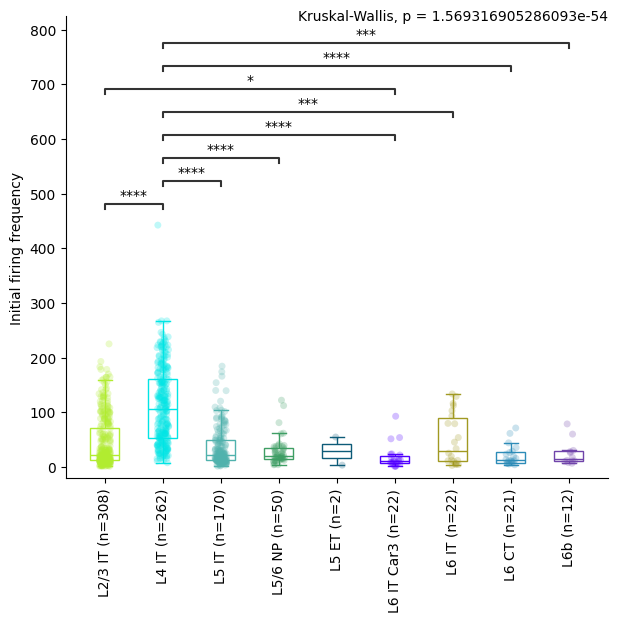

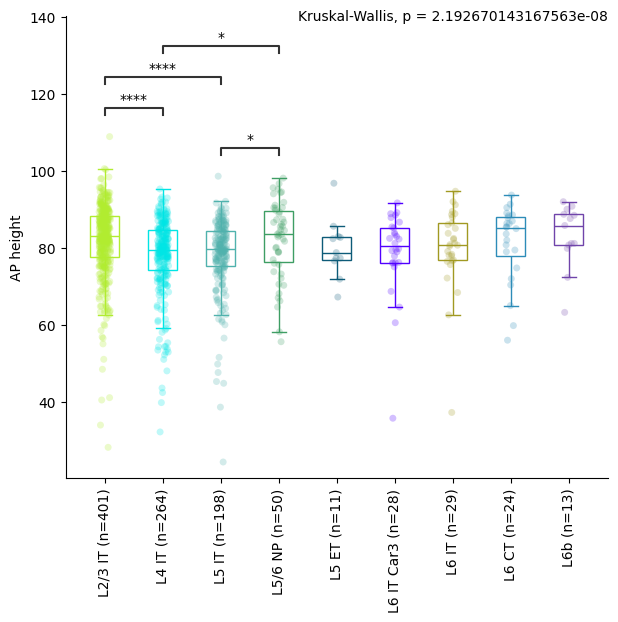

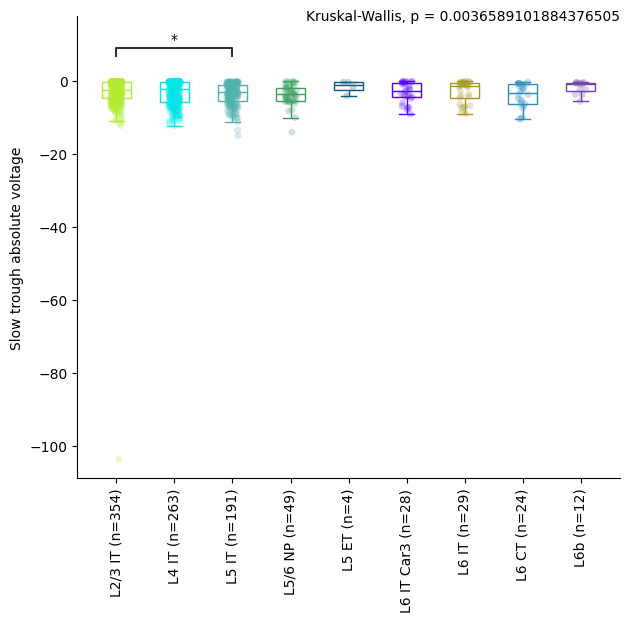

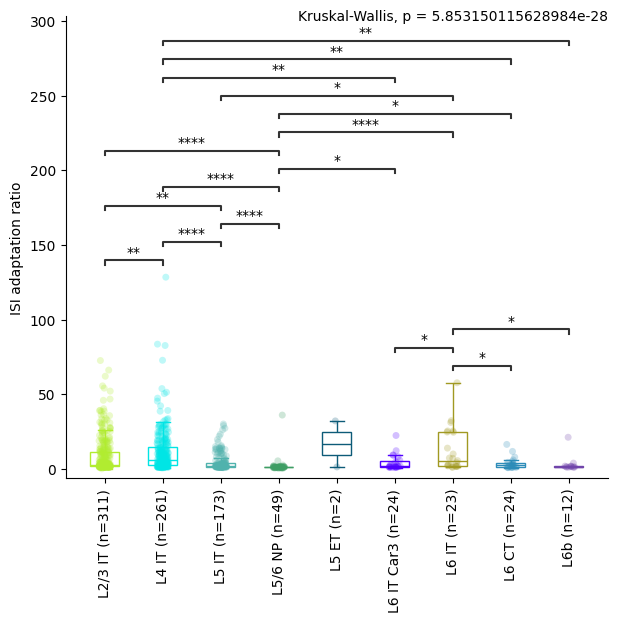

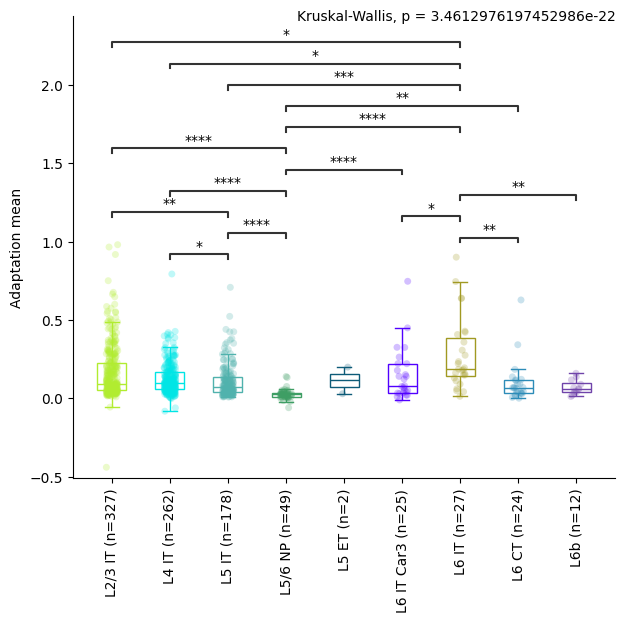

...

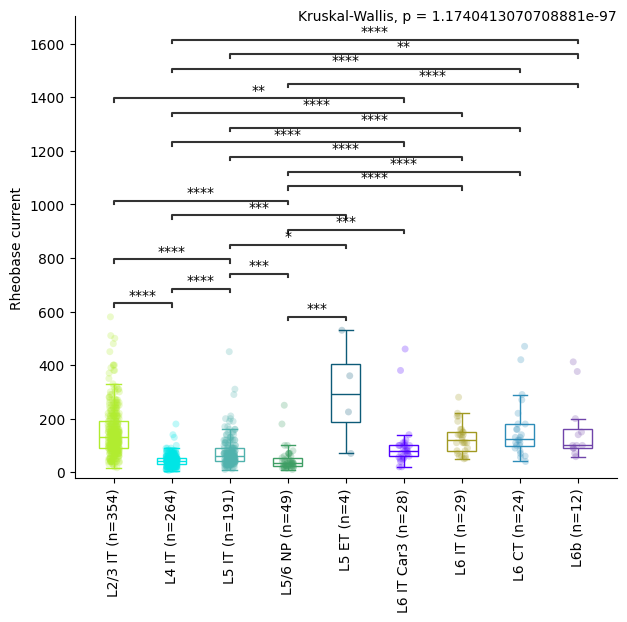

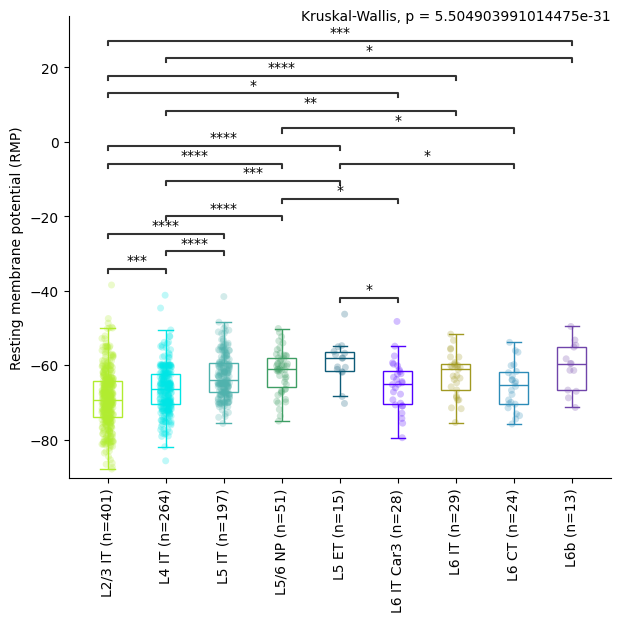

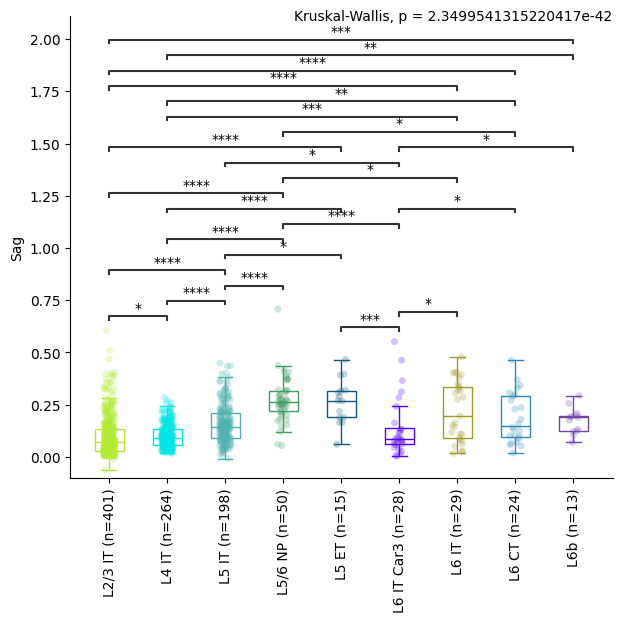

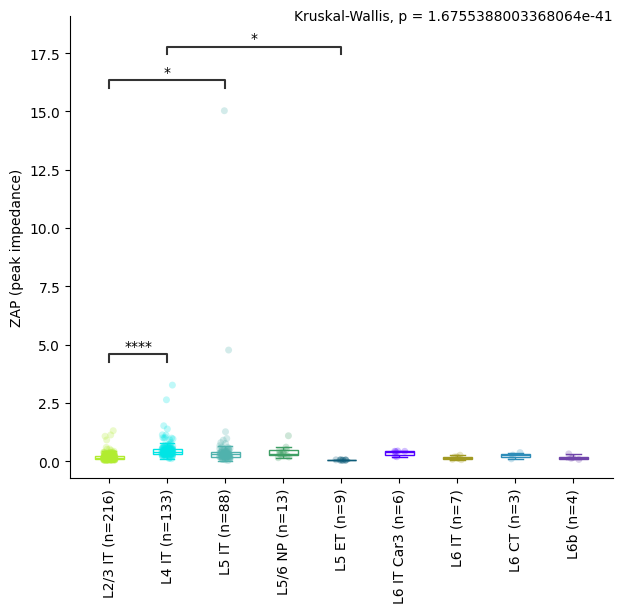

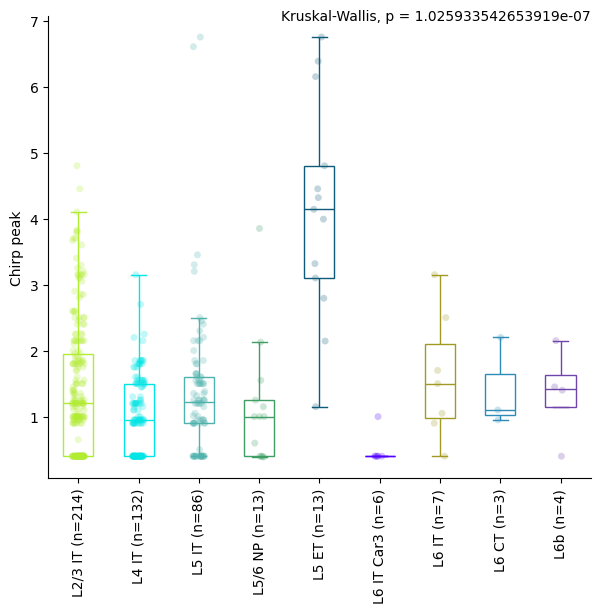

<Figure size 640x480 with 0 Axes>

In [7]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_bySubclass.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dicts[hue_var] #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

ephys_features = feature_cols.copy()

fig_path = os.path.join(output_dir, fig_name)

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[(sorted_clean_data[x_var] == t) & (~sorted_clean_data[y_var].isna())])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



In [8]:
# save stats

combined_rows = []

for feature in kw_pvals:
    kw_info = {
        "feature": feature,
        "KW_H_statistic": kw_hvals[feature],
        "KW_p_value": kw_pvals[feature],
        "KW_p_value_fdr": kw_pvals_fdr[feature],
        "KW_significant_fdr": kw_rejected[feature],
    }

    if feature in dunn_pvals_fdr:
        dunn_matrix = dunn_pvals_fdr[feature]

        for i, group_1 in enumerate(dunn_matrix.index):
            for j, group_2 in enumerate(dunn_matrix.columns):
                # Exclude self-comparisons and duplicate comparisons
                if j > i:
                    dunn_p = dunn_matrix.loc[group_1, group_2]

                    combined_rows.append({
                        **kw_info,
                        "group_1": group_1,
                        "group_2": group_2,
                        "Dunn_p_value_fdr": dunn_p,
                        "Dunn_significant_fdr": dunn_p < 0.05,
                    })
    else:
        # Retain features that did not receive a Dunn test
        combined_rows.append({
            **kw_info,
            "group_1": None,
            "group_2": None,
            "Dunn_p_value_fdr": None,
            "Dunn_significant_fdr": None,
        })

combined_results = pd.DataFrame(combined_rows)

combined_results = combined_results.sort_values(
    ["KW_p_value_fdr", "feature", "Dunn_p_value_fdr"],
    na_position="last"
)

combined_results.to_csv(
    fig_path.replace('.pdf', '.csv'),
    index=False
)

Subclasses within Layer 5

In [6]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = [s for s in group_order[x_var] if s.startswith('L5')]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:1.589e-02


/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:5.153e-09


/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:6.962e-10


... (27 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5 ET: Custom statistical test, P_val:4.132e-02


/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:7.909e-11
L5 IT vs. L5 ET: Custom statistical test, P_val:2.878e-04


/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/2027981609.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


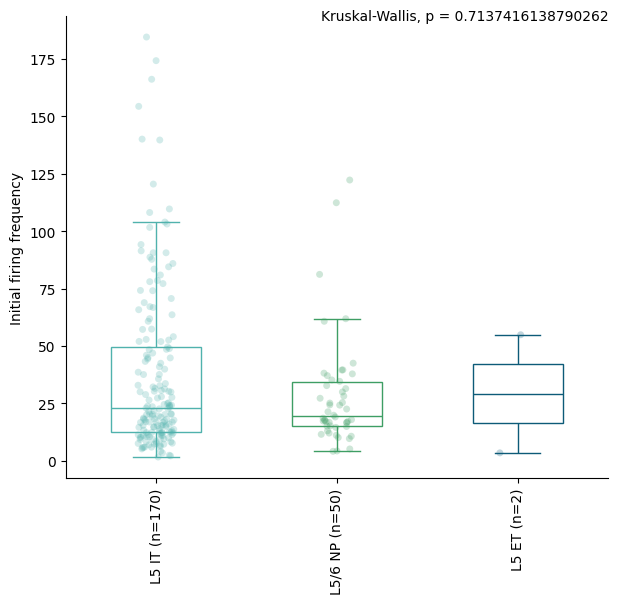

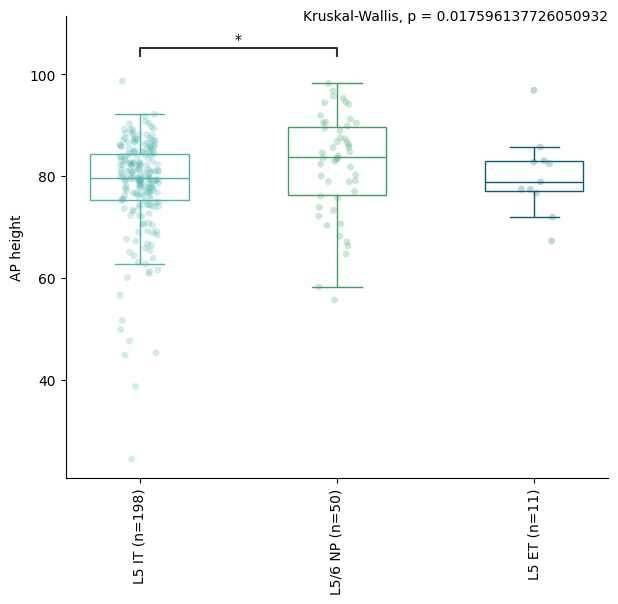

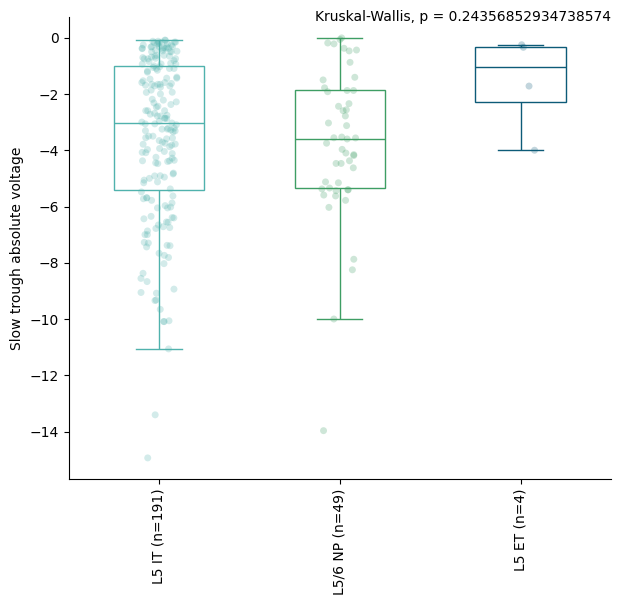

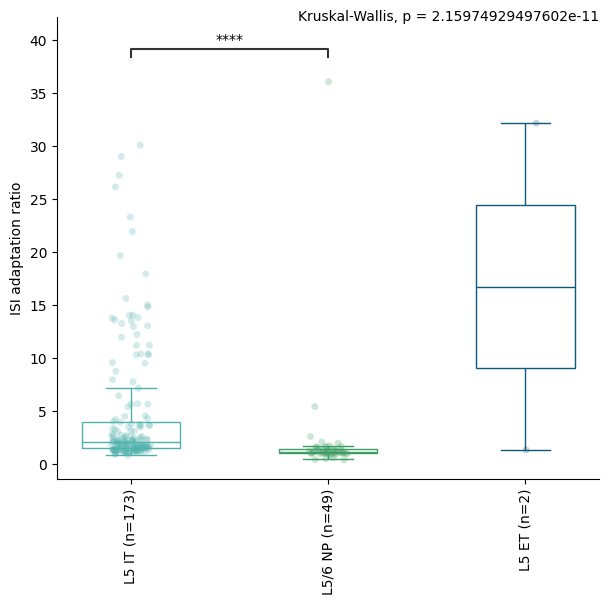

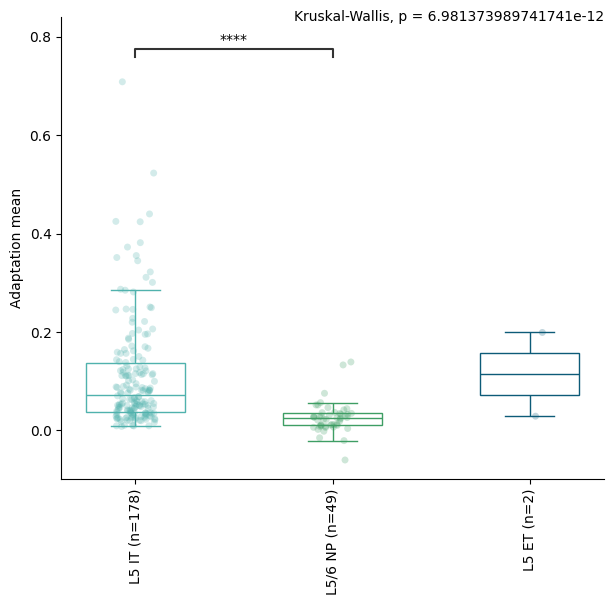

...

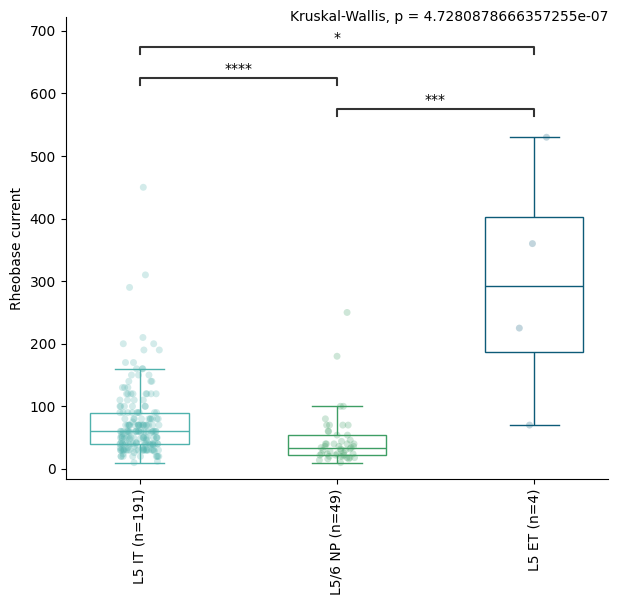

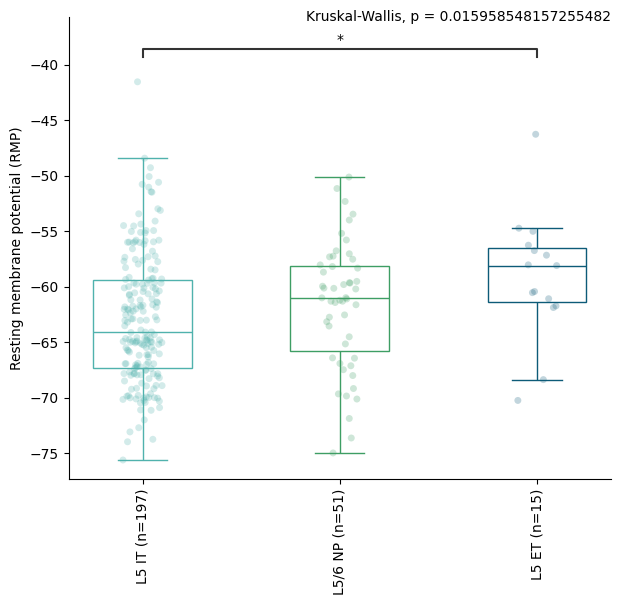

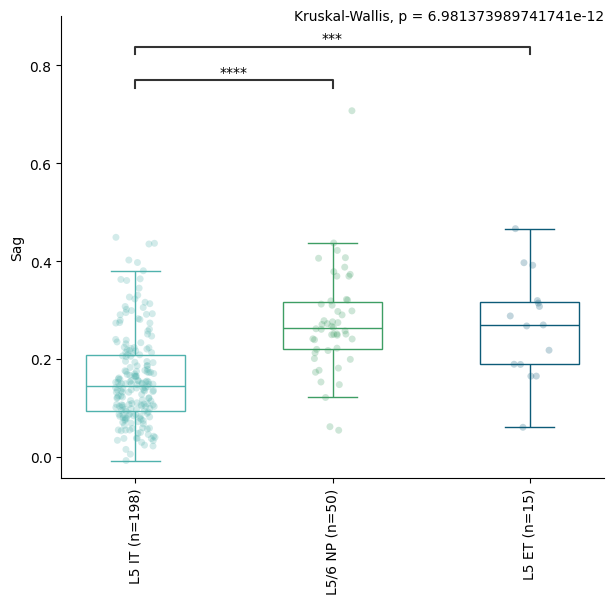

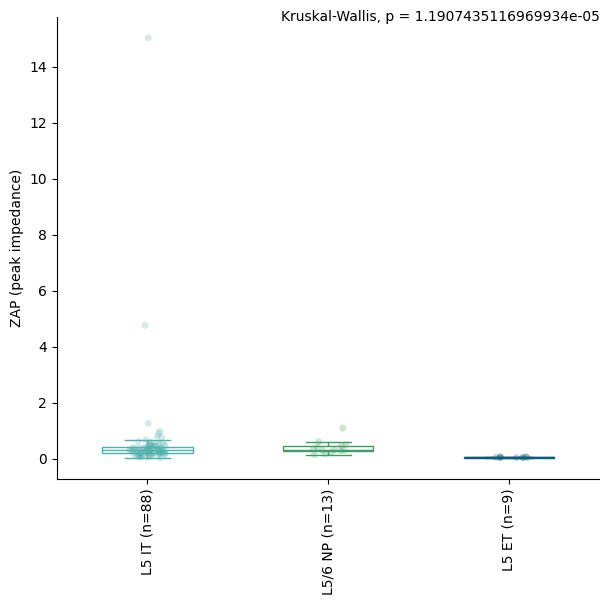

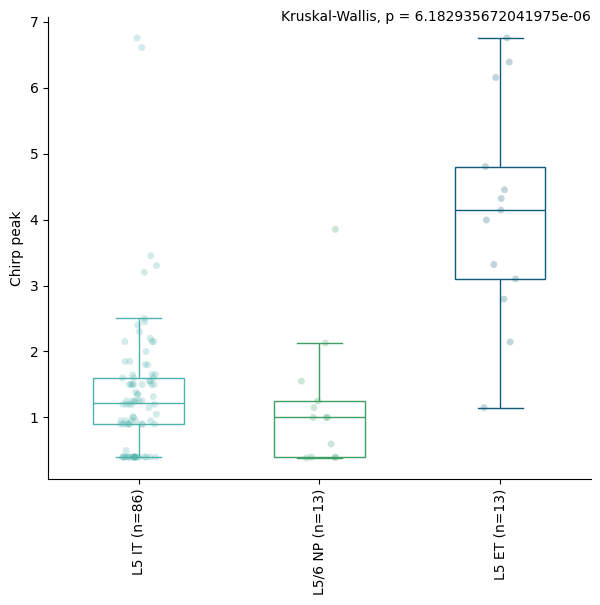

<Figure size 640x480 with 0 Axes>

In [7]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_bySubclass_Layer5.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dicts[hue_var] #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

ephys_features = feature_cols.copy()

fig_path = os.path.join(output_dir, fig_name)

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[(sorted_clean_data[x_var] == t) & (~sorted_clean_data[y_var].isna())])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Subclasses within Layer 6

In [6]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = [s for s in group_order[x_var] if s.startswith('L6')]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


In [7]:
# save stats

rows = []

for feature in kw_pvals:
    kw_info = {
        "feature": feature,
        "KW_H_statistic": kw_hvals[feature],
        "KW_p_value": kw_pvals[feature],
        "KW_p_value_fdr": kw_pvals_fdr[feature],
        "KW_significant_fdr": kw_rejected[feature],
    }

    if feature in dunn_pvals_fdr:
        dunn_matrix = dunn_pvals_fdr[feature]

        for i, group_1 in enumerate(dunn_matrix.index):
            for j, group_2 in enumerate(dunn_matrix.columns):
                # Keep each pair once and exclude self-comparisons
                if j > i:
                    dunn_p_fdr = dunn_matrix.loc[group_1, group_2]

                    rows.append({
                        **kw_info,
                        "subclass_1": group_1,
                        "subclass_2": group_2,
                        "Dunn_p_value_fdr": dunn_p_fdr,
                        "Dunn_significant_fdr": dunn_p_fdr < 0.05,
                    })
    else:
        # Retain features that did not receive a Dunn test
        rows.append({
            **kw_info,
            "subclass_1": None,
            "subclass_2": None,
            "Dunn_p_value_fdr": None,
            "Dunn_significant_fdr": None,
        })

l6_stats = pd.DataFrame(rows).sort_values(
    ["KW_p_value_fdr", "feature", "Dunn_p_value_fdr"],
    na_position="last",
)

csv_name = os.path.join(output_dir, 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_bySubclass_Layer6.csv')
l6_stats.to_csv(
    csv_name,
    index=False,
)

/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:4.816e-02
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:4.816e-02
L6 IT vs. L6b: Custom statistical test, P_val:4.816e-02


/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:1.761e-03
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:2.813e-02
L6 IT vs. L6b: Custom statistical test, P_val:4.343e-03


/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:1.490e-02
L6 IT vs. L6b: Custom statistical test, P_val:8.454e-03
L6 IT Car3 vs. L6b: Custom statistical test, P_val:2.500e-02


... (9 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:1.827e-03


/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:24: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:1.736e-02
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:1.040e-02


/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7854/1736828195.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


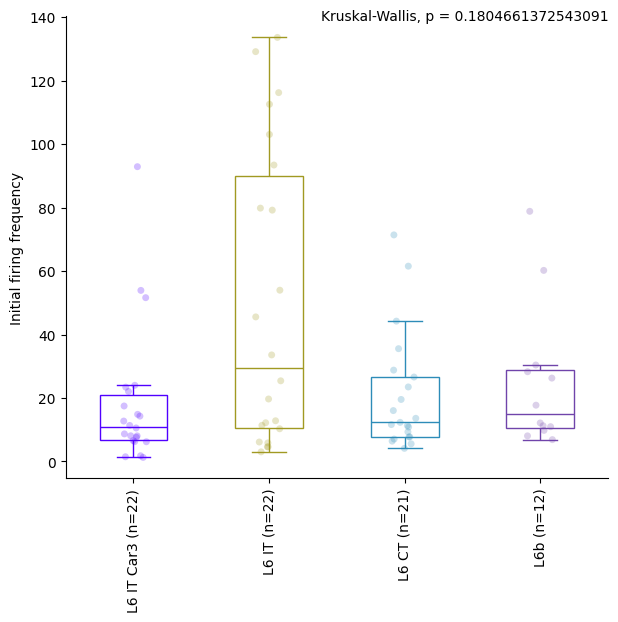

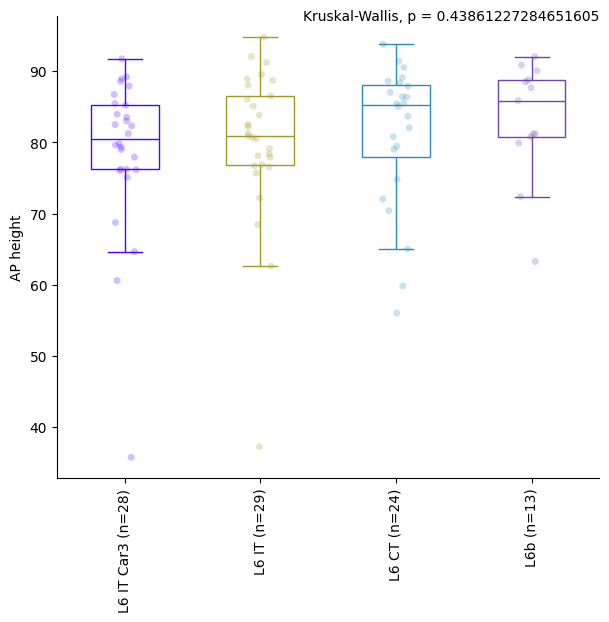

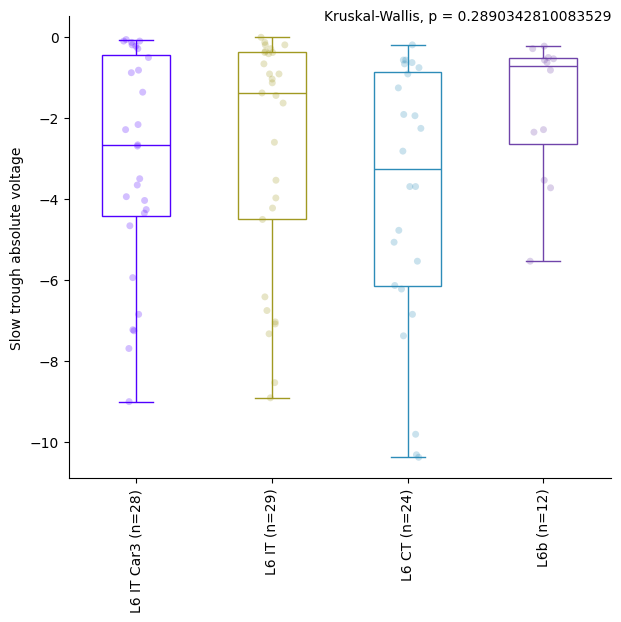

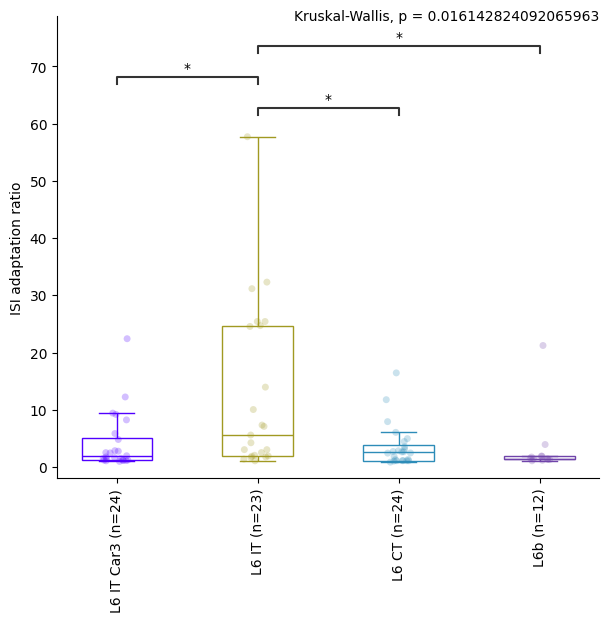

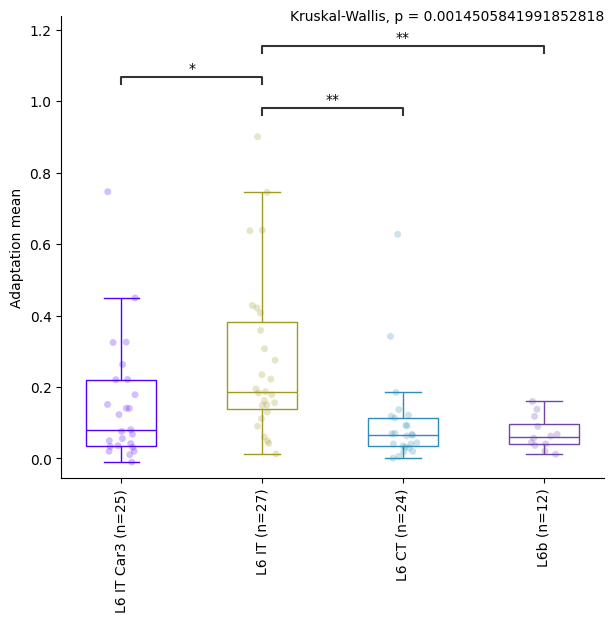

...

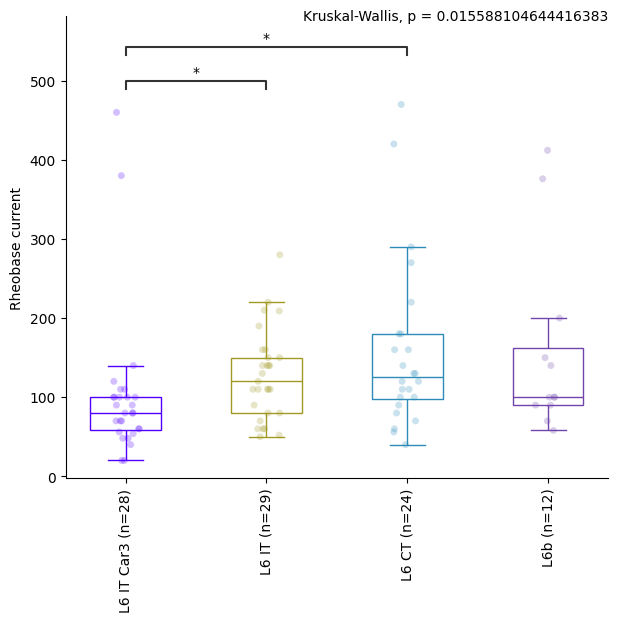

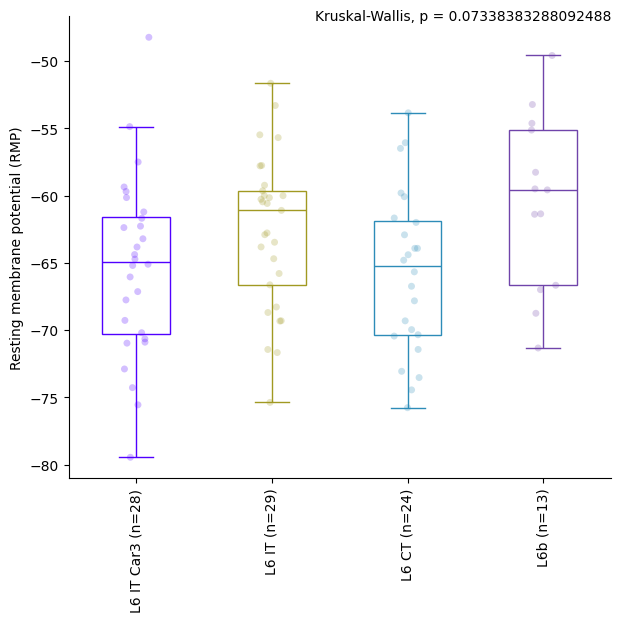

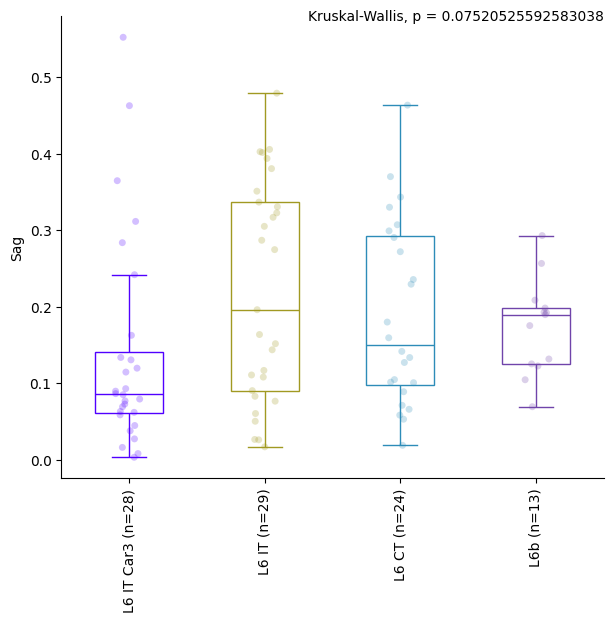

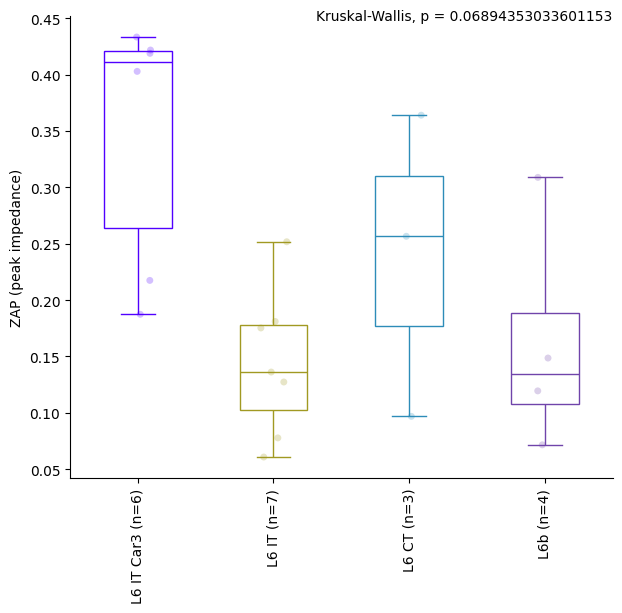

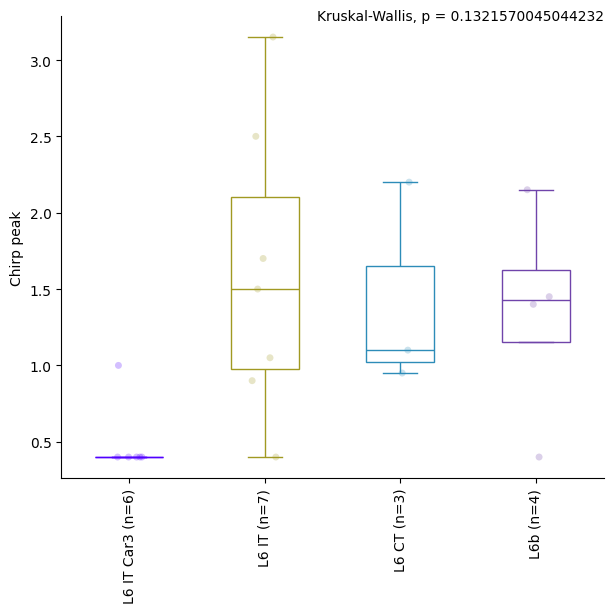

<Figure size 640x480 with 0 Axes>

In [9]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_bySubclass_Layer6.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dicts[hue_var] #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

ephys_features = feature_cols.copy()

fig_path = os.path.join(output_dir, fig_name)

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[(sorted_clean_data[x_var] == t) & (~sorted_clean_data[y_var].isna())])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



T-type x feature box plots with stats

In [8]:
# ttype x feature stats

x_var = 't_type'  # what to do box plots on
x_var_order = [x for x in group_order[x_var] if x in sorted_clean_data[x_var].tolist()]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]


/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divid

/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:3.613e-02
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:2.609e-06
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:2.832e-02
L3 IT_5 vs. L4 IT_2: Custom statistical test, P_val:5.829e-07
L4 IT_4 vs. L5 IT_2: Custom statistical test, P_val:7.907e-03
L3 IT_10 vs. L4 IT_2: Custom statistical test, P_val:7.907e-03
L5 IT_2 vs. L5/6 NP_1: Custom statistical test, P_val:1.537e-02
L3 IT_12 vs. L4 IT_2: Custom statistical test, P_val:1.070e-06
L3 IT_5 vs. L5 IT_2: Custom statistical test, P_val:8.689e-04
L3 IT_5 vs. L5 IT_1: Custom statistical test, P_val:3.604e-02
L3 IT_12 vs. L5 IT_5: Custom statistical test, P_val:3.683e-02
L4 IT_2 vs. L5/6 NP_1: Custom statistical test, P_val:2.829e-04
L2 IT_1 vs. L4 IT_2: Custom statistical test, P_val:6.6

L2 IT_1 vs. L5 IT_2: Custom statistical test, P_val:2.283e-03
L2 IT_6 vs. L5 IT_2: Custom statistical test, P_val:2.623e-02


/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:2.830e-03
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:1.567e-02
L4 IT_2 vs. L5 IT_5: Custom statistical test, P_val:5.785e-03
L4 IT_2 vs. L5 IT_2: Custom statistical test, P_val:5.792e-04
L4 IT_4 vs. L5 IT_5: Custom statistical test, P_val:3.559e-02
L4 IT_4 vs. L5 IT_2: Custom statistical test, P_val:8.891e-03
L2 IT_1 vs. L4 IT_4: Custom statistical test, P_val:5.785e-03
L2 IT_1 vs. L4 IT_2: Custom statistical test, P_val:1.397e-04


/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


... (18 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:6.192e-04
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:2.567e-07
L5 ET_2 vs. L6 IT Car3_1: Custom statistical test, P_val:4.065e-03
L6 CT_1 vs. L6b_6: Custom statistical test, P_val:1.553e-02
L2 IT_1 vs. L2 IT_2: Custom statistical test, P_val:3.525e-02
L4 IT_2 vs. L5 IT_6: Custom statistical test, P_val:5.723e-05
L5 ET_1 vs. L6 IT Car3_1: Custom statistical test, P_val:4.462e-02
L4 IT_2 vs. L5 IT_5: Custom statistical test, P_val:7.026e-05
L5 IT_1 vs. L5/6 NP_2: Custom statistical test, P_val:3.118e-02
L6 IT Car3_1 vs. L6 IT_2: Custom statistical test, P_val:1.798e-02
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:7.895e-04
L3 IT_5 vs. L4 IT_2: Custom statistical test, P_val:2.908e-03
L4 IT_2 vs. L5 IT_2: Custom statistical test, P_

/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_10 vs. L3 IT_13: Custom statistical test, P_val:4.531e-02
L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.021e-04
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.976e-02
L5 ET_2 vs. L6 IT Car3_1: Custom statistical test, P_val:4.514e-03
L6 IT Car3_3 vs. L6 IT Car3_2: Custom statistical test, P_val:2.358e-02
L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:7.578e-04
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:2.262e-03
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:4.812e-02
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:1.081e-06
L4 IT_2 vs. L5 IT_6: Custom statistical test, P_val:2.668e-05
L5 ET_1 vs. L6 IT Car3_1: Custom statistical test, P_val:6.611e-03
L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:4.103e-02
L2 IT_2 vs. L3 IT_10: Custom 

/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2250416033.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


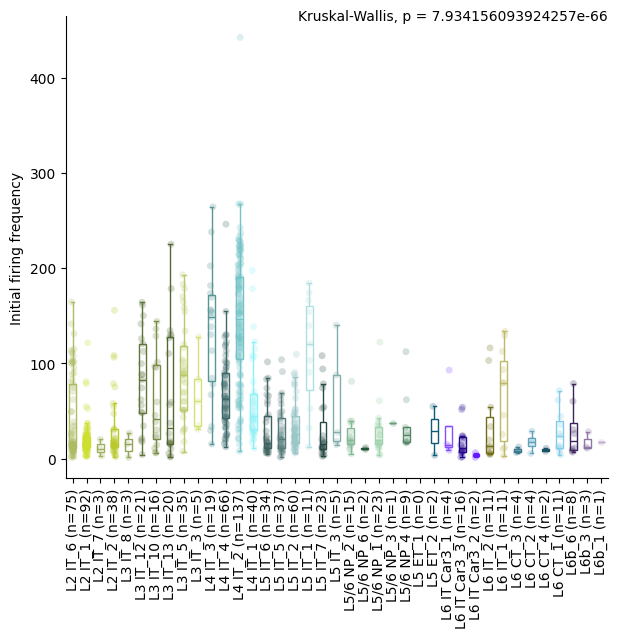

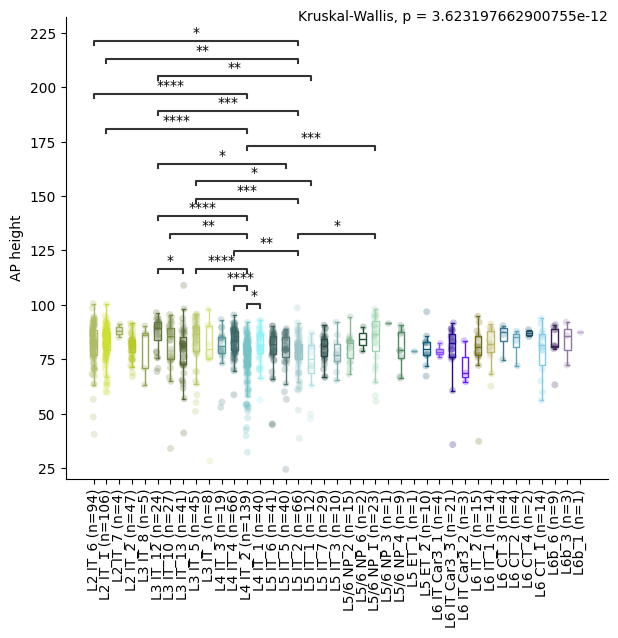

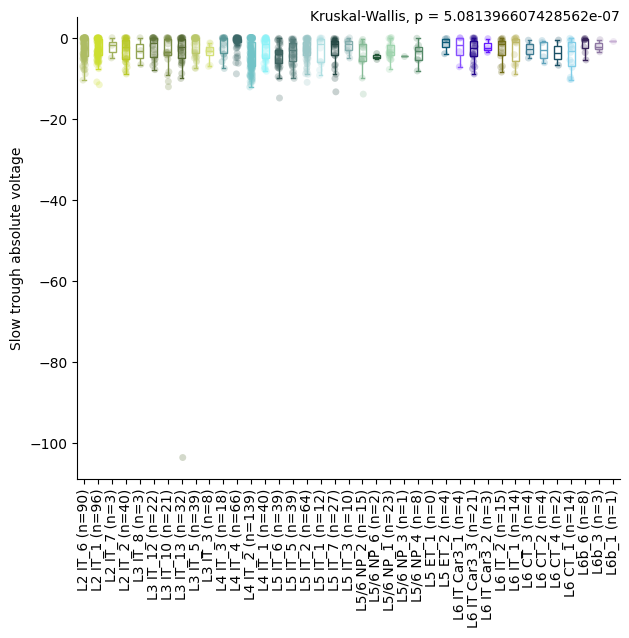

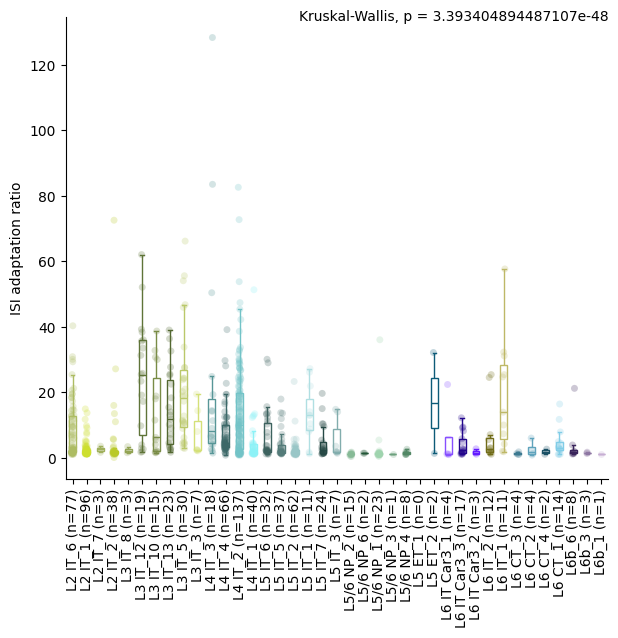

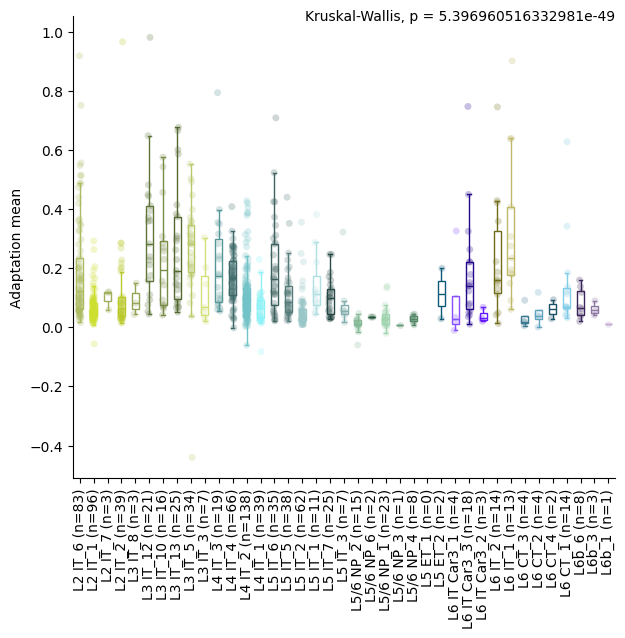

...

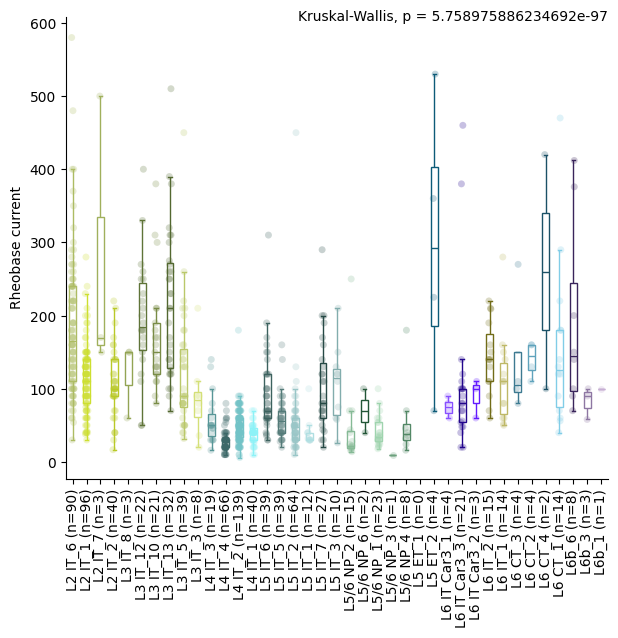

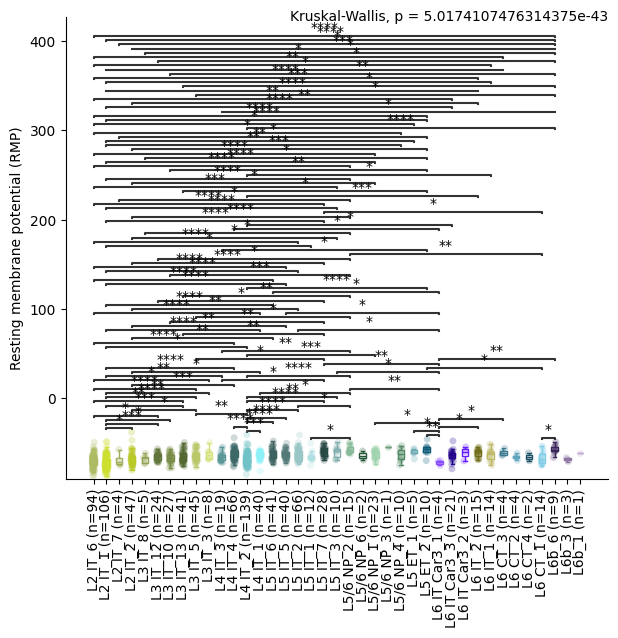

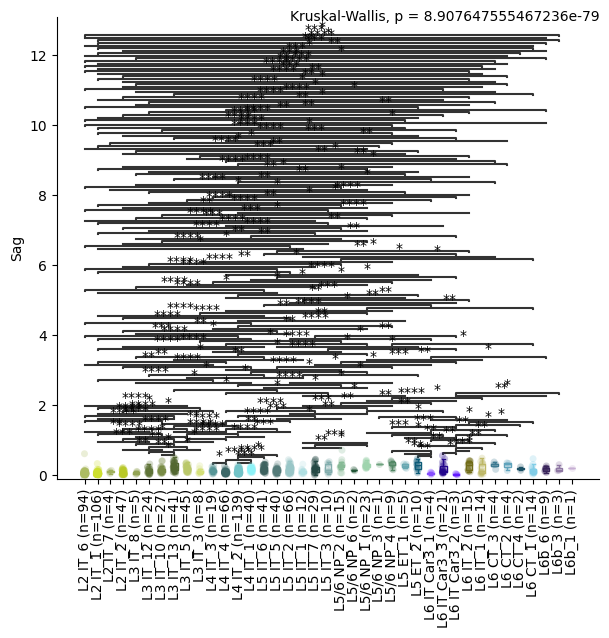

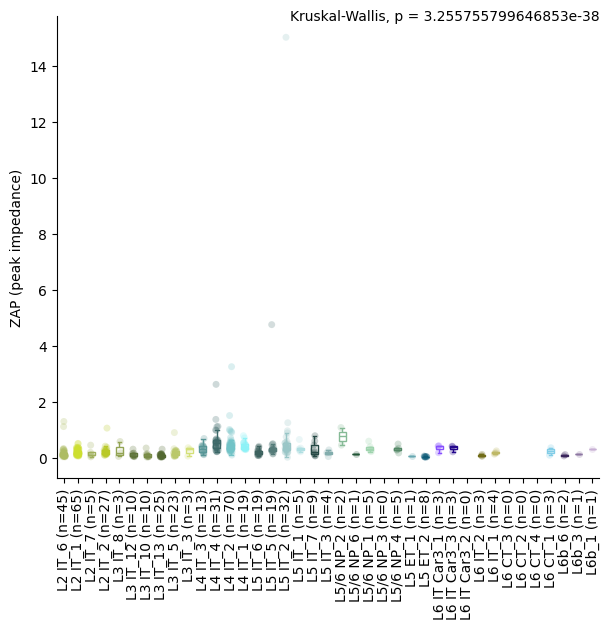

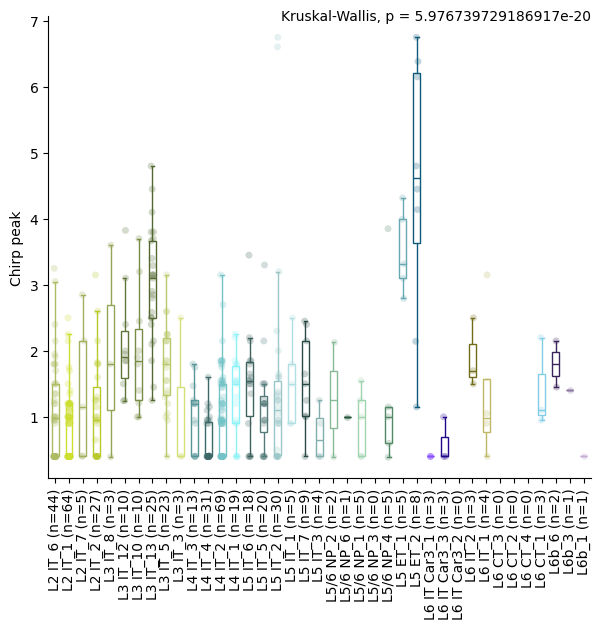

<Figure size 640x480 with 0 Axes>

In [9]:
# ttype x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_byTtype.pdf'
color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dicts[hue_var] #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[(sorted_clean_data[x_var] == t) & (~sorted_clean_data[y_var].isna())])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Layer x feature box plots with stats

In [11]:
# subclass x feature stats
x_var = 'layer' #what to do box plots on 
x_var_order = group_order[x_var]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


In [12]:
rows = []

for feature in kw_pvals:
    kw_info = {
        "feature": feature,
        "KW_H_statistic": kw_hvals[feature],
        "KW_p_value": kw_pvals[feature],
        "KW_p_value_fdr": kw_pvals_fdr[feature],
        "KW_significant_fdr": kw_rejected[feature],
    }

    if feature in dunn_pvals_fdr:
        dunn_matrix = dunn_pvals_fdr[feature]

        for i, layer_1 in enumerate(dunn_matrix.index):
            for j, layer_2 in enumerate(dunn_matrix.columns):
                # Keep each comparison once and omit self-comparisons
                if j > i:
                    dunn_p_fdr = dunn_matrix.loc[layer_1, layer_2]

                    rows.append({
                        **kw_info,
                        "layer_1": layer_1,
                        "layer_2": layer_2,
                        "Dunn_p_value_fdr": dunn_p_fdr,
                        "Dunn_significant_fdr": dunn_p_fdr < 0.05,
                    })
    else:
        # Retain features without a significant KW result
        rows.append({
            **kw_info,
            "layer_1": None,
            "layer_2": None,
            "Dunn_p_value_fdr": None,
            "Dunn_significant_fdr": None,
        })

layer_stats = pd.DataFrame(rows).sort_values(
    ["KW_p_value_fdr", "feature", "Dunn_p_value_fdr"],
    na_position="last",
)

layer_stats.to_csv(
    os.path.join(output_dir, "human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_byLayer.csv"),
    index=False,
)

/tmp/ipykernel_108402/3402425996.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 2 vs. Layer 3: Custom statistical test, P_val:7.163e-10
Layer 3 vs. Layer 4: Custom statistical test, P_val:9.172e-04
Layer 4 vs. Layer 5: Custom statistical test, P_val:1.370e-27
Layer 2 vs. Layer 4: Custom statistical test, P_val:2.622e-35
Layer 3 vs. Layer 5: Custom statistical test, P_val:8.471e-07
Layer 4 vs. Layer 6: Custom statistical test, P_val:2.353e-21
Layer 3 vs. Layer 6: Custom statistical test, P_val:5.017e-08


/tmp/ipykernel_108402/3402425996.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 3 vs. Layer 4: Custom statistical test, P_val:1.625e-05
Layer 2 vs. Layer 4: Custom statistical test, P_val:1.625e-05
Layer 3 vs. Layer 5: Custom statistical test, P_val:2.307e-04
Layer 4 vs. Layer 6: Custom statistical test, P_val:2.203e-02
Layer 2 vs. Layer 5: Custom statistical test, P_val:4.621e-04


/tmp/ipykernel_108402/3402425996.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 4 vs. Layer 5: Custom statistical test, P_val:4.230e-02
Layer 3 vs. Layer 5: Custom statistical test, P_val:4.356e-03
Layer 2 vs. Layer 5: Custom statistical test, P_val:1.820e-02


... (38 outputs left out)

/tmp/ipykernel_108402/3402425996.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 3 vs. Layer 4: Custom statistical test, P_val:5.291e-07
Layer 4 vs. Layer 5: Custom statistical test, P_val:3.224e-02
Layer 2 vs. Layer 4: Custom statistical test, P_val:3.712e-06
Layer 3 vs. Layer 5: Custom statistical test, P_val:6.088e-03


/tmp/ipykernel_108402/3402425996.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 2 vs. Layer 3: Custom statistical test, P_val:5.469e-04
Layer 3 vs. Layer 4: Custom statistical test, P_val:8.255e-04


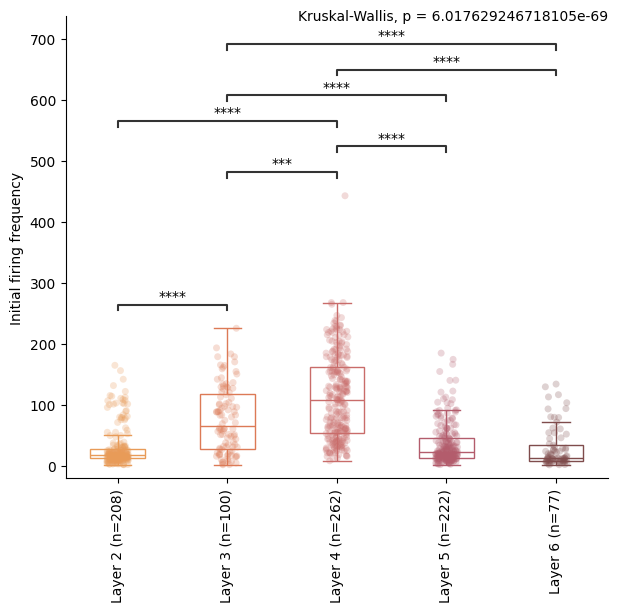

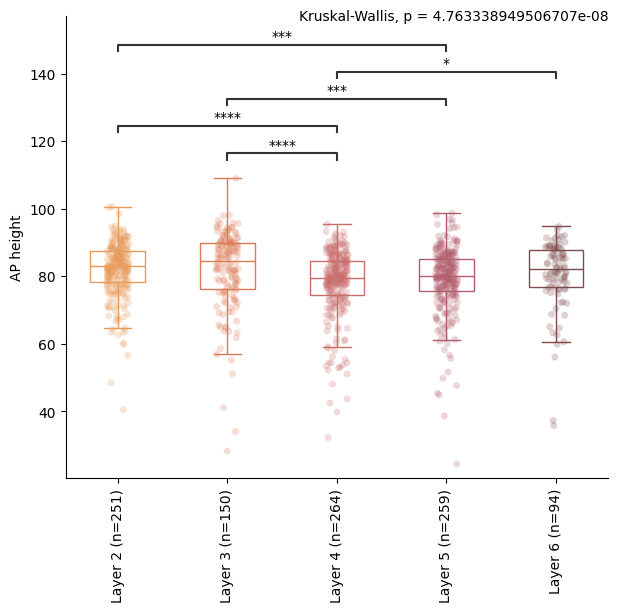

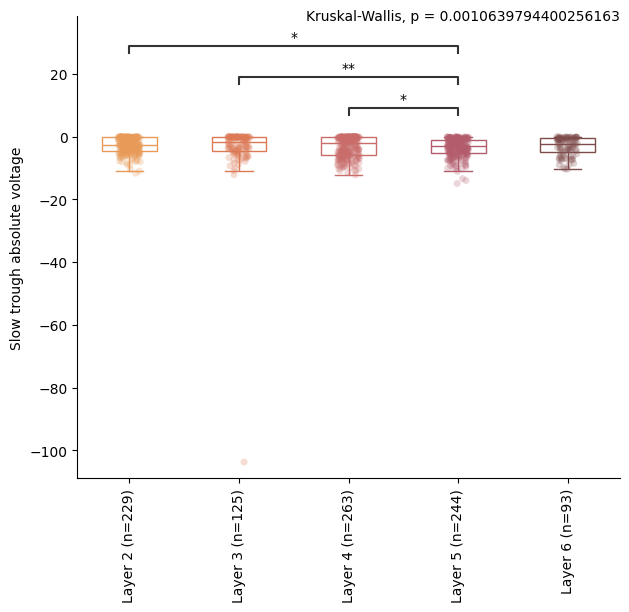

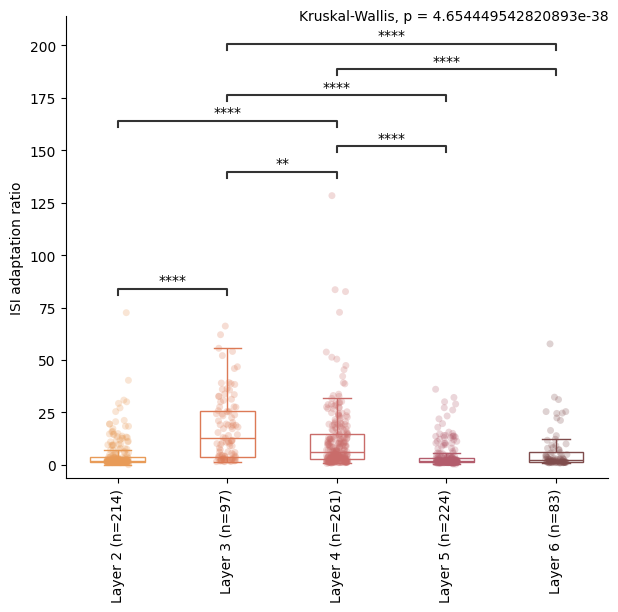

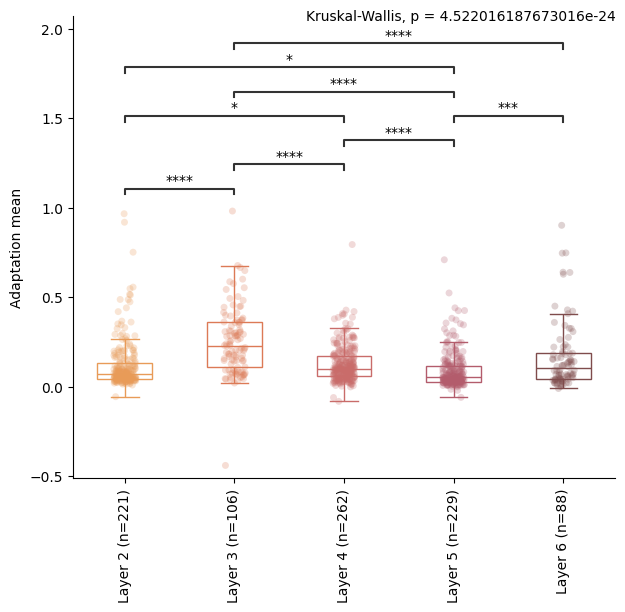

...

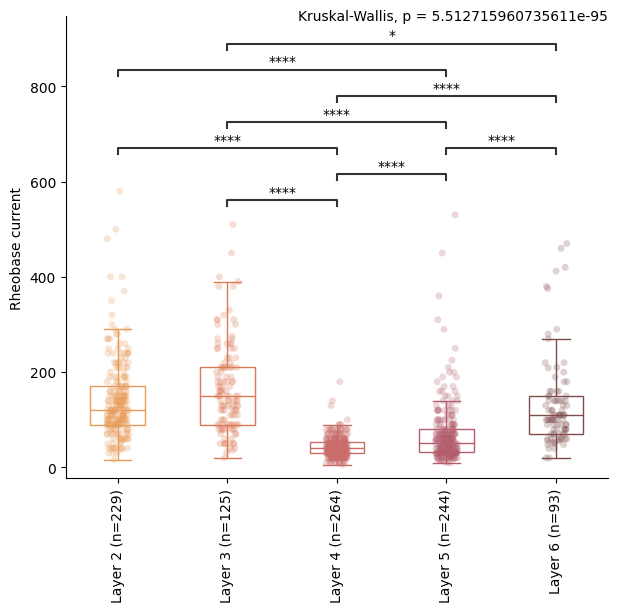

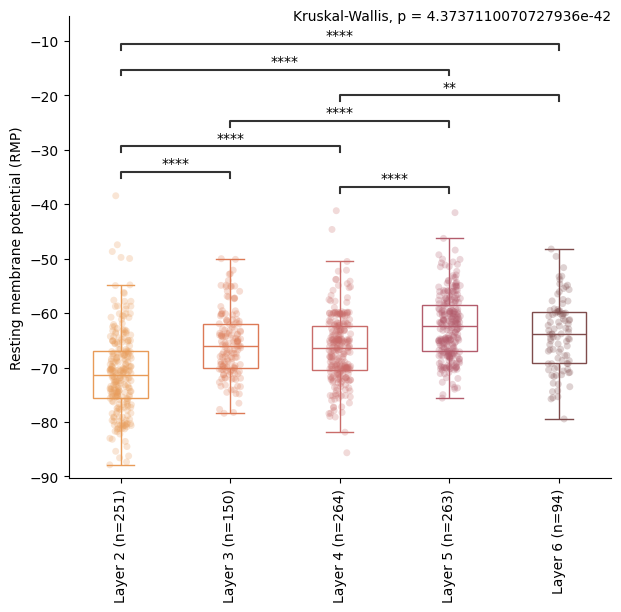

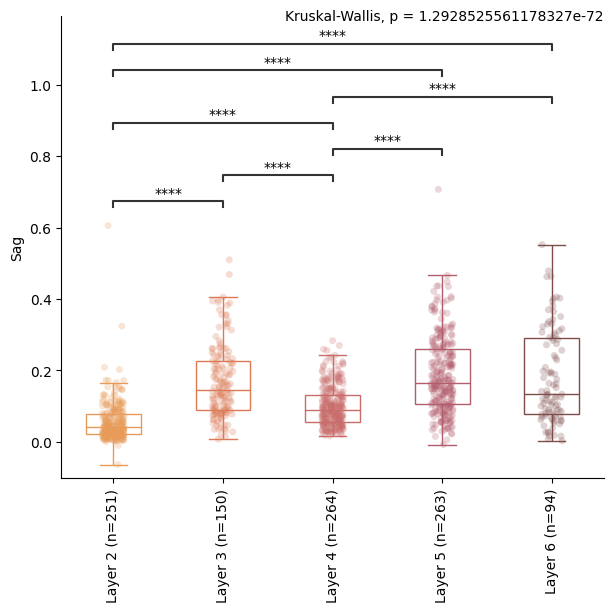

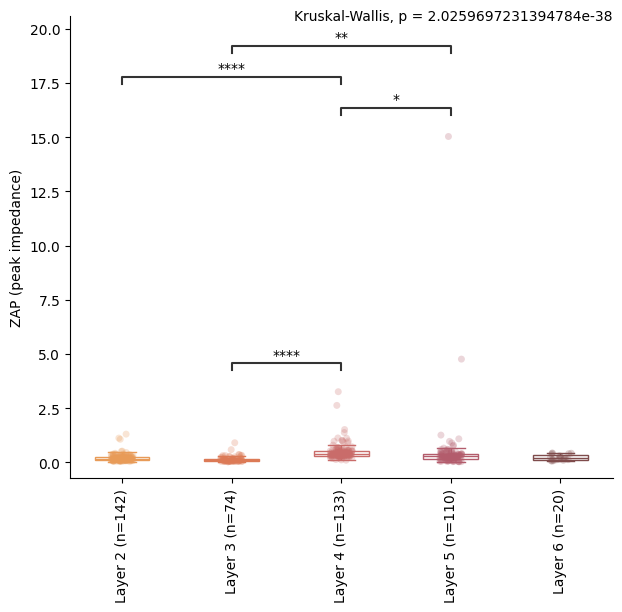

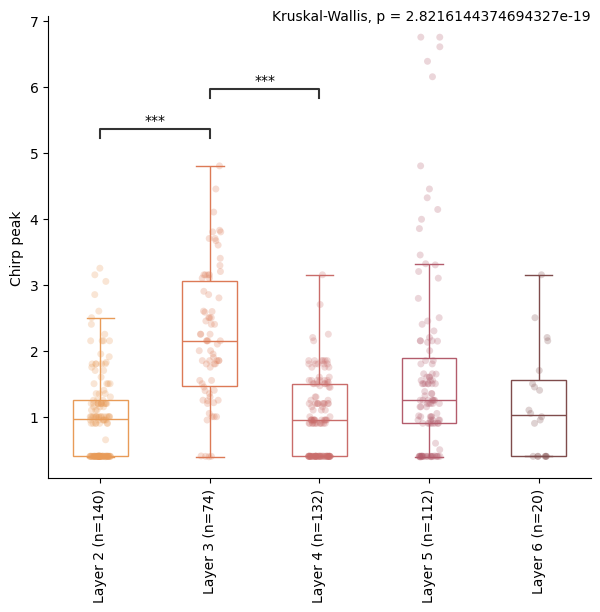

<Figure size 640x480 with 0 Axes>

In [12]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_byLayer.pdf'

hue_var = 'layer' #seperate strip plots into these categories 
color_palette = color_dicts[hue_var] #colors for x_var

#######################

ephys_features = feature_cols.copy()

fig_path = os.path.join(output_dir, fig_name)

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25) 
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, saturation=1, palette=color_palette, showfliers = False, width=0.5) 
            format_box_plot(ax) #color line not fill of boxplot

            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[(sorted_clean_data[x_var] == t) & (~sorted_clean_data[y_var].isna())])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



T-Types within each Layer x feature box plots with stats

In [14]:
#ttypes within each layer

ttype_order = group_order['t_type']

# layer x feature stats
layer_var = 'layer' #what to do box plots on 
layer_var_order = group_order[layer_var]

kw_pvals_fdr_layer = dict()
dunn_pvals_fdr_layer = dict()
for layer in layer_var_order:
    print(layer)
    layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]

    #now run stats on the ttypes in this layer 
    x_var = 't_type'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in feature_cols:
        # Create a list of groups dynamically
        groups = [layer_data.loc[layer_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(layer_data[layer_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_layer[layer] = kw_pvals_fdr
    dunn_pvals_fdr_layer[layer] = dunn_pvals_fdr

Layer 2
Layer 3
Layer 4
Layer 5


/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divid

Layer 6


In [15]:
#Save stats
rows = []

for layer in layer_var_order:
    kw_dict = kw_pvals_fdr_layer.get(layer, {})
    dunn_dict = dunn_pvals_fdr_layer.get(layer, {})
    
    for feature, kw_p in kw_dict.items():
        # if Dunn exists for this feature
        if feature in dunn_dict:
            dunn_df = dunn_dict[feature]
            # Flatten Dunn results: pairwise comparisons
            for i in dunn_df.index:
                for j in dunn_df.columns:
                    if i != j:  # skip self-comparison
                        rows.append({
                            'layer': layer,
                            'feature': feature,
                            'kw_pval_fdr': kw_p,
                            'group1': i,
                            'group2': j,
                            'dunn_pval_fdr': dunn_df.loc[i, j]
                        })
        else:
            # No post-hoc, just KW
            rows.append({
                'layer': layer,
                'feature': feature,
                'kw_pval_fdr': kw_p,
                'group1': None,
                'group2': None,
                'dunn_pval_fdr': None
            })

# Convert to DataFrame
stats_df = pd.DataFrame(rows)
stats_df.to_csv(os.path.join(output_dir, r'ephys_feature_box_plot_stats_supertypes_within_layer.csv'), index=False)
stats_df

,layer,feature,kw_pval_fdr,group1,group2,dunn_pval_fdr
0,Layer 2,Chirp peak,0.463660,None,None,NaN
1,Layer 2,ZAP (peak impedance),0.002257,L2 IT_1,L2 IT_2,0.838858
2,Layer 2,ZAP (peak impedance),0.002257,L2 IT_1,L2 IT_6,0.191882
3,Layer 2,ZAP (peak impedance),0.002257,L2 IT_1,L2 IT_7,0.768217
4,Layer 2,ZAP (peak impedance),0.002257,L2 IT_2,L2 IT_1,0.838858
...,...,...,...,...,...,...
4932,Layer 6,ISI adaptation ratio,0.027658,L6b_6,L6b_1,0.766396
4933,Layer 6,ISI adaptation ratio,0.027658,L6b_6,L6b_3,0.856096
4934,Layer 6,Slow trough absolute voltage,0.851250,None,None,NaN
4935,Layer 6,AP height,0.728429,None,None,NaN


In [17]:
os.path.join(output_dir, r'ephys_feature_box_plot_stats_supertypes_within_layer.csv')

'/root/capsule/scratch/20260807/ephys/ephys_feature_box_plot_stats_supertypes_within_layer.csv'

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:3.488e-04
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:4.245e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:1.432e-07
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:7.200e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:2.814e-02


... (13 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:5.960e-06
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:3.481e-05


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_1 vs. L2 IT_2: Custom statistical test, P_val:5.147e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


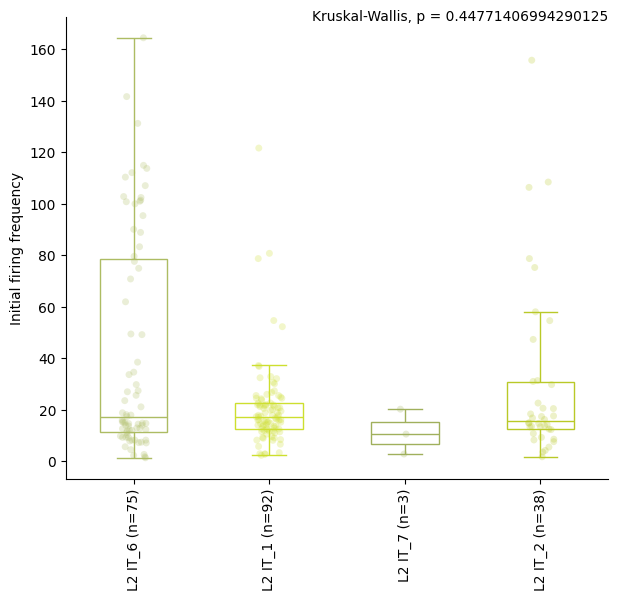

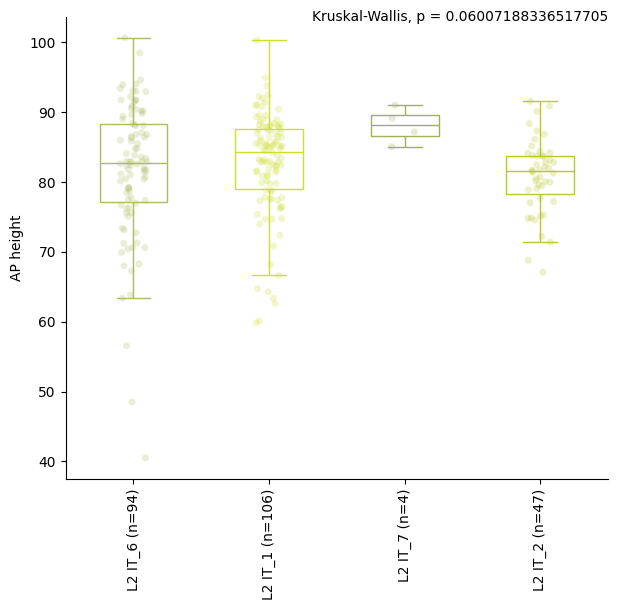

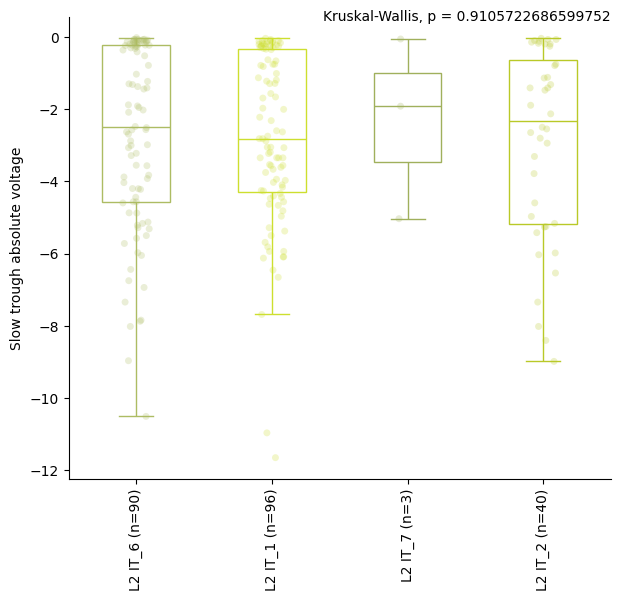

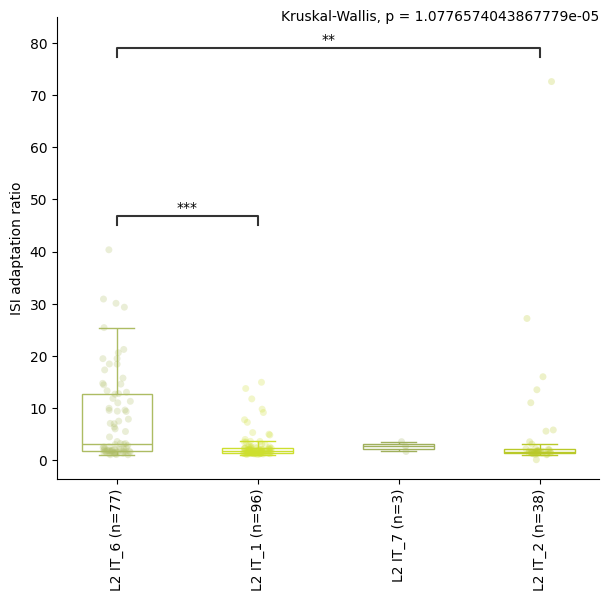

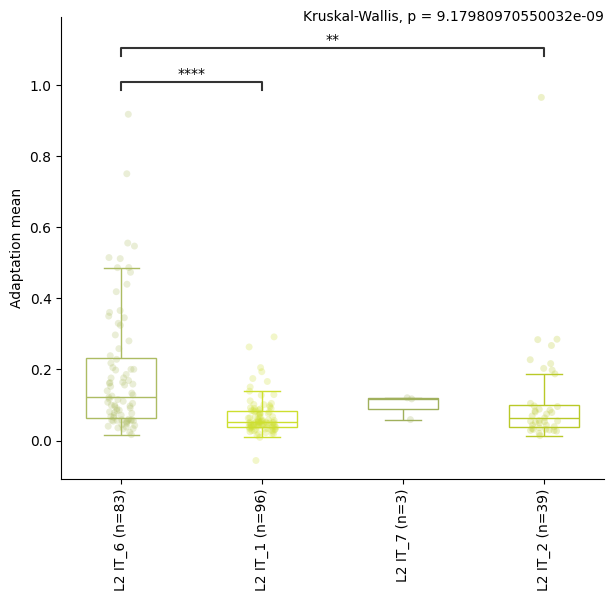

...

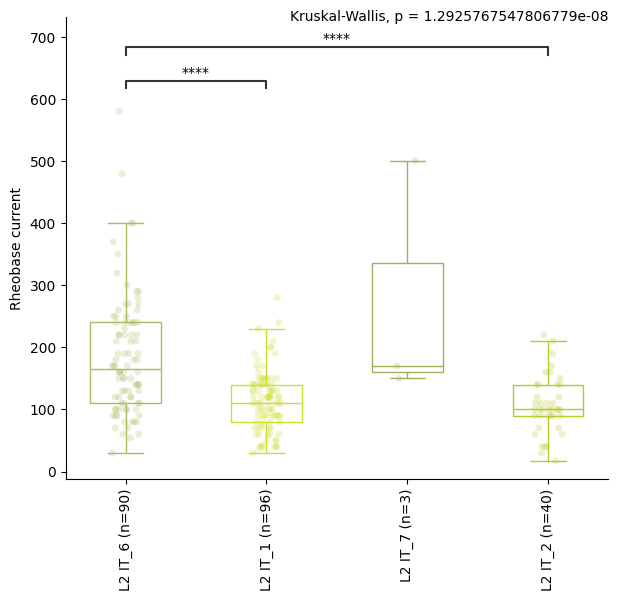

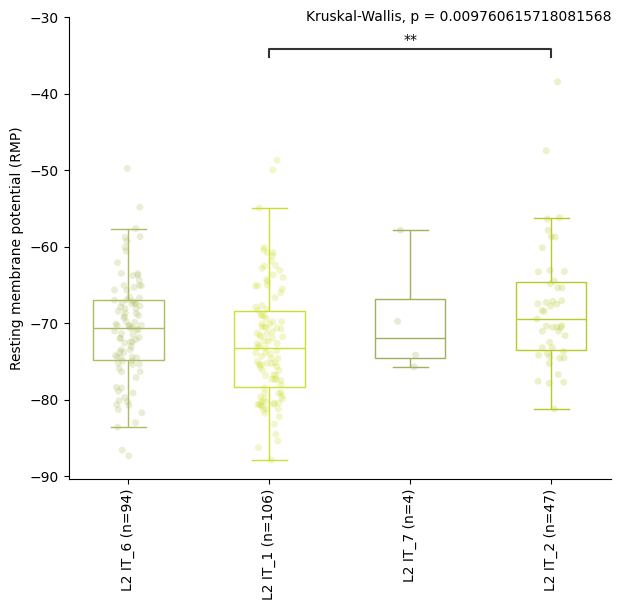

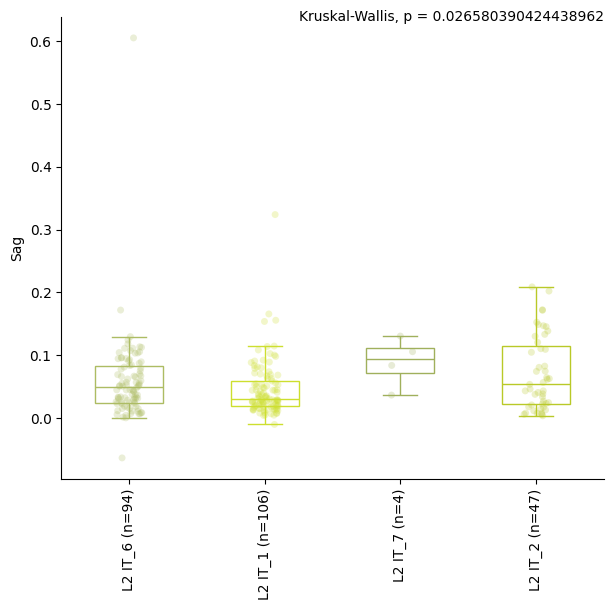

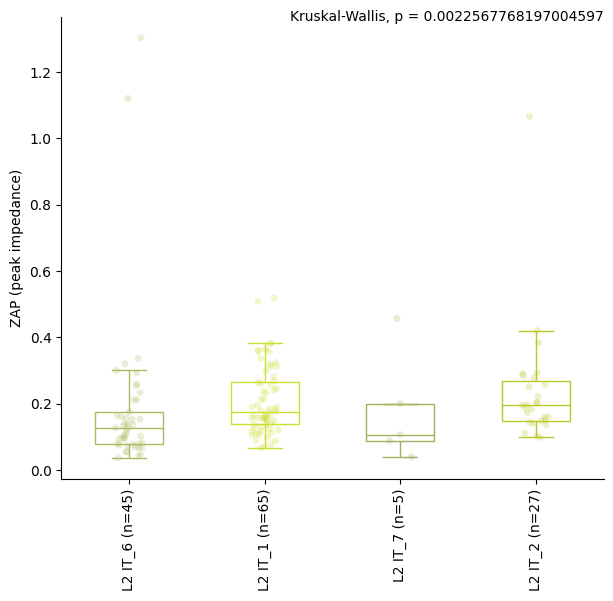

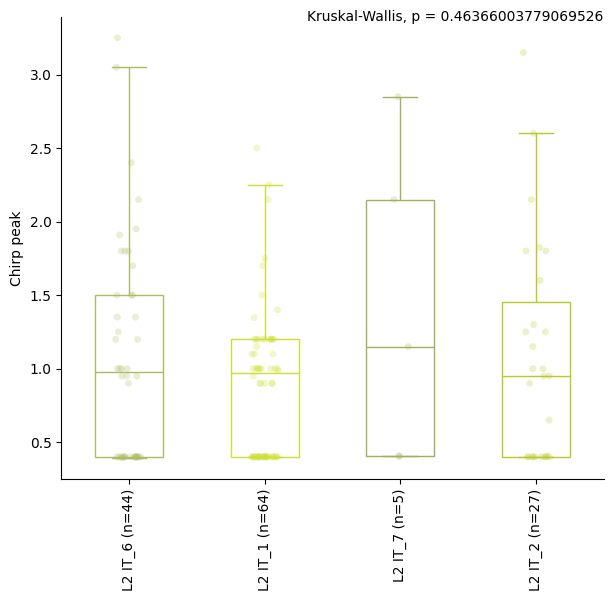

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:1.430e-03
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:6.199e-03
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:5.502e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_10 vs. L3 IT_13: Custom statistical test, P_val:9.221e-03
L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:2.811e-03
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:1.906e-03
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:2.292e-02


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_12 vs. L3 IT_10: Custom statistical test, P_val:2.125e-02
L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:1.663e-06
L3 IT_8 vs. L3 IT_12: Custom statistical test, P_val:3.465e-02
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:8.549e-05
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:1.308e-03
L3 IT_10 vs. L3 IT_5: Custom statistical test, P_val:5.573e-03
L3 IT_10 vs. L3 IT_3: Custom statistical test, P_val:2.470e-02
L3 IT_8 vs. L3 IT_5: Custom statistical test, P_val:2.686e-02
L3 IT_8 vs. L3 IT_3: Custom statistical test, P_val:2.686e-02


... (6 outputs left out)

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_10 vs. L3 IT_13: Custom statistical test, P_val:6.253e-03
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:5.782e-04
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:9.278e-03
L3 IT_12 vs. L3 IT_5: Custom statistical test, P_val:1.246e-02
L3 IT_8 vs. L3 IT_13: Custom statistical test, P_val:1.670e-03
L3 IT_8 vs. L3 IT_5: Custom statistical test, P_val:9.278e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

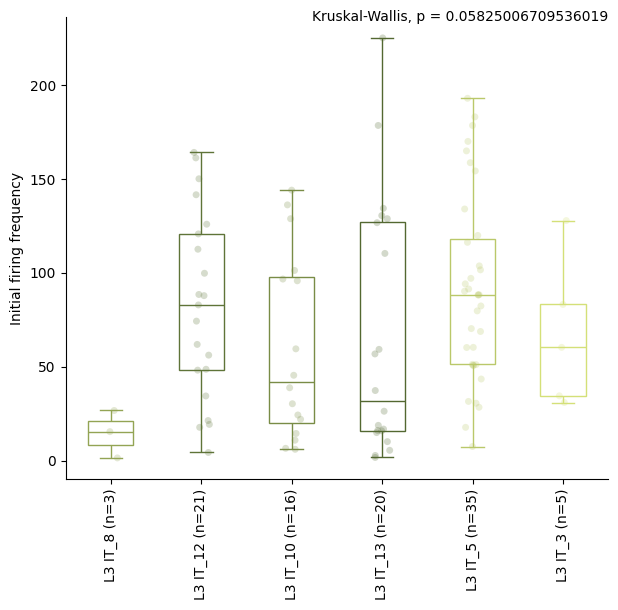

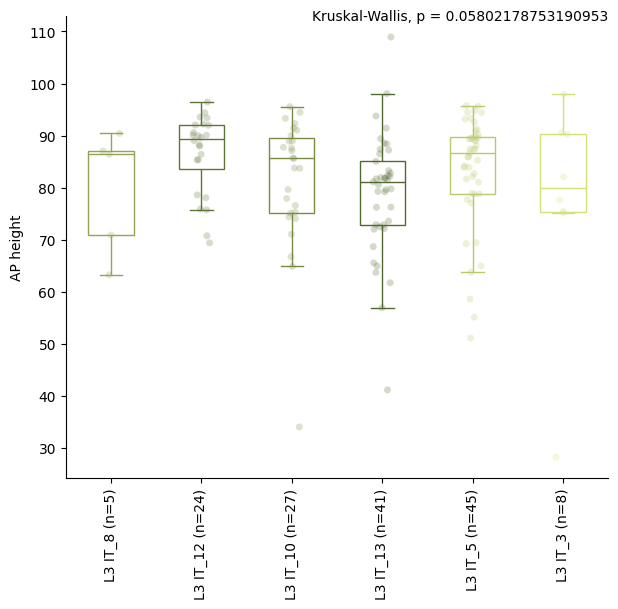

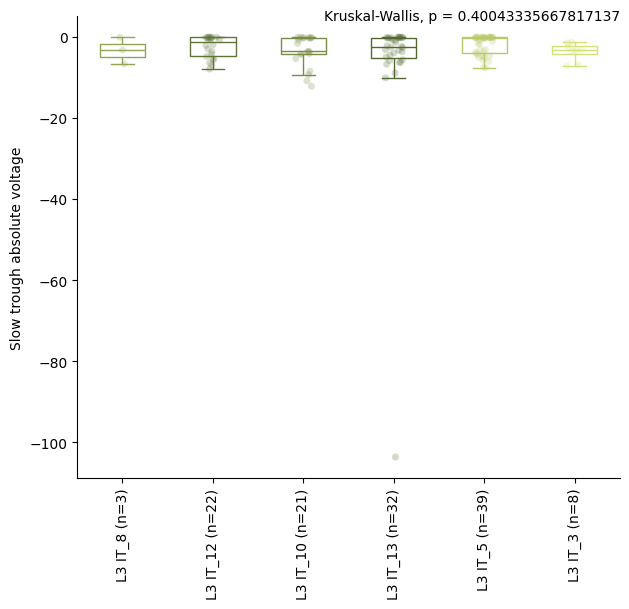

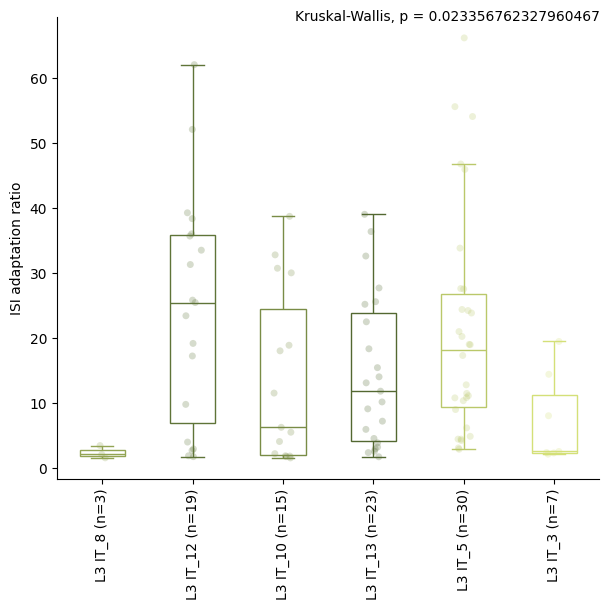

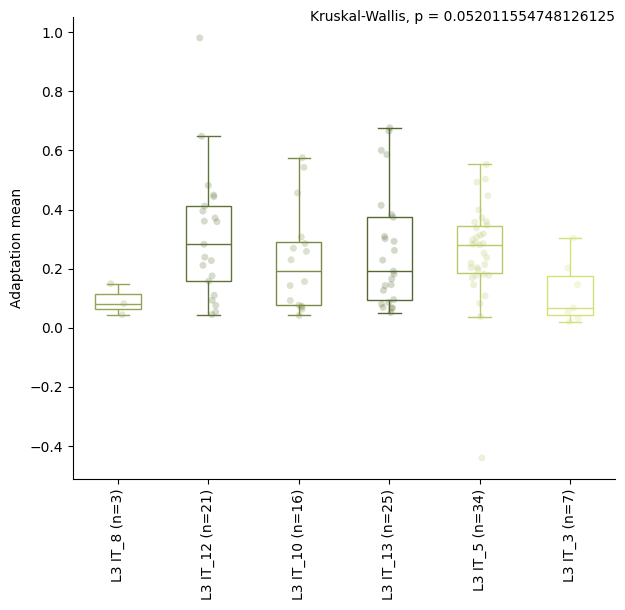

...

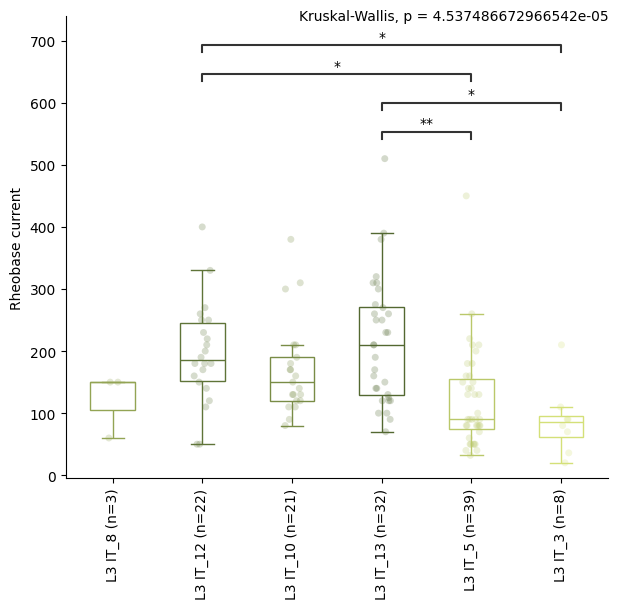

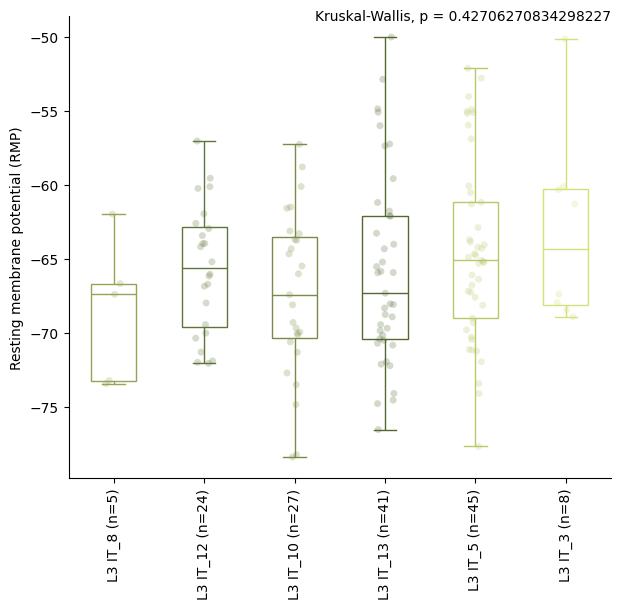

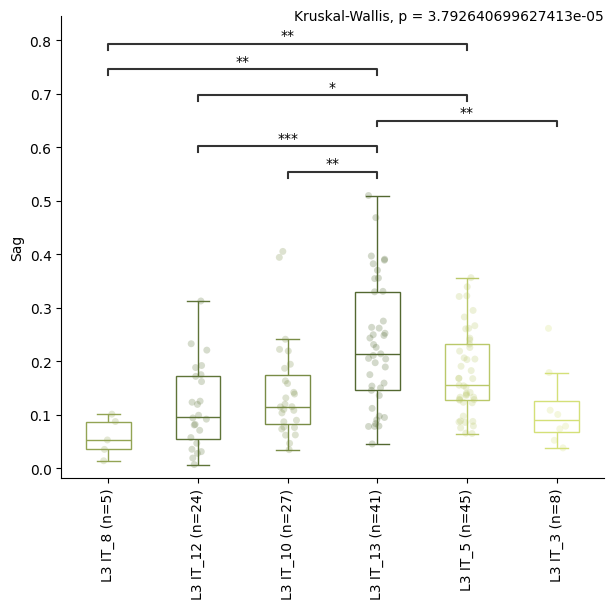

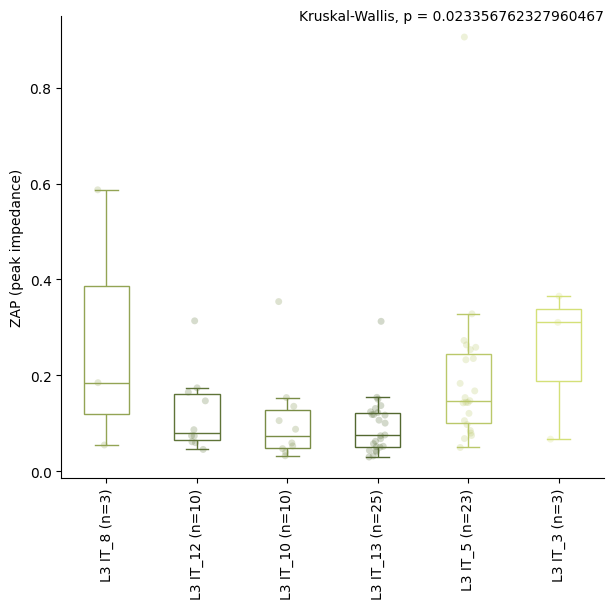

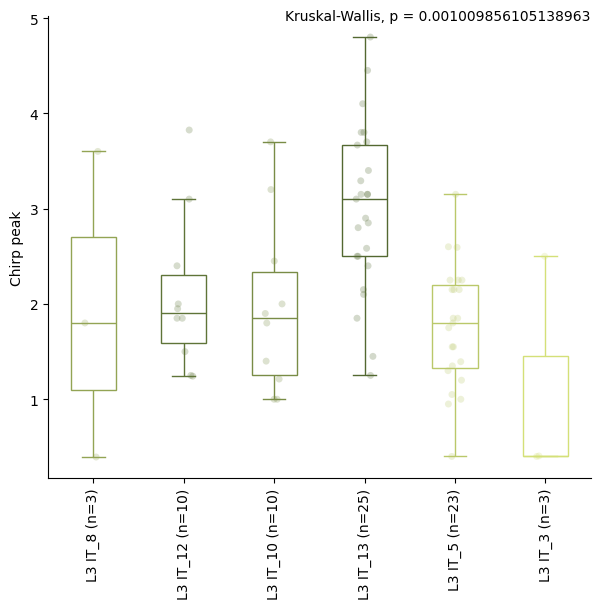

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:3.971e-12
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:2.050e-12
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:5.131e-04
L4 IT_3 vs. L4 IT_1: Custom statistical test, P_val:1.228e-04


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.041e-03
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.016e-08
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.988e-02


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.791e-07
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.971e-03


... (28 outputs left out)

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.836e-08
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.586e-02
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:1.187e-03
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:4.357e-02
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:6.828e-12


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

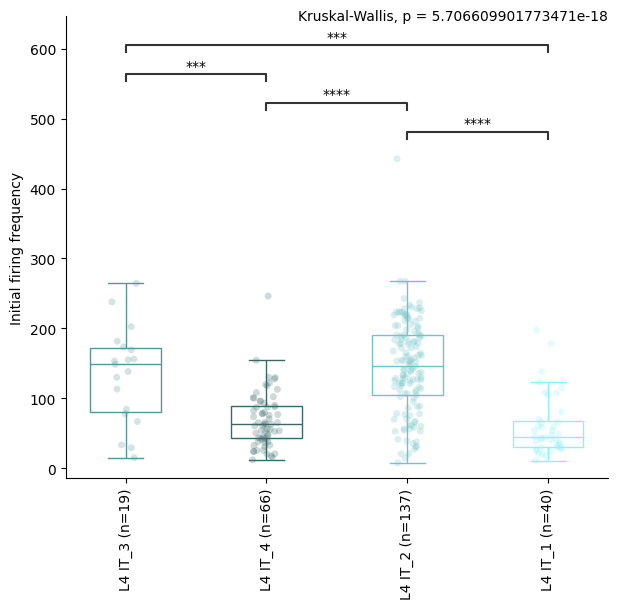

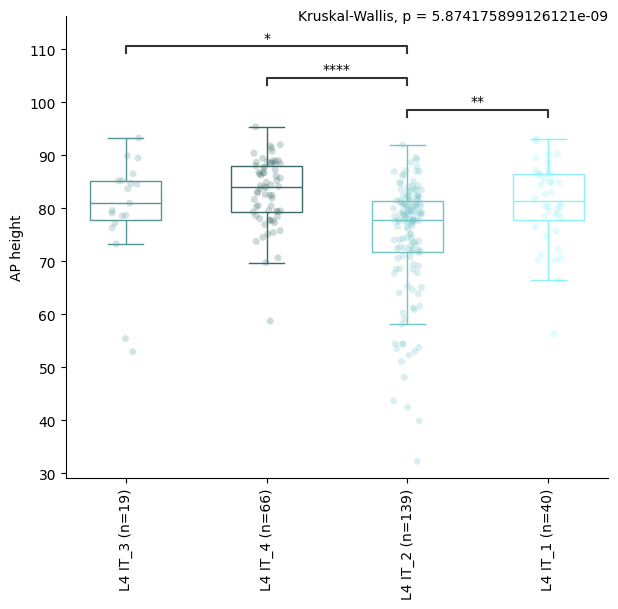

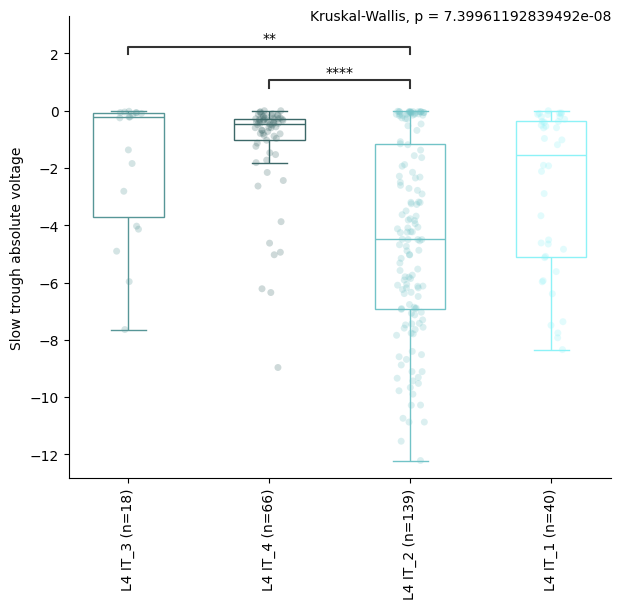

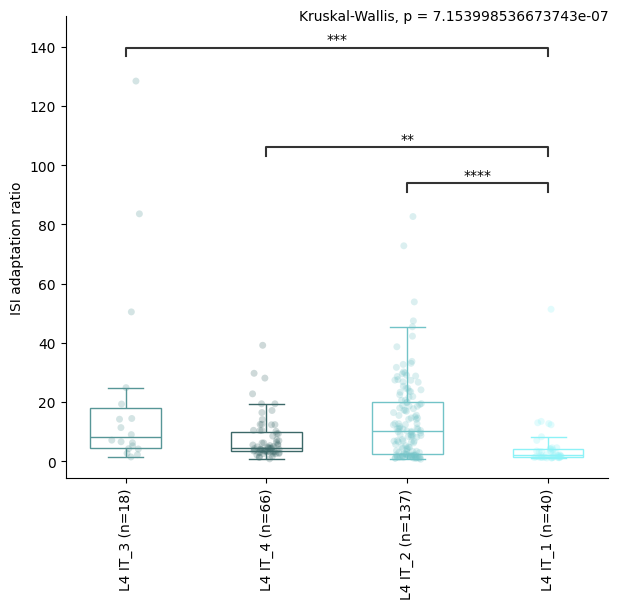

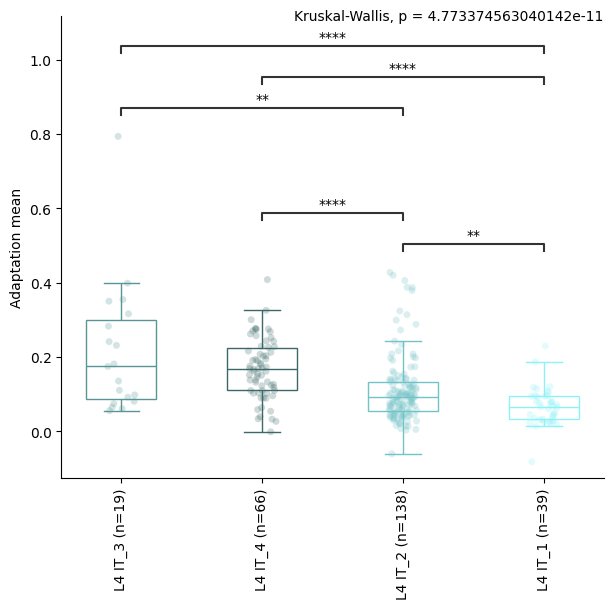

...

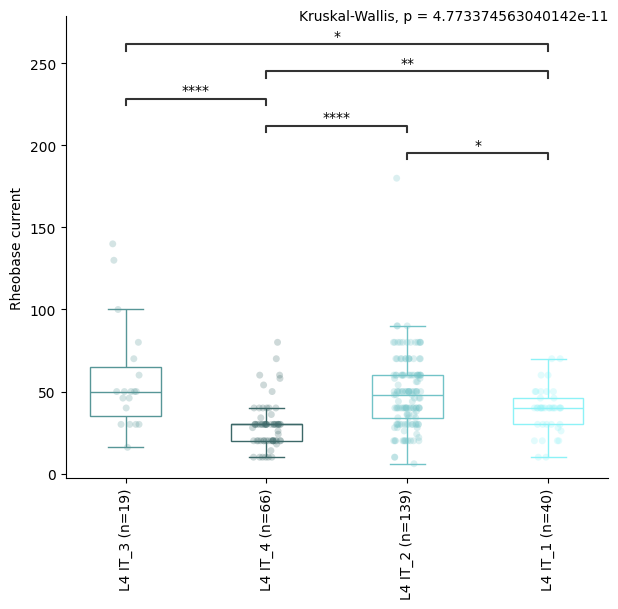

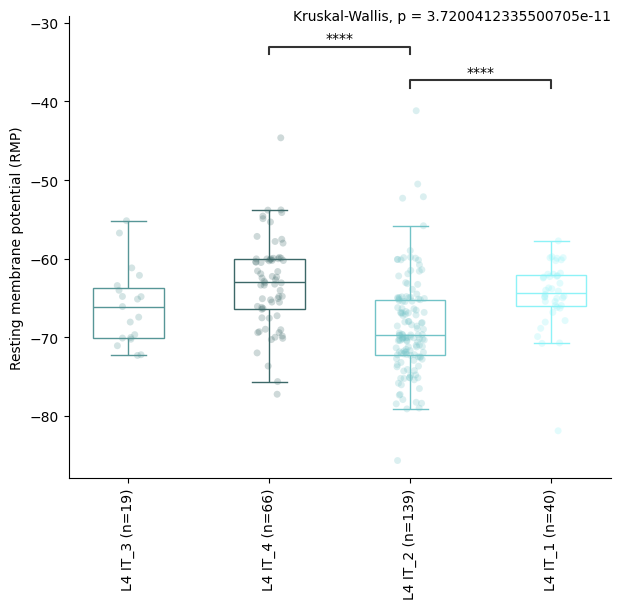

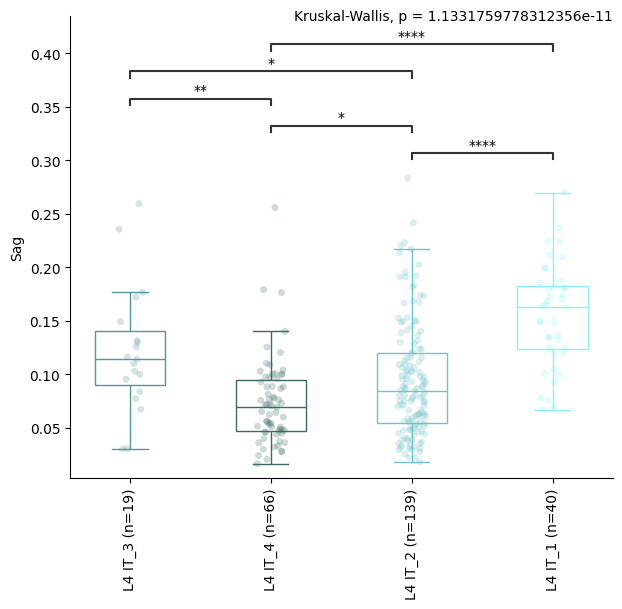

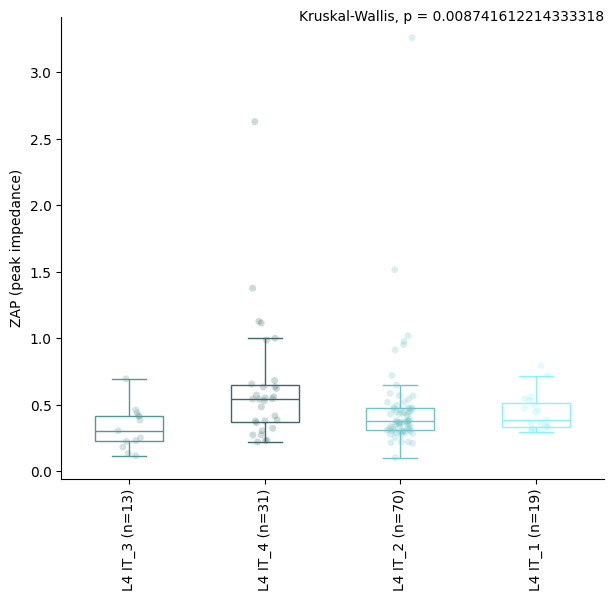

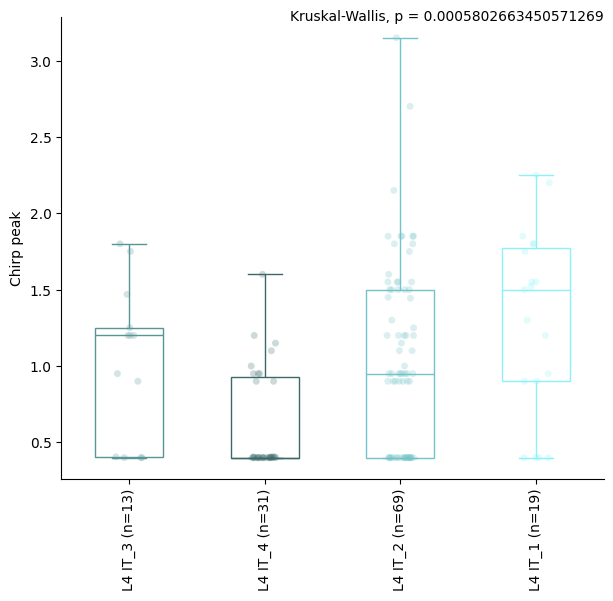

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_5 vs. L5 IT_2: Custom statistical test, P_val:6.742e-03
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:2.613e-07
L5 IT_6 vs. L5 IT_7: Custom statistical test, P_val:2.388e-02
L5 IT_2 vs. L5/6 NP_2: Custom statistical test, P_val:2.762e-02
L5/6 NP_2 vs. L5 ET_2: Custom statistical test, P_val:2.911e-02
L5 IT_5 vs. L5 ET_2: Custom statistical test, P_val:2.911e-02
L5 IT_6 vs. L5 ET_2: Custom statistical test, P_val:7.199e-04


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_5 vs. L5/6 NP_1: Custom statistical test, P_val:4.621e-02
L5 IT_5 vs. L5 ET_2: Custom statistical test, P_val:3.935e-02
L5 IT_6 vs. L5 ET_2: Custom statistical test, P_val:4.621e-02


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_5 vs. L5 IT_2: Custom statistical test, P_val:6.742e-04
L5/6 NP_4 vs. L5 ET_1: Custom statistical test, P_val:4.707e-02
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:3.006e-08
L5 IT_6 vs. L5 IT_1: Custom statistical test, P_val:2.276e-03
L5/6 NP_1 vs. L5 ET_1: Custom statistical test, P_val:1.094e-02
L5 IT_6 vs. L5 IT_7: Custom statistical test, P_val:2.080e-02
L5 IT_2 vs. L5/6 NP_2: Custom statistical test, P_val:4.707e-02
L5/6 NP_6 vs. L5 ET_1: Custom statistical test, P_val:4.927e-02
L5 IT_6 vs. L5 IT_3: Custom statistical test, P_val:4.473e-02
L5/6 NP_2 vs. L5 ET_1: Custom statistical test, P_val:8.707e-03
L5/6 NP_2 vs. L5 ET_2: Custom statistical test, P_val:4.473e-02
L5 IT_7 vs. L5 ET_1: Custom statistical test, P_val:1.463e-02
L5 IT_5 vs. L5 ET_1: Custom statistical test, P_val:

... (10 outputs left out)

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_3 vs. L5/6 NP_1: Custom statistical test, P_val:4.819e-02
L5 IT_1 vs. L5/6 NP_2: Custom statistical test, P_val:1.332e-03
L5 IT_7 vs. L5/6 NP_1: Custom statistical test, P_val:8.431e-03
L5 IT_2 vs. L5/6 NP_2: Custom statistical test, P_val:1.042e-02
L5 IT_1 vs. L5/6 NP_1: Custom statistical test, P_val:3.080e-05
L5 IT_5 vs. L5/6 NP_2: Custom statistical test, P_val:9.474e-04
L5 IT_2 vs. L5/6 NP_1: Custom statistical test, P_val:4.495e-05
L5 IT_5 vs. L5/6 NP_1: Custom statistical test, P_val:1.531e-06
L5 IT_1 vs. L5/6 NP_4: Custom statistical test, P_val:6.322e-04
L5 IT_1 vs. L5 ET_1: Custom statistical test, P_val:9.215e-03
L5 IT_6 vs. L5/6 NP_1: Custom statistical test, P_val:1.590e-03
L5 IT_2 vs. L5/6 NP_4: Custom statistical test, P_val:4.709e-03
L5 IT_1 vs. L5 ET_2: Custom statistical te

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

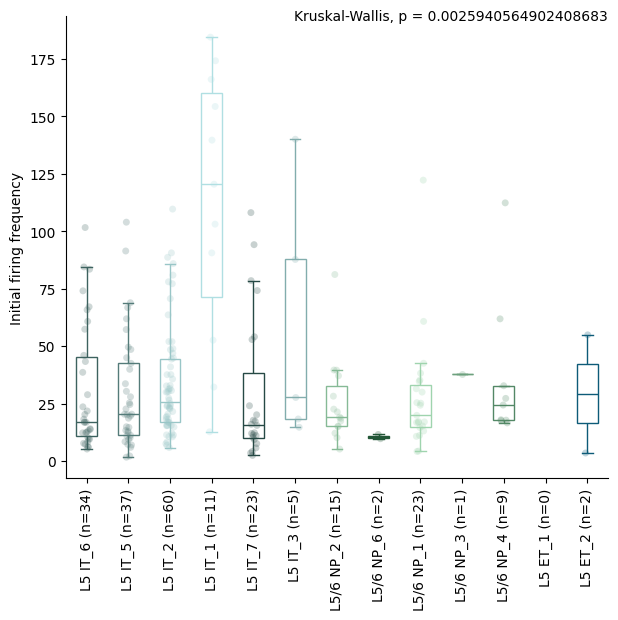

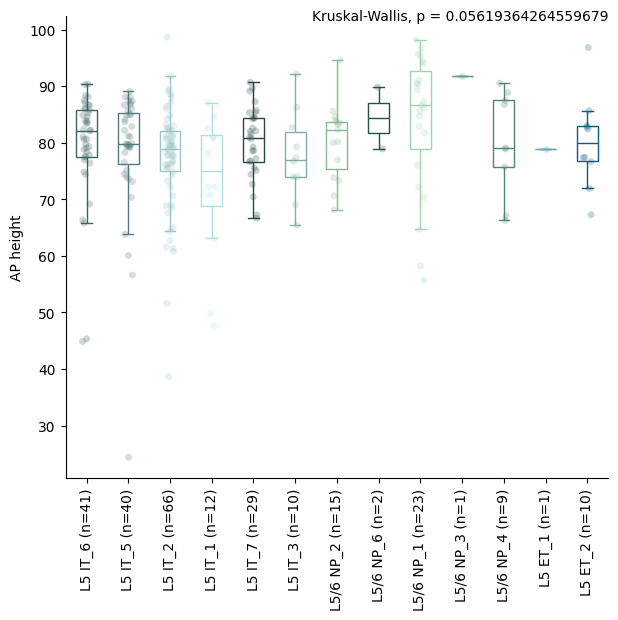

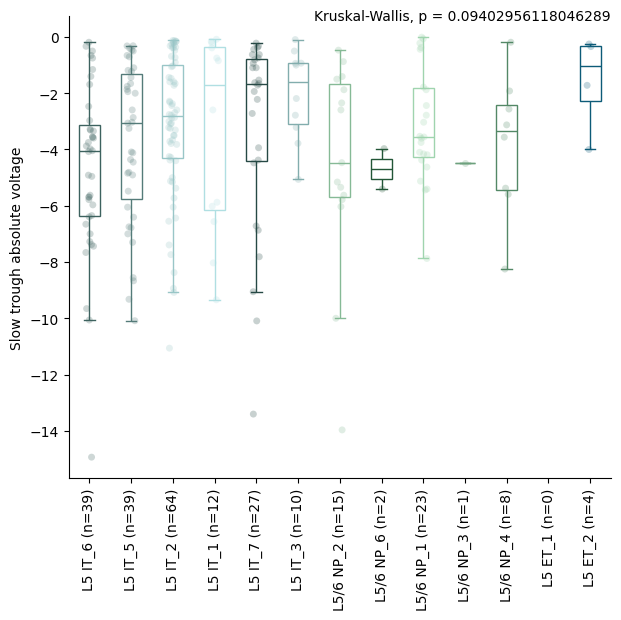

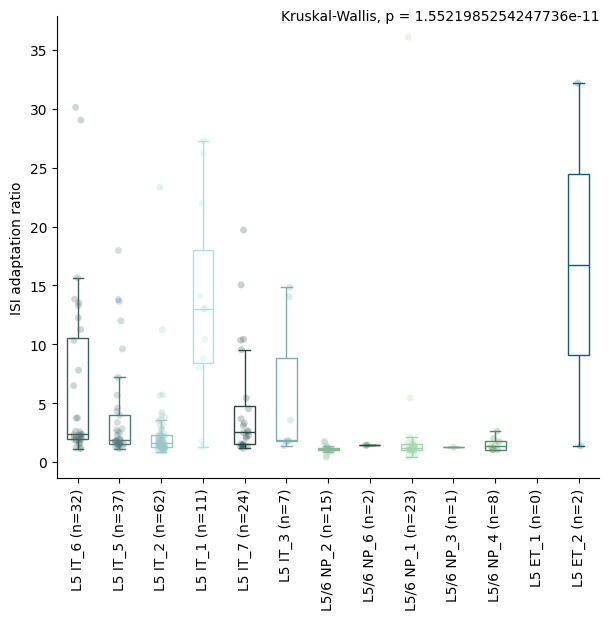

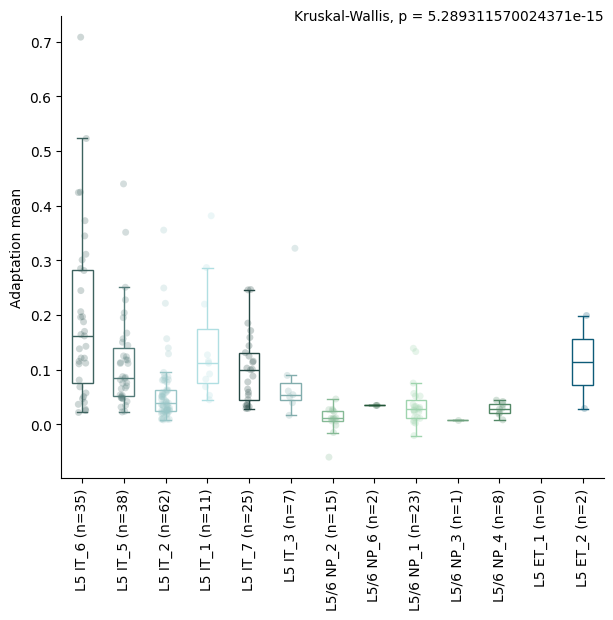

...

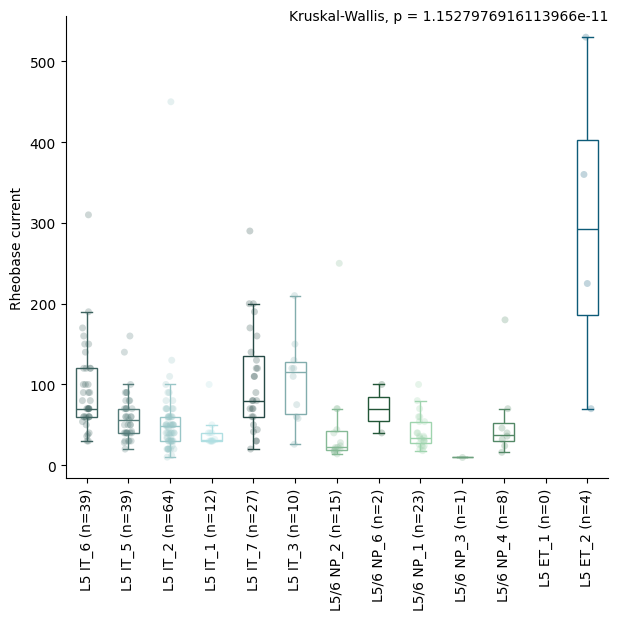

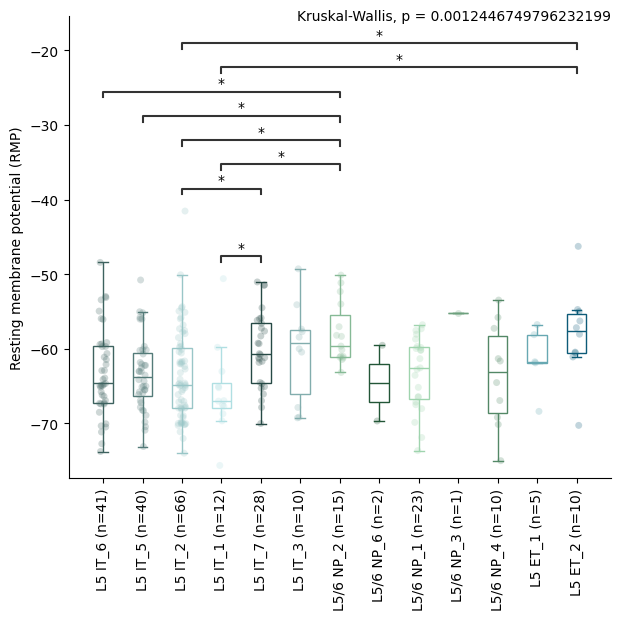

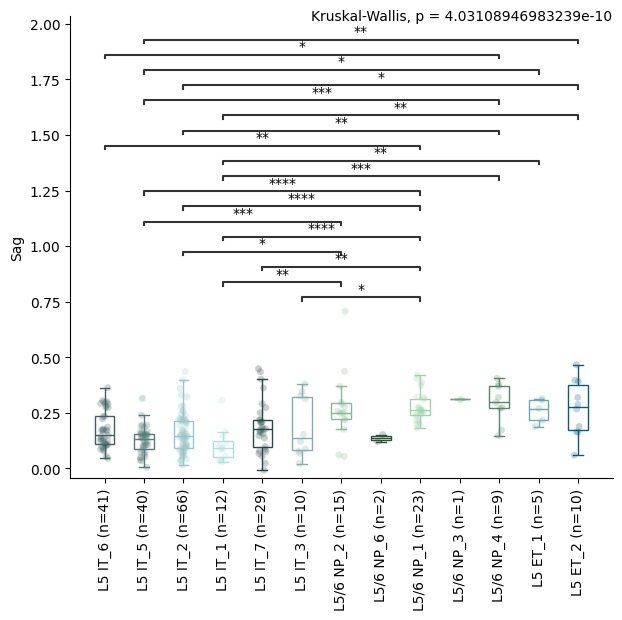

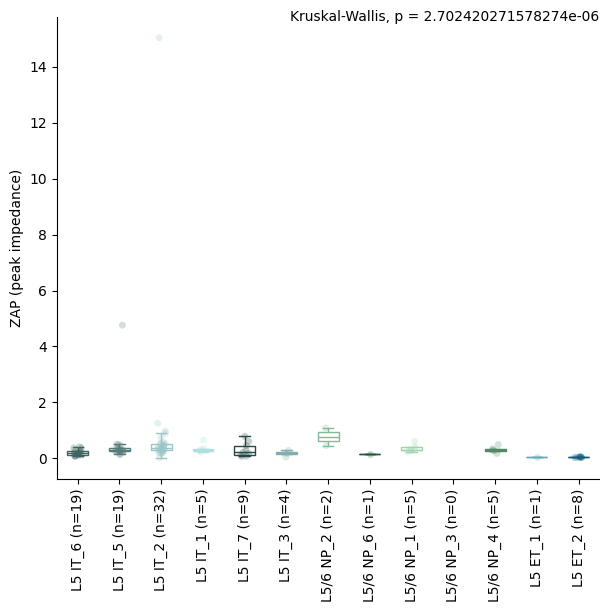

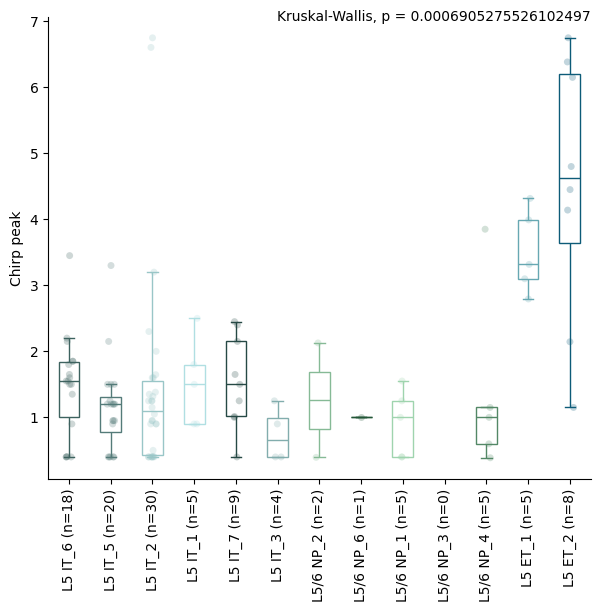

/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:3.064e-02
L6 IT Car3_3 vs. L6 IT_2: Custom statistical test, P_val:4.909e-03
L6 IT Car3_2 vs. L6 CT_3: Custom statistical test, P_val:1.856e-02
L6 IT Car3_3 vs. L6 IT_1: Custom statistical test, P_val:1.277e-03
L6 IT Car3_2 vs. L6 CT_2: Custom statistical test, P_val:3.700e-02
L6 IT Car3_3 vs. L6 CT_3: Custom statistical test, P_val:4.909e-03
L6 IT Car3_3 vs. L6 CT_2: Custom statistical test, P_val:1.856e-02
L6 IT Car3_2 vs. L6 CT_1: Custom statistical test, P_val:2.764e-02
L6 IT Car3_3 vs. L6 CT_1: Custom statistical test, P_val:1.277e-03
L6 IT Car3_2 vs. L6b_6: Custom statistical test, P_val:3.319e-02
L6 IT Car3_3 vs. L6b_6: Custom statistical test, P_val:4.909e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:3.206e-02
L6 IT Car3_3 vs. L6 IT_2: Custom statistical test, P_val:1.358e-04
L6 IT Car3_2 vs. L6 CT_3: Custom statistical test, P_val:4.688e-02
L6 IT Car3_3 vs. L6 IT_1: Custom statistical test, P_val:3.269e-02
L6 IT Car3_1 vs. L6 IT_2: Custom statistical test, P_val:3.269e-02
L6 IT Car3_3 vs. L6 CT_3: Custom statistical test, P_val:2.588e-02
L6 IT Car3_2 vs. L6b_6: Custom statistical test, P_val:3.051e-02
L6 IT Car3_3 vs. L6b_6: Custom statistical test, P_val:3.180e-04
L6 IT Car3_1 vs. L6b_6: Custom statistical test, P_val:3.210e-02


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:33: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should onl

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 CT_1 vs. L6b_6: Custom statistical test, P_val:1.661e-02
L6 IT Car3_1 vs. L6b_6: Custom statistical test, P_val:7.234e-03


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:2.431e-02
L6 IT Car3_2 vs. L6 CT_3: Custom statistical test, P_val:3.539e-02
L6 IT Car3_1 vs. L6 IT_2: Custom statistical test, P_val:2.431e-02
L6 IT Car3_2 vs. L6 CT_2: Custom statistical test, P_val:4.119e-02
L6 IT Car3_1 vs. L6 CT_3: Custom statistical test, P_val:4.376e-02


/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4223943098.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

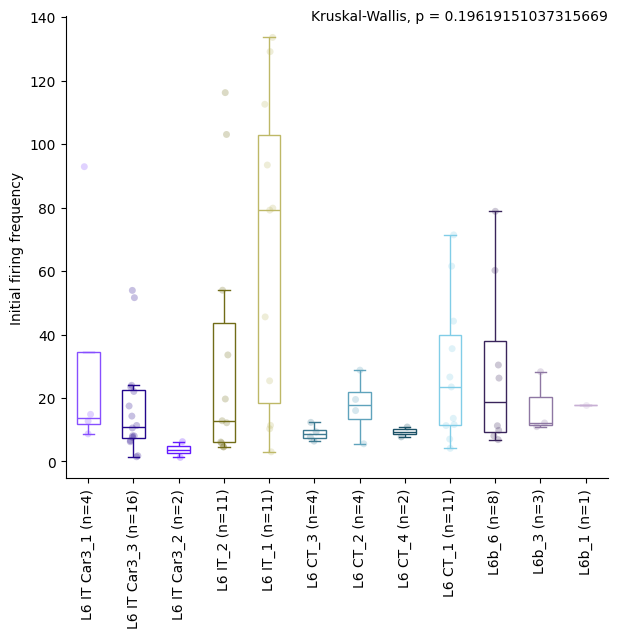

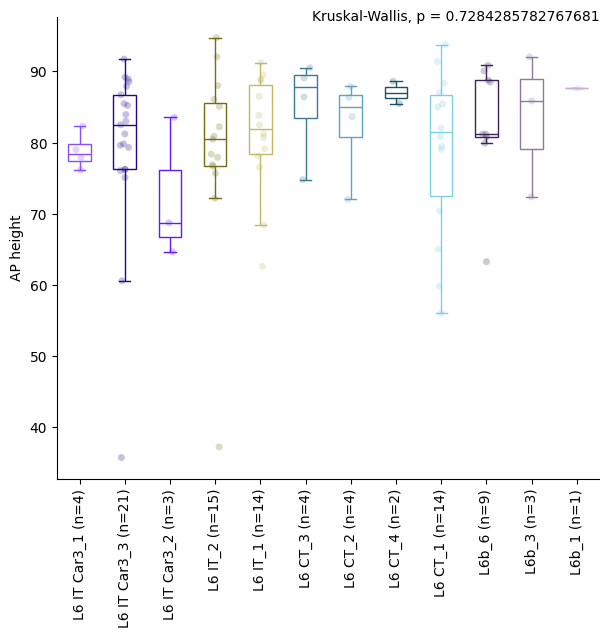

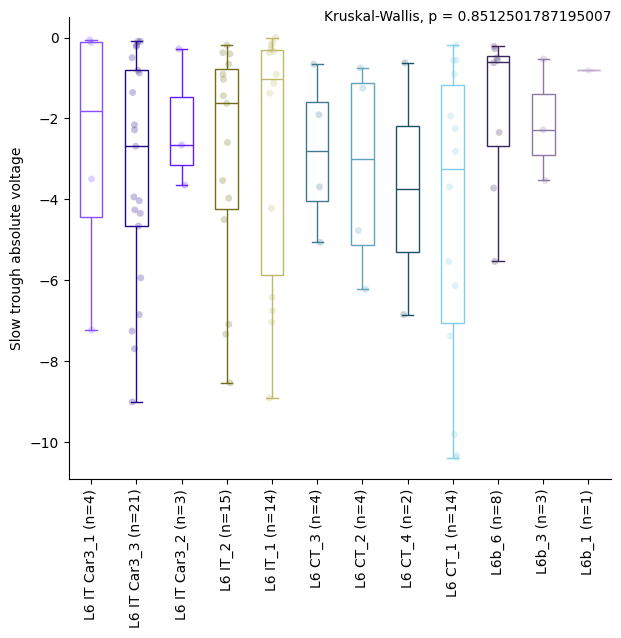

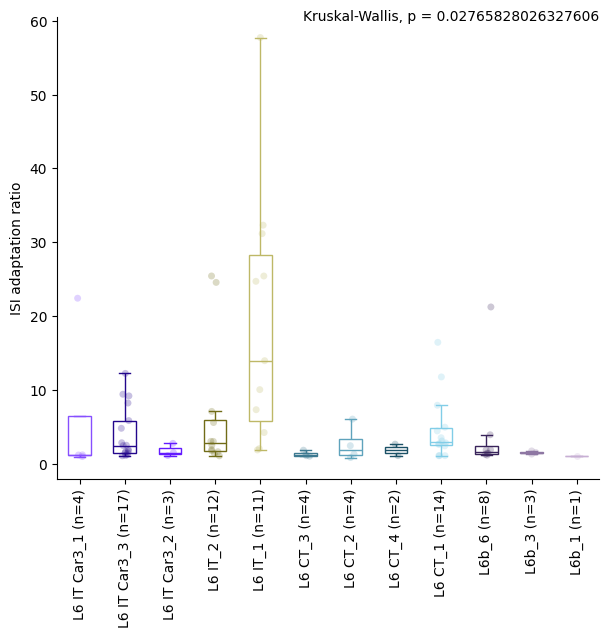

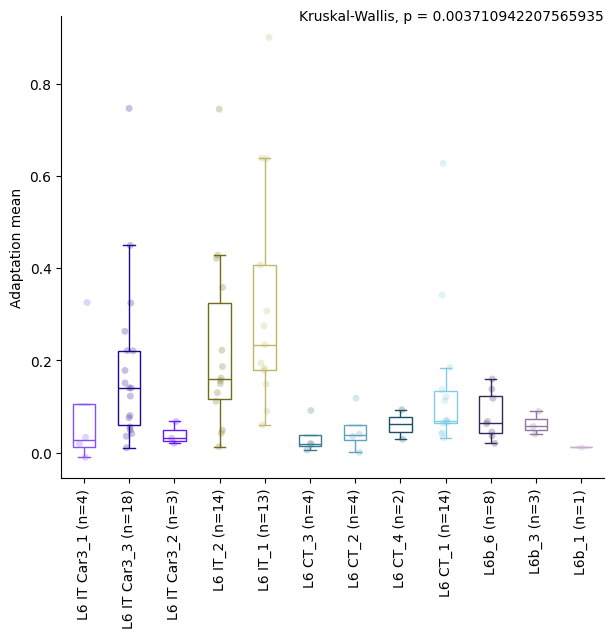

...

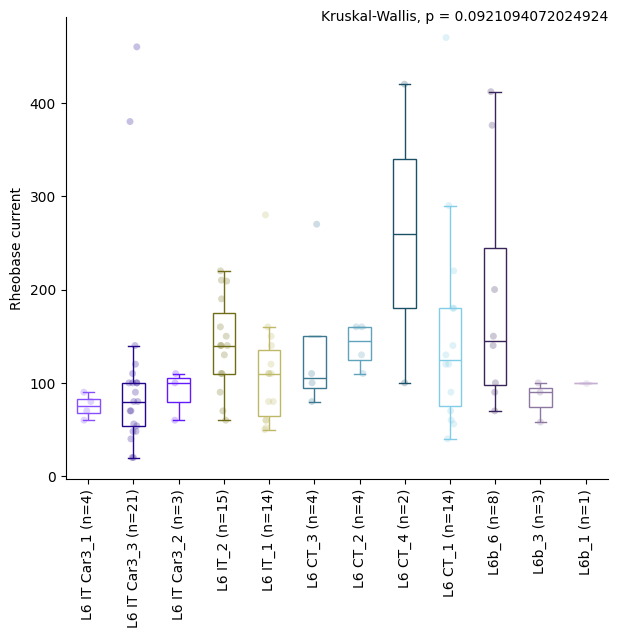

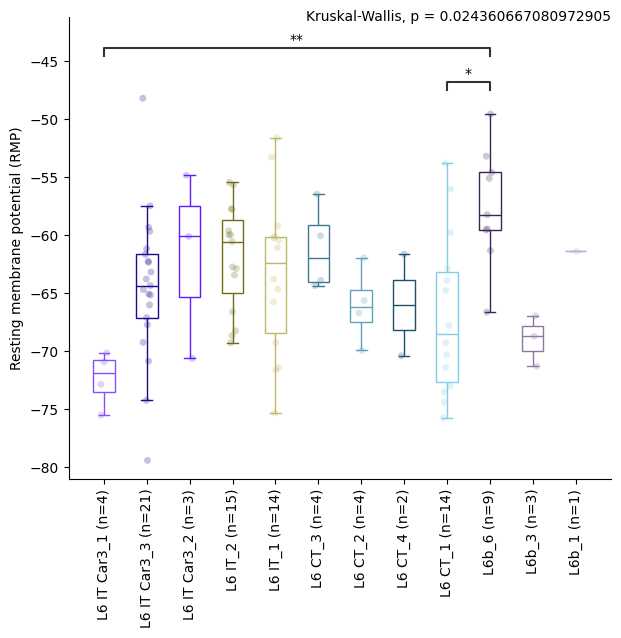

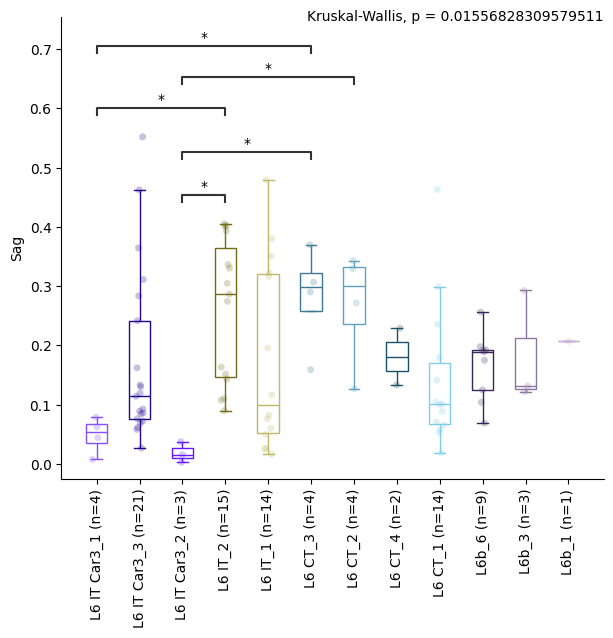

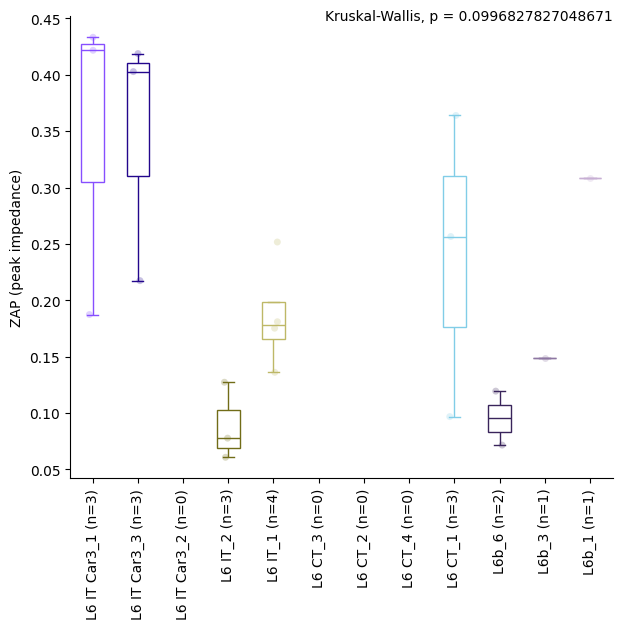

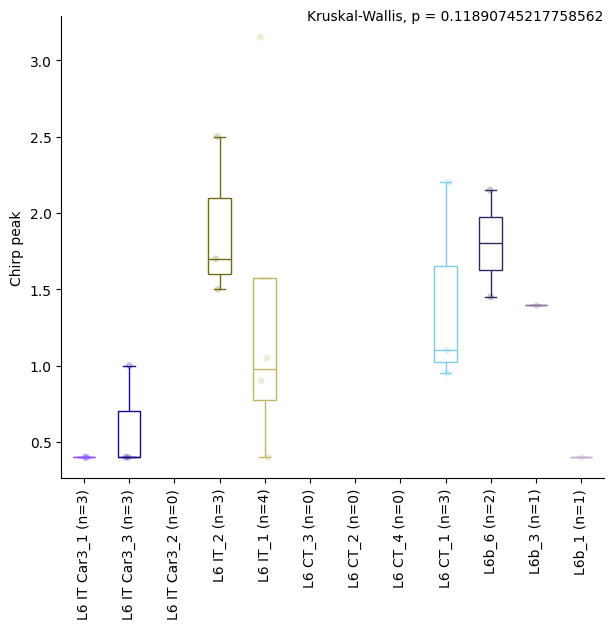

<Figure size 640x480 with 0 Axes>

In [15]:
# ttype x feature box plots

ttype_order = group_order['t_type']

for layer in kw_pvals_fdr_layer.keys():
    if kw_pvals_fdr_layer[layer]:
        #layer has results (there were enough ttypes in the layer, etc.)
        layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]
        kw_pvals_fdr = kw_pvals_fdr_layer[layer]  
        dunn_pvals_fdr = dunn_pvals_fdr_layer[layer]
        x_var = 't_type'  # what to do box plots on
        x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_{}_byTtype.pdf'.format(layer.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 't_type' #seperate strip plots into these categories 
        hue_color_palette = color_dicts[hue_var] #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        ephys_features = feature_cols.copy()

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while ephys_features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = ephys_features.pop()
                    
                    sns.stripplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(layer_data[(layer_data[x_var] == t) & (~layer_data[y_var].isna())])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=layer_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



Subclasses within each Layer x feature box plots with stats

In [16]:
#subclasses within each layer

ttype_order = group_order['subclass_label']

# layer x feature stats
layer_var = 'layer' #what to do box plots on 
layer_var_order = ['Layer 5', 'Layer 6']

kw_pvals_fdr_layer = dict()
dunn_pvals_fdr_layer = dict()
for layer in layer_var_order:
    print(layer)
    layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]

    #now run stats on the subclasses in this layer 
    x_var = 'subclass_label'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in feature_cols:
        # Create a list of groups dynamically
        groups = [layer_data.loc[layer_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(layer_data[layer_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_layer[layer] = kw_pvals_fdr
    dunn_pvals_fdr_layer[layer] = dunn_pvals_fdr

Layer 5
Layer 6


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:1.589e-02


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:5.153e-09


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:6.962e-10
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP vs. L5 ET: Custom statistical test, P_val:3.434e-02
L5 IT vs. L5/6 NP: Custom statistical test, P_val:5.587e-05


... (25 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5 ET: Custom statistical test, P_val:4.132e-02


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:7.909e-11
L5 IT vs. L5 ET: Custom statistical test, P_val:2.878e-04


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


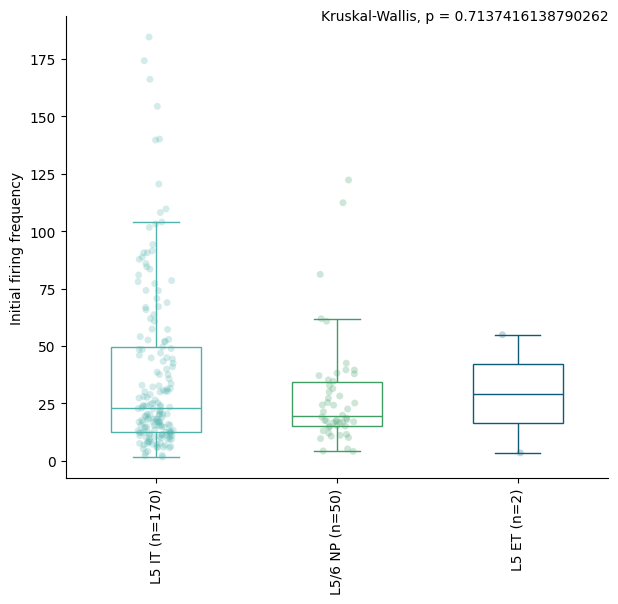

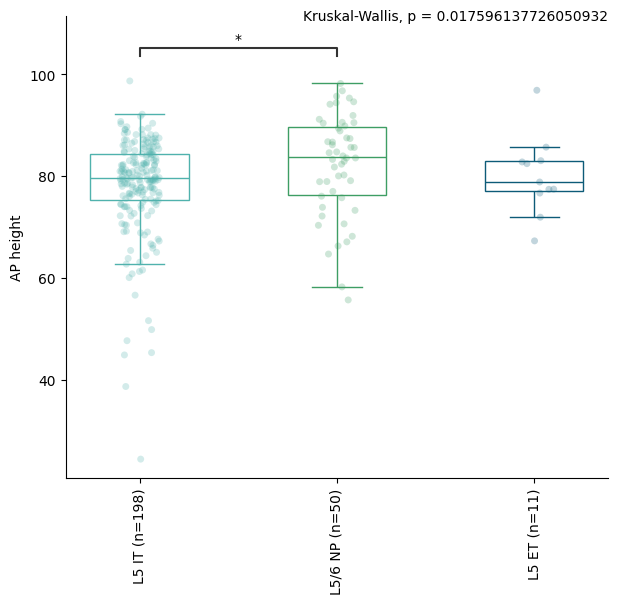

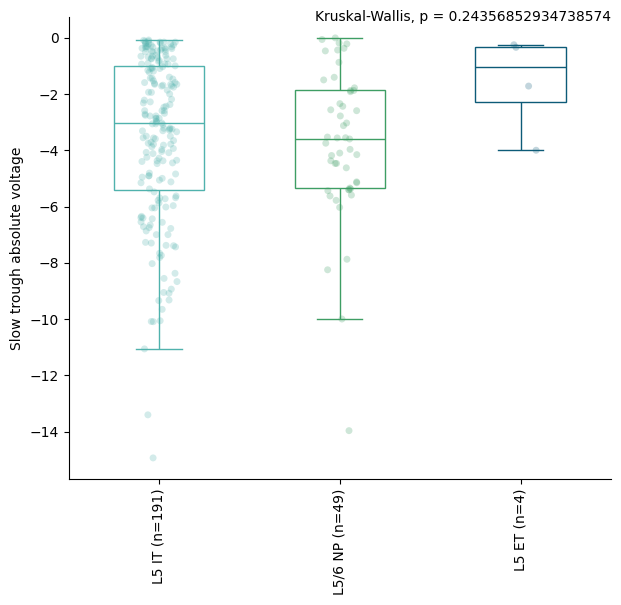

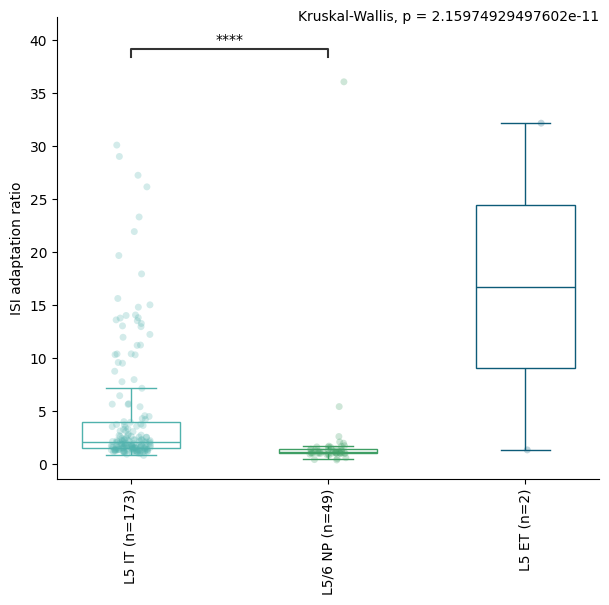

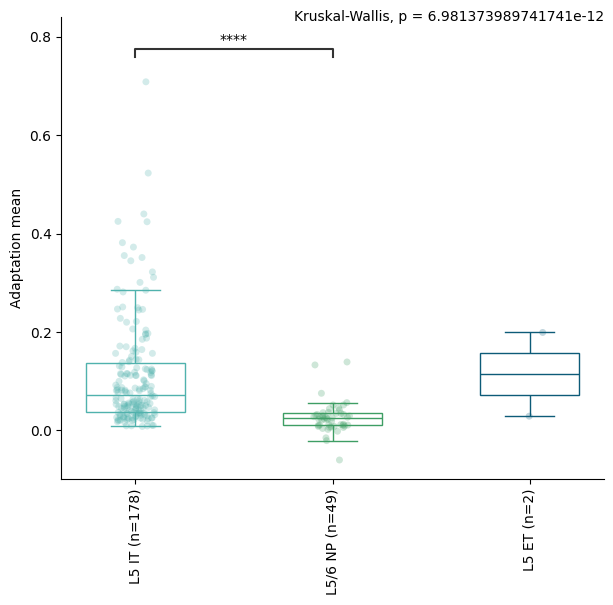

...

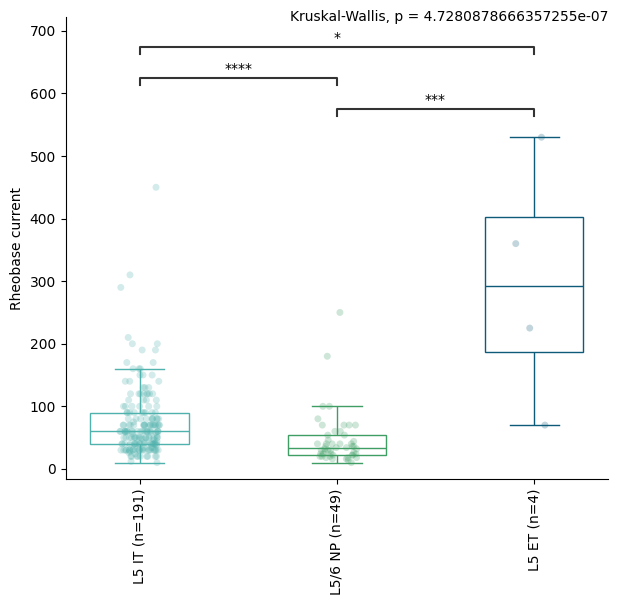

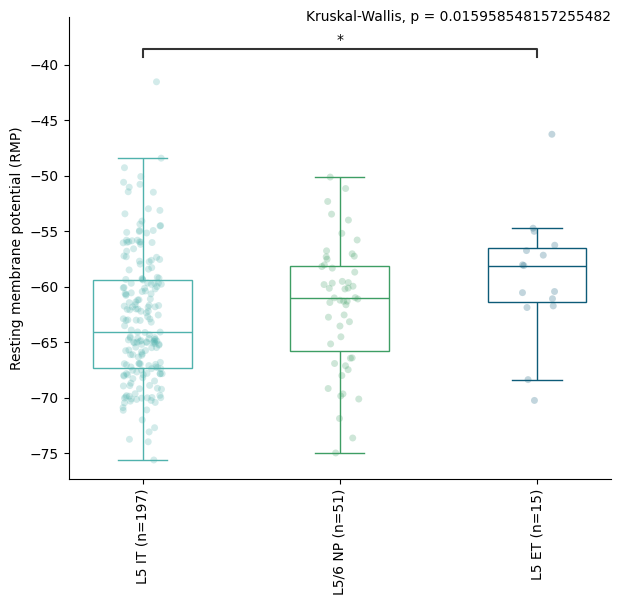

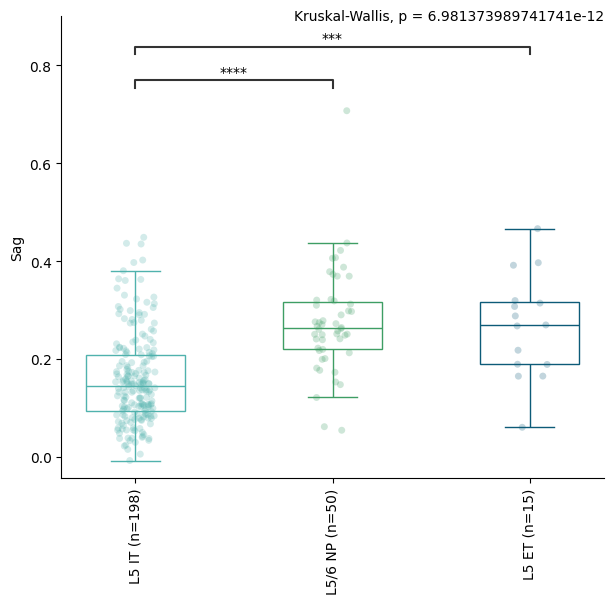

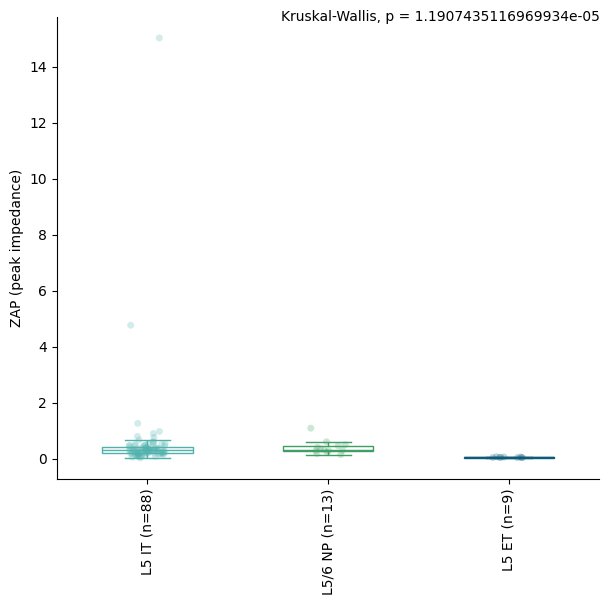

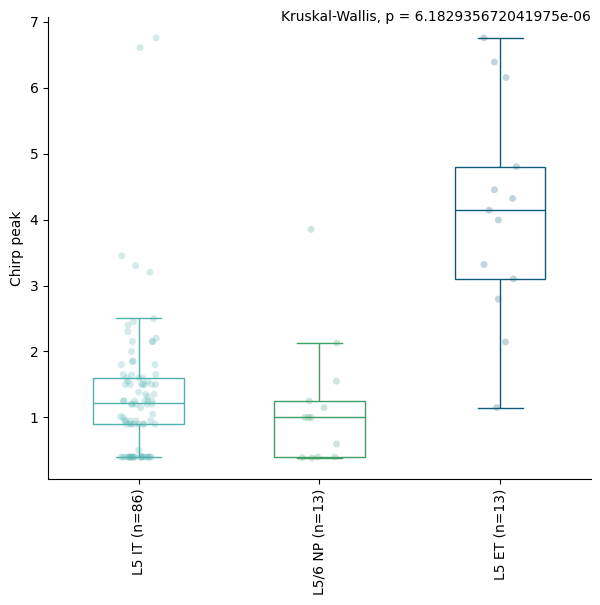

/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:4.816e-02
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:4.816e-02
L6 IT vs. L6b: Custom statistical test, P_val:4.816e-02


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:1.761e-03
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:2.813e-02
L6 IT vs. L6b: Custom statistical test, P_val:4.343e-03


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:1.490e-02
L6 IT vs. L6b: Custom statistical test, P_val:8.454e-03
L6 IT Car3 vs. L6b: Custom statistical test, P_val:2.500e-02


... (10 outputs left out)

/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:1.736e-02
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:1.040e-02


/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/4101657571.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

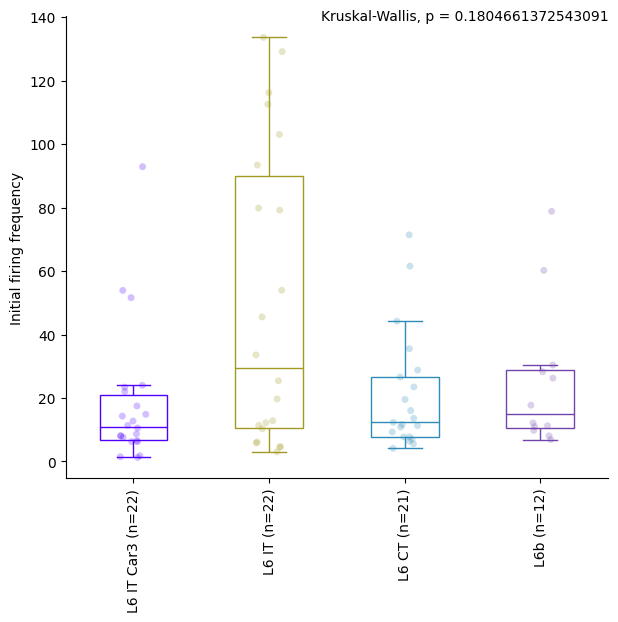

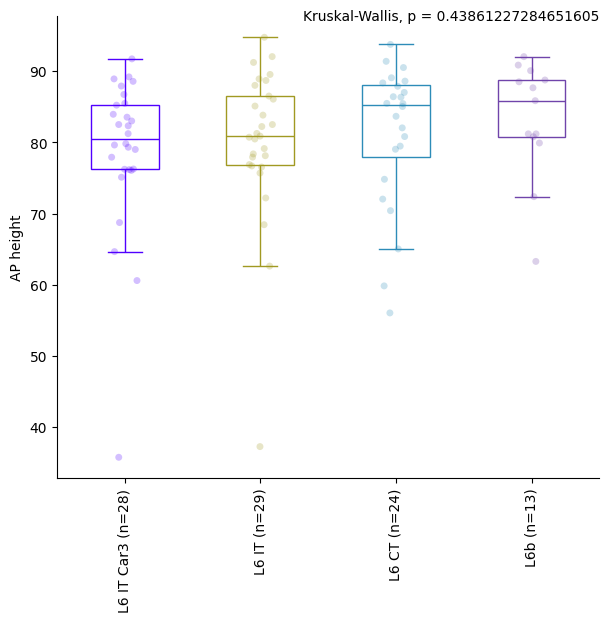

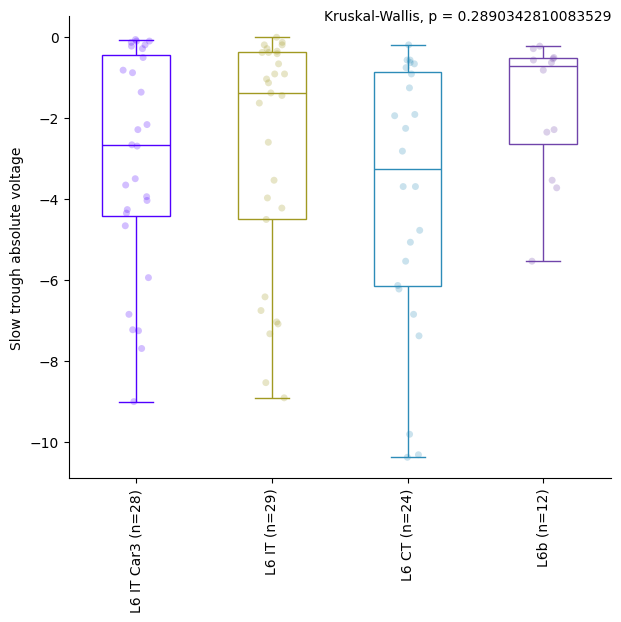

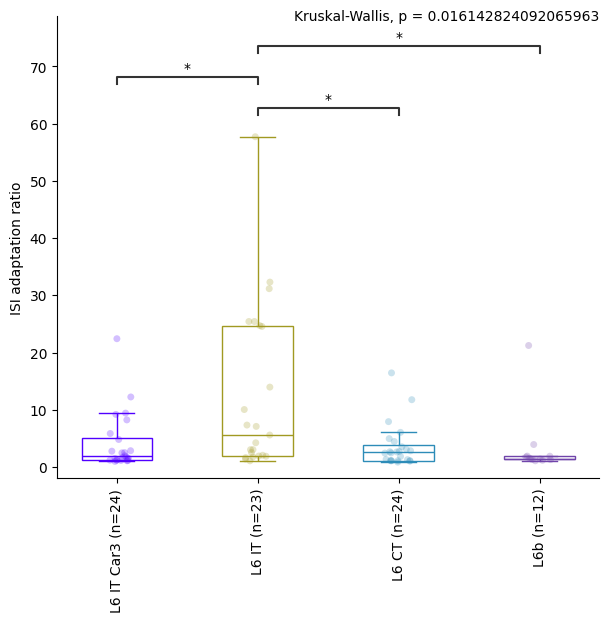

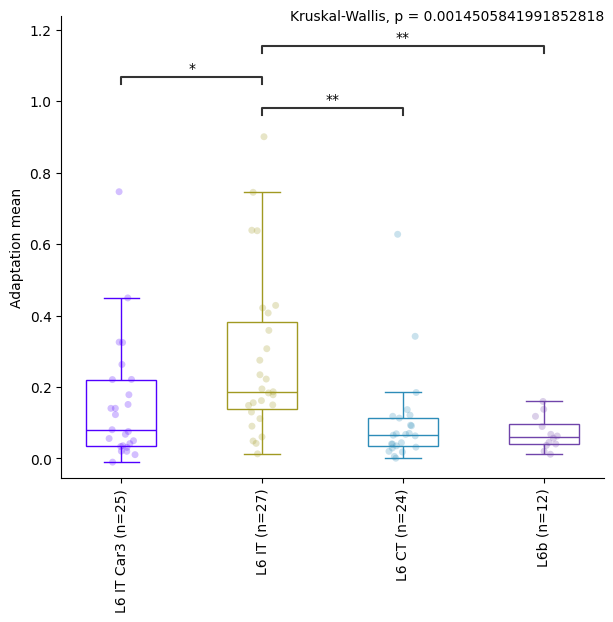

...

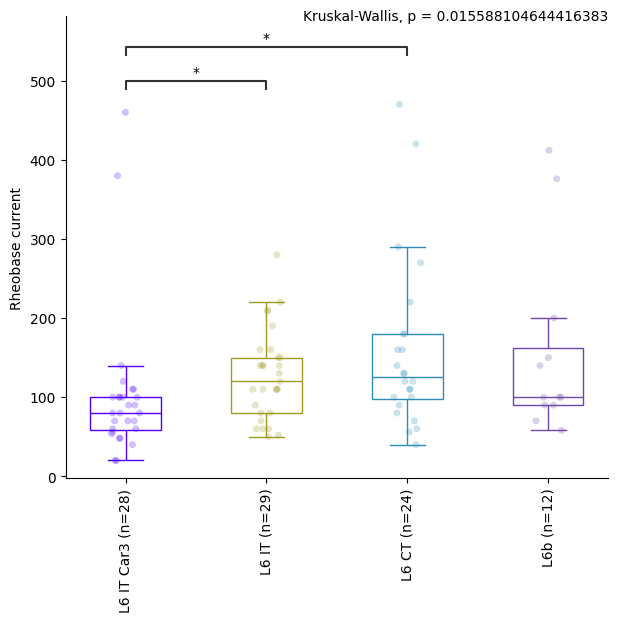

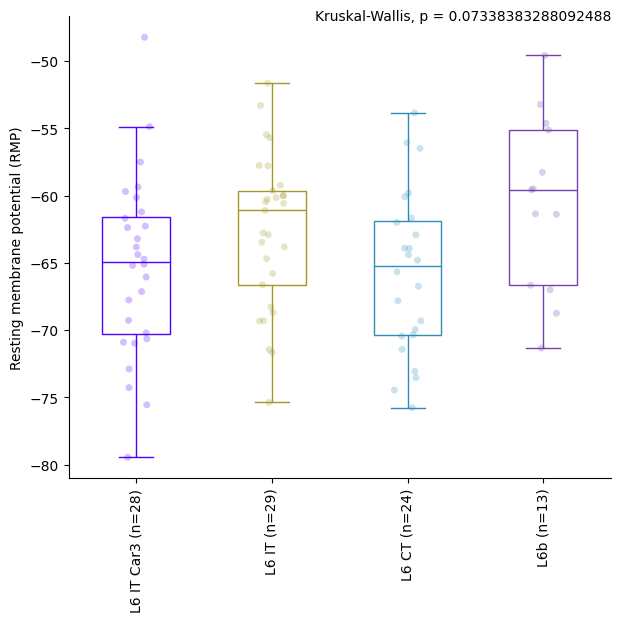

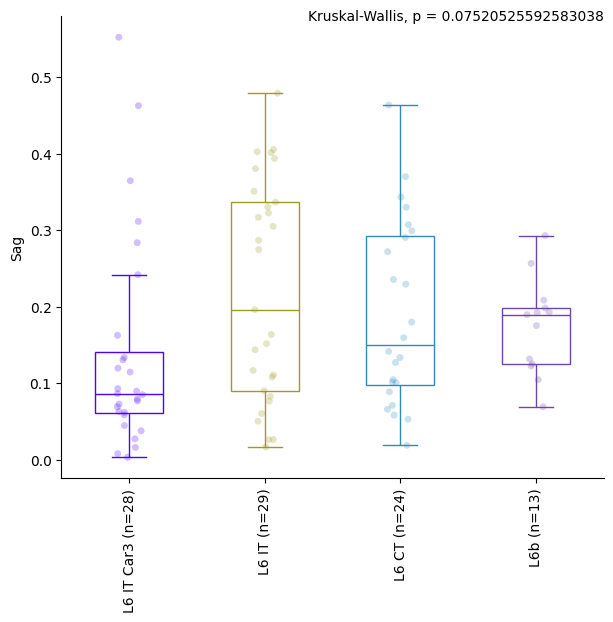

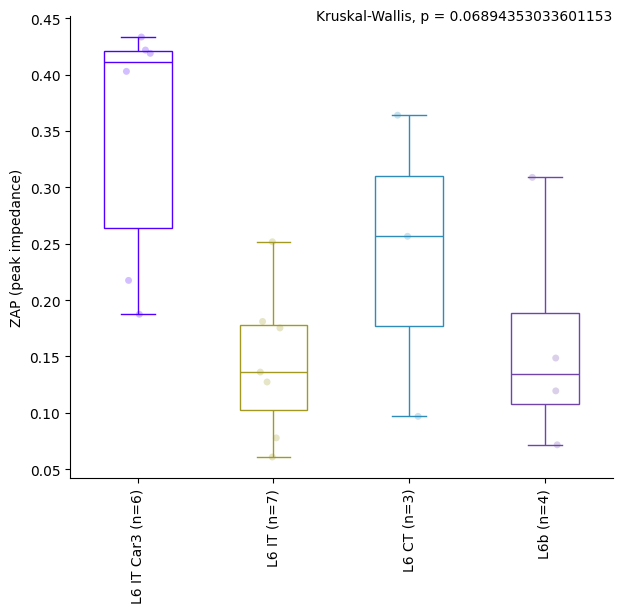

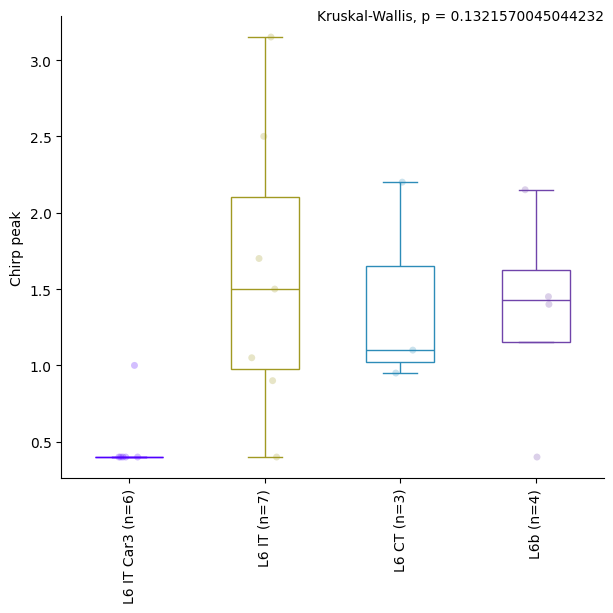

<Figure size 640x480 with 0 Axes>

In [17]:
# ttype x feature box plots

subclass_order = group_order['subclass_label']

for layer in kw_pvals_fdr_layer.keys():
    if kw_pvals_fdr_layer[layer]:
        #layer has results (there were enough ttypes in the layer, etc.)
        layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]
        kw_pvals_fdr = kw_pvals_fdr_layer[layer]  
        dunn_pvals_fdr = dunn_pvals_fdr_layer[layer]
        x_var = 'subclass_label'  # what to do box plots on
        x_var_order = [t for t in subclass_order if t in layer_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_{}_bySubclass.pdf'.format(layer.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 'subclass_label' #seperate strip plots into these categories 
        hue_color_palette = color_dicts[hue_var] #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        ephys_features = feature_cols.copy()

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while ephys_features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = ephys_features.pop()
                    
                    sns.stripplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(layer_data[(layer_data[x_var] == t) & (~layer_data[y_var].isna())])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=layer_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



T-Types within each Subclass x feature box plots with stats

In [18]:
#ttypes within each subclass

ttype_order = group_order['t_type']

# subclass x feature stats
subcalss_var = 'subclass_label' #what to do box plots on 
subclass_var_order = group_order['subclass_label']

kw_pvals_fdr_subclass = dict()
dunn_pvals_fdr_subclass = dict()
for subclass in subclass_var_order:
    print(subclass)
    subclass_data = sorted_clean_data.loc[sorted_clean_data[subcalss_var] == subclass]

    #now run stats on the ttypes in this subclass 
    x_var = 't_type'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in subclass_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in feature_cols:
        # Create a list of groups dynamically
        groups = [subclass_data.loc[subclass_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(subclass_data[subclass_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_subclass[subclass] = kw_pvals_fdr
    dunn_pvals_fdr_subclass[subclass] = dunn_pvals_fdr

L2/3 IT
L4 IT
L5 IT
L5/6 NP
L5 ET
Not enough groups with data for feature Rheobase current
Not enough groups with data for feature FI slope
Not enough groups with data for feature Latency
Not enough groups with data for feature Avg spike rate
Not enough groups with data for feature Mean ISI
Not enough groups with data for feature Adaptation mean
Not enough groups with data for feature ISI adaptation ratio
Not enough groups with data for feature Slow trough absolute voltage
Not enough groups with data for feature Initial firing frequency
L6 IT Car3
L6 IT
L6 CT
Not enough groups with data for feature Chirp peak
Not enough groups with data for feature ZAP (peak impedance)
L6b


In [19]:
# save stats

target_subclass = "L5 IT"

kw_results = kw_pvals_fdr_subclass[target_subclass]
dunn_results = dunn_pvals_fdr_subclass[target_subclass]

rows = []

for feature, kw_p_fdr in kw_results.items():

    if feature in dunn_results:
        dunn_matrix = dunn_results[feature]

        for i, group_1 in enumerate(dunn_matrix.index):
            for j, group_2 in enumerate(dunn_matrix.columns):
                # Keep each comparison once and omit the diagonal
                if j > i:
                    dunn_p_fdr = dunn_matrix.loc[group_1, group_2]

                    rows.append({
                        "subclass": target_subclass,
                        "feature": feature,
                        "KW_p_value_fdr": kw_p_fdr,
                        "KW_significant_fdr": kw_p_fdr < 0.05,
                        "t_type_1": group_1,
                        "t_type_2": group_2,
                        "Dunn_p_value_fdr": dunn_p_fdr,
                        "Dunn_significant_fdr": dunn_p_fdr < 0.05,
                    })
    else:
        # Retain features without a significant KW result
        rows.append({
            "subclass": target_subclass,
            "feature": feature,
            "KW_p_value_fdr": kw_p_fdr,
            "KW_significant_fdr": kw_p_fdr < 0.05,
            "t_type_1": None,
            "t_type_2": None,
            "Dunn_p_value_fdr": None,
            "Dunn_significant_fdr": None,
        })

l5_it_stats = pd.DataFrame(rows).sort_values(
    ["KW_p_value_fdr", "feature", "Dunn_p_value_fdr"],
    na_position="last",
)


fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_{}_byTtype.csv'.format(target_subclass.replace('/', '-').replace(' ', '_'))
fig_path = os.path.join(output_dir, fig_name)
l5_it_stats.to_csv(
    fig_path, 
    index=False,
)

In [20]:
fig_path

'/root/capsule/scratch/20260807/ephys/human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_L5_IT_byTtype.csv'

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:1.379e-02
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:2.254e-03
L2 IT_6 vs. L3 IT_12: Custom statistical test, P_val:3.247e-02
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:6.301e-04
L2 IT_1 vs. L3 IT_5: Custom statistical test, P_val:1.290e-05
L2 IT_6 vs. L3 IT_5: Custom statistical test, P_val:8.487e-04


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:1.451e-02
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:1.451e-02


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:2.661e-03
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:1.566e-04
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:3.305e-02
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:2.961e-02
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:1.510e-05
L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:6.986e-04
L2 IT_1 vs. L3 IT_10: Custom statistical test, P_val:1.107e-02
L2 IT_6 vs. L3 IT_12: Custom statistical test, P_val:2.968e-02
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:1.382e-05
L2 IT_1 vs. L3 IT_13: Custom statistical test, P_val:6.415e-05
L2 IT_1 vs. L3 IT_5: Custom statistical test, P_val:1.425e-07
L2 IT_6 vs. L3 IT_5: Custom statistical test, P_val:6.581e-03


... (24 outputs left out)

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:4.702e-02
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:8.564e-03
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:6.967e-04
L3 IT_12 vs. L3 IT_5: Custom statistical test, P_val:3.551e-02
L3 IT_8 vs. L3 IT_13: Custom statistical test, P_val:9.228e-03
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:8.048e-05
L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:9.935e-10
L3 IT_8 vs. L3 IT_5: Custom statistical test, P_val:2.127e-02
L2 IT_1 vs. L3 IT_10: Custom statistical test, P_val:1.462e-08
L2 IT_6 vs. L3 IT_12: Custom statistical test, P_val:4.311e-03
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:2.731e-08
L2 IT_6 vs. L3 IT_10: Custom statistical test, P_val:5.632e-06
L2 IT_1 vs. L3 IT_13: Custom statistical test, P_val:

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:4.014e-02
L2 IT_1 vs. L3 IT_13: Custom statistical test, P_val:2.084e-03
L2 IT_6 vs. L3 IT_13: Custom statistical test, P_val:1.025e-02


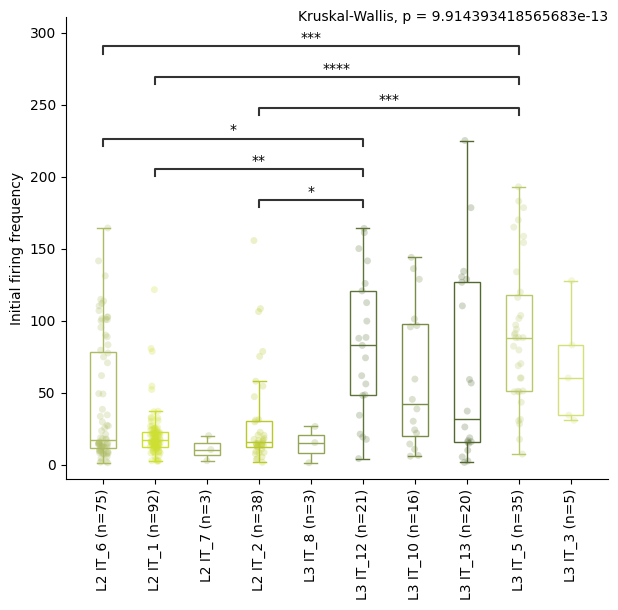

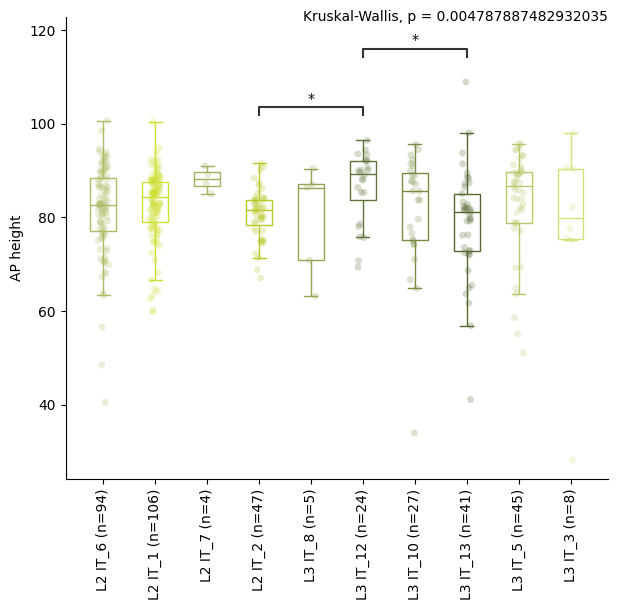

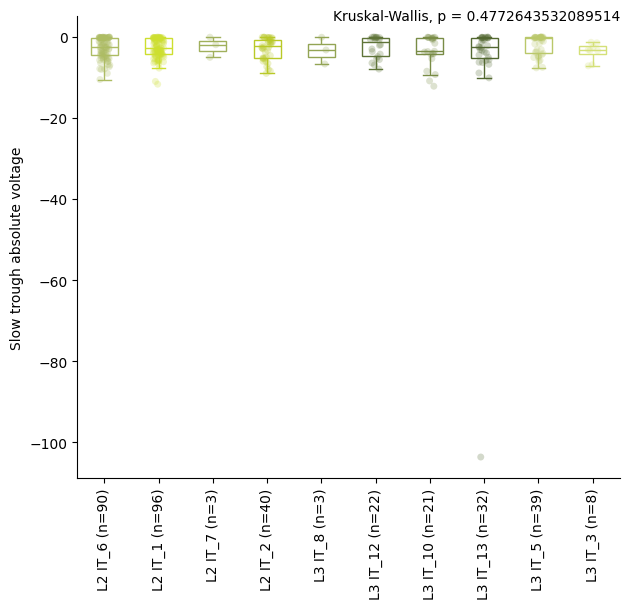

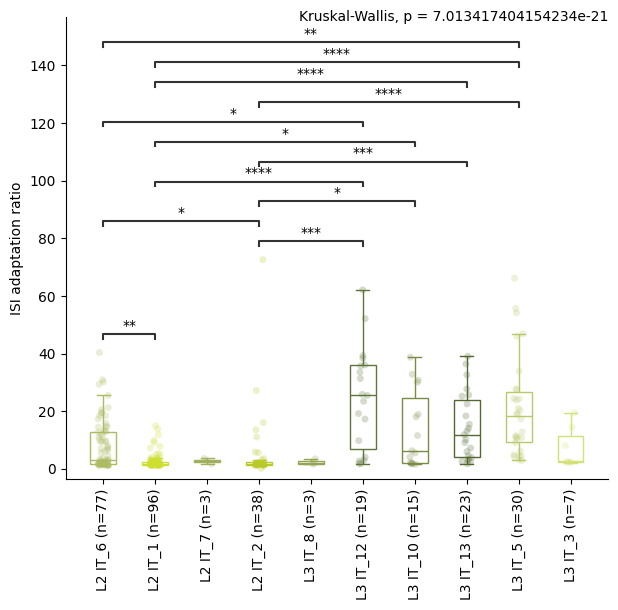

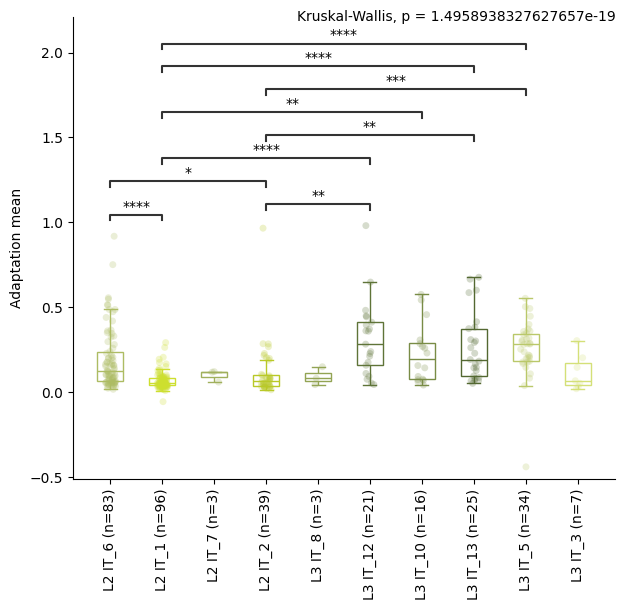

...

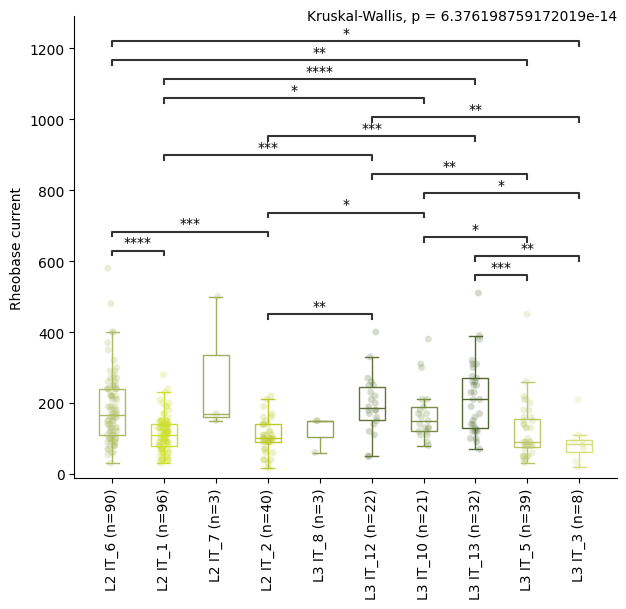

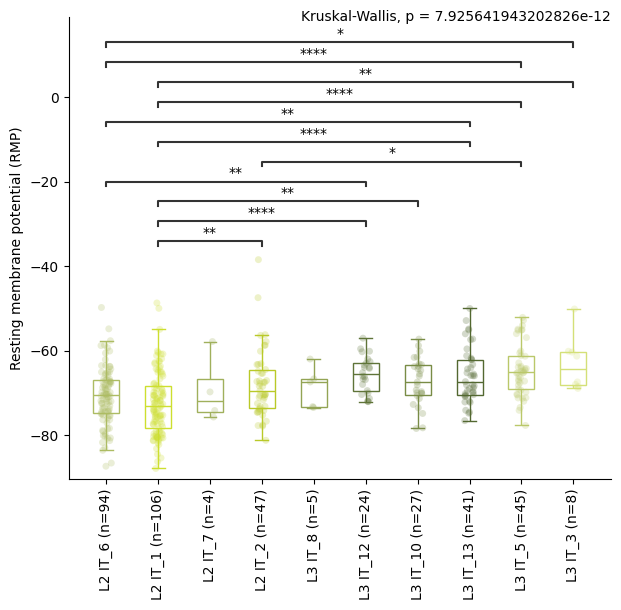

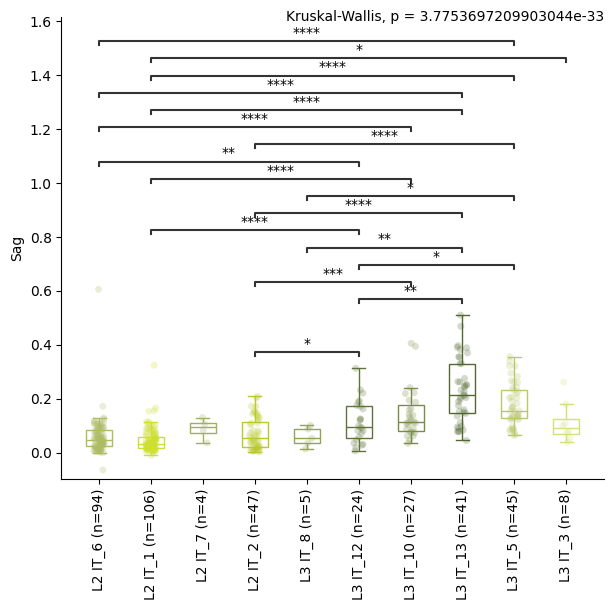

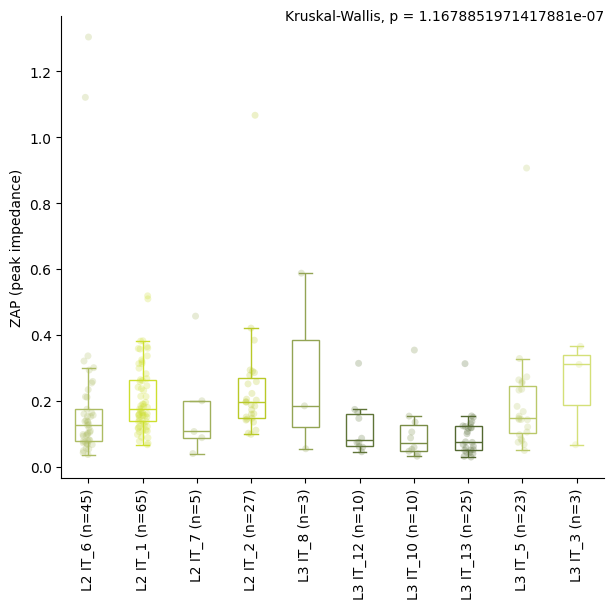

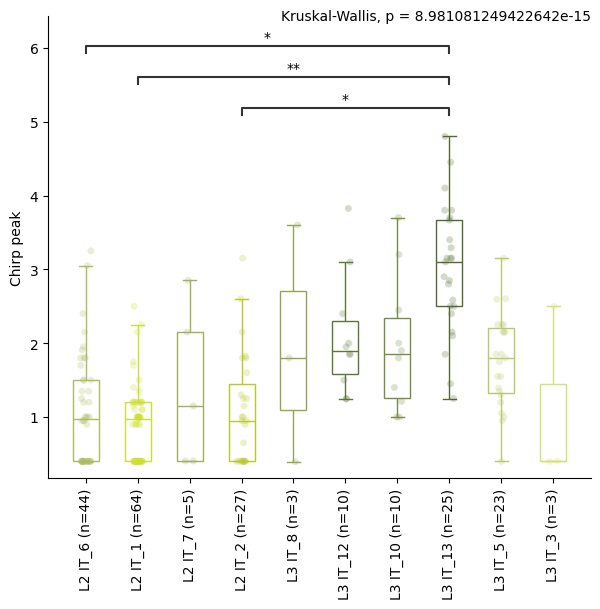

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:3.971e-12
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:2.050e-12
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:5.131e-04
L4 IT_3 vs. L4 IT_1: Custom statistical test, P_val:1.228e-04


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.041e-03
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.016e-08
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.988e-02


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.791e-07
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.971e-03


... (28 outputs left out)

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.836e-08
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.586e-02
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:1.187e-03
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:4.357e-02
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:6.828e-12


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

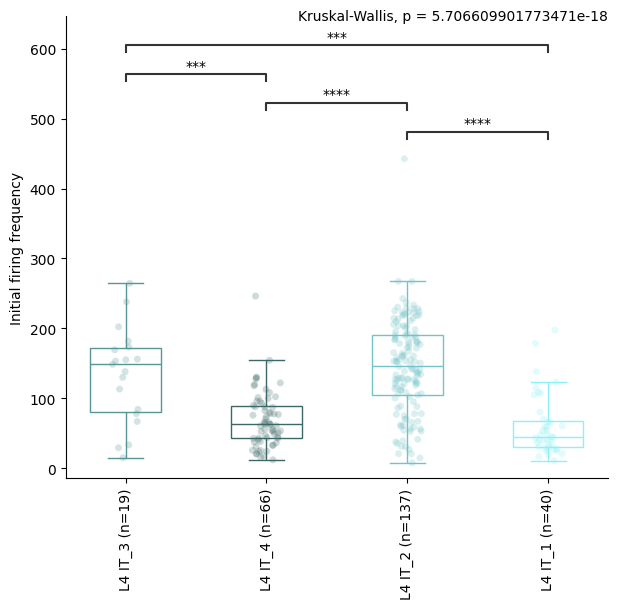

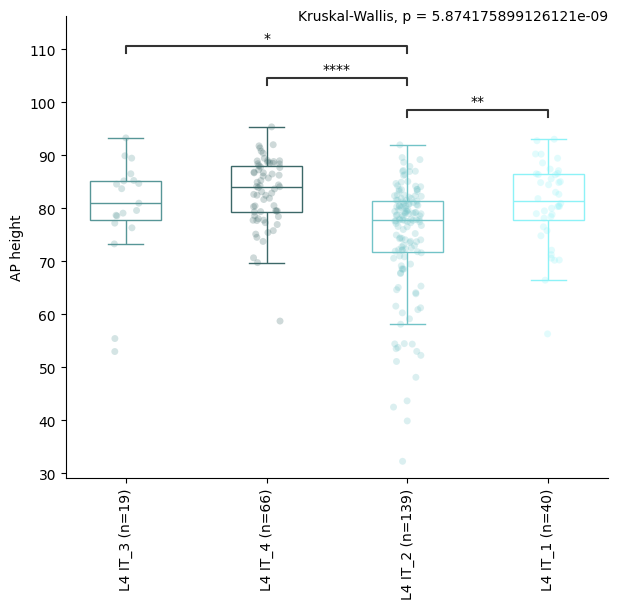

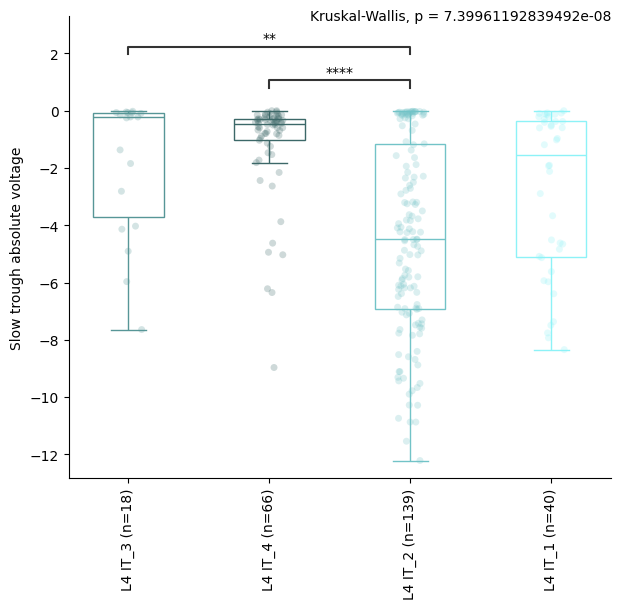

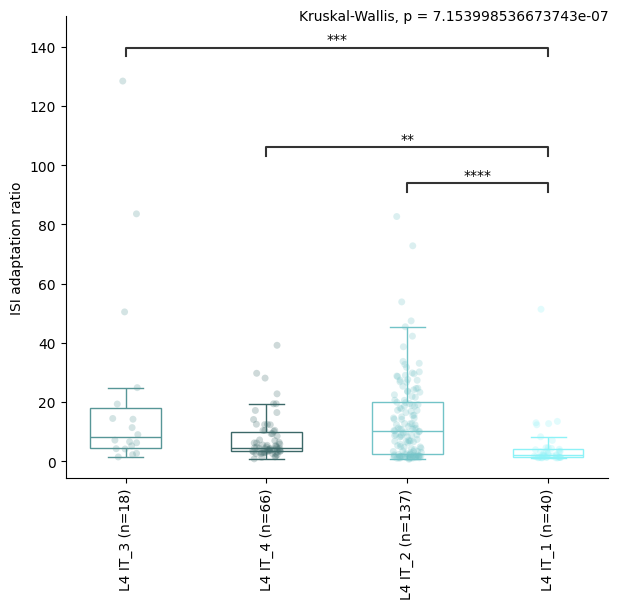

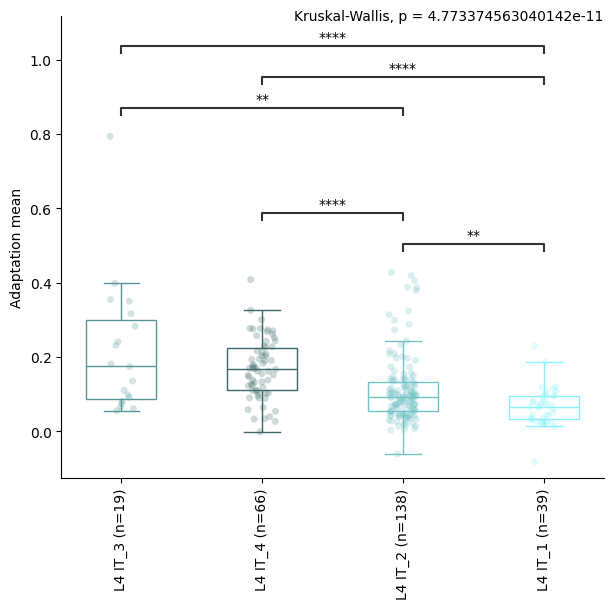

...

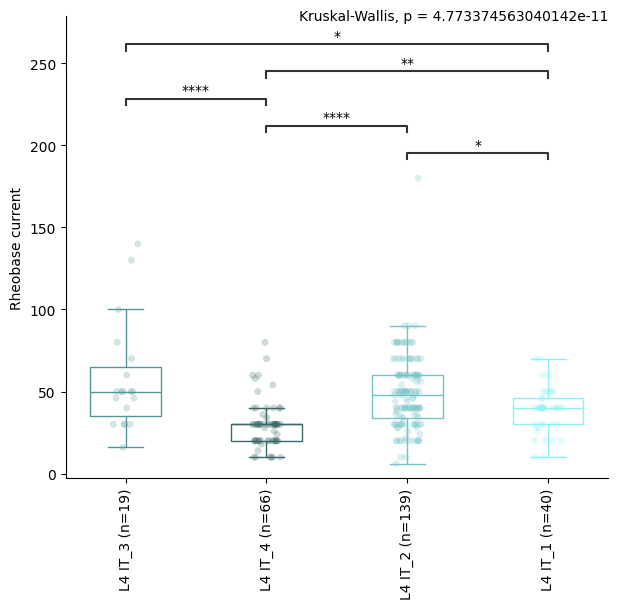

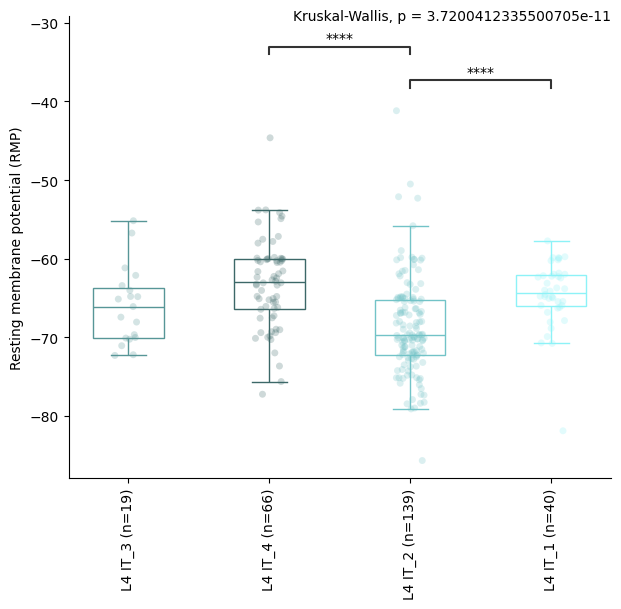

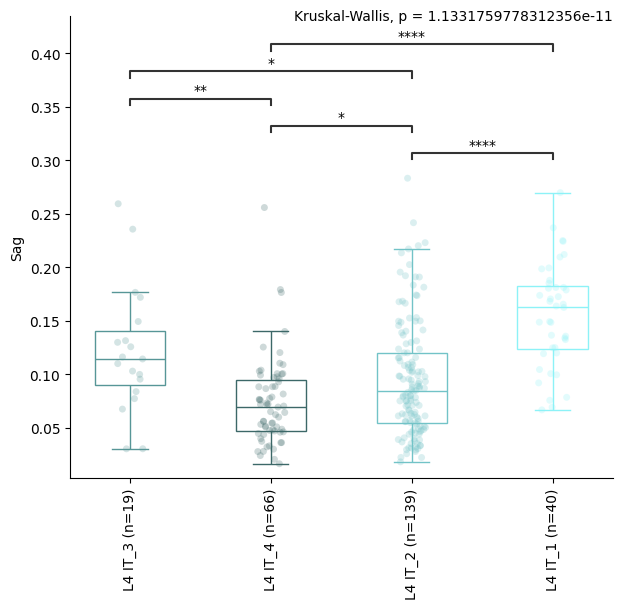

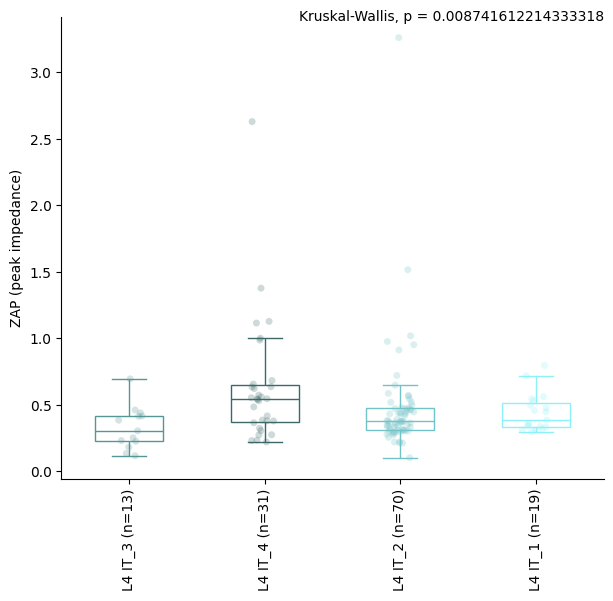

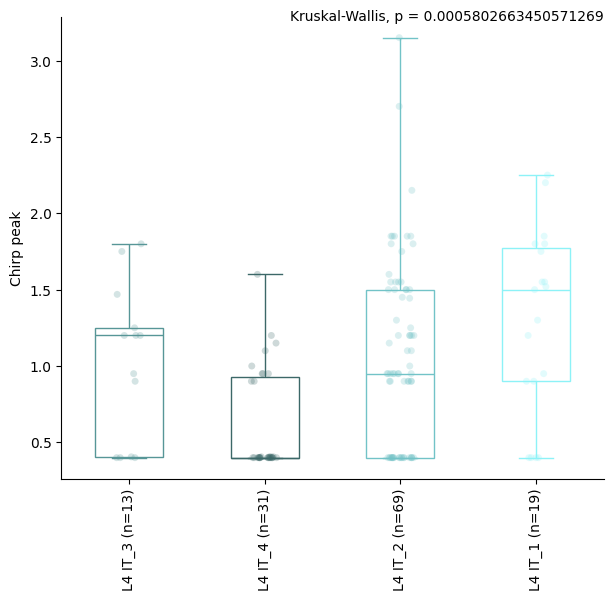

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:1.706e-02
L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:3.210e-03
L5 IT_5 vs. L5 IT_1: Custom statistical test, P_val:3.346e-03
L5 IT_6 vs. L5 IT_1: Custom statistical test, P_val:3.346e-03


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:2.585e-03
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:7.220e-03


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:9.078e-03
L5 IT_5 vs. L5 IT_2: Custom statistical test, P_val:1.838e-03
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:1.168e-06
L5 IT_2 vs. L5 IT_7: Custom statistical test, P_val:1.290e-02


... (20 outputs left out)

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:3.064e-02
L5 IT_2 vs. L5 IT_7: Custom statistical test, P_val:3.064e-02


/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

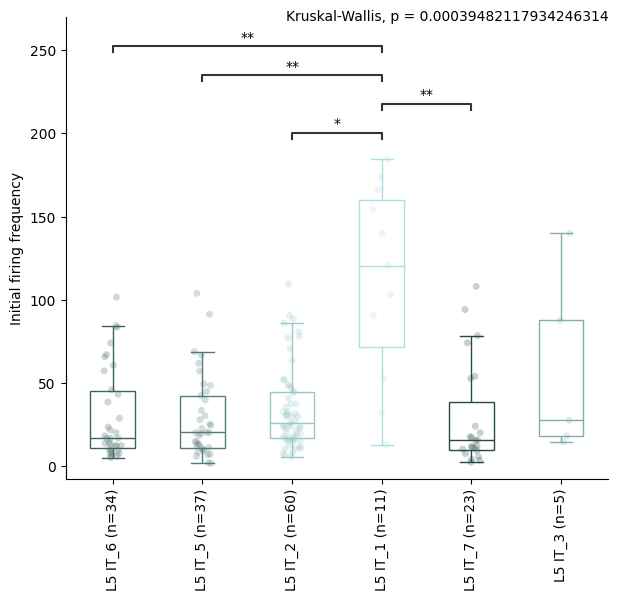

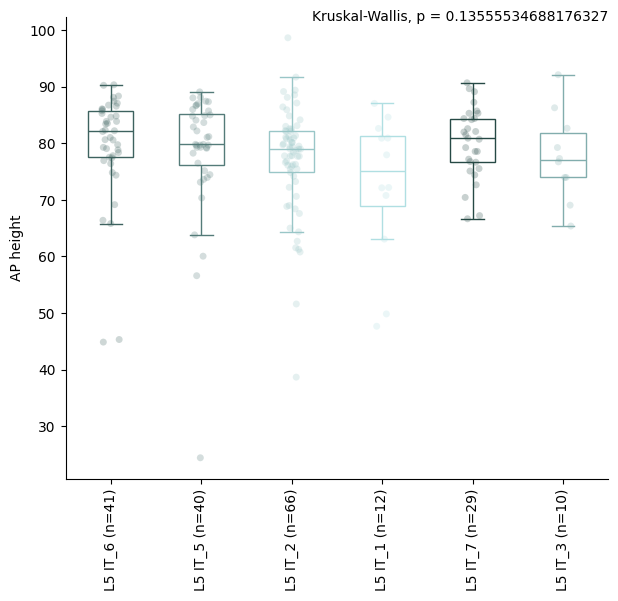

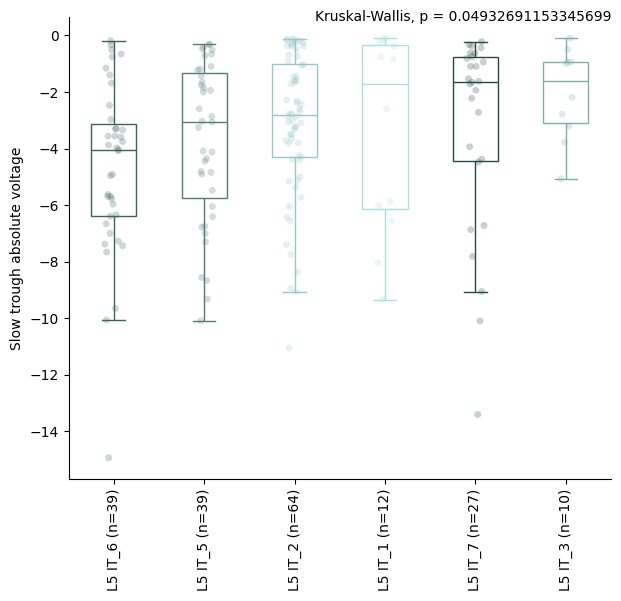

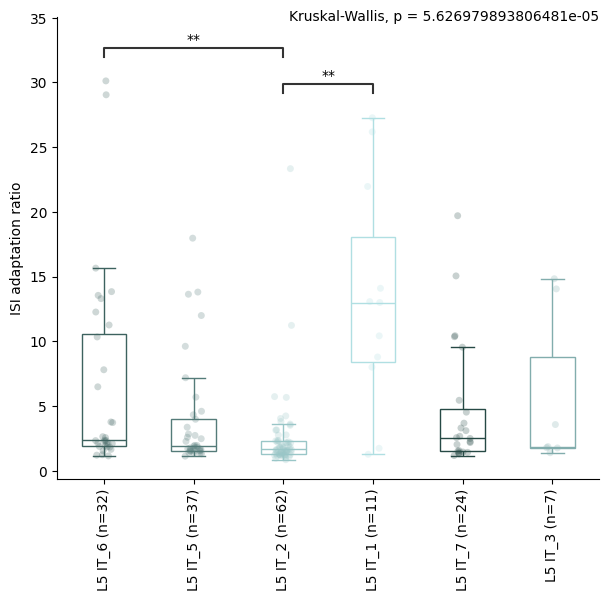

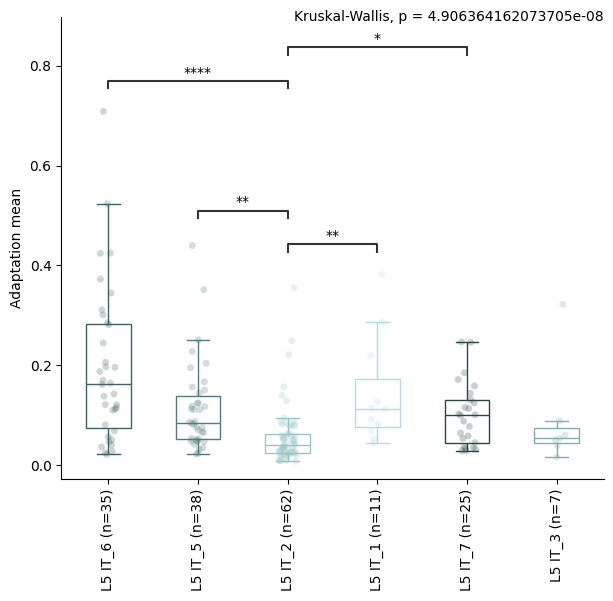

...

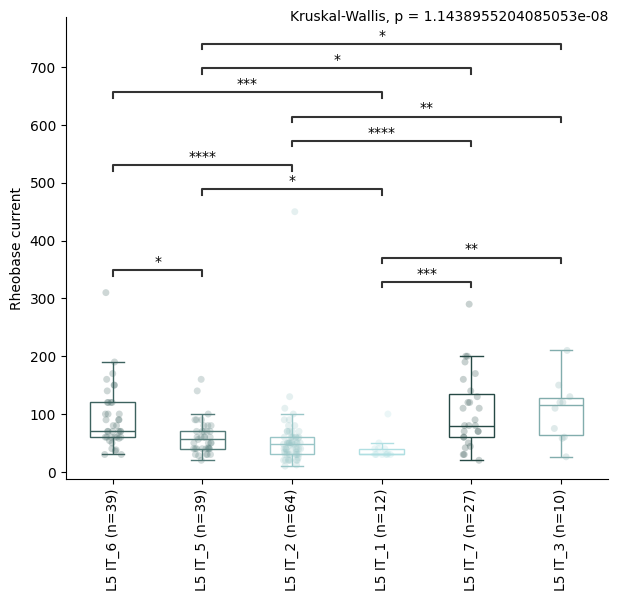

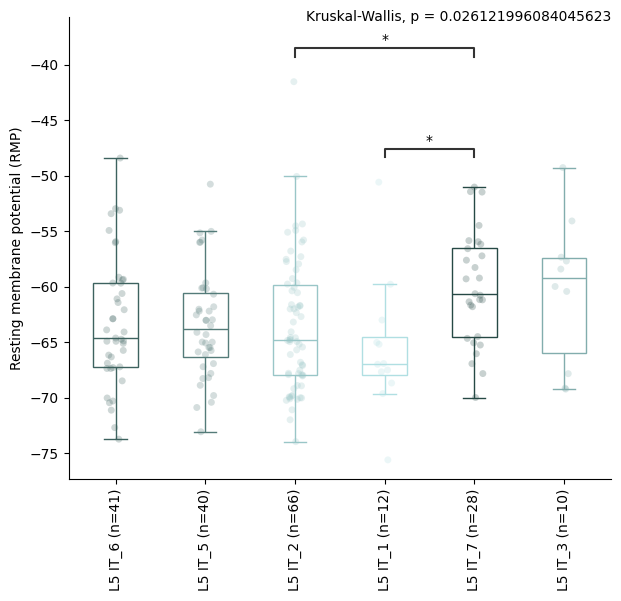

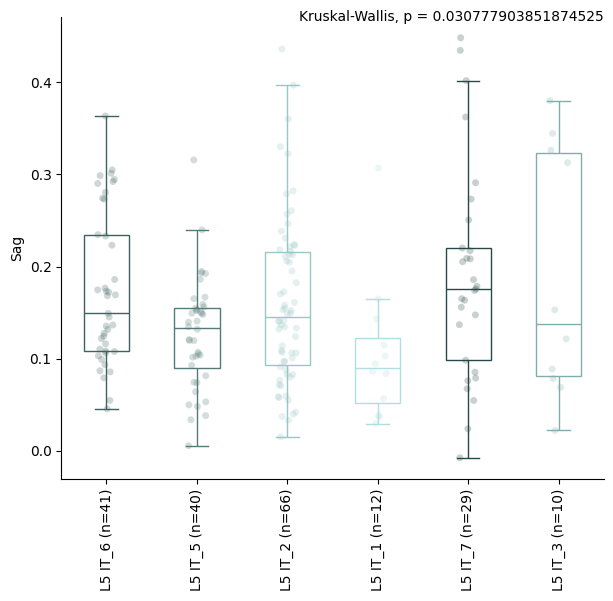

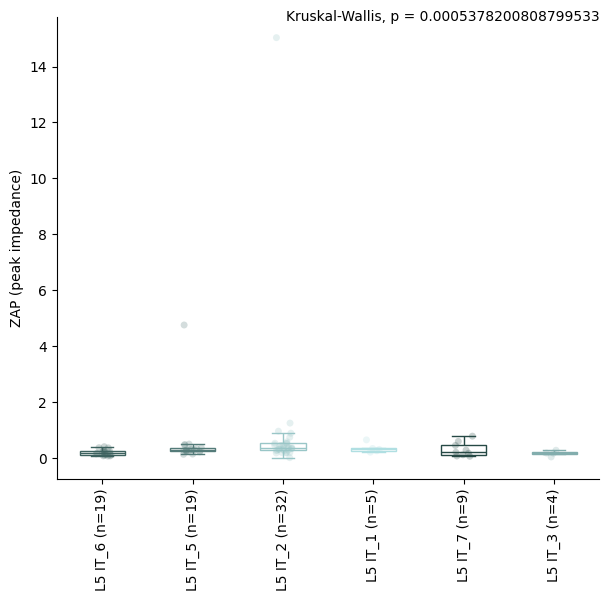

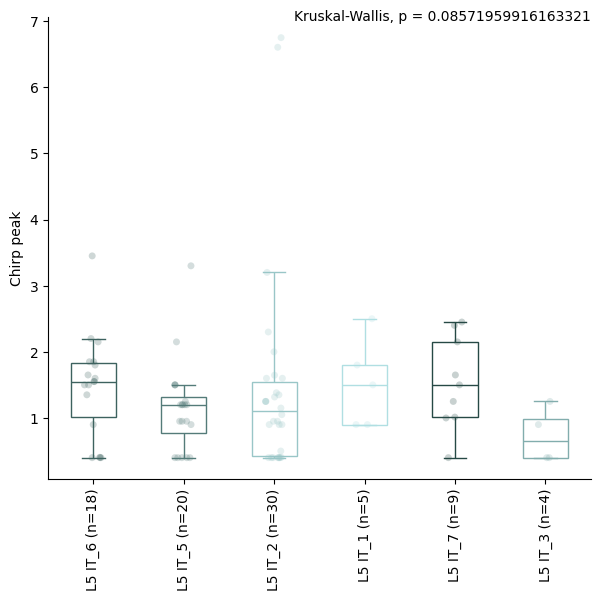

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.

<Figure size 640x480 with 0 Axes>

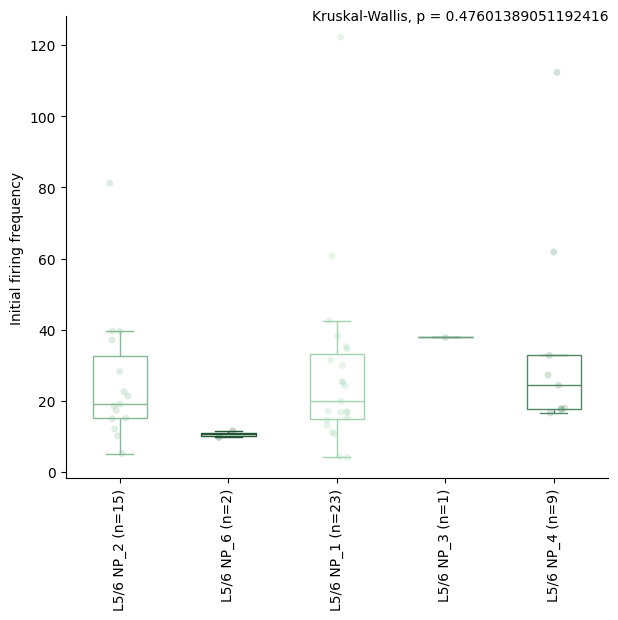

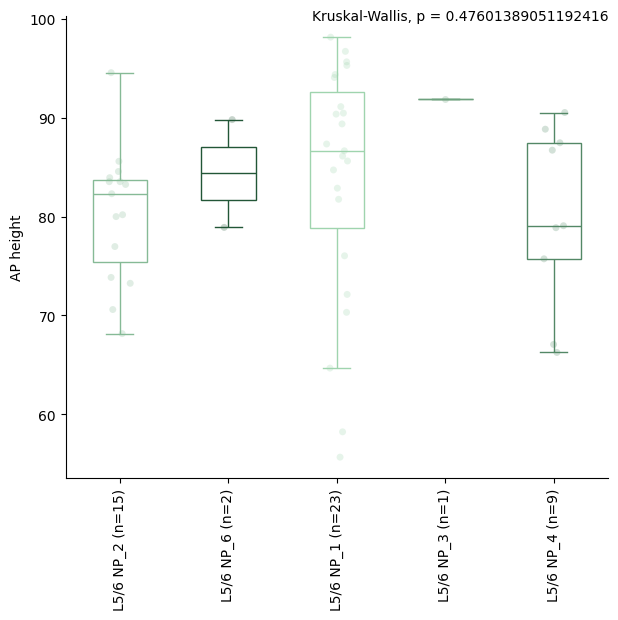

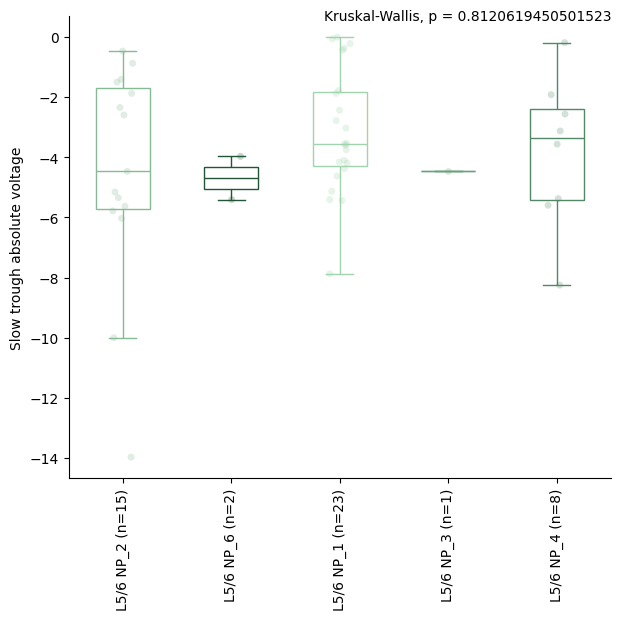

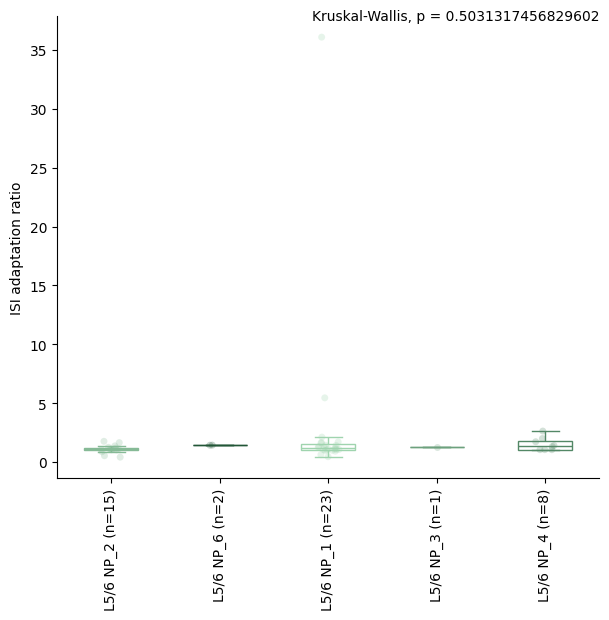

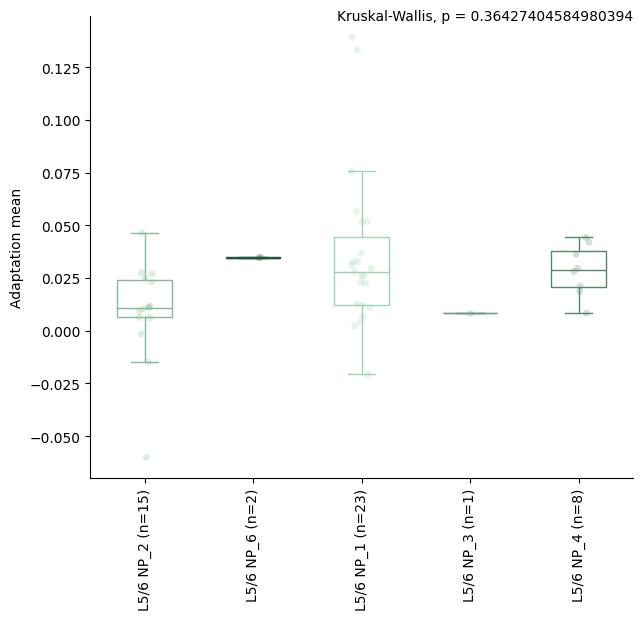

...

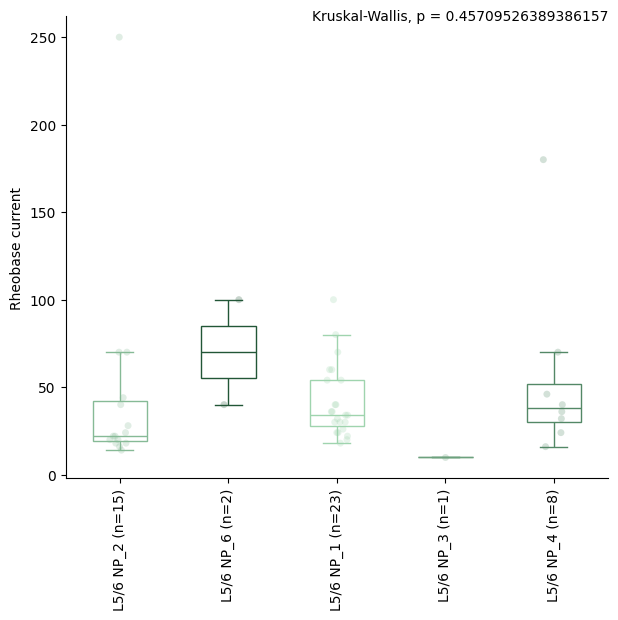

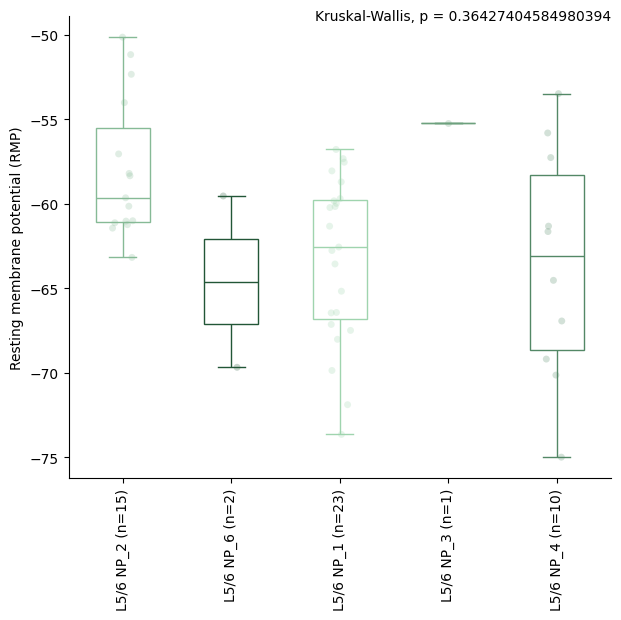

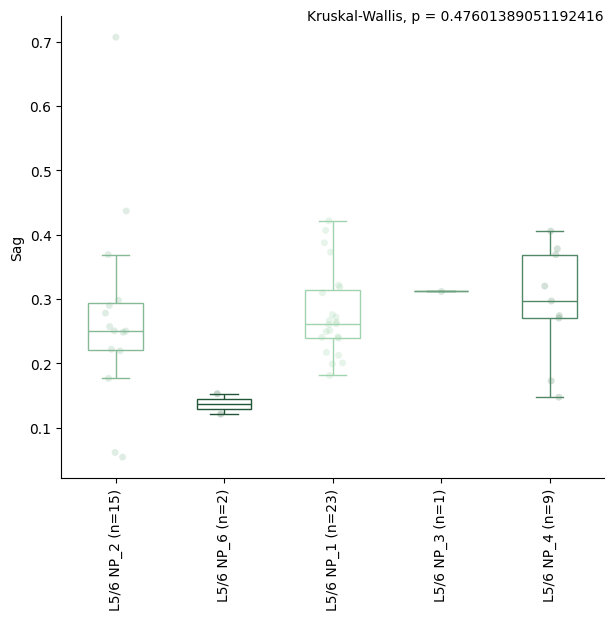

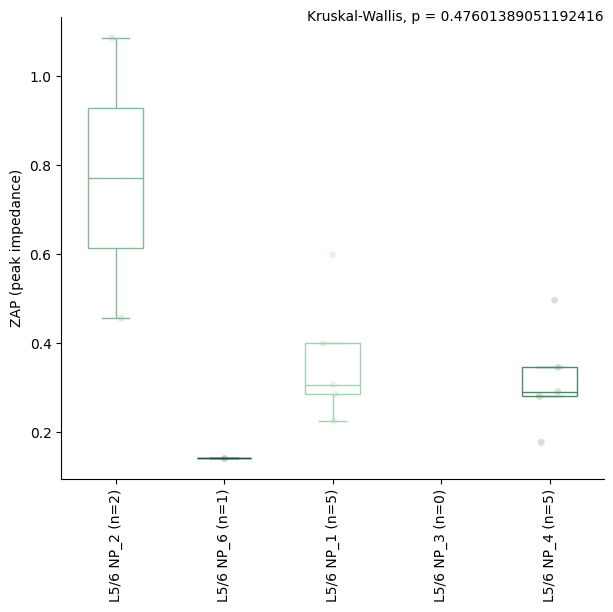

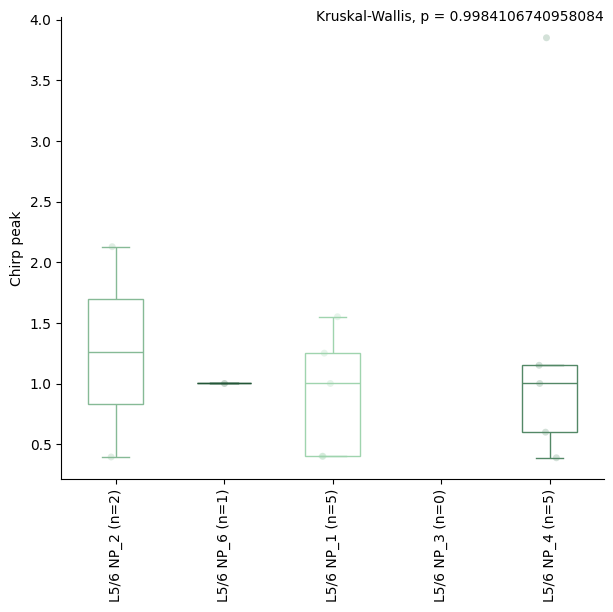

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.

<Figure size 640x480 with 0 Axes>

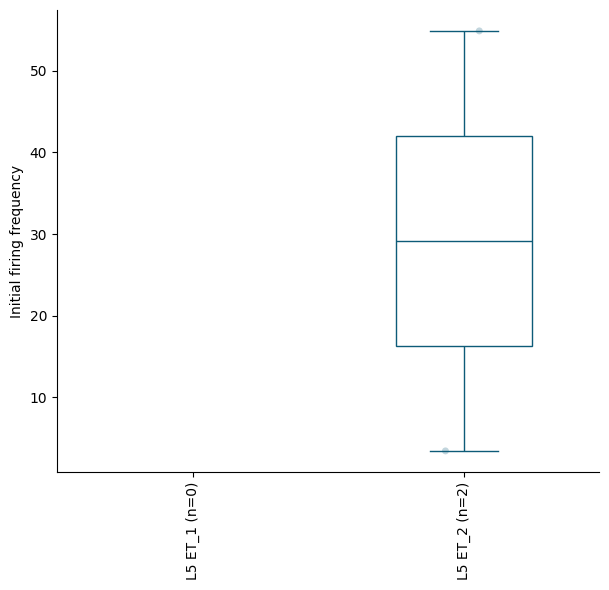

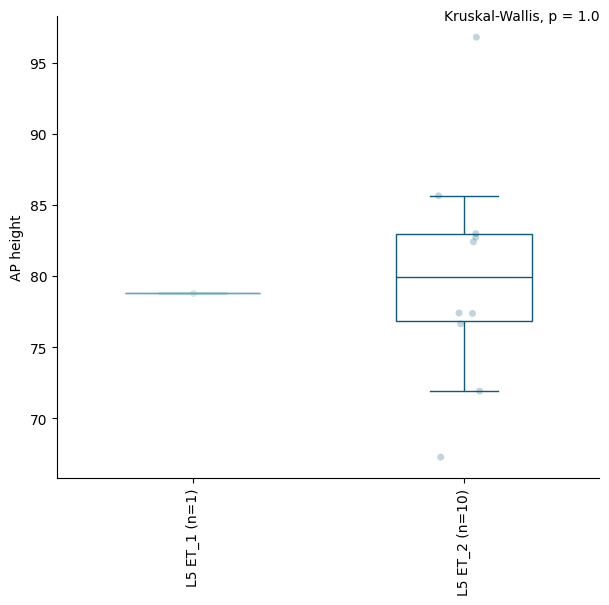

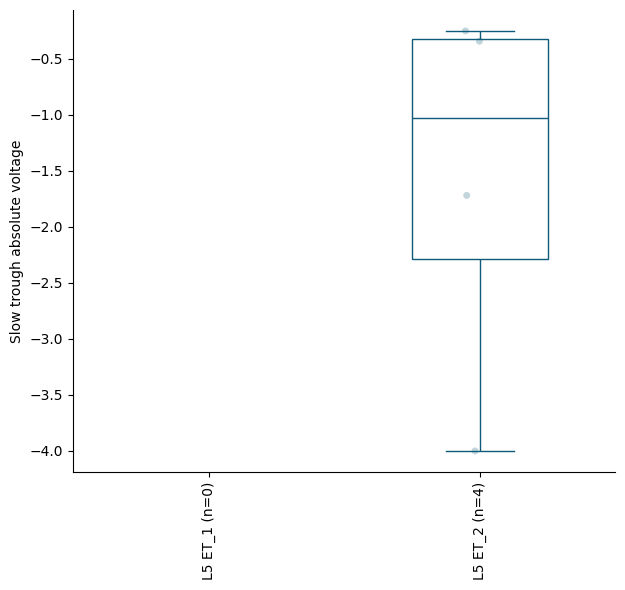

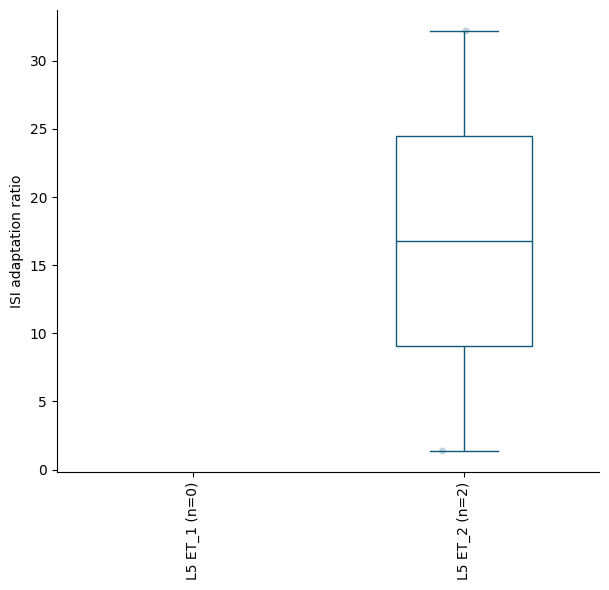

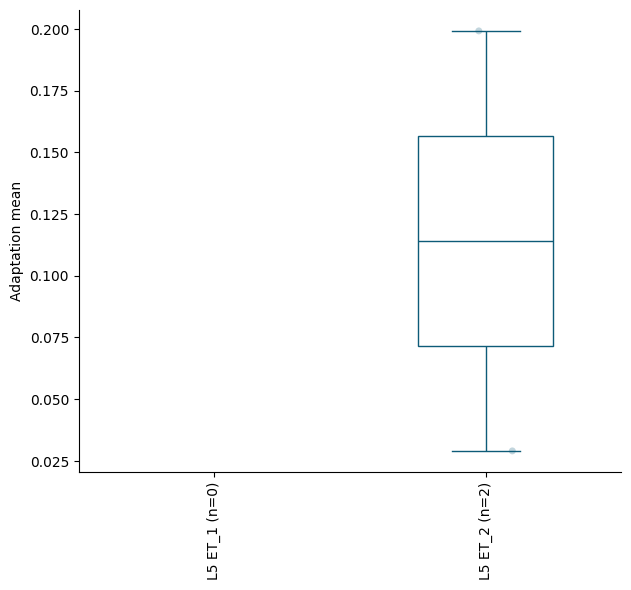

...

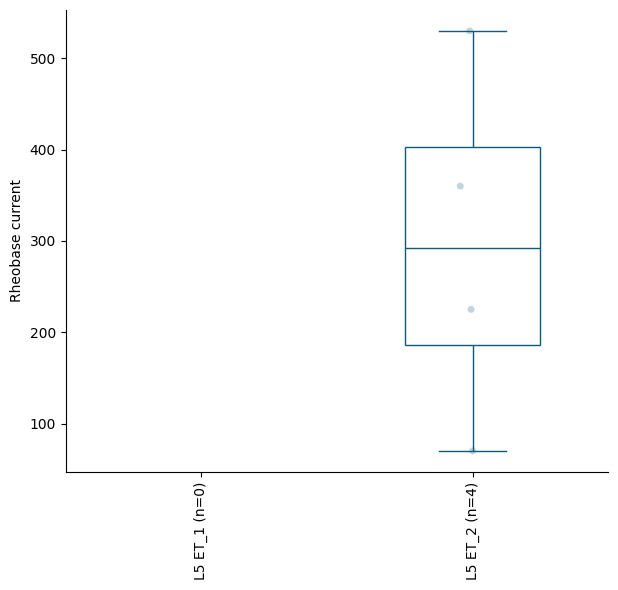

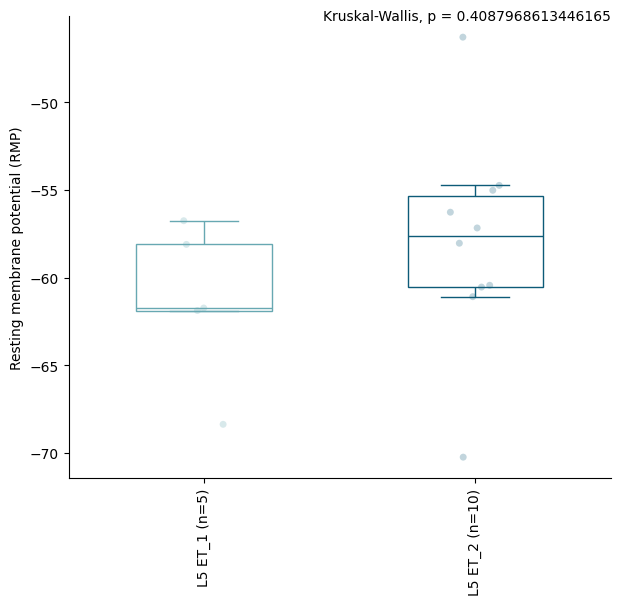

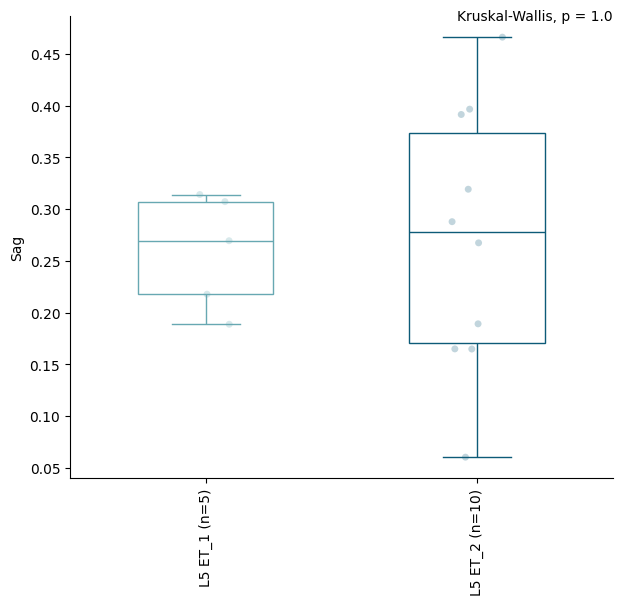

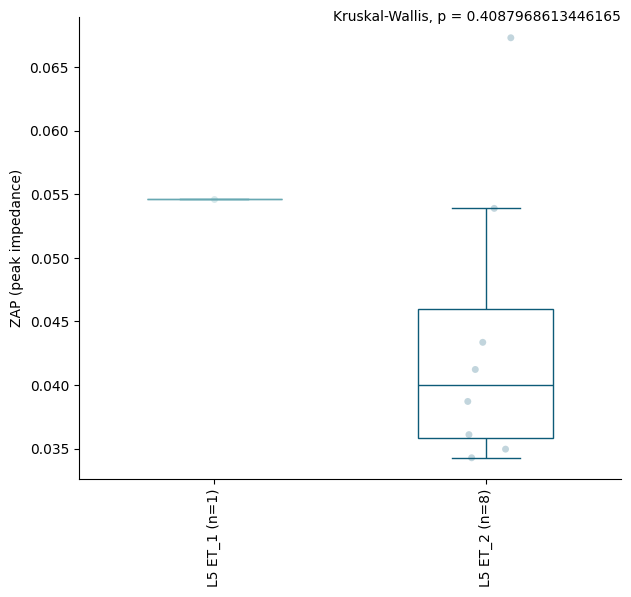

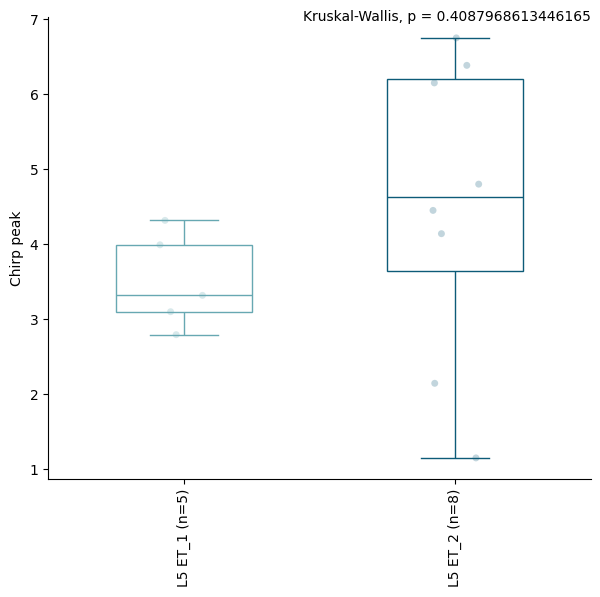

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.

<Figure size 640x480 with 0 Axes>

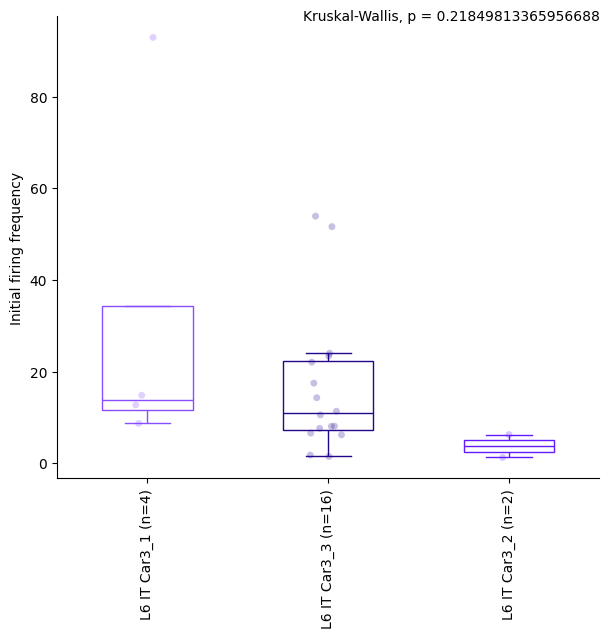

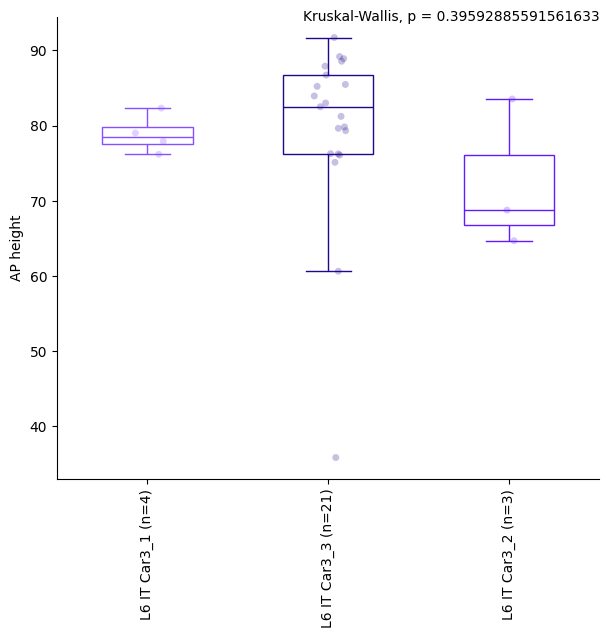

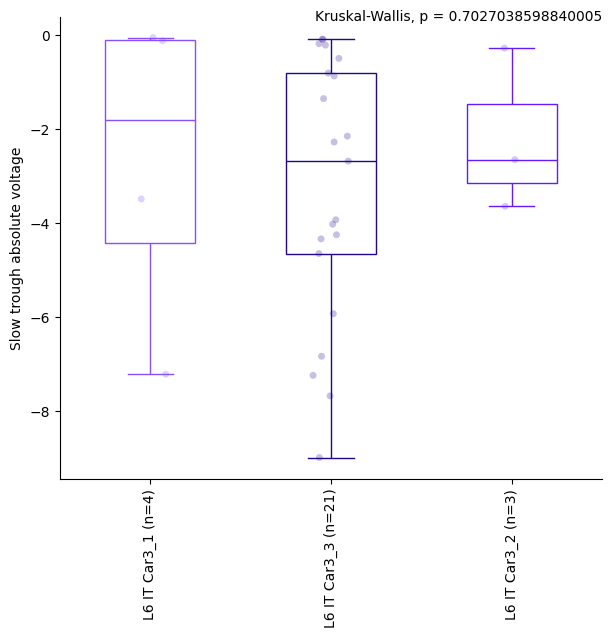

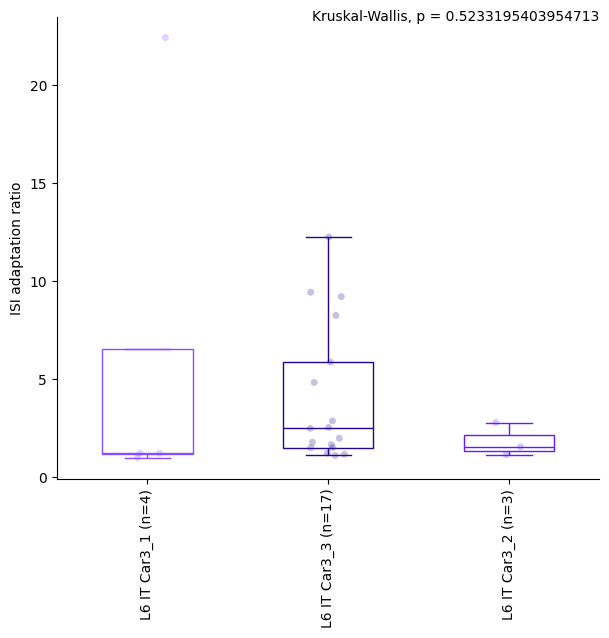

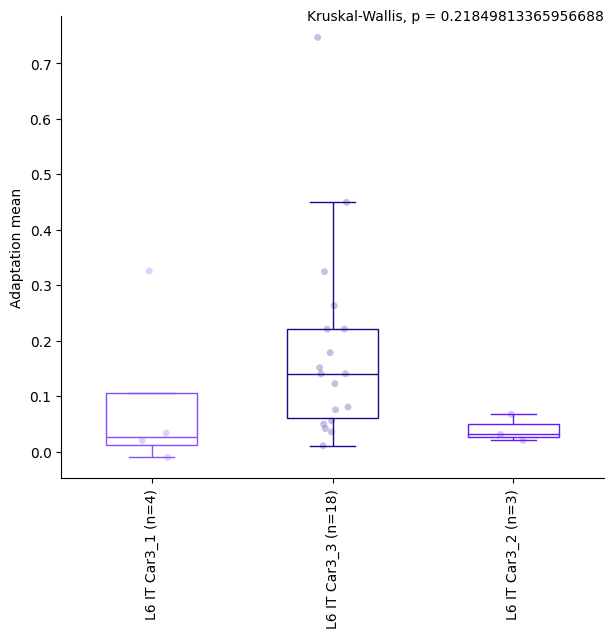

...

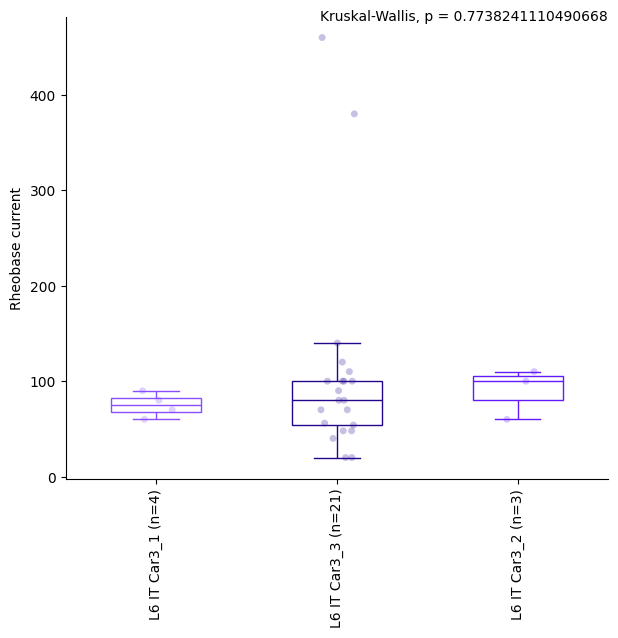

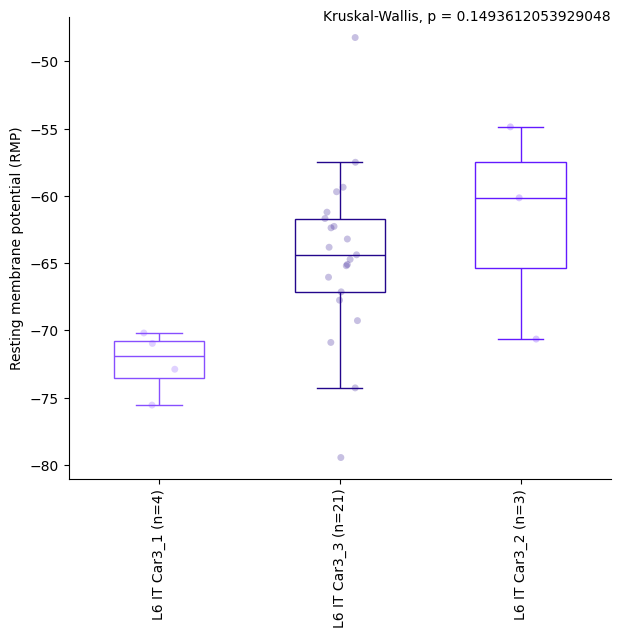

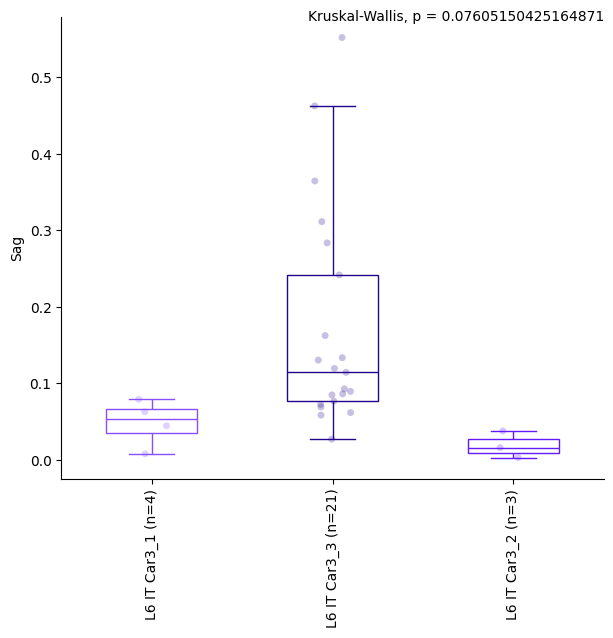

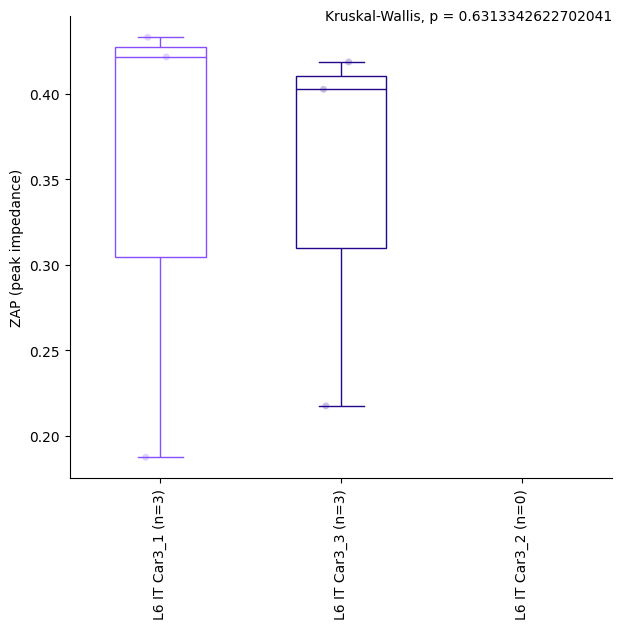

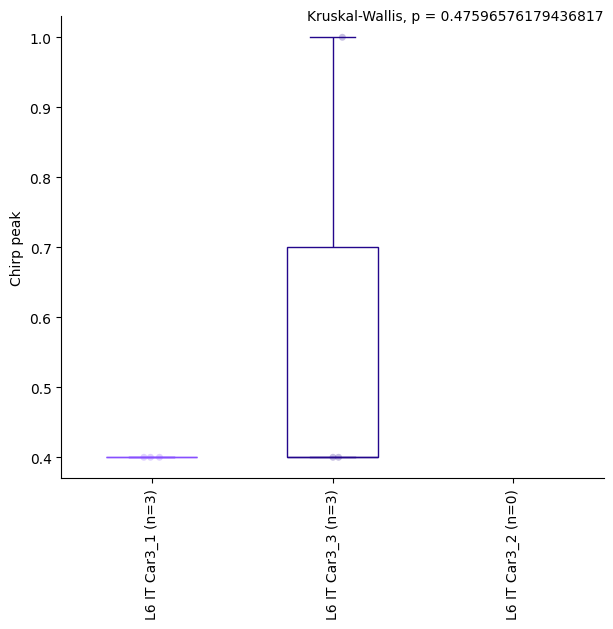

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.

<Figure size 640x480 with 0 Axes>

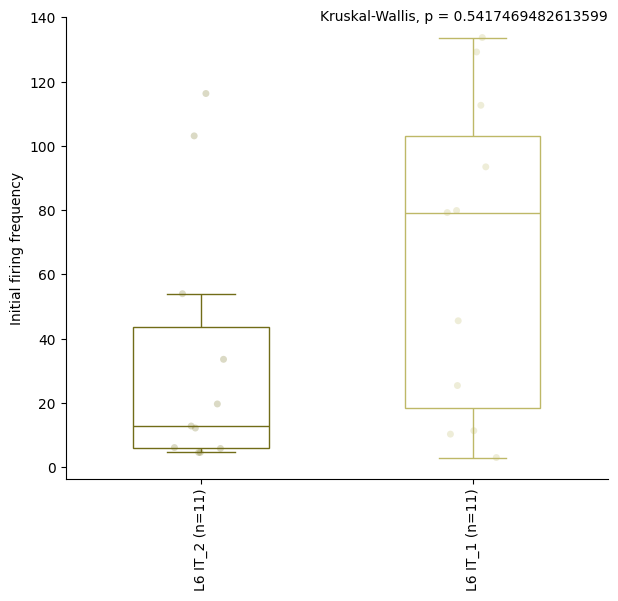

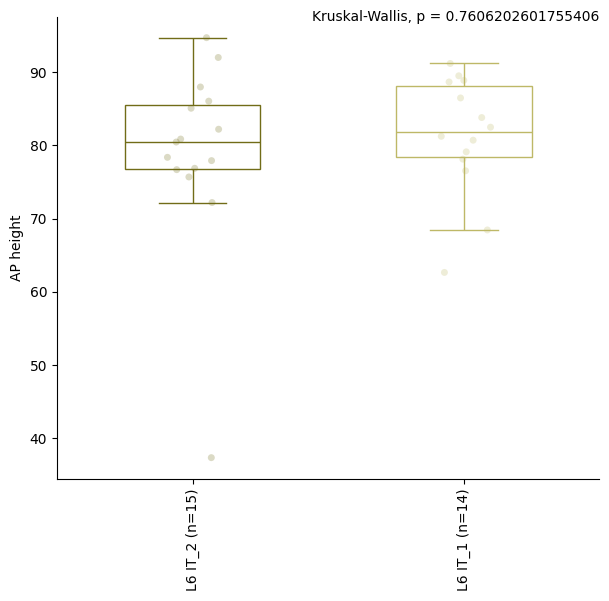

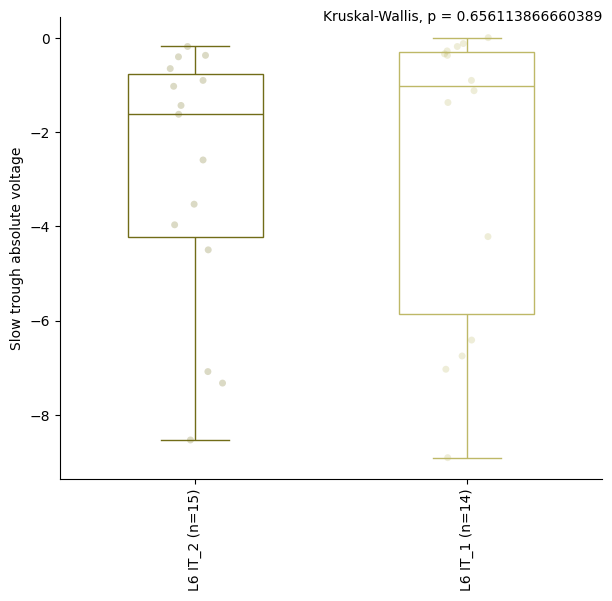

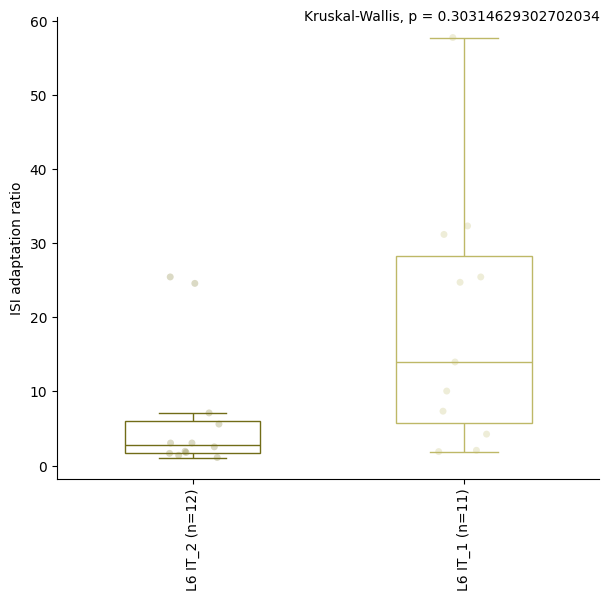

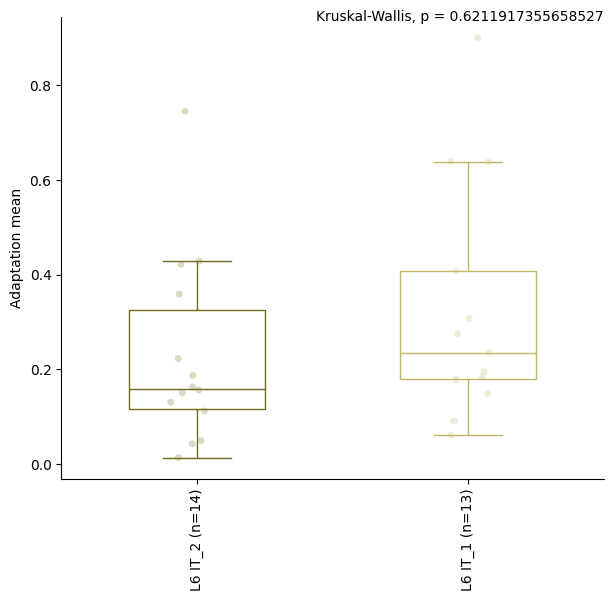

...

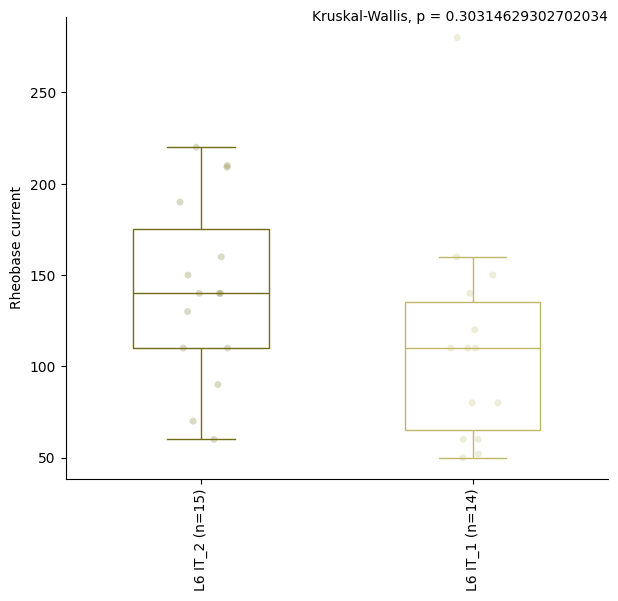

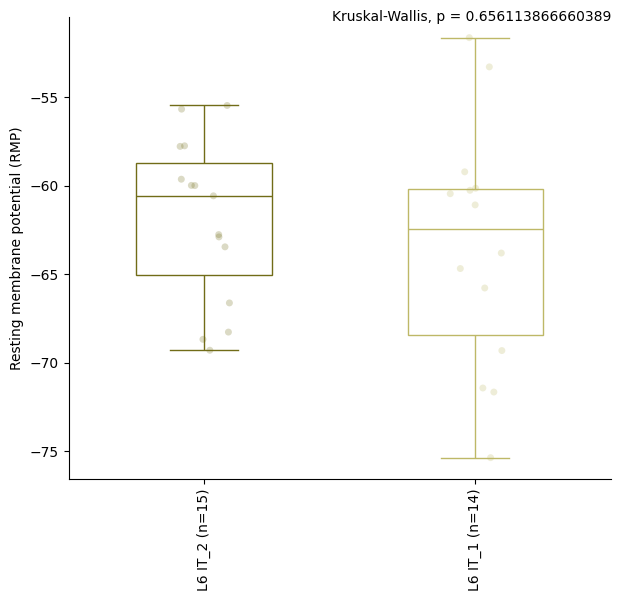

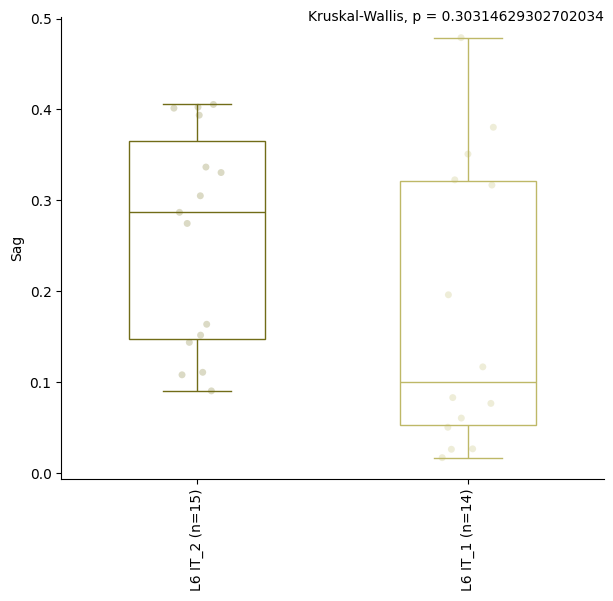

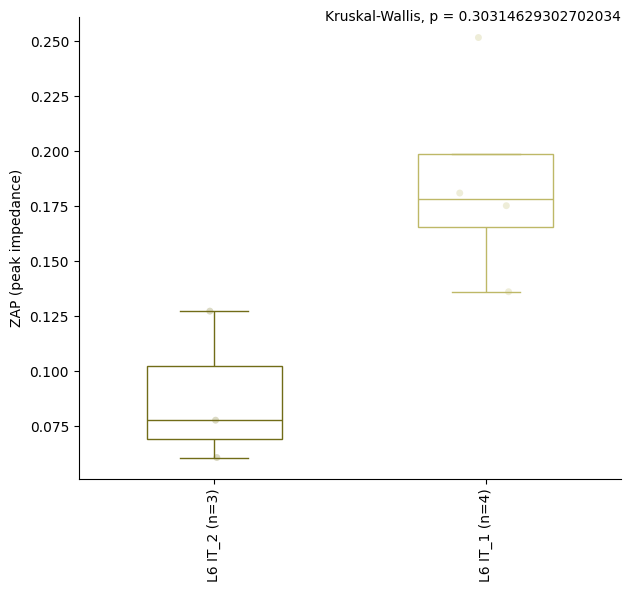

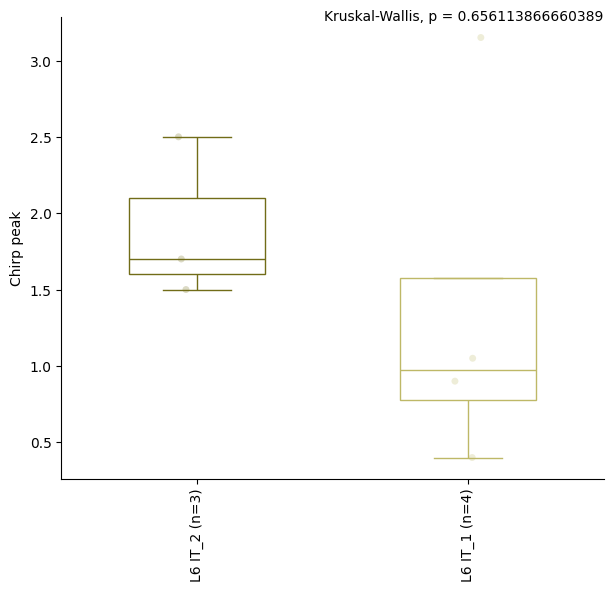

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.

<Figure size 640x480 with 0 Axes>

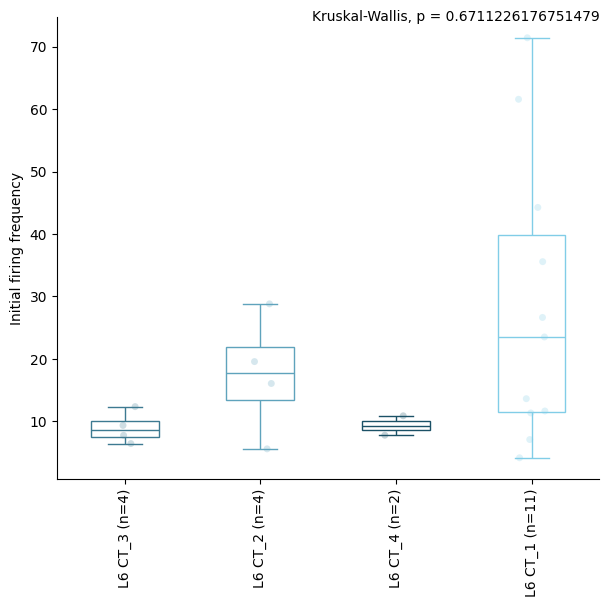

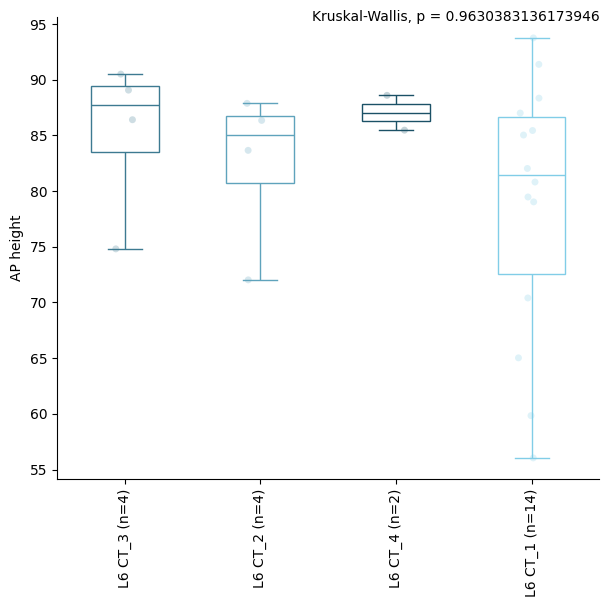

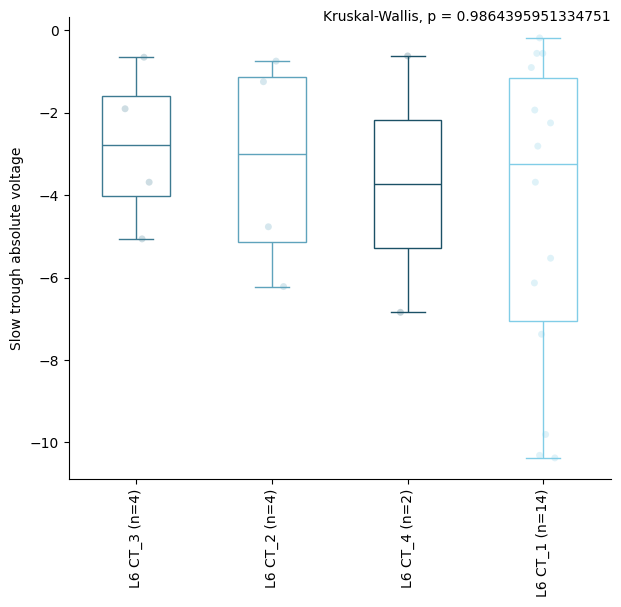

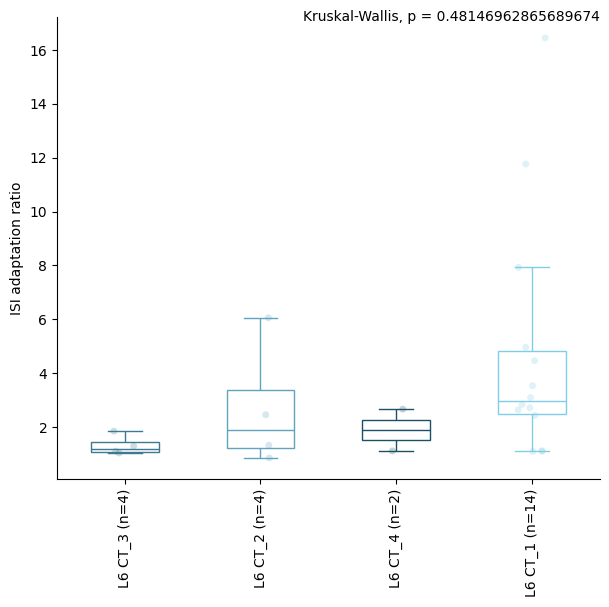

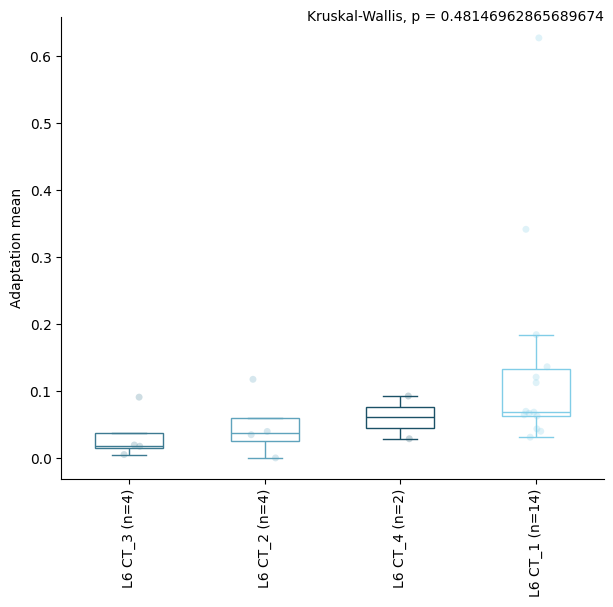

...

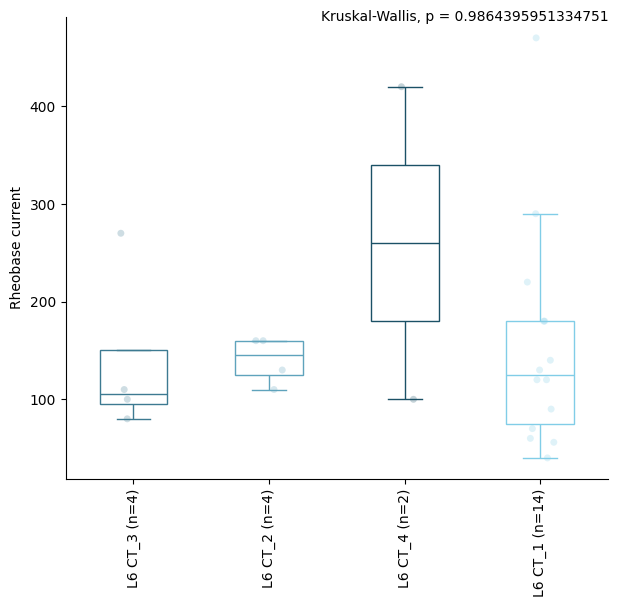

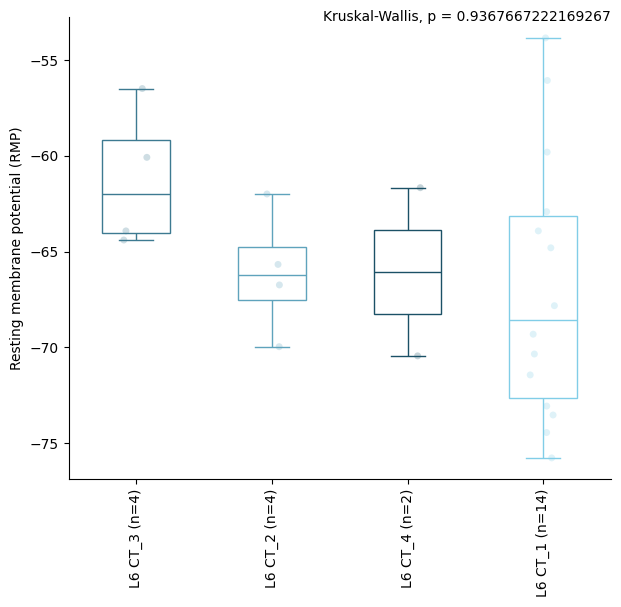

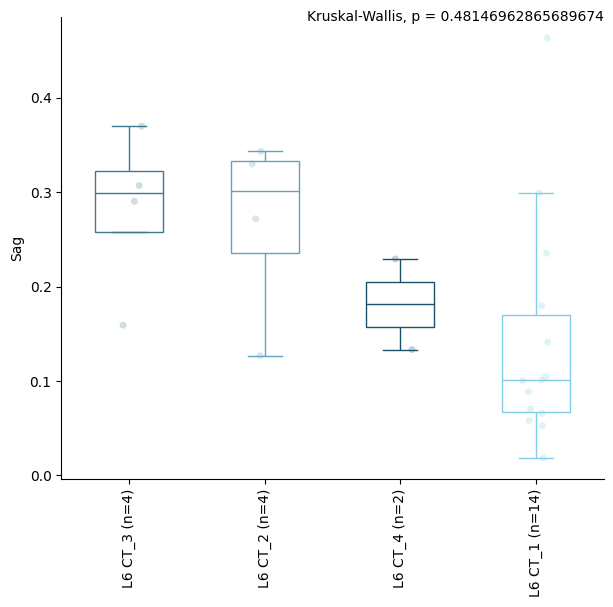

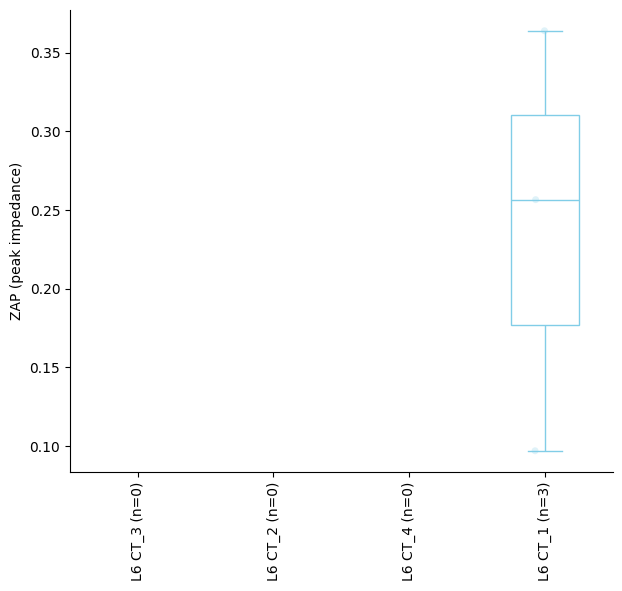

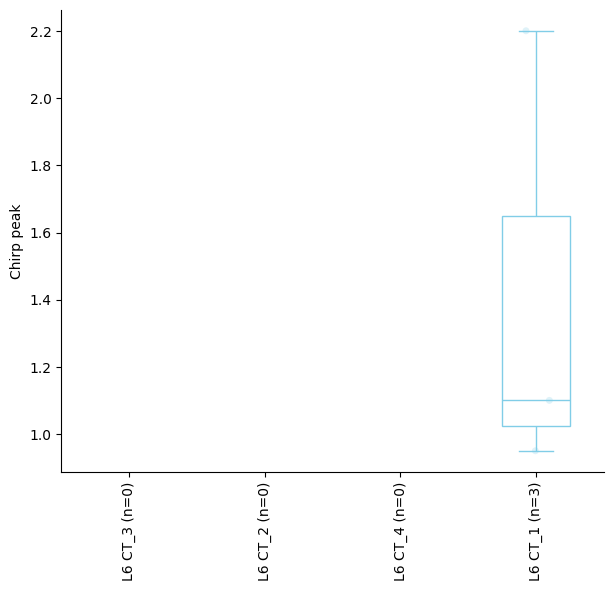

/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/892783857.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.

<Figure size 640x480 with 0 Axes>

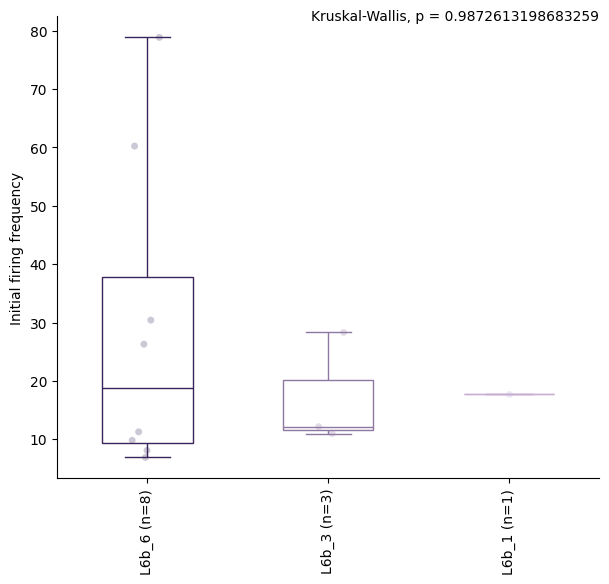

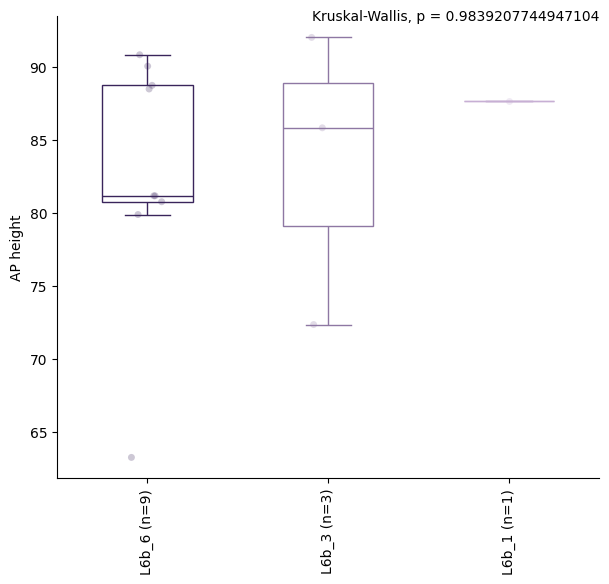

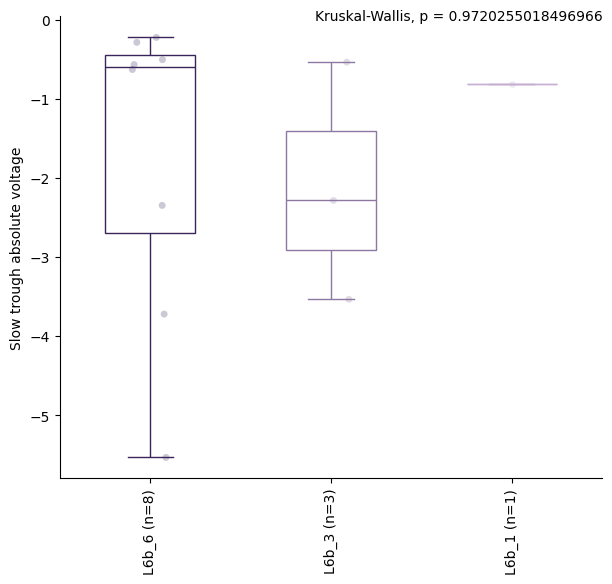

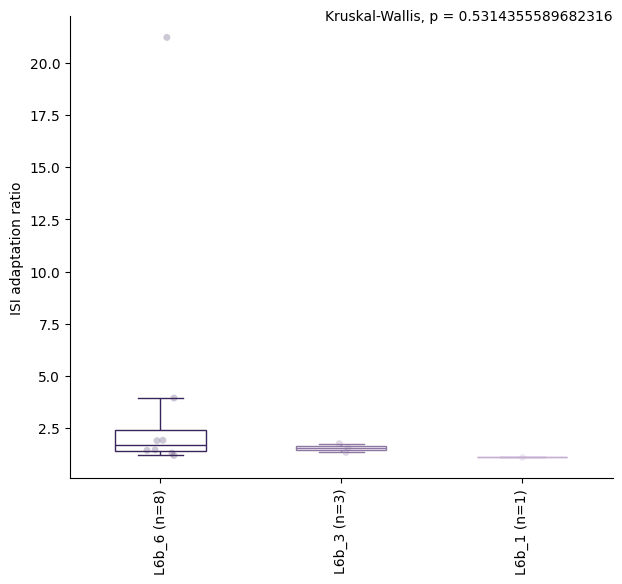

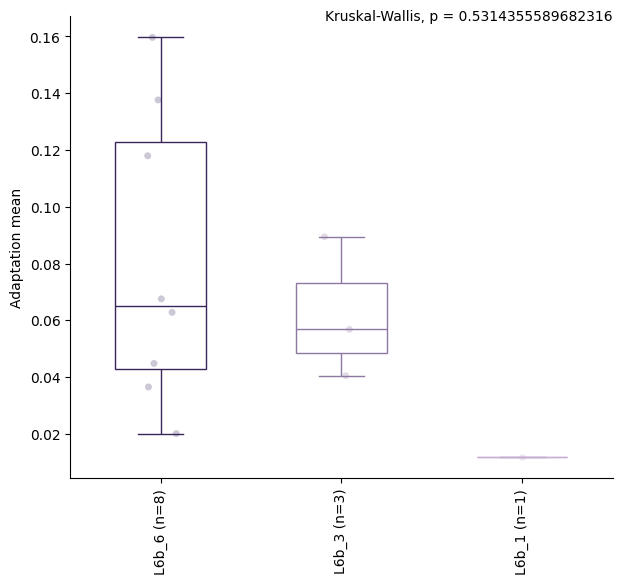

...

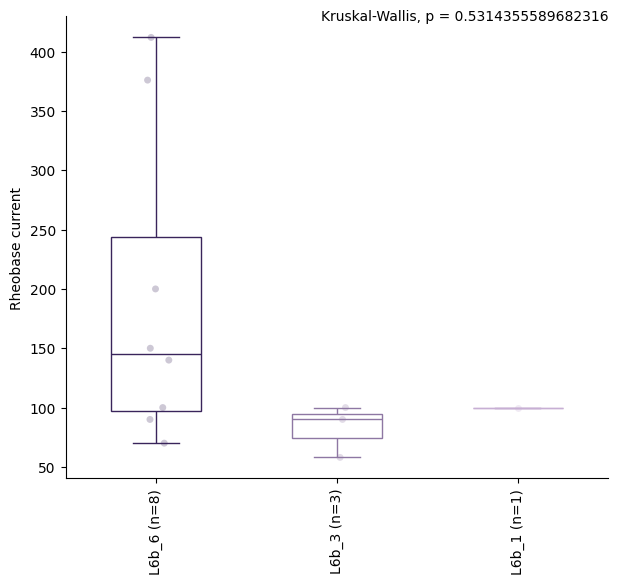

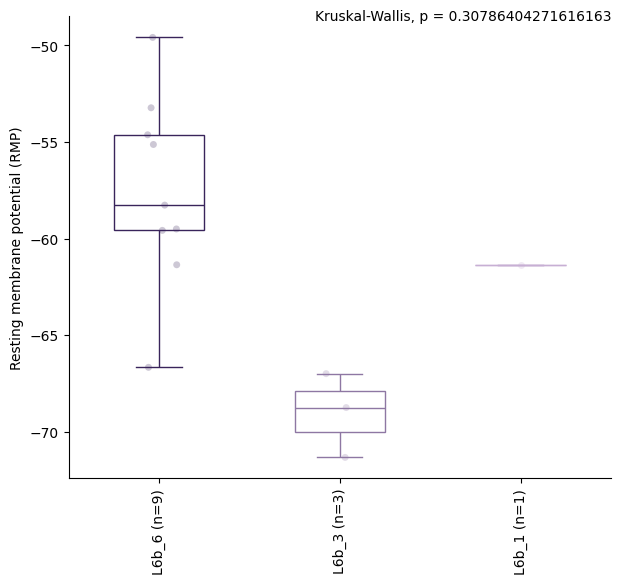

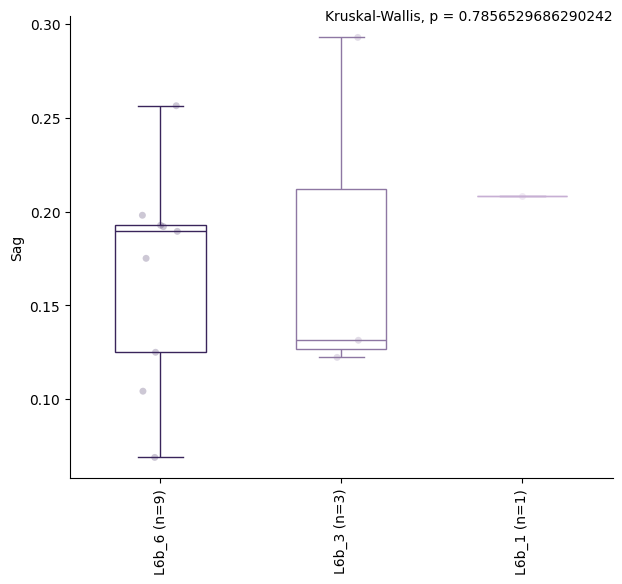

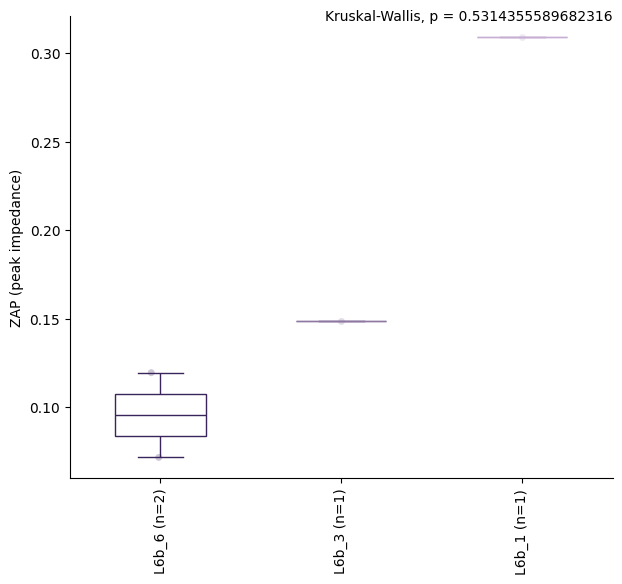

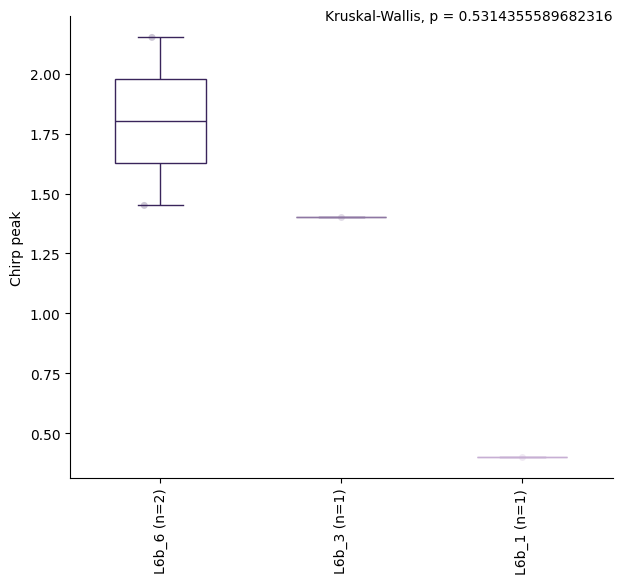

<Figure size 640x480 with 0 Axes>

In [19]:
# ttype x feature box plots

ttype_order = group_order['t_type']

for subclass in kw_pvals_fdr_subclass.keys():
    if kw_pvals_fdr_subclass[subclass]:
        #subclass has results (there were enough ttypes in the subclass, etc.)
        subclass_data = sorted_clean_data.loc[sorted_clean_data[subcalss_var] == subclass]
        kw_pvals_fdr = kw_pvals_fdr_subclass[subclass]  
        dunn_pvals_fdr = dunn_pvals_fdr_subclass[subclass]
        x_var = 't_type'  # what to do box plots on
        x_var_order = [t for t in ttype_order if t in subclass_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_{}_byTtype.pdf'.format(subclass.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 't_type' #seperate strip plots into these categories 
        hue_color_palette = color_dicts[hue_var] #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        ephys_features = feature_cols.copy()

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while ephys_features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = ephys_features.pop()
                    
                    sns.stripplot(data=subclass_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=subclass_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(subclass_data[(subclass_data[x_var] == t) & (~subclass_data[y_var].isna())])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=subclass_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



Cross areal box plots - subclass

In [20]:
# subclass x feature box plots

x_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
group_var = 'subclass_label'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_Other: Custom statistical test, P_val:3.085e-02


/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:1.885e-02


/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:6.096e-03
L2/3 IT_TemL vs. L2/3 IT_Other: Custom statistical test, P_val:1.478e-09
L5 IT_TemL vs. L5 IT_Other: Custom statistical test, P_val:1.885e-02


... (10 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:4.155e-04


/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/234911206.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:1.468e-02


/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


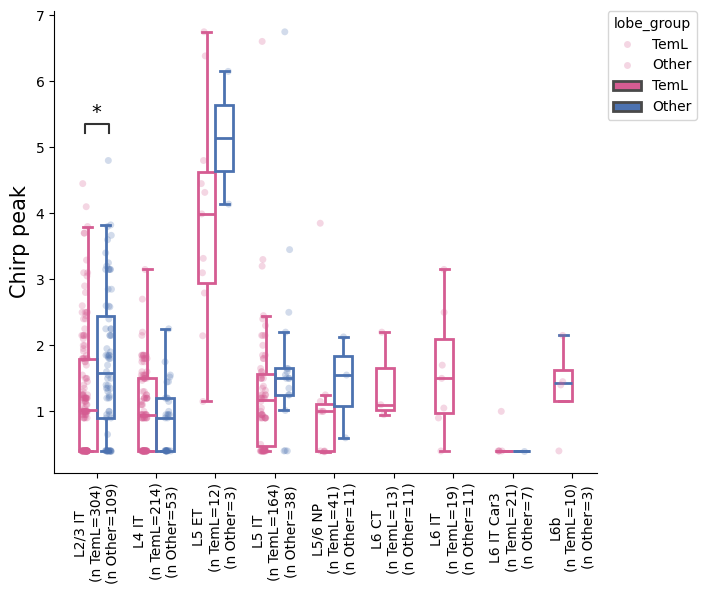

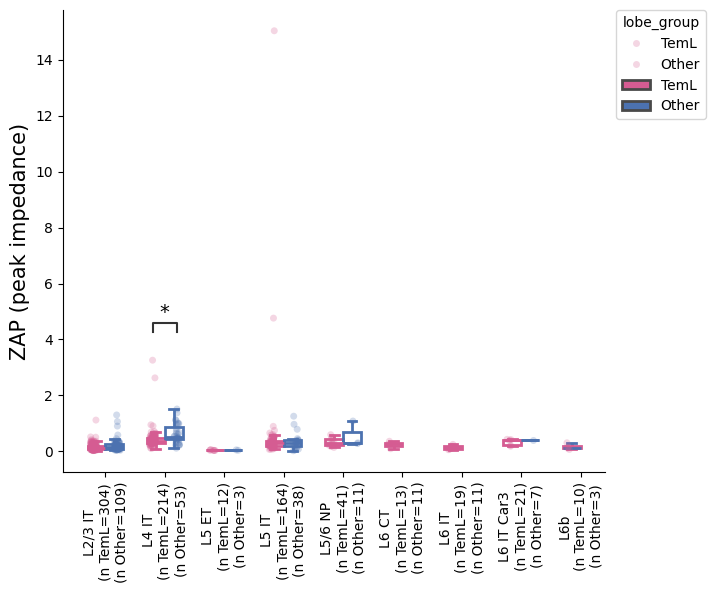

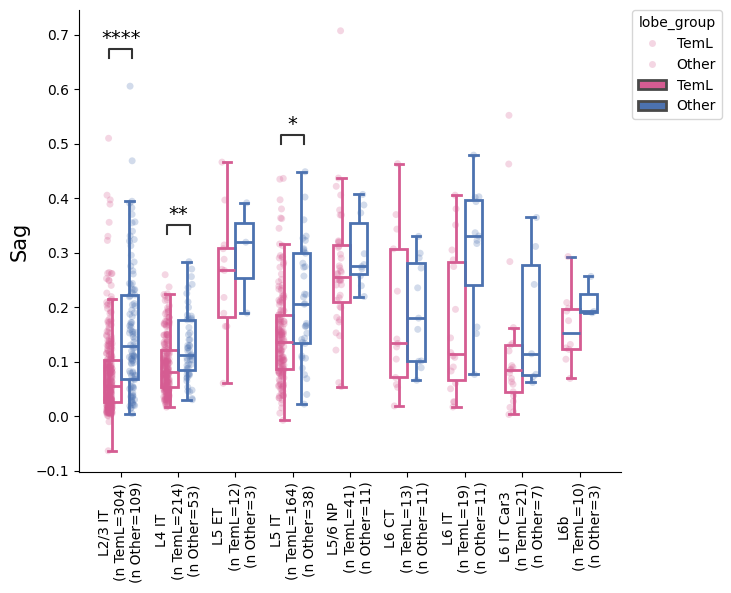

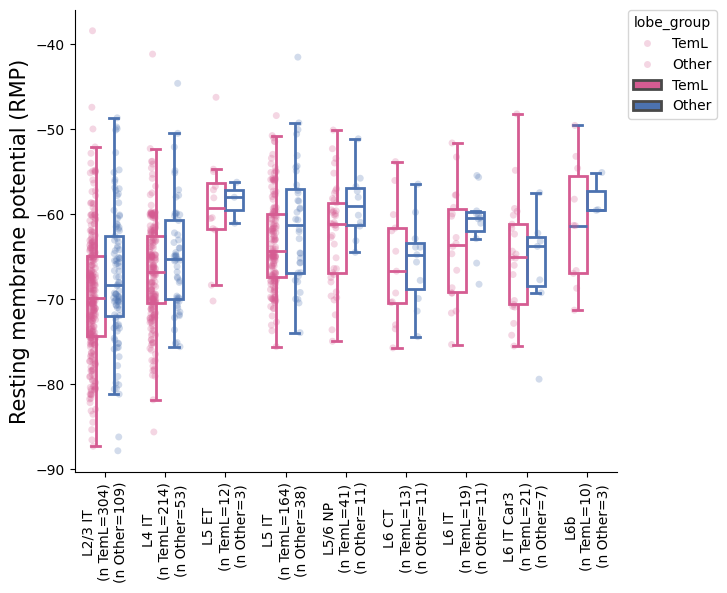

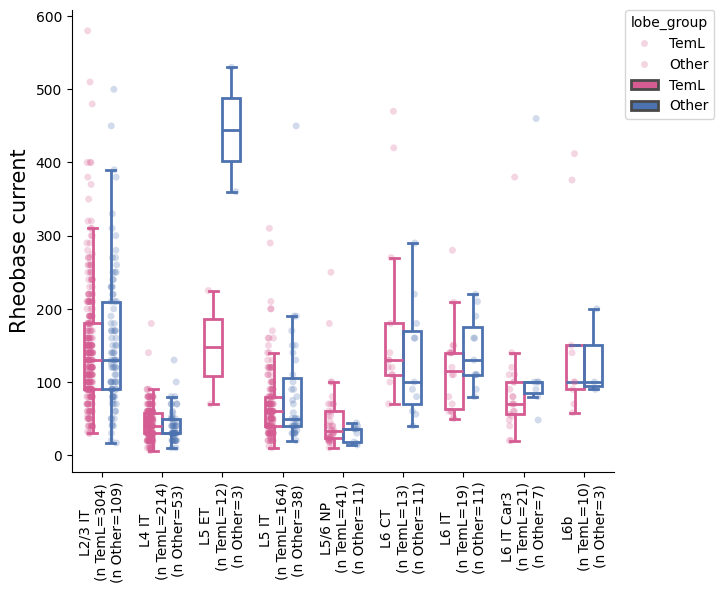

...

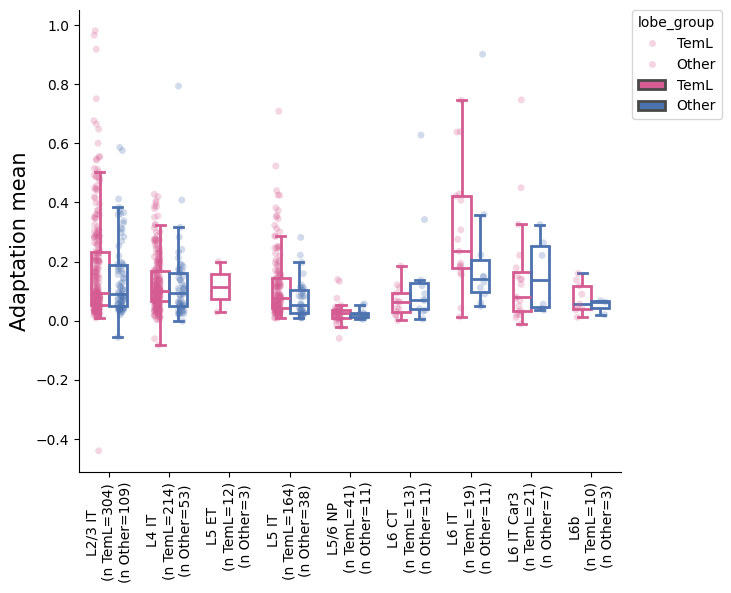

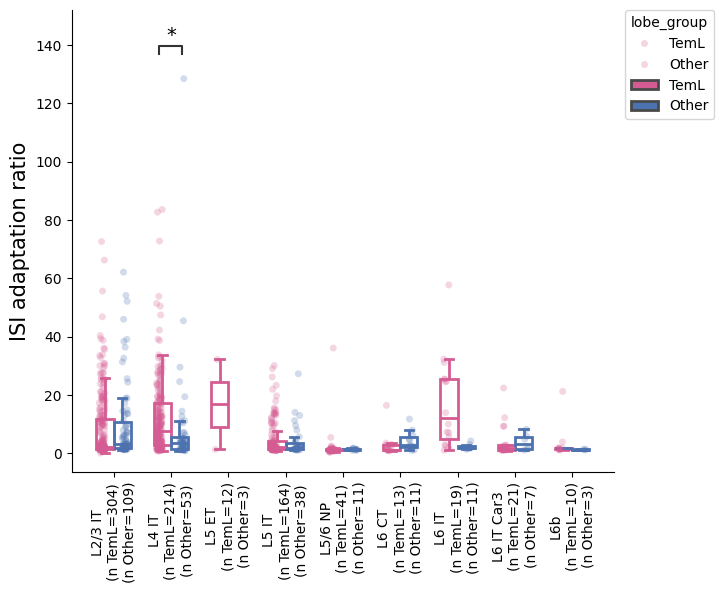

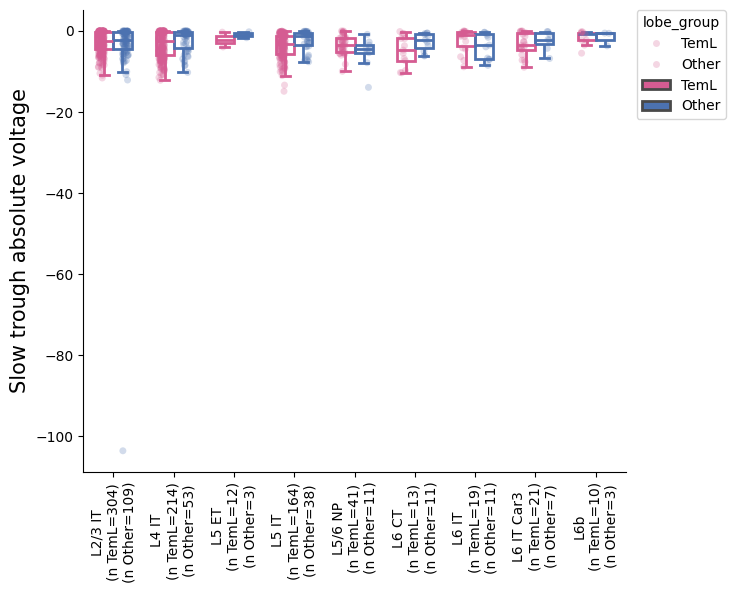

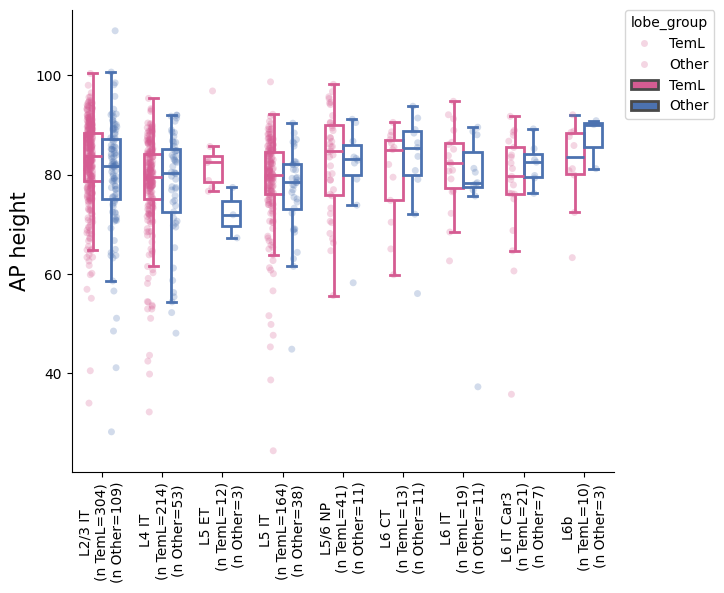

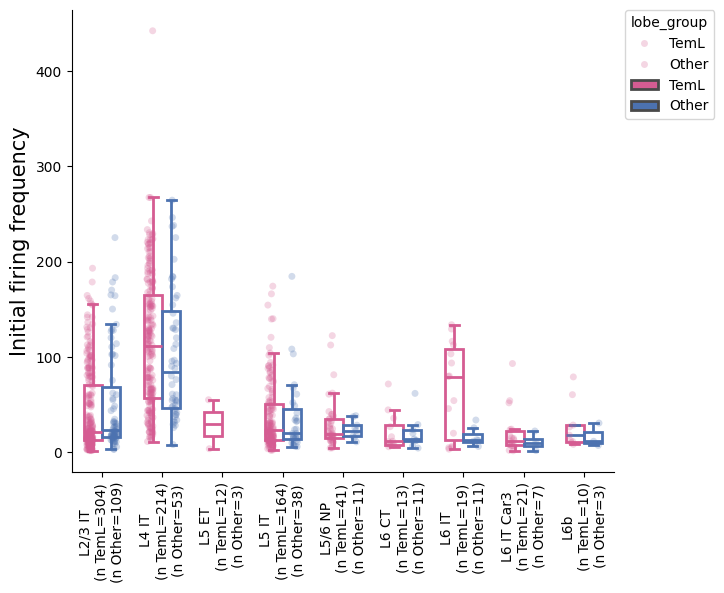

Boxplots with Mann-Whitney U stats saved.


In [21]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'lobe_group'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'Other']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            # sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'TemL')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'Other')])
                nobs.append("\n(n TemL={})\n(n Other={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'Other')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross areal box plots - ttype 

In [22]:
# ttype x feature box plots

x_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
group_var = 't_type'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_108402/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


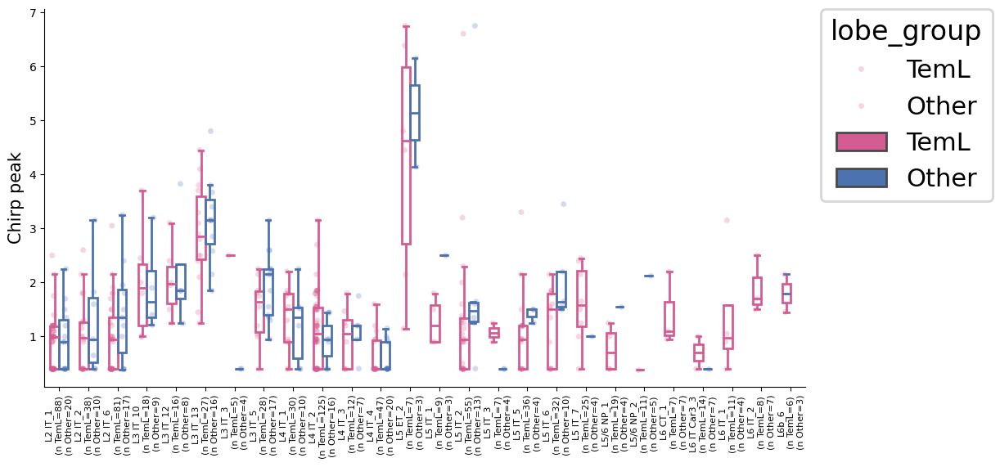

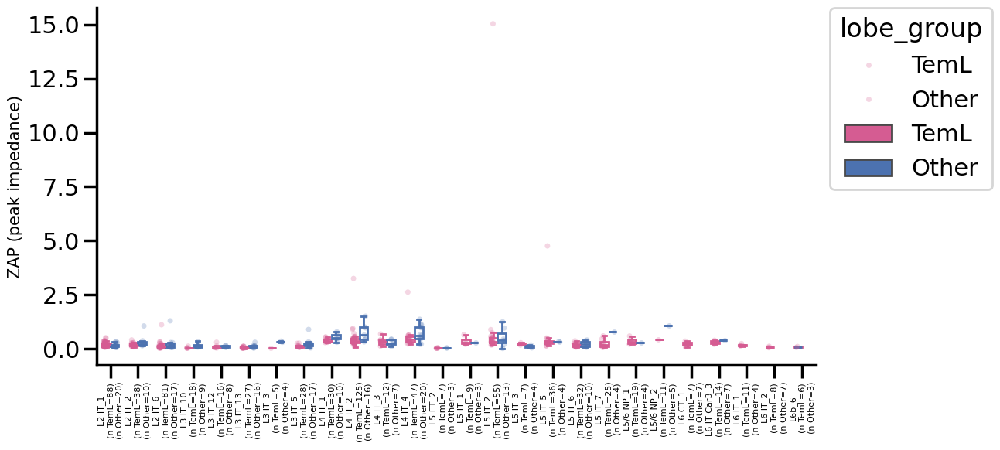

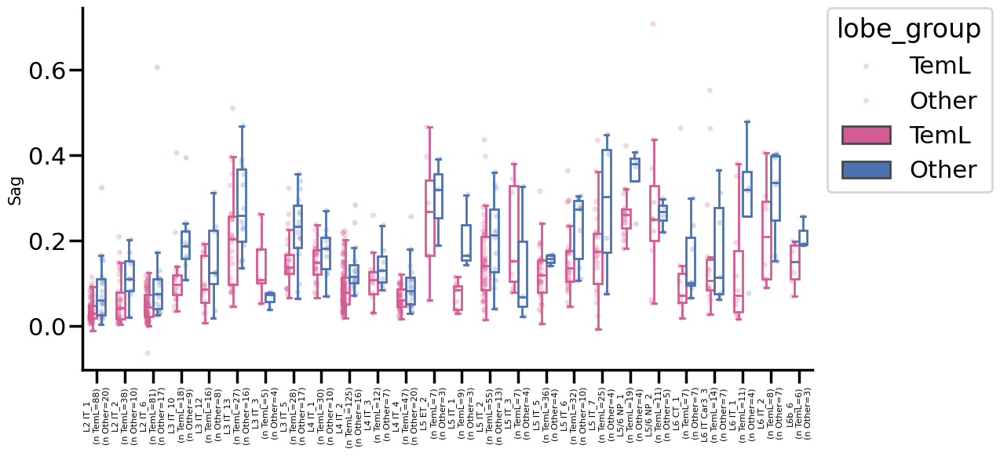

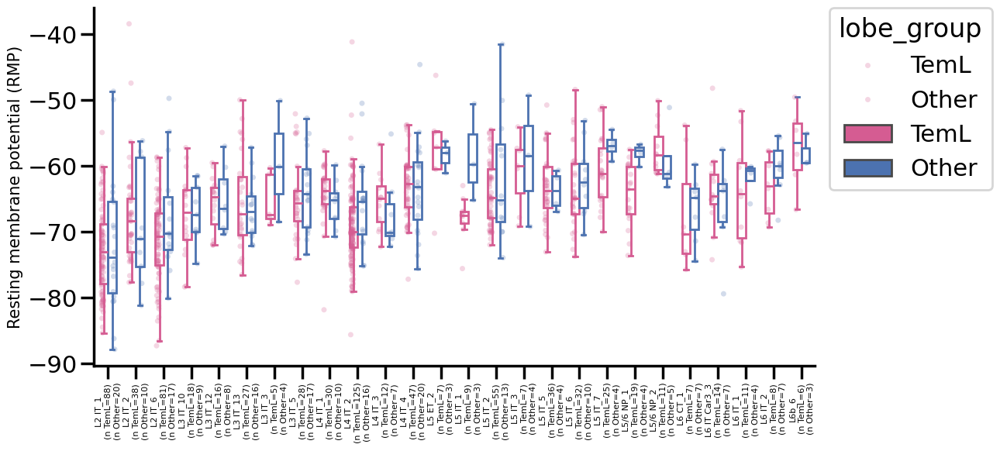

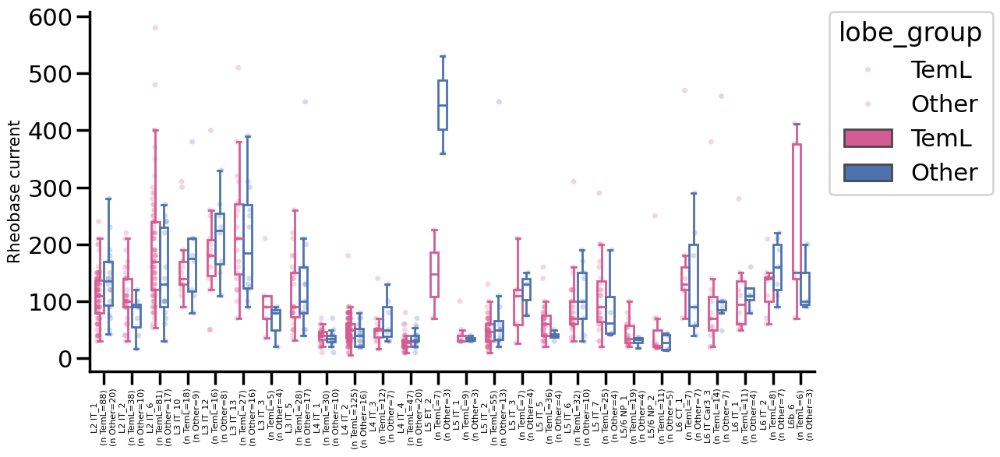

...

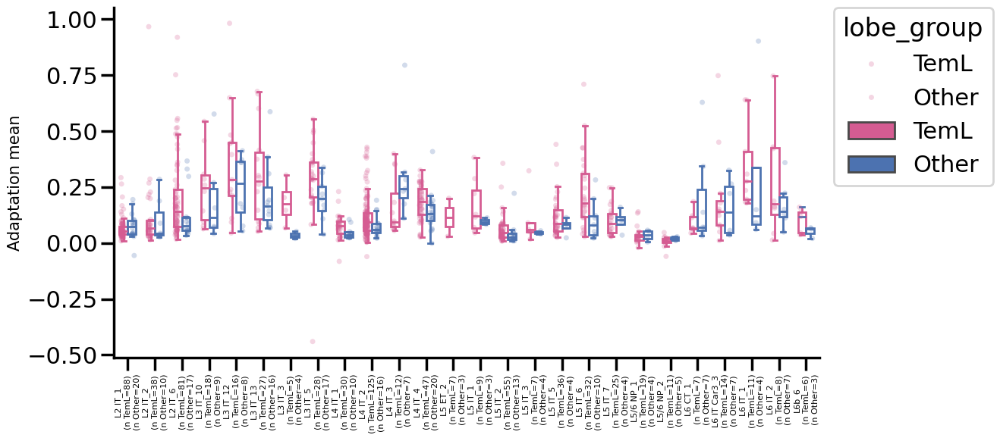

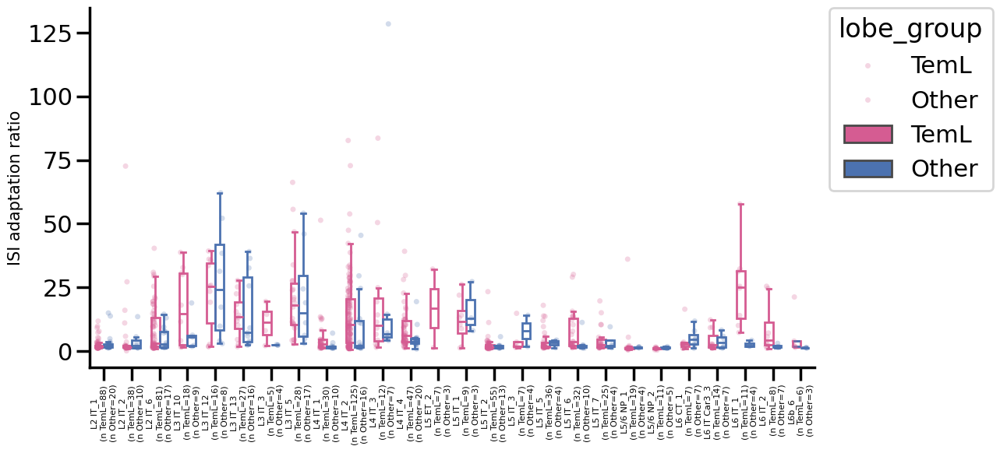

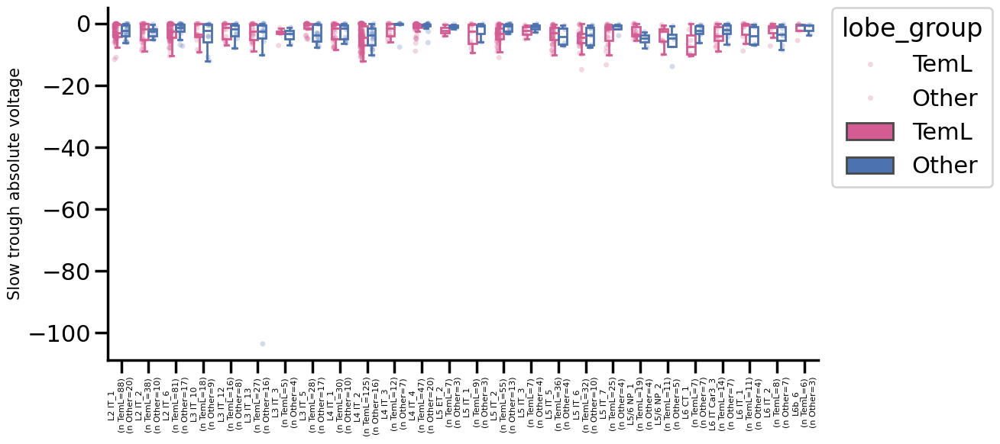

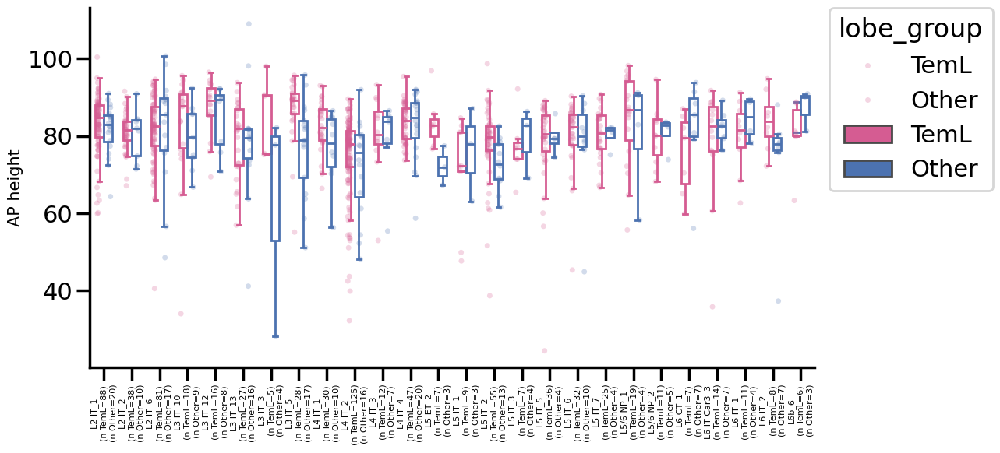

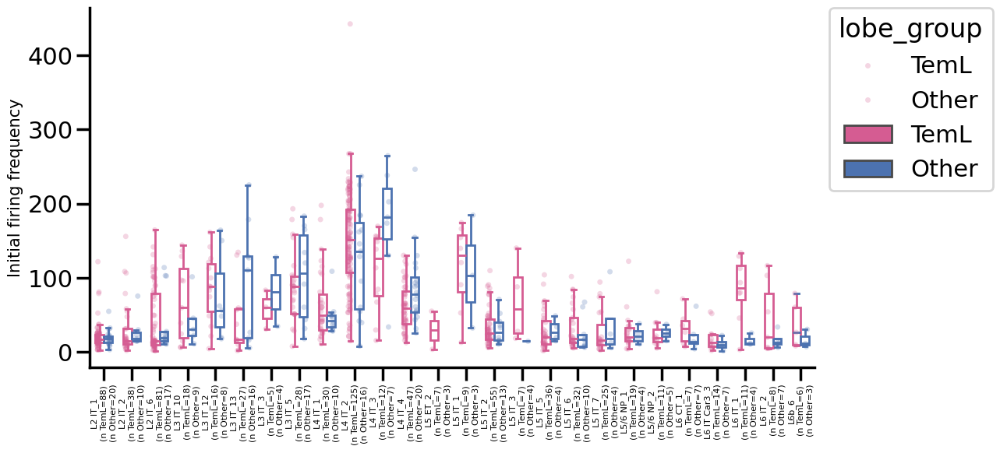

In [23]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'lobe_group'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'Other']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(12,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
                 
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'TemL')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'Other')])
                nobs.append("\n(n TemL={})\n(n Other={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=8)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'Other')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Cross areal box plots - subclass - TemL vs FroL

In [24]:
# subclass x feature box plots

x_var = 'lobe'
x_var_order = group_order[x_var]
group1_label = 'TemL'
group2_label = 'FroL'
group_var = 'subclass_label'

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)]
n_min_cells = 3
combo_counts = this_sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = this_sorted_clean_data[this_sorted_clean_data[group_var] == group]
    for f in ephys_features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:4.559e-02


/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:1.270e-02


/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:2.268e-05


... (9 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:1.353e-02


/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2292705234.py:21: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT_TemL vs. L6 IT_FroL: Custom statistical test, P_val:4.995e-02


/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


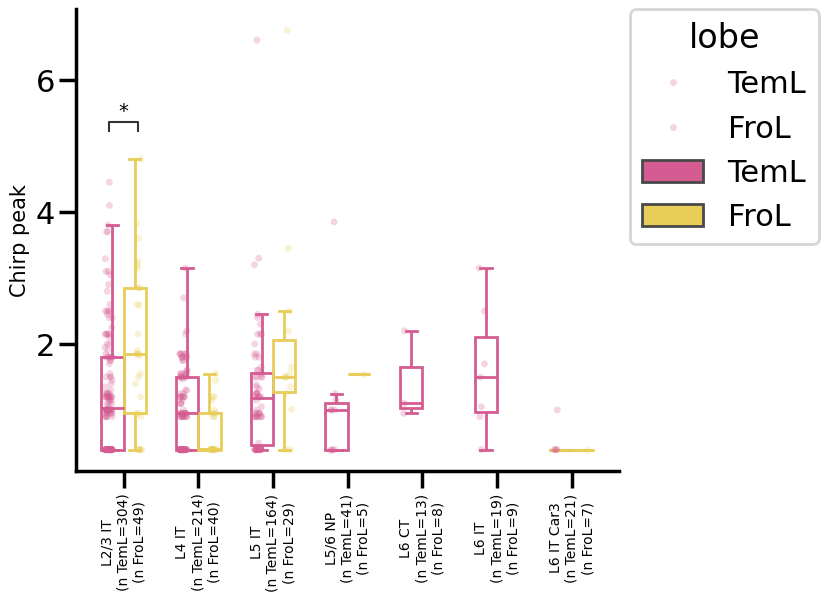

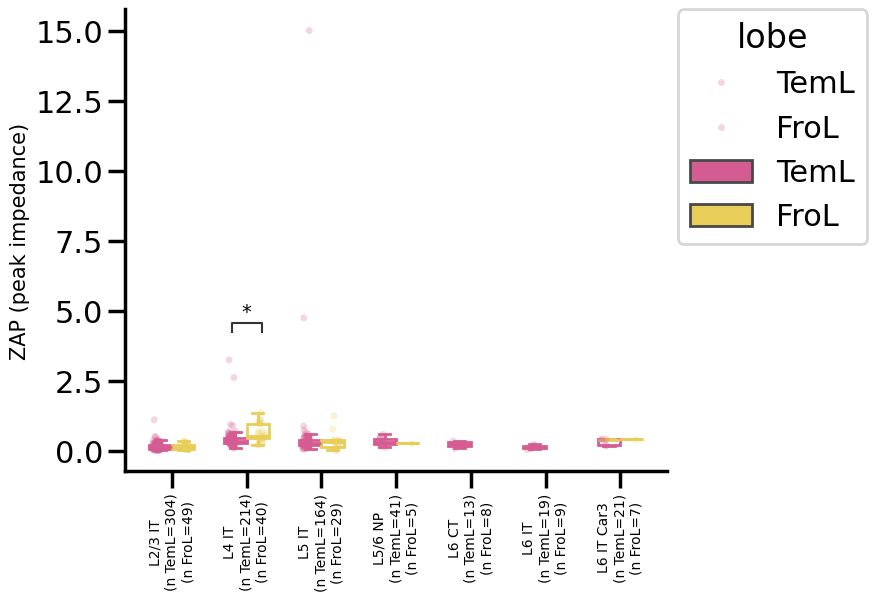

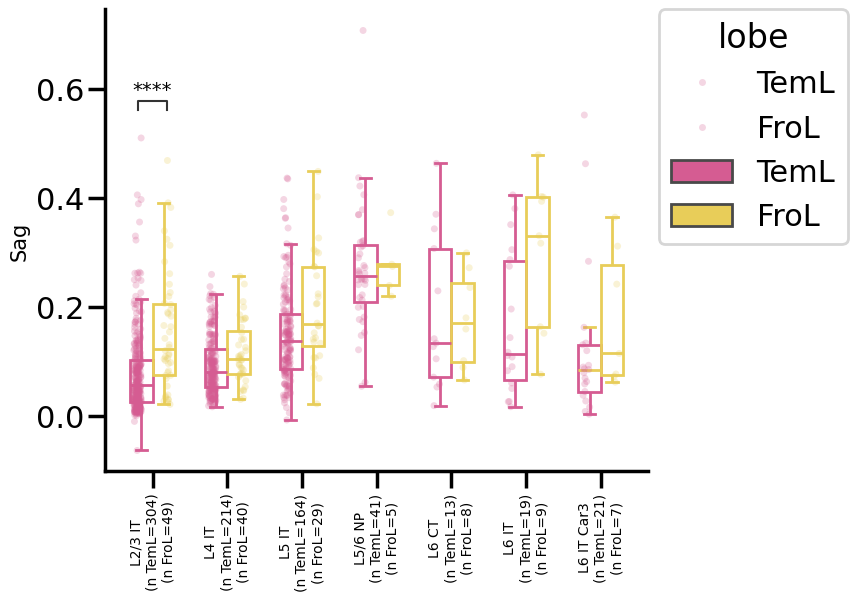

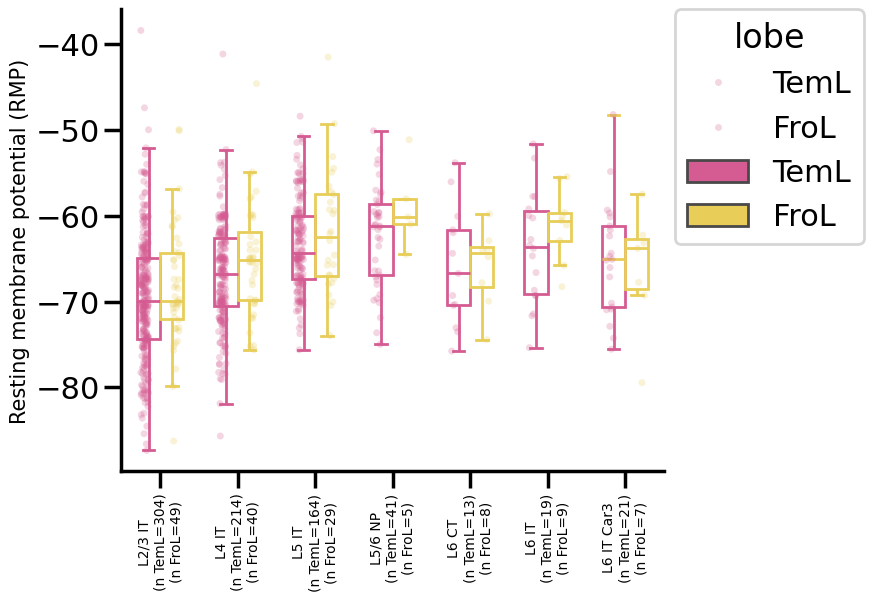

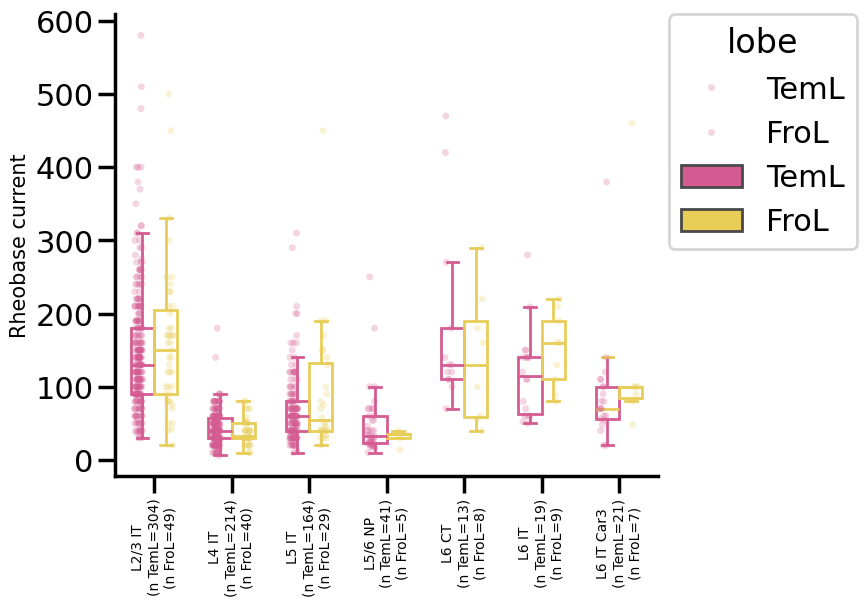

...

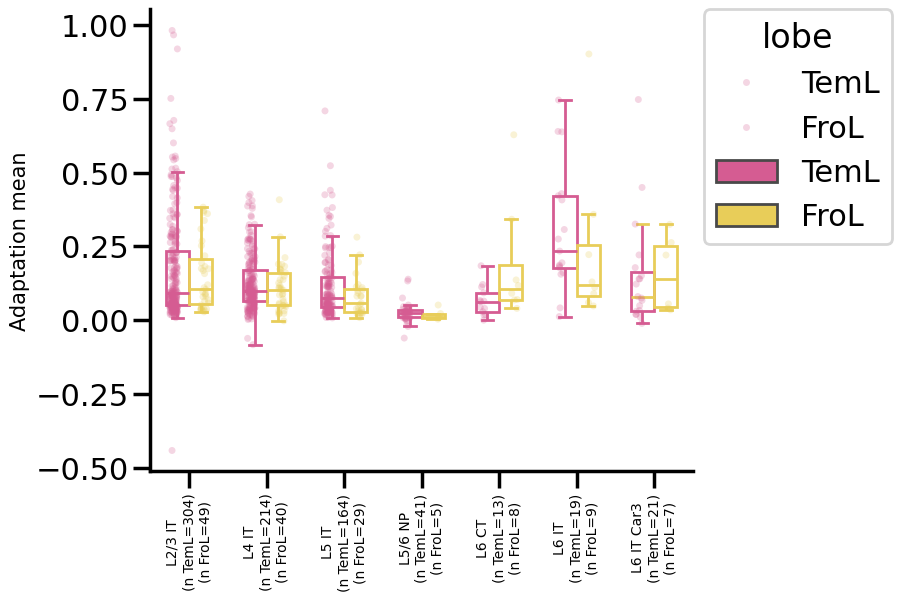

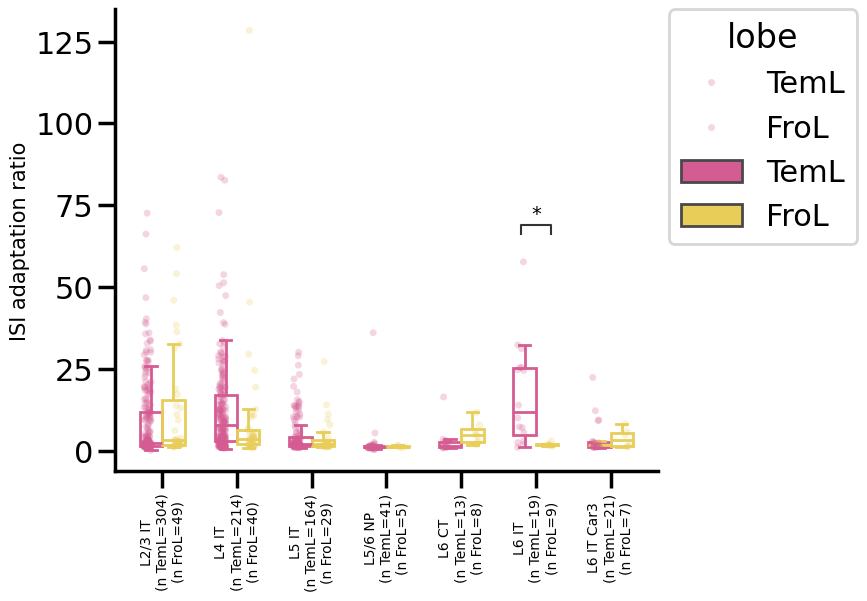

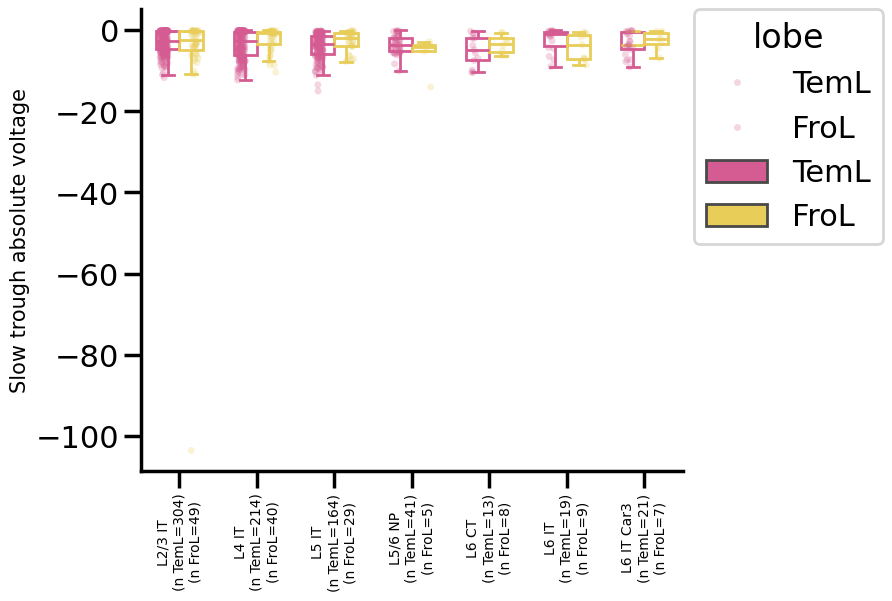

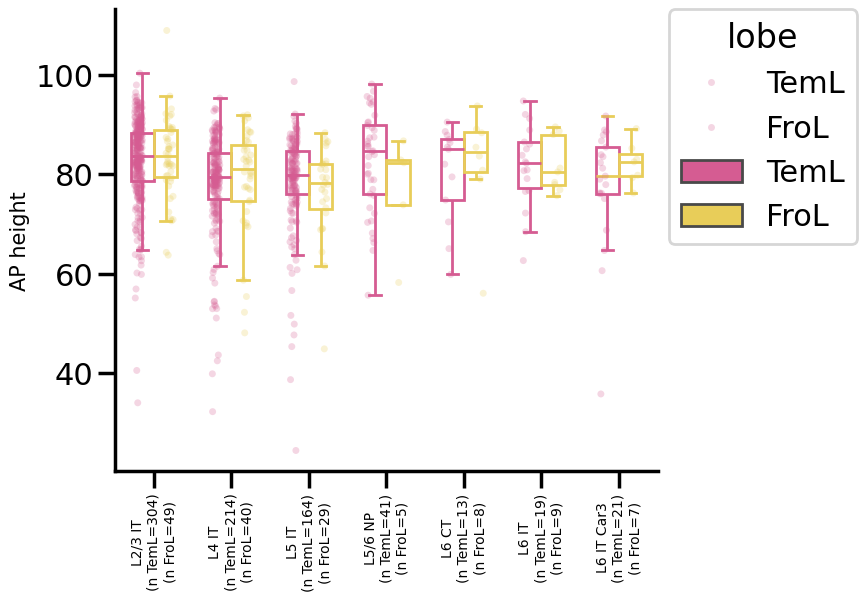

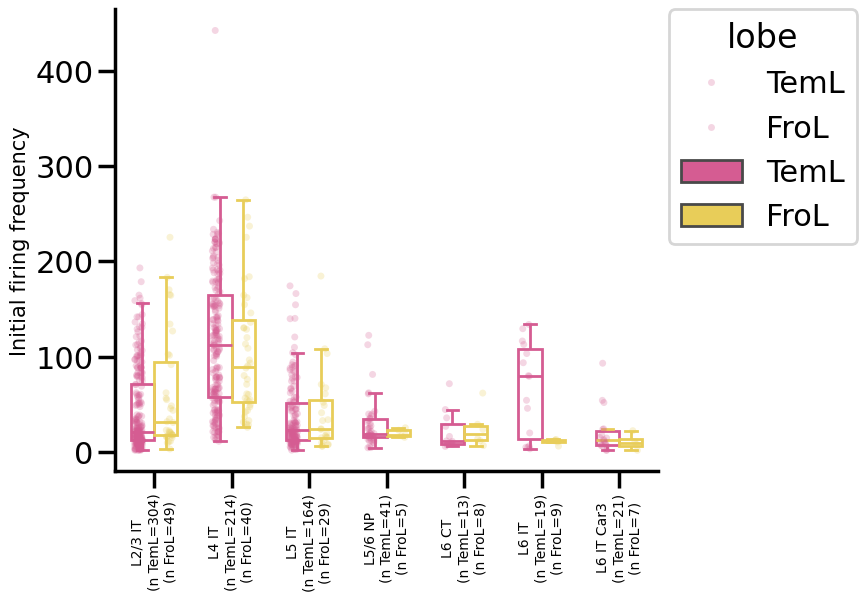

Boxplots with Mann-Whitney U stats saved.


In [25]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_teml_frol_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'lobe'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'FroL']
color_palette = color_dicts[hue_var]

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[hue_var].isin(hue_order)]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
                        
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'TemL')])
                nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'FroL')])
                nobs.append("\n(n TemL={})\n(n FroL={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'FroL')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross areal box plots - ttype - TemL vs FroL

In [26]:
# ttype x feature box plots

x_var = 'lobe'
x_var_order = ['TemL', 'FroL']
group1_label = 'TemL'
group2_label = 'FroL'
group_var = 't_type'

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)]
n_min_cells = 3
combo_counts = this_sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = this_sorted_clean_data[this_sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6_TemL vs. L2 IT_6_FroL: Custom statistical test, P_val:1.034e-02


/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


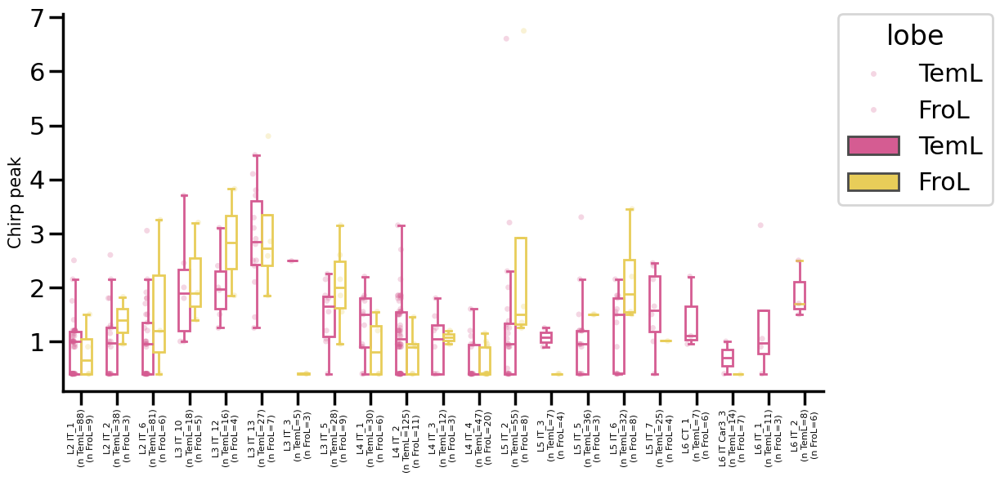

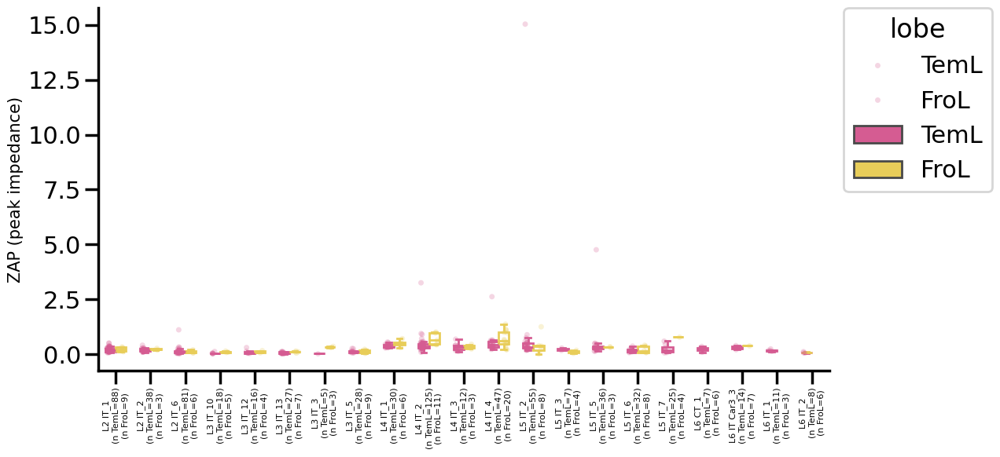

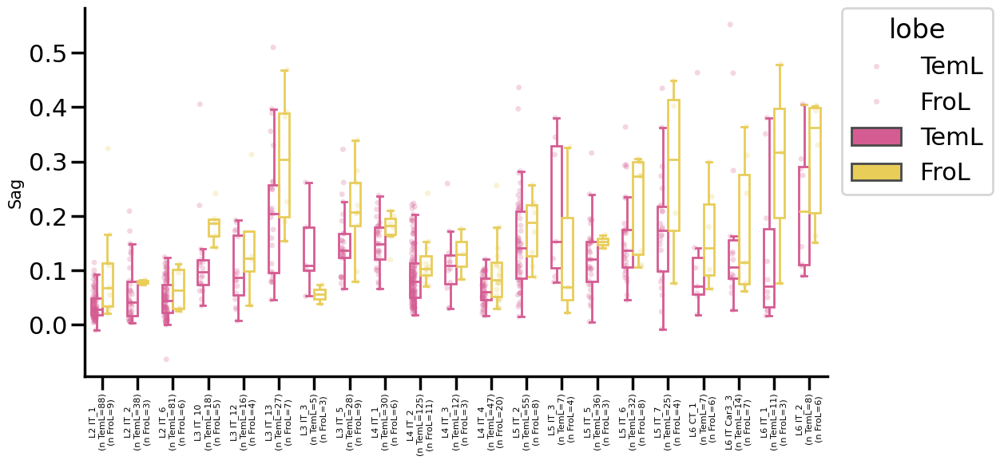

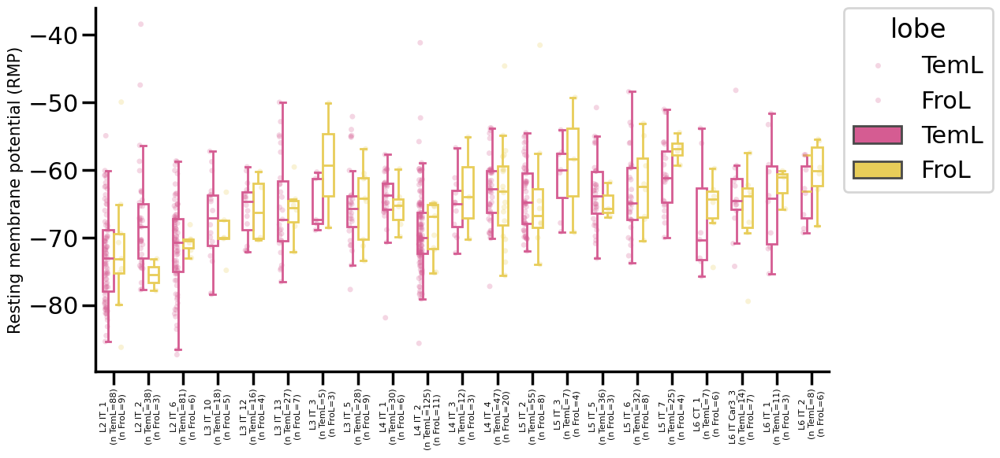

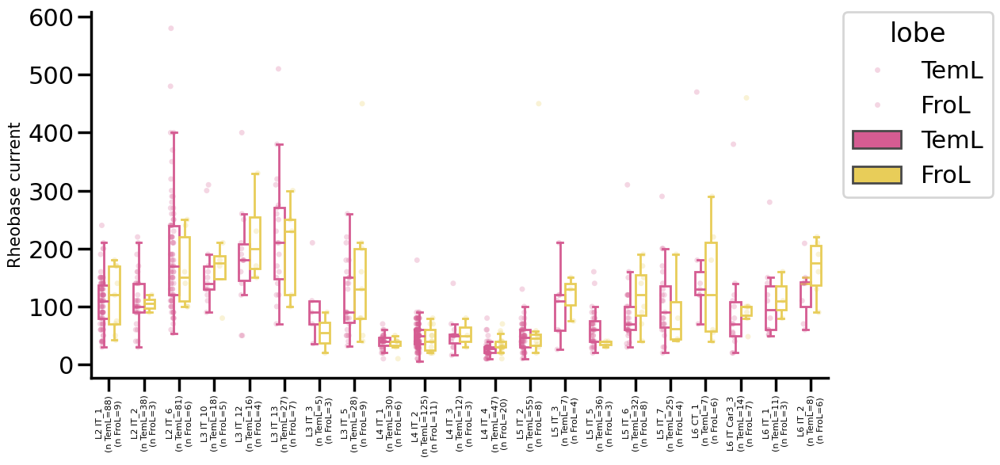

...

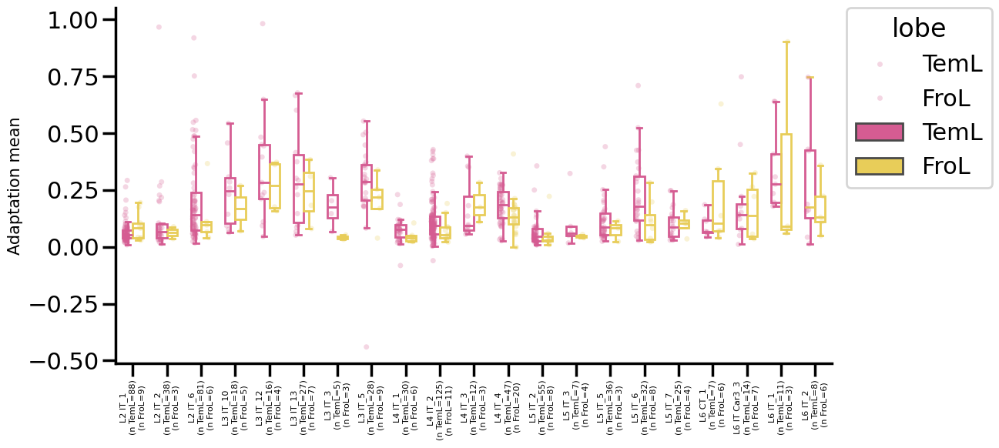

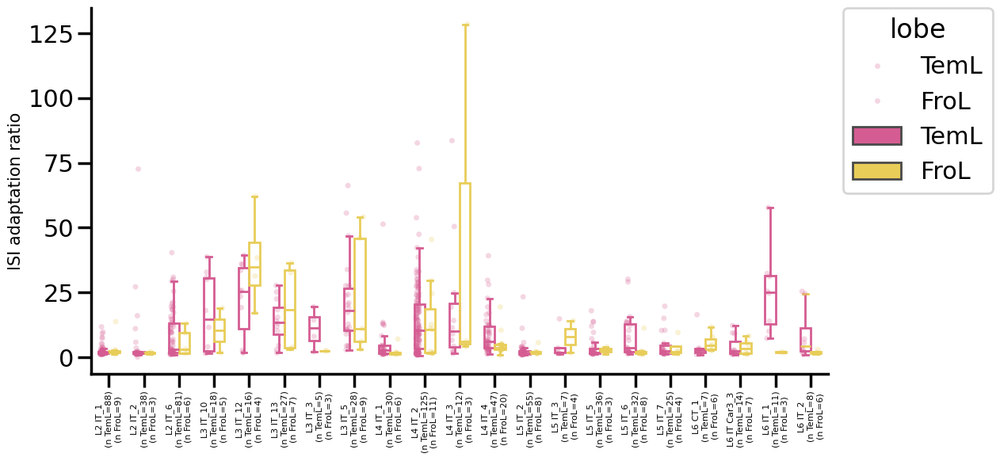

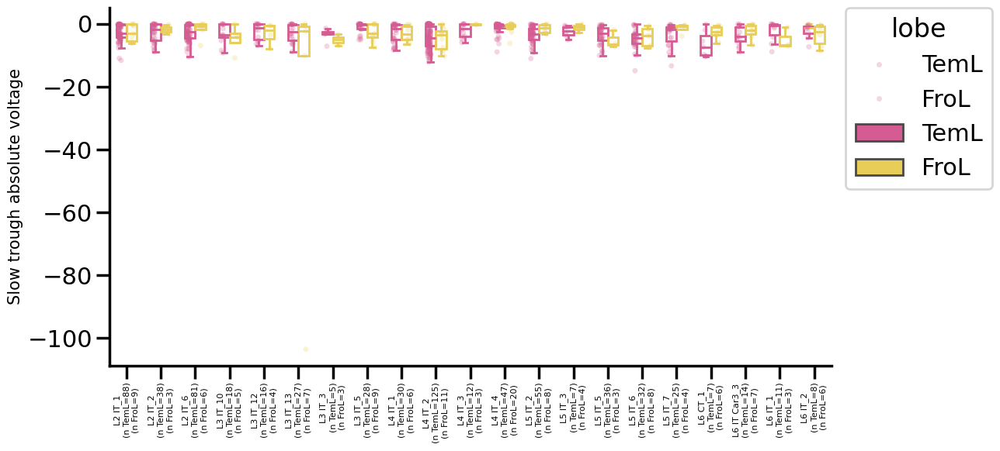

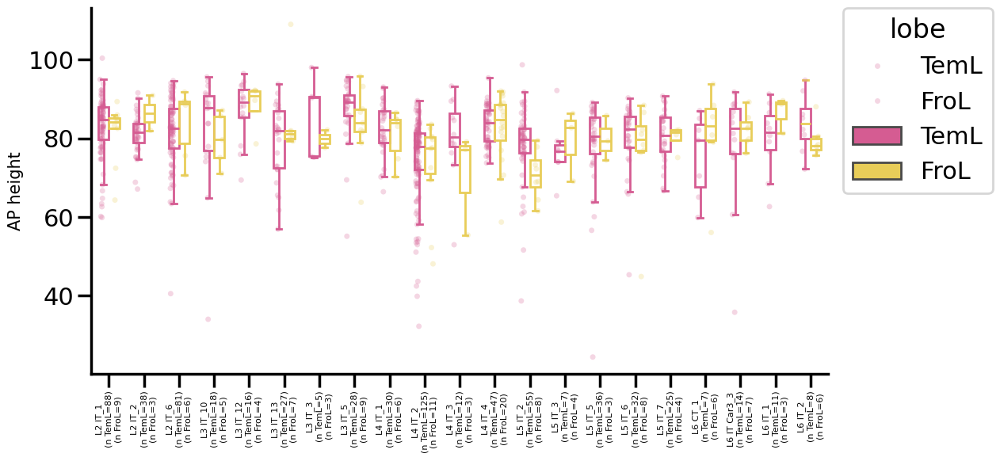

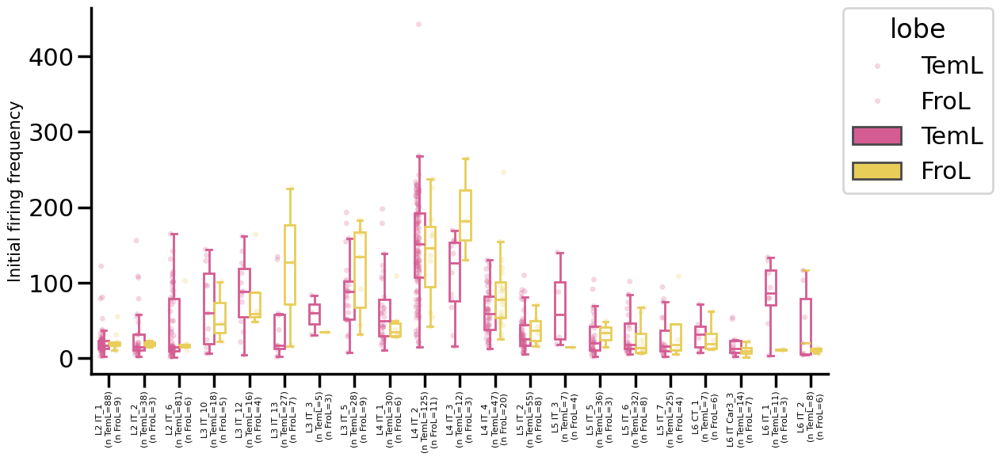

In [27]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_teml_frol_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'lobe'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'FroL']
color_palette = color_dicts[hue_var]

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[hue_var].isin(hue_order)]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(12,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'TemL')])
                nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'FroL')])
                nobs.append("\n(n TemL={})\n(n FroL={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=8)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'FroL')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Cross paradigm box plots - subclass

In [28]:
# subclass x feature box plots

x_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
group_var = 'subclass_label'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [29]:
#Save stats
rows = []
for (subclass, feature), pval in mw_pvals.items():
    rows.append({
        'subclass': subclass,
        'feature': feature,
        'mw_stat': mw_stats.get((subclass, feature)),
        'pval_raw': pval,
        'pval_fdr': mw_pvals_fdr.get((subclass, feature)),
        'rejected_pval_fdr': mw_rejected.get((subclass, feature)),
        'group1': group1_label,
        'group2': group2_label
    })

mw_stats_df = pd.DataFrame(rows)

# optional: sort for readability
mw_stats_df = mw_stats_df.sort_values(
    ['subclass', 'pval_fdr'],
    ascending=[True, True]
)

# save
mw_stats_df.to_csv(os.path.join(output_dir, r'ephys_feature_box_plot_stats_paradigm_subclass.csv'), index=False)
mw_stats_df

,subclass,feature,mw_stat,pval_raw,pval_fdr,rejected_pval_fdr,group1,group2
3,L2/3 IT,Resting membrane potential (RMP),2434.0,2.333628e-13,4.807274e-11,True,acute,culture
10,L2/3 IT,AP threshold,3514.0,6.260804e-09,2.149543e-07,True,acute,culture
2,L2/3 IT,Sag,3711.0,2.858433e-08,8.411959e-07,True,acute,culture
15,L2/3 IT,Trough voltage,4218.5,1.277615e-06,3.289859e-05,True,acute,culture
22,L2/3 IT,AP height,10910.0,7.695767e-06,1.441207e-04,True,acute,culture
...,...,...,...,...,...,...,...,...
199,L6b,Avg spike rate,12.0,5.479860e-01,6.850424e-01,False,acute,culture
196,L6b,AP downstroke,24.0,6.216006e-01,7.576907e-01,False,acute,culture
187,L6b,FI slope,17.0,9.333333e-01,9.552314e-01,False,acute,culture
189,L6b,Tau,21.0,9.432789e-01,9.552314e-01,False,acute,culture


/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_acute vs. L4 IT_culture: Custom statistical test, P_val:3.306e-04
L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:8.412e-07
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.458e-10
L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:4.088e-03
L6 IT_acute vs. L6 IT_culture: Custom statistical test, P_val:1.619e-04
L6 IT Car3_acute vs. L6 IT Car3_culture: Custom statistical test, P_val:1.582e-02


/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:4.807e-11
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.800e-08
L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:5.922e-05


/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.618e-03


... (19 outputs left out)

/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:1.441e-04


/tmp/ipykernel_108402/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.441e-04
L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:3.257e-02


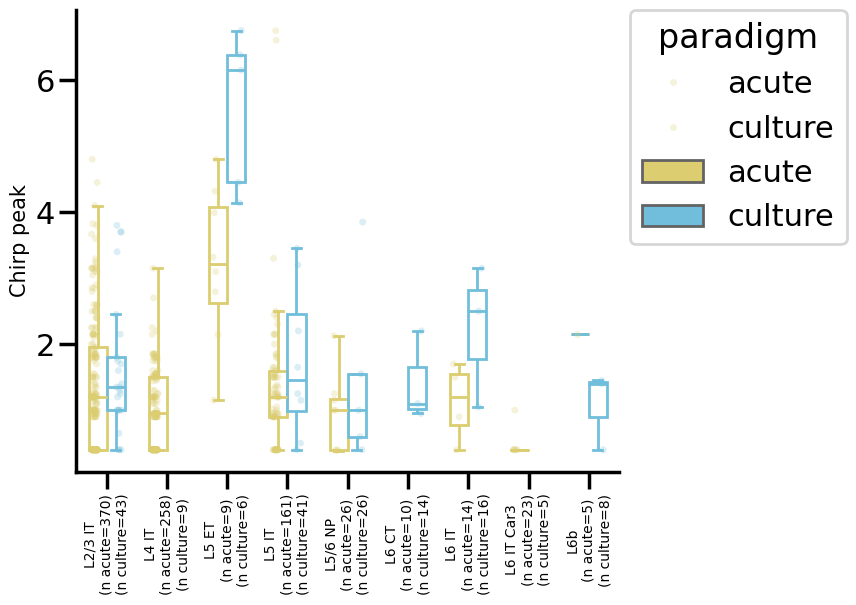

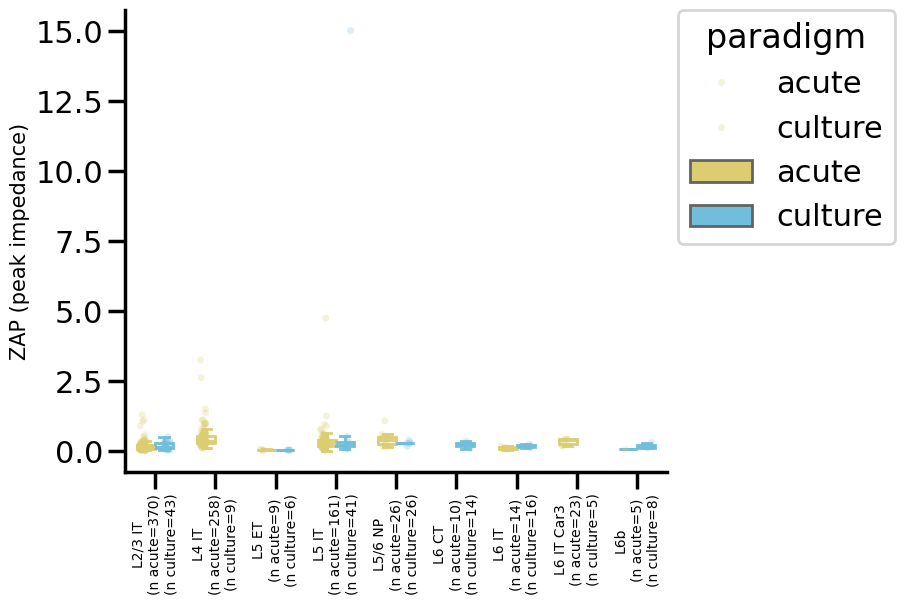

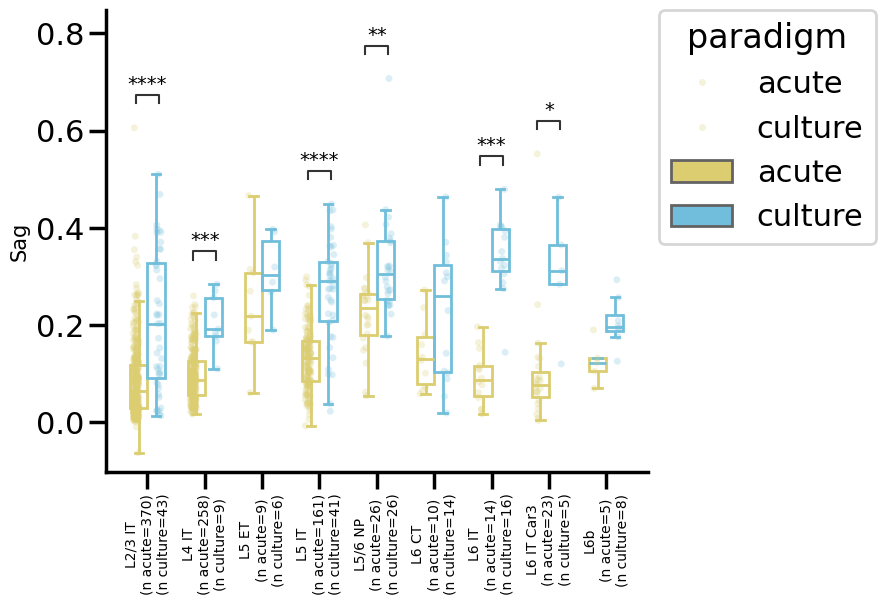

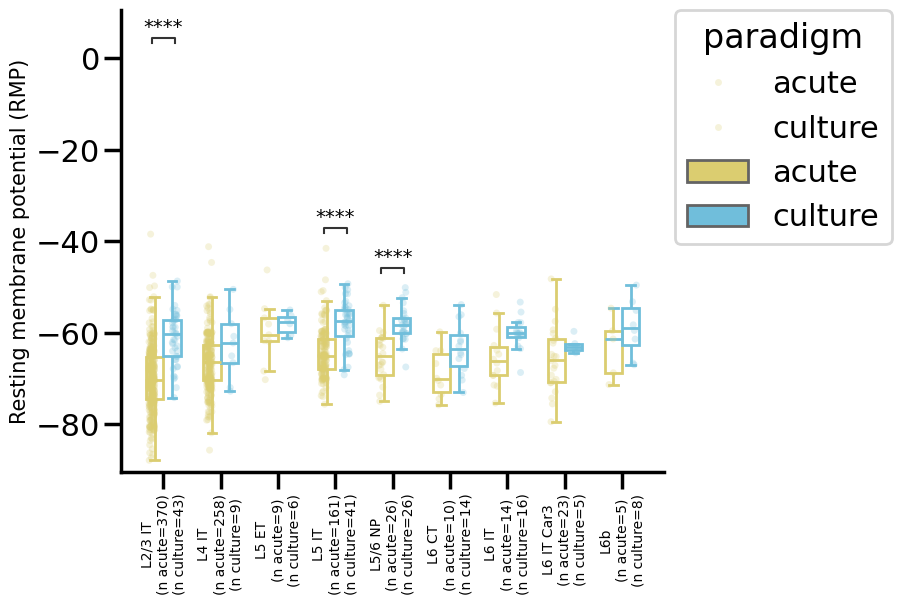

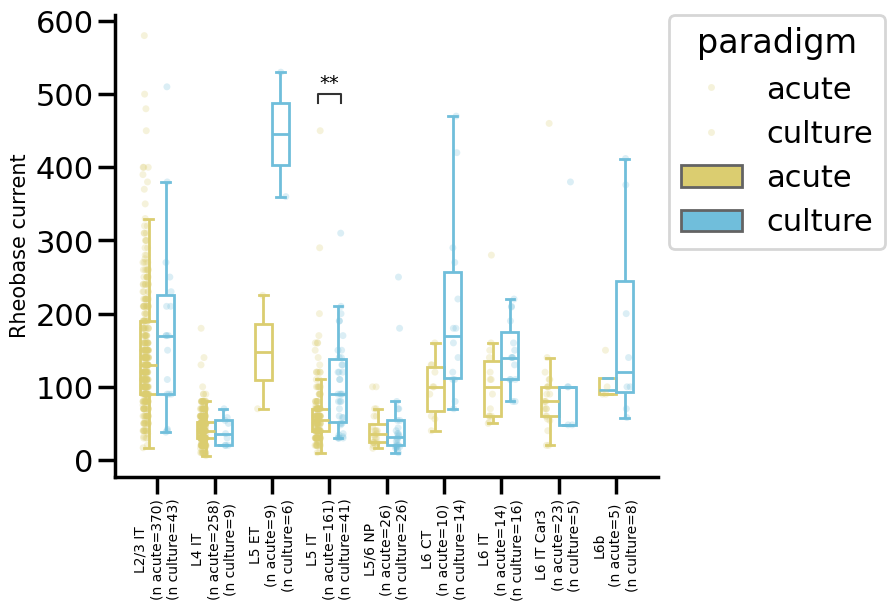

...

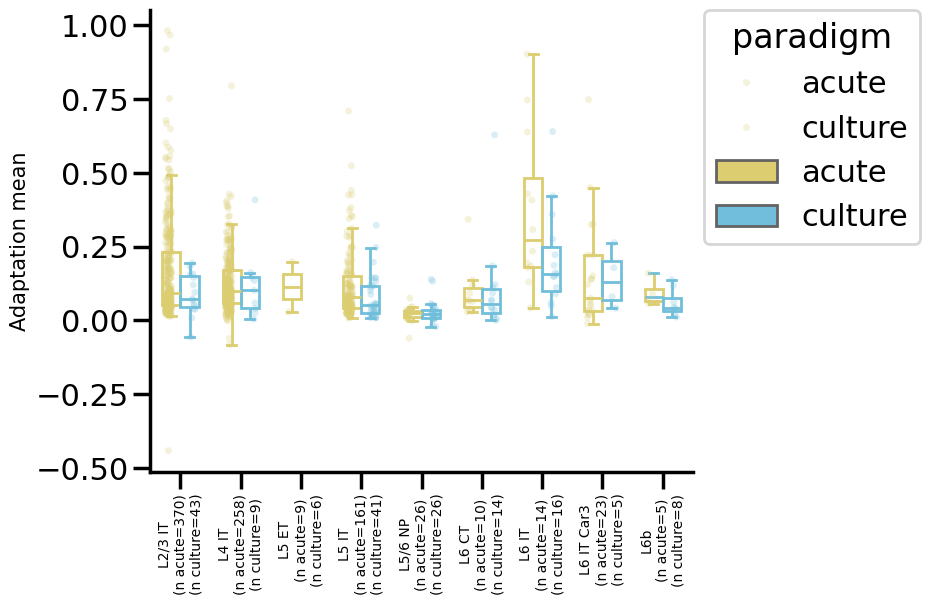

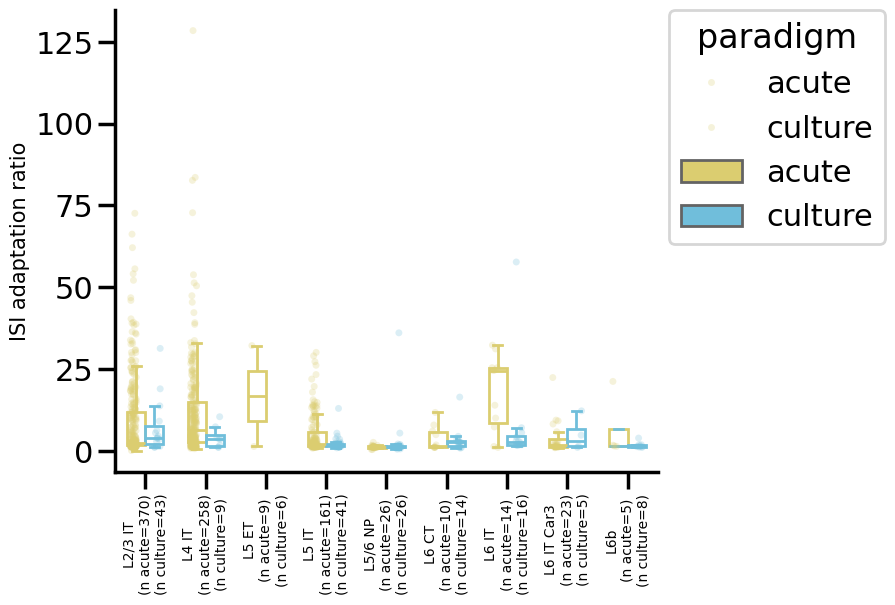

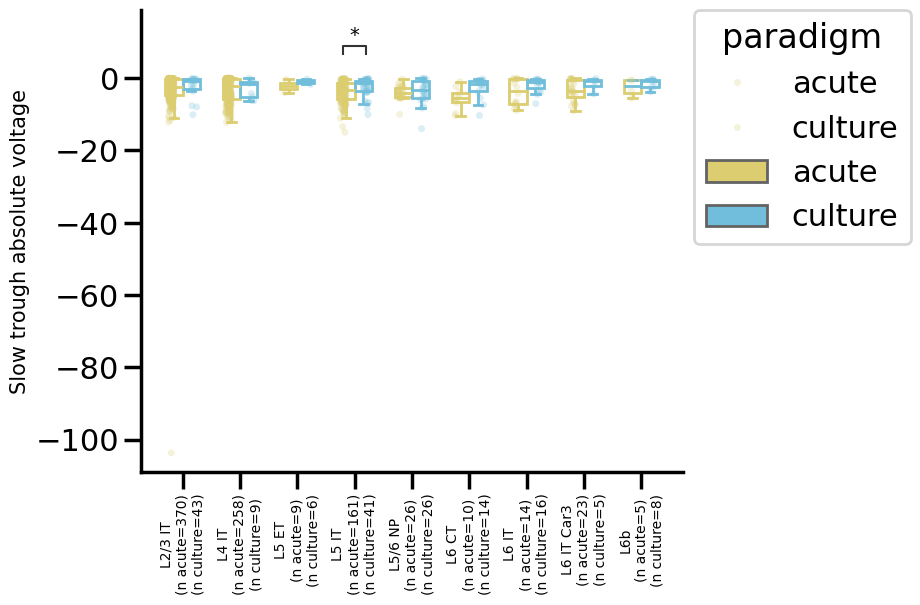

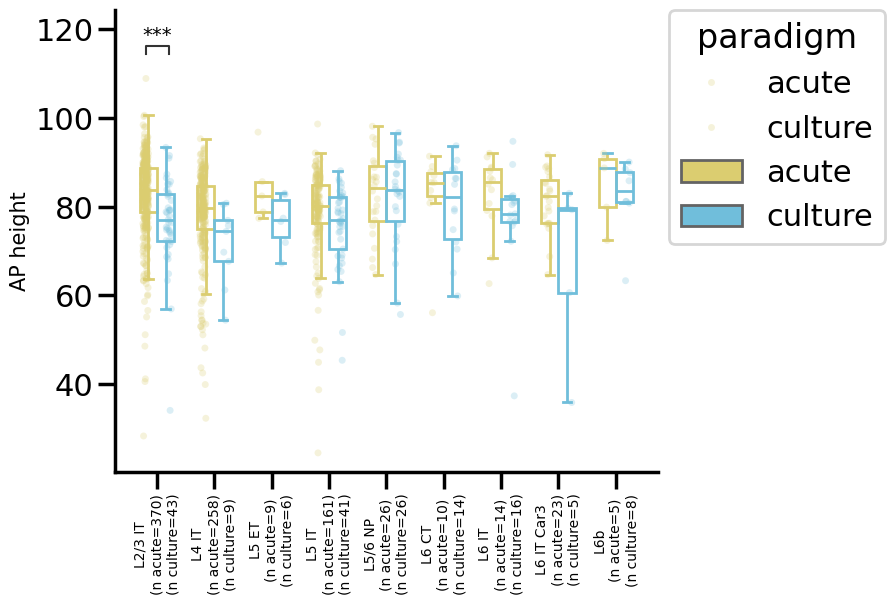

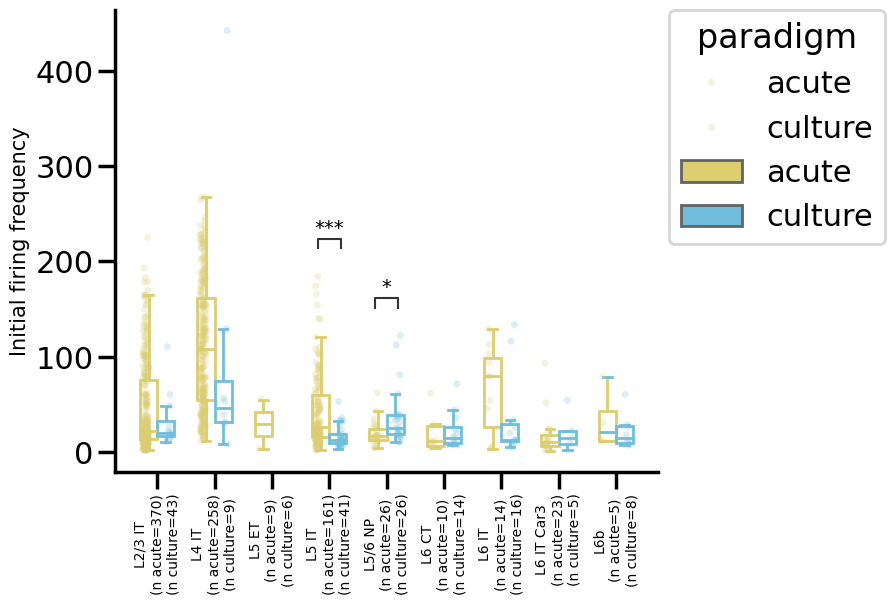

Boxplots with Mann-Whitney U stats saved.


In [30]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_paradigm_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'paradigm'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = group_order[hue_var]
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'acute')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'culture')])
                nobs.append("\n(n acute={})\n(n culture={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross paradigm box plots - ttype

In [31]:
# ttype x feature box plots

x_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
group_var = 't_type'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_1_acute vs. L2 IT_1_culture: Custom statistical test, P_val:3.307e-02


/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_6_acute vs. L5 IT_6_culture: Custom statistical test, P_val:2.731e-02
L5 IT_7_acute vs. L5 IT_7_culture: Custom statistical test, P_val:2.731e-02
L6 IT_1_acute vs. L6 IT_1_culture: Custom statistical test, P_val:3.307e-02
L4 IT_4_acute vs. L4 IT_4_culture: Custom statistical test, P_val:3.307e-02
L3 IT_13_acute vs. L3 IT_13_culture: Custom statistical test, P_val:4.667e-03
L4 IT_2_acute vs. L4 IT_2_culture: Custom statistical test, P_val:4.667e-03


/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_6_acute vs. L5 IT_6_culture: Custom statistical test, P_val:3.307e-02
L5/6 NP_1_acute vs. L5/6 NP_1_culture: Custom statistical test, P_val:3.307e-02
L2 IT_1_acute vs. L2 IT_1_culture: Custom statistical test, P_val:4.667e-03
L3 IT_10_acute vs. L3 IT_10_culture: Custom statistical test, P_val:4.667e-03
L3 IT_13_acute vs. L3 IT_13_culture: Custom statistical test, P_val:3.158e-02


... (12 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_6_acute vs. L5 IT_6_culture: Custom statistical test, P_val:2.731e-02


/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_1_acute vs. L2 IT_1_culture: Custom statistical test, P_val:3.307e-02


/tmp/ipykernel_108402/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


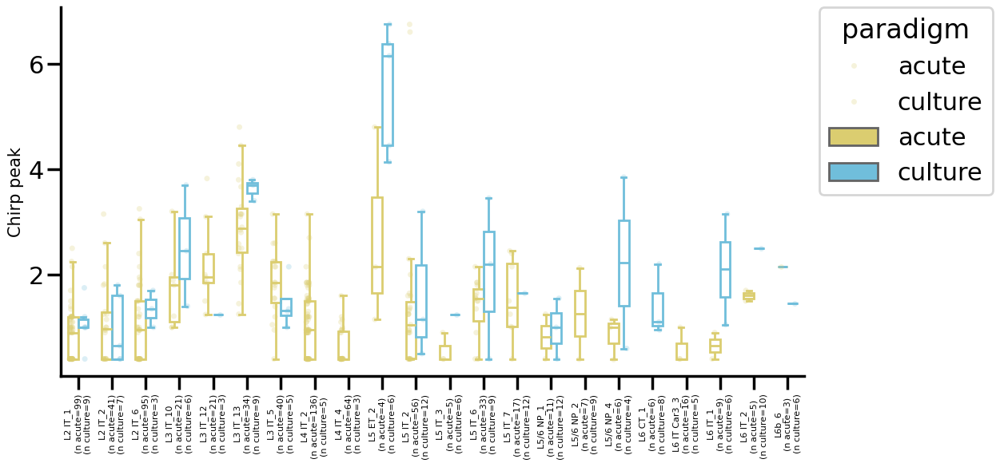

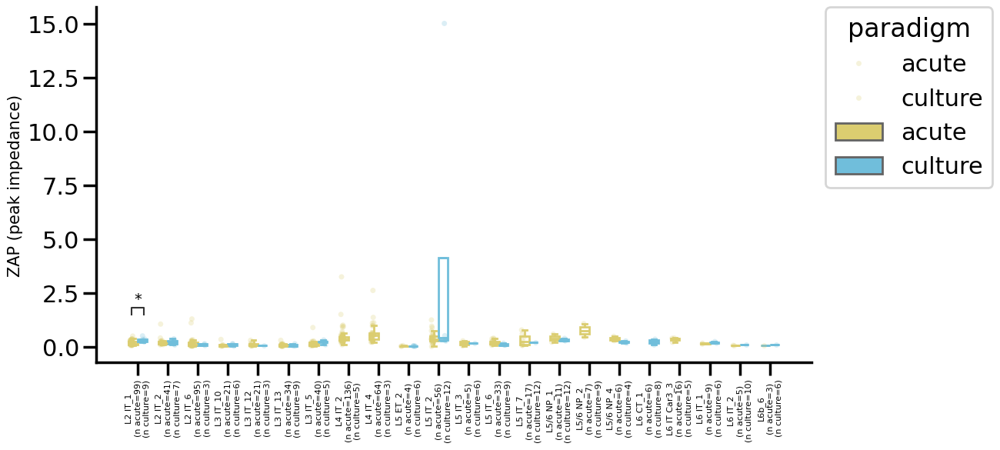

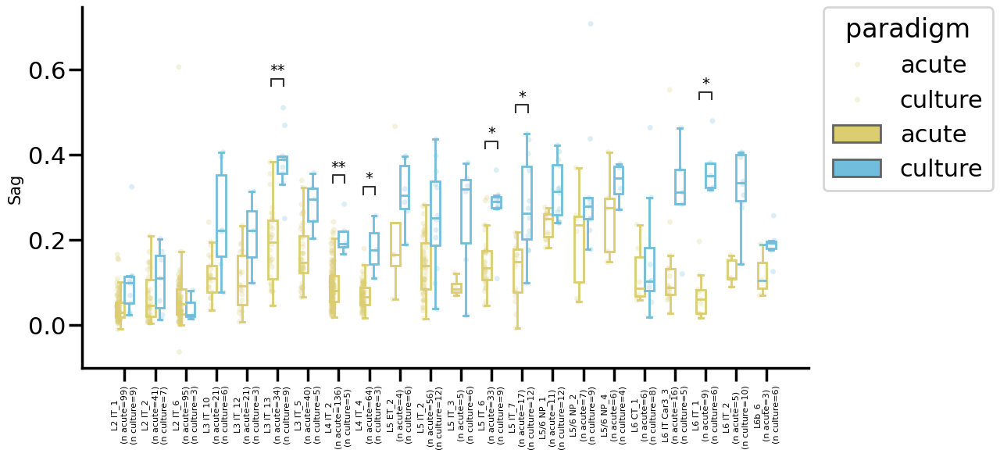

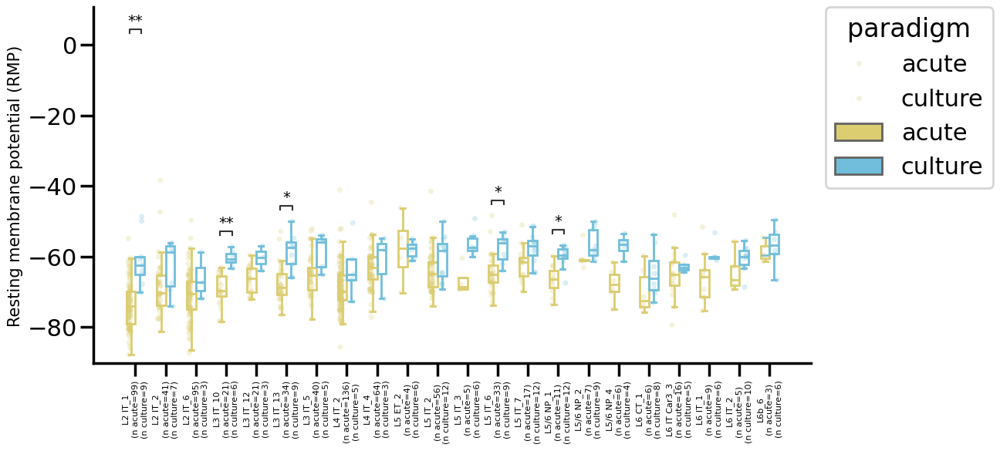

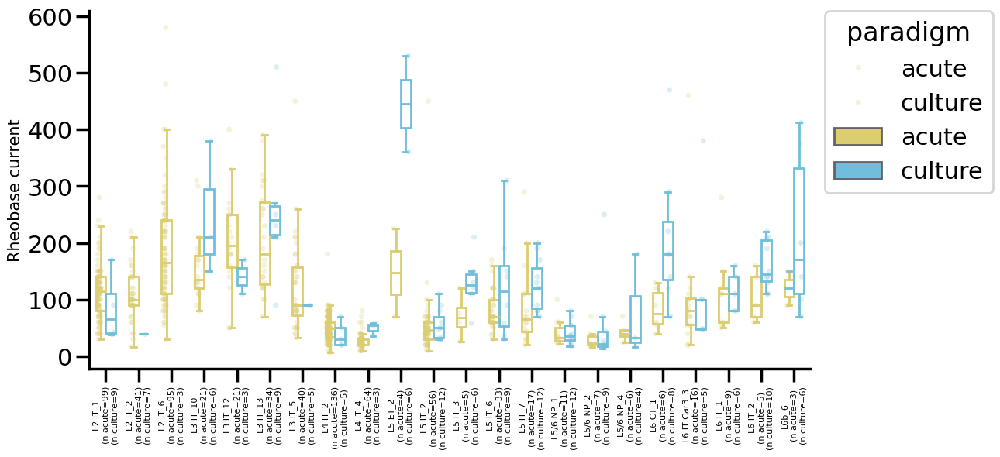

...

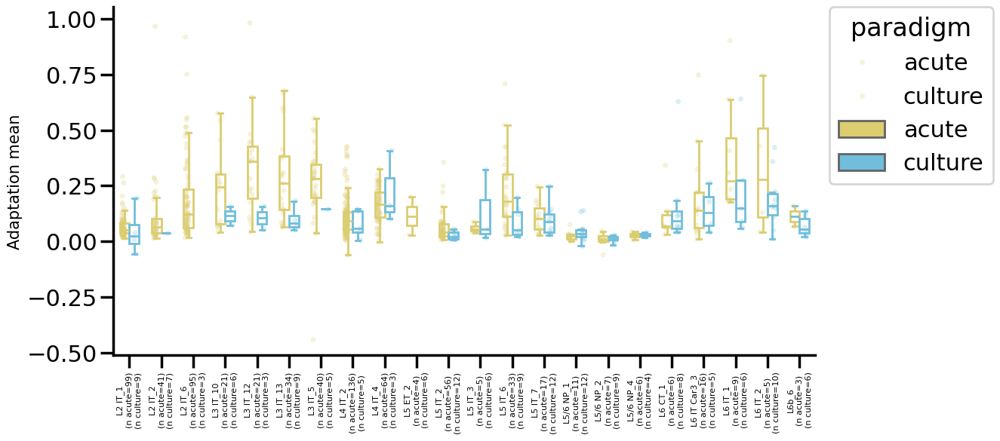

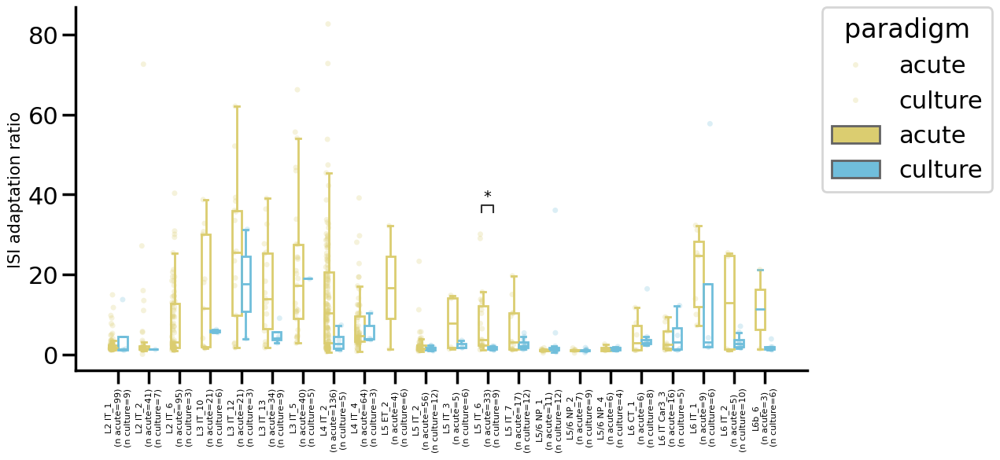

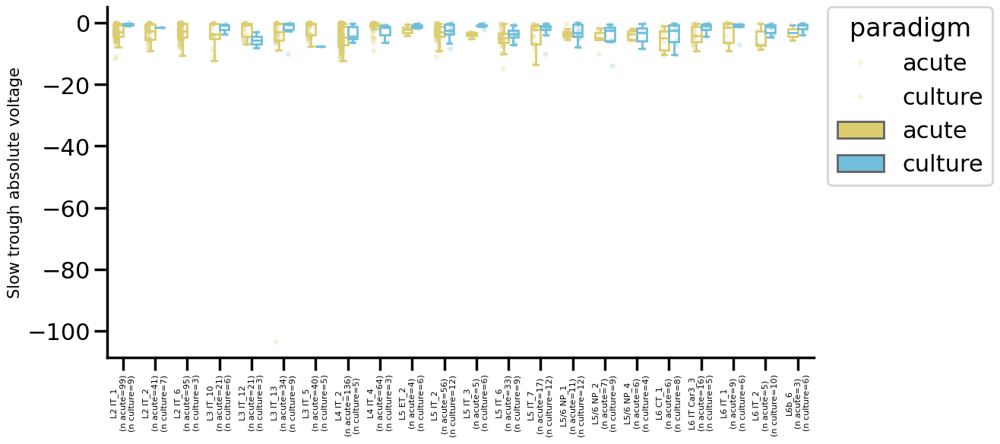

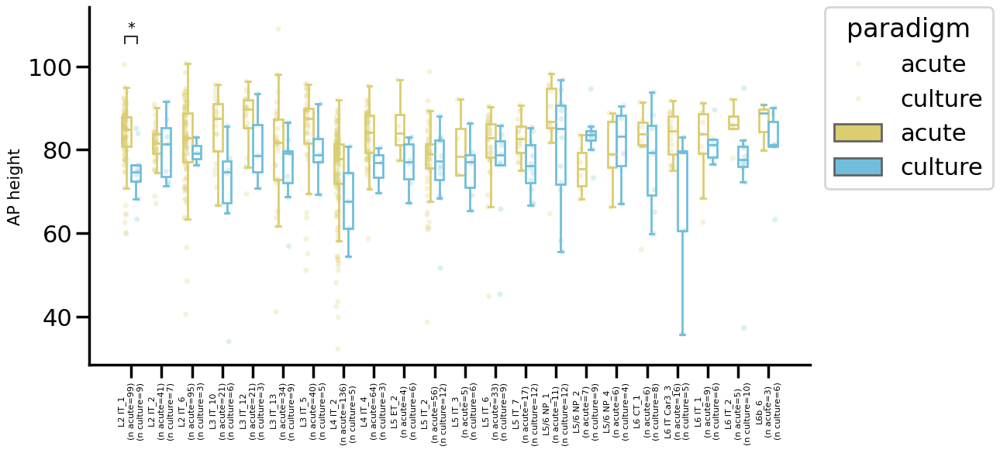

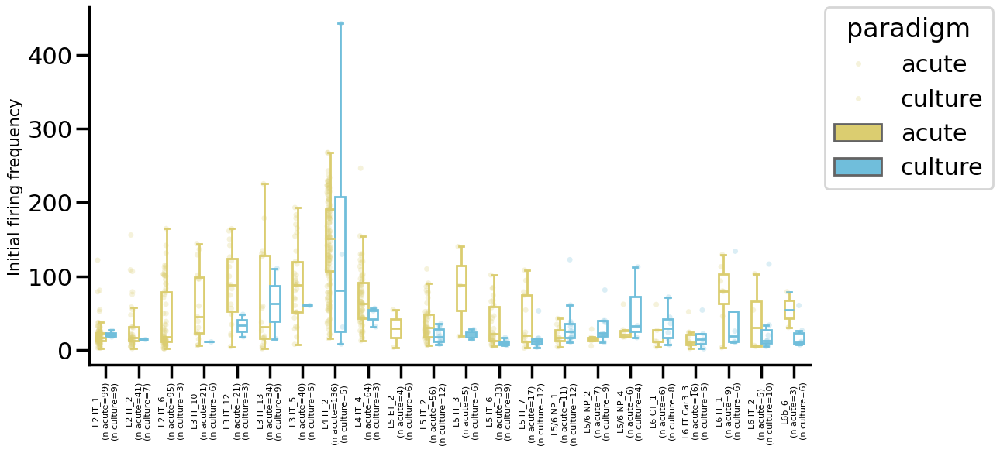

In [32]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_paradigm_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'paradigm'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['acute', 'culture']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(12,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'acute')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'culture')])
                nobs.append("\n(n acute={})\n(n culture={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=8)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Other metadata box plots - subclass

In [6]:
#add other metadata
additional_metadata_cols = ['group', 'age(yrs)', 'sex', 'medical_conditions'] #'paradigm',
additional_metadata = pd.read_csv(metadata_path, index_col='cell_id')[additional_metadata_cols]
additional_metadata = additional_metadata.rename(columns={'age(yrs)' : 'age'})

sorted_clean_data = sorted_clean_data.merge(additional_metadata, how='left', left_on='specimen_id', right_index=True)

#format metadata column labels 
sorted_clean_data['medical_conditions'] = sorted_clean_data['medical_conditions'].str.lower()
sorted_clean_data['sex'] = sorted_clean_data['sex'].replace('F or M?', 'unknown')
sorted_clean_data['age_bin'] = pd.cut(pd.to_numeric(sorted_clean_data['age'], errors='coerce'), bins=[18, 40, 60, 100], labels=['18-40', '40-60', '60-100'])
sorted_clean_data['age_bin'] = sorted_clean_data['age_bin'].astype('object').fillna('unknown')
sorted_clean_data['lobe_group'] = sorted_clean_data['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')


KW functions

In [7]:
def compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features):

    # STORE RESULTS
    kw_pvals = {}
    kw_hvals = {}
    dunn_tables = {}

    # KW per (subclass, feature)
    for subclass in x_var_order:
        sub_df = sorted_clean_data[sorted_clean_data[x_var] == subclass]

        for f in features:
            groups = [
                sub_df[sub_df[group_var] == g][f].dropna()
                for g in group_order
            ]

            groups = [g for g in groups if len(g) > 0]

            if len(groups) < 2:
                continue

            try:
                h, p = kruskal(*groups)
                kw_hvals[(subclass, f)] = h
                kw_pvals[(subclass, f)] = p
            except Exception as e:
                print(f"KW failed: {subclass}, {f} -> {e}")

    # FDR correction (over all subclass-feature tests)
    pvals = list(kw_pvals.values())
    rej, pvals_fdr = fdrcorrection(pvals, alpha=0.05)

    kw_pvals_fdr = dict(zip(kw_pvals.keys(), pvals_fdr))
    kw_rejected = dict(zip(kw_pvals.keys(), rej))

    # Dunn post hoc ONLY for significant KW results
    # (within each subclass × feature)
    for (subclass, f), sig in kw_rejected.items():

        if not sig:
            continue

        sub_df = sorted_clean_data[sorted_clean_data[x_var] == subclass]
        sub_df = sub_df[sub_df[group_var].isin(group_order)]

        try:
            dunn = posthoc_dunn(
                sub_df,
                val_col=f,
                group_col=group_var,
                p_adjust='fdr_bh'
            )
            dunn_tables[(subclass, f)] = dunn

        except Exception as e:
            print(f"Dunn failed: {subclass}, {f} -> {e}")

    return kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables

In [8]:
def get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected):

    rows = []
    for (subclass, feature), p in kw_pvals.items():
        rows.append({
            'subclass': subclass,
            'feature': feature,
            'kw_H': kw_hvals.get((subclass, feature)),
            'pval_raw': p,
            'pval_fdr': kw_pvals_fdr.get((subclass, feature)),
            'rejected_fdr': kw_rejected.get((subclass, feature)),
        })

    kw_stats_df = pd.DataFrame(rows)
    kw_stats_df = kw_stats_df.sort_values(['subclass', 'pval_fdr'], ascending=True)

    return kw_stats_df


In [9]:
def get_dunn_stats_df(dunn_tables):
    dunn_rows = []

    for (subclass, feature), dunn_df in dunn_tables.items():

        # iterate upper triangle only
        for i, g1 in enumerate(dunn_df.index):

            for j, g2 in enumerate(dunn_df.columns):

                if j <= i:
                    continue

                dunn_rows.append({
                    'subclass': subclass,
                    'feature': feature,
                    'group1': g1,
                    'group2': g2,
                    'dunn_pval_fdr': dunn_df.loc[g1, g2]
                })

    dunn_stats_df = pd.DataFrame(dunn_rows)
    return dunn_stats_df

In [10]:
def plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_order, y_vars, hue_var, hue_order, palette, dunn_tables, figsize=(8, 6)):

    # x_var, hue_var cleanup
    this_sorted_clean_data = sorted_clean_data.copy()

    # strip old categorical behavior completely
    this_sorted_clean_data[x_var] = this_sorted_clean_data[x_var].astype(str)
    this_sorted_clean_data[hue_var] = this_sorted_clean_data[hue_var].astype(str)

    # enforce clean order explicitly
    this_sorted_clean_data[x_var] = pd.Categorical( this_sorted_clean_data[x_var], categories=x_order, ordered=True )
    this_sorted_clean_data[hue_var] = pd.Categorical( this_sorted_clean_data[hue_var], categories=hue_order, ordered=True )
    this_sorted_clean_data = this_sorted_clean_data[ this_sorted_clean_data[x_var].isin(x_order) ]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)

        with PdfPages(fig_path) as pdf:

            for y_var in y_vars:

                fig, ax = plt.subplots(
                    nrows=1,
                    ncols=1,
                    figsize=figsize,
                    sharex=True,
                    gridspec_kw={'wspace': 0, 'hspace': 0.1}
                )

                sns.set_context('poster')

                strip = sns.stripplot( data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order, hue_order=hue_order, palette=palette, dodge=True, alpha=0.75, size=4, ax=ax )
                sns.boxplot( data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order, hue_order=hue_order, palette=palette, showfliers=False, width=0.6, linewidth=1, saturation=1, ax=ax )

                # formatting
                format_box_plot(ax)
                sns.despine(ax=ax, right=True, top=True)

                ax.set_xlabel("")
                ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)

                # tighter category spacing
                # ax.margins(x=0.01)

                # remove auto legend
                if ax.legend_ is not None:
                    ax.legend_.remove()

                # custom legend handles
                custom_handles = [
                    Line2D(
                        [0], [0],
                        marker='o',
                        color='w',
                        label=group,
                        markerfacecolor=palette[i],
                        markeredgecolor=palette[i],
                        markersize=8,
                        alpha=0.7
                    )
                    for i, group in enumerate(hue_order)
                ]

                ax.legend(
                    handles=custom_handles,
                    title=hue_var,
                    bbox_to_anchor=(1.02, 1),
                    loc='upper left',
                    borderaxespad=0
                )

                # rotate labels
                ax.tick_params(axis='x', rotation=90, labelsize=10)

                #add num observations per x_var
                nobs = []
                for s in x_order:
                    counts = []
                    for h in hue_order:
                        n = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == h) & (~this_sorted_clean_data[y_var].isna())])
                        counts.append(f"({h}={n})")
                    label = "\n".join(counts)
                    nobs.append(label)

                new_x_tick_labels = [x_order[i] + "\n" + nobs[i] for i in range(len(x_order))]
                ax.set_xticklabels(new_x_tick_labels)
                ax.tick_params(axis='x', rotation=90, labelsize=10)


                # ADD DUNN SIGNIFICANCE
                pairs = []
                pvals = []

                for subclass in x_order:
                    key = (subclass, y_var)

                    if key not in dunn_tables:
                        continue

                    dunn = dunn_tables[key]

                    mask = np.tril(np.ones(dunn.shape), k=0).astype(bool)
                    dunn = dunn.copy()
                    dunn[mask] = np.nan

                    melted = dunn.melt(ignore_index=False).reset_index()
                    melted = melted.dropna()
                    melted = melted[melted['value'] < 0.05]

                    for _, row in melted.iterrows():
                        pairs.append([
                            (subclass, row['index']),
                            (subclass, row['variable'])
                        ])
                        pvals.append(row['value'])

                if len(pairs) > 0:
                    annot = Annotator(
                        ax,
                        pairs,
                        data=this_sorted_clean_data,
                        x=x_var,
                        y=y_var,
                        hue=hue_var,
                        order=x_order,
                        hue_order=hue_order
                    )

                    annot.configure(
                        text_format="star",
                        loc="inside",
                        fontsize=14
                    )

                    annot.set_pvalues_and_annotate(pvals)

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight', dpi=600)
                plt.show()

            plt.close(fig)

MW functions

In [11]:
def compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features):

    n_min_cells = 3
    combo_counts = sorted_clean_data.groupby([x_var, group_var]).size().unstack(fill_value=0)
    groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

    # Collect p-values and stats by (subclass, feature)
    mw_pvals = dict()
    mw_stats = dict()

    for group in groups:
        sub_data = sorted_clean_data[sorted_clean_data[x_var] == group]

        for f in features:
            group1 = sub_data[sub_data[group_var] == group1_label][f].dropna()
            group2 = sub_data[sub_data[group_var] == group2_label][f].dropna()

            if group1.empty or group2.empty:
                continue

            try:
                stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
                mw_pvals[(group, f)] = pval
                mw_stats[(group, f)] = stat
            except ValueError as e:
                print(f'Mann-Whitney failed for {group}, {f}: {e}')

    # FDR correction across all tests (subclass-feature pairs)
    mw_pvals_list = list(mw_pvals.values())
    mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
    mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))

    return mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected


In [12]:
def get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected):

    #Save stats
    rows = []
    for (subclass, feature), pval in mw_pvals.items():
        rows.append({
            'subclass': subclass,
            'feature': feature,
            'mw_stat': mw_stats.get((subclass, feature)),
            'pval_raw': pval,
            'pval_fdr': mw_pvals_fdr.get((subclass, feature)),
            'rejected_pval_fdr': mw_rejected.get((subclass, feature)),
            'group1': group1_label,
            'group2': group2_label
        })

    mw_stats_df = pd.DataFrame(rows)
    if len(mw_stats_df)>0:
        mw_stats_df = mw_stats_df.sort_values( ['subclass', 'pval_fdr'], ascending=[True, True])
    return mw_stats_df


In [20]:
def plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_order, y_vars, hue_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected):

    # x_var, hue_var cleanup
    this_sorted_clean_data = sorted_clean_data.copy()

    # strip old categorical behavior completely
    this_sorted_clean_data[x_var] = this_sorted_clean_data[x_var].astype(str)
    this_sorted_clean_data[hue_var] = this_sorted_clean_data[hue_var].astype(str)

    # enforce clean order explicitly
    this_sorted_clean_data[x_var] = pd.Categorical( this_sorted_clean_data[x_var], categories=x_order, ordered=True )
    this_sorted_clean_data[hue_var] = pd.Categorical( this_sorted_clean_data[hue_var], categories=[group1_label, group2_label], ordered=True )
    this_sorted_clean_data = this_sorted_clean_data[ this_sorted_clean_data[x_var].isin(x_order) ]

    print(len(this_sorted_clean_data))

    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)

        with PdfPages(fig_path) as pdf:
            for y_var in y_vars:
                fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

                sns.set_context('poster')
                strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
                sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)

                #format 
                format_box_plot(ax) #clear fill of box plots, color edges
                sns.despine(right=True, top=True)
                ax.set_xlabel("")
                ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)

                # remove auto legend
                if ax.legend_ is not None:
                    ax.legend_.remove()

                # custom legend handles
                custom_handles = [
                    Line2D(
                        [0], [0],
                        marker='o',
                        color='w',
                        label=group,
                        markerfacecolor=palette[i],
                        markeredgecolor=palette[i],
                        markersize=8,
                        alpha=0.7
                    )
                    for i, group in enumerate([group1_label, group2_label])
                ]

                ax.legend(
                    handles=custom_handles,
                    title=hue_var,
                    bbox_to_anchor=(1.02, 1),
                    loc='upper left',
                    borderaxespad=0
                )


                #add num observations per x_var
                nobs = []
                for s in x_order:
                    nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == group1_label) & (~this_sorted_clean_data[y_var].isna())])
                    nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == group2_label) & (~this_sorted_clean_data[y_var].isna())])
                    nobs.append("\n(n {}={})\n(n {}={})".format(group1_label, nT, group2_label, nO))
                new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
                ax.set_xticklabels(new_x_tick_labels)
                ax.tick_params(axis='x', rotation=90, labelsize=10)

                # Annotate p-values
                pairs = []
                p_values = []
                for subclass in x_order:
                    key = (subclass, y_var)
                    if key in mw_pvals_fdr:
                        pval = mw_pvals_fdr[key]
                        sig = mw_rejected.get(key, False)
                        if sig:
                            pairs.append([(subclass, group1_label), (subclass, group2_label)])  # or vice versa
                            p_values.append(pval)

                # Only annotate if there are significant results
                if pairs:
                    annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                    annotator.configure(text_format="star", loc="inside", fontsize=14)
                    annotator.set_pvalues_and_annotate(p_values)

                # fig.tight_layout()
                pdf.savefig(dpi=600, bbox_inches='tight')
            plt.show()
            plt.clf
        

Cross disease state box plots - subclass

/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


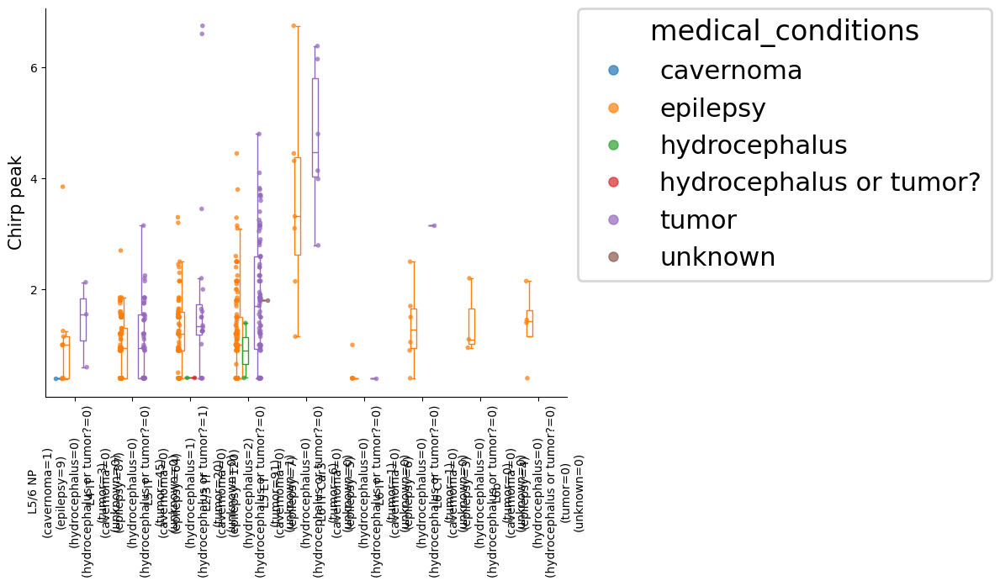

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


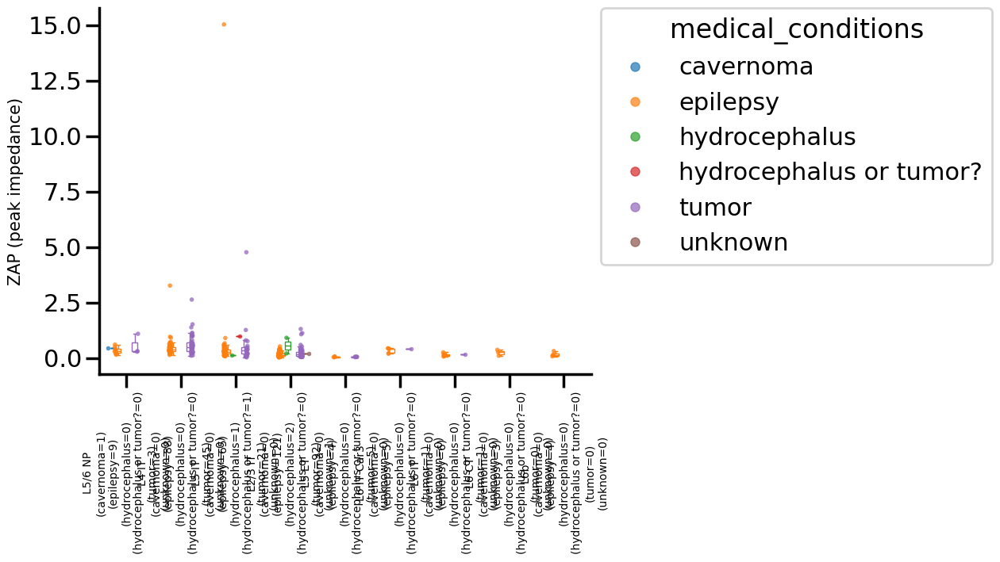

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_epilepsy vs. L4 IT_tumor: Custom statistical test, P_val:3.955e-05
L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:1.222e-13
L6 IT_epilepsy vs. L6 IT_tumor: Custom statistical test, P_val:8.059e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


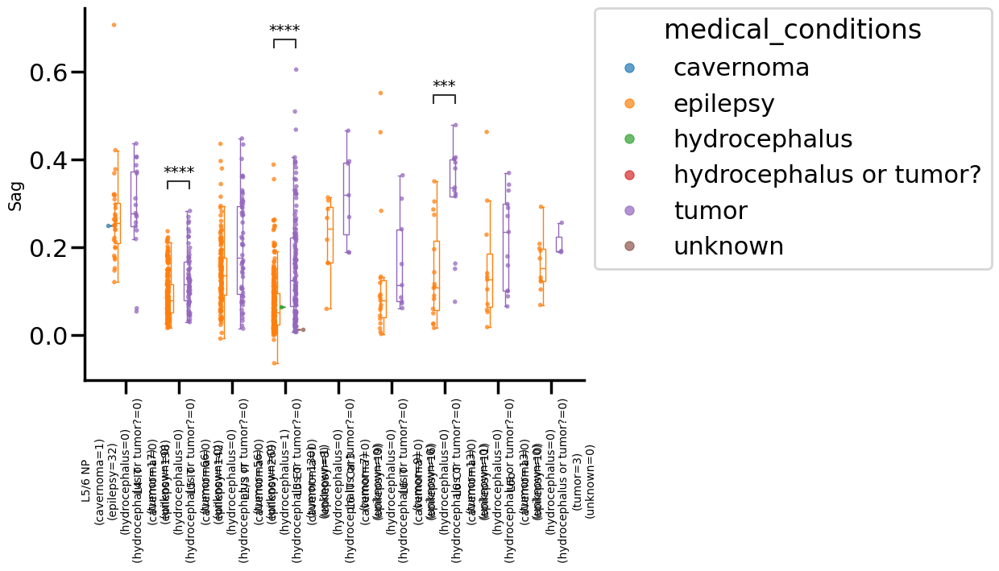

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


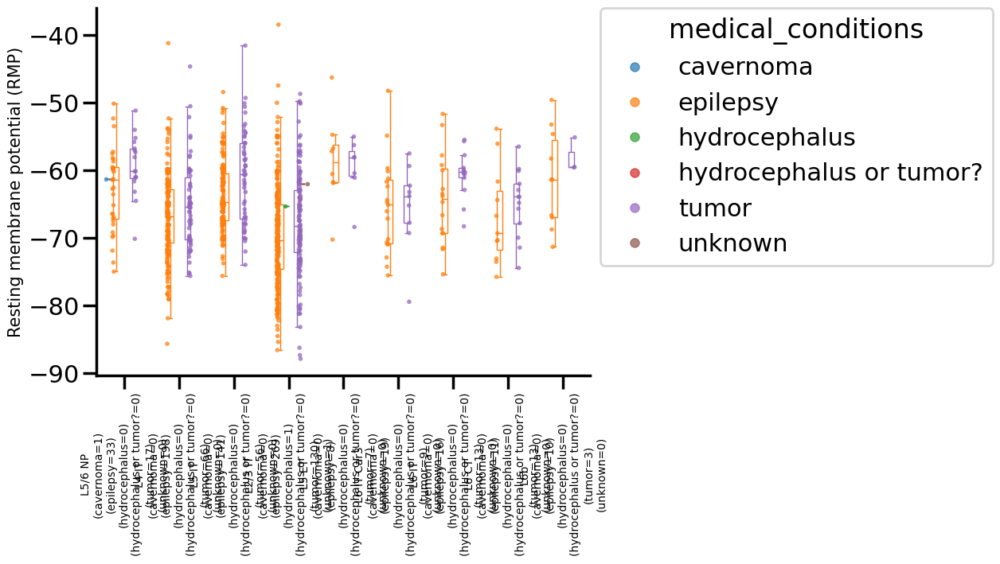

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


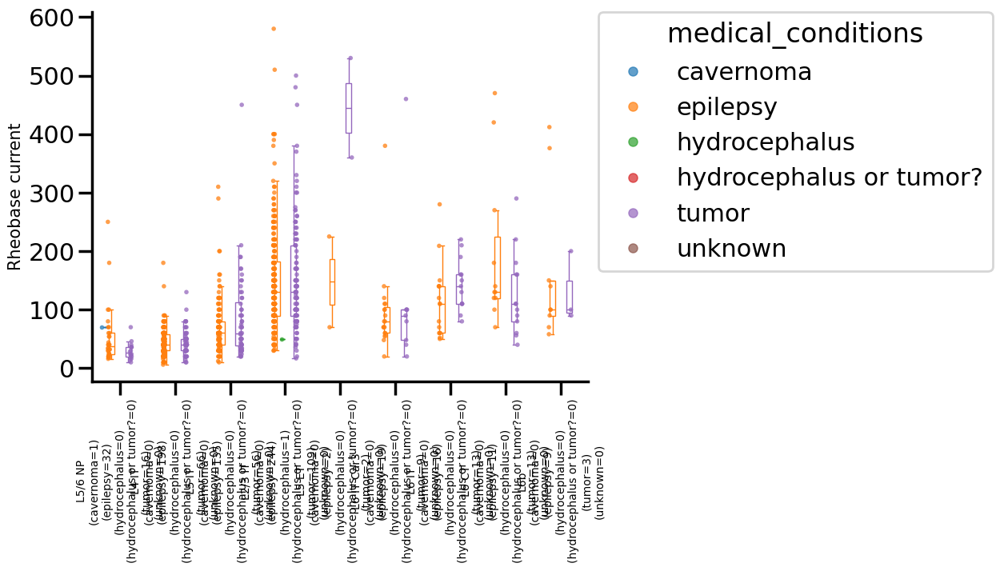

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


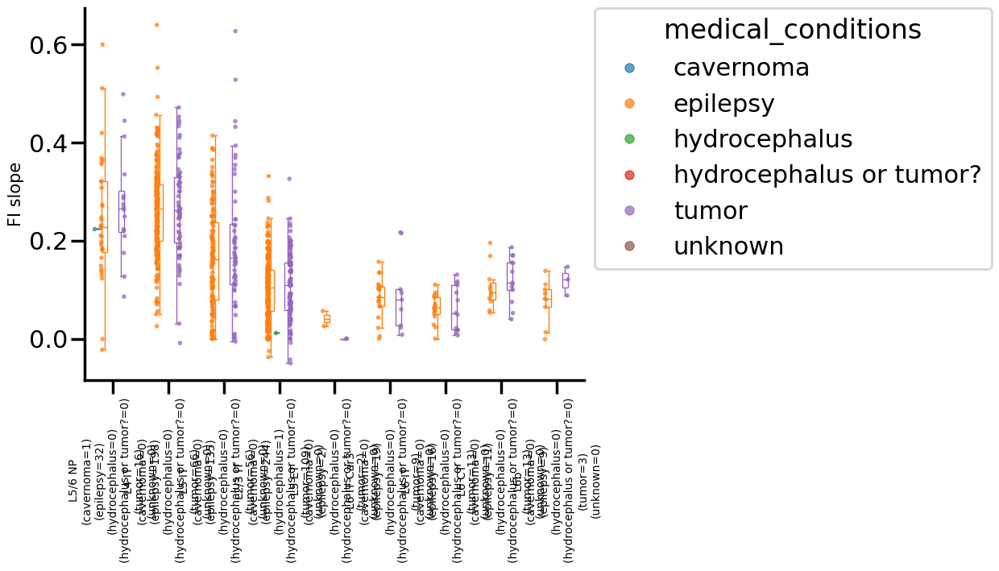

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


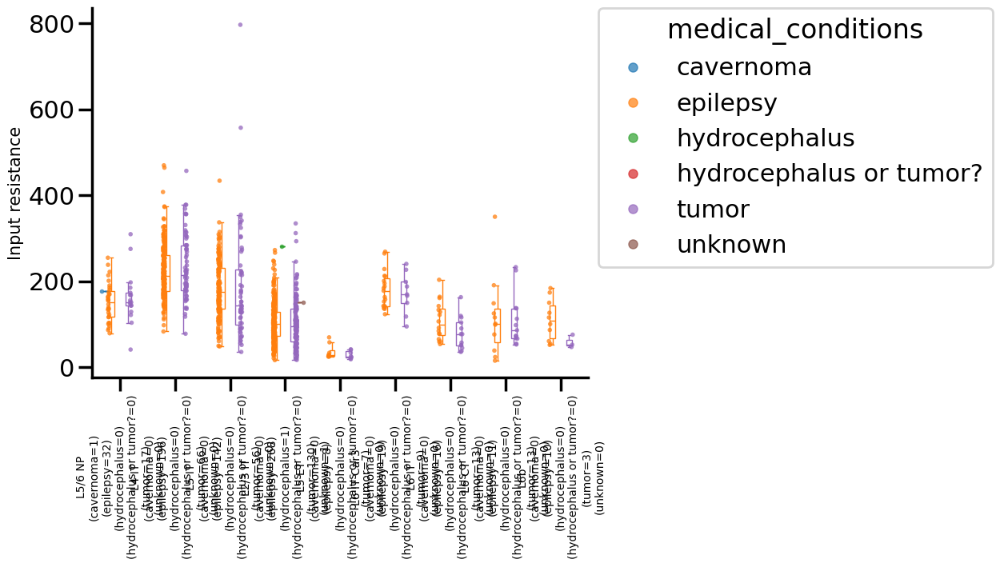

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:3.380e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


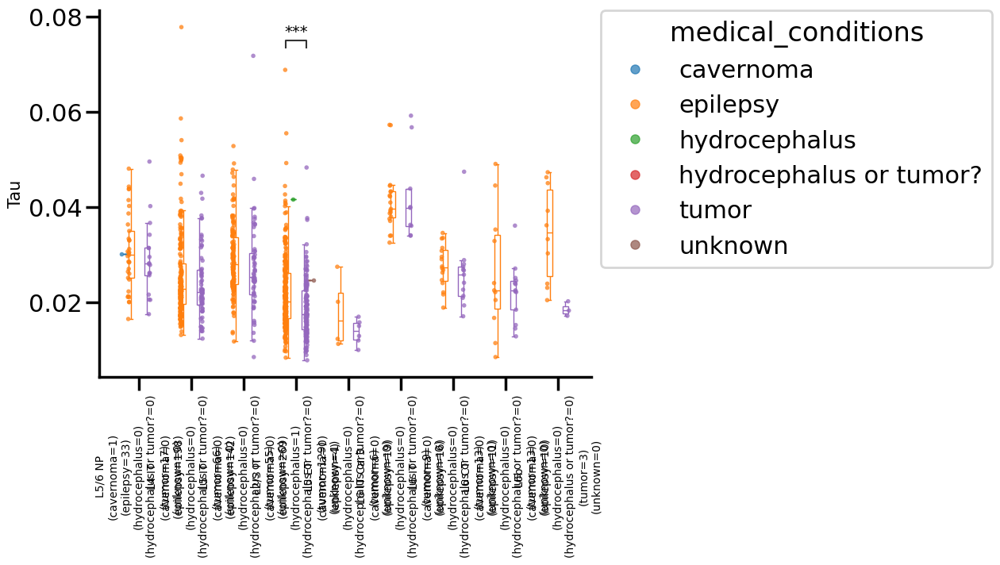

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


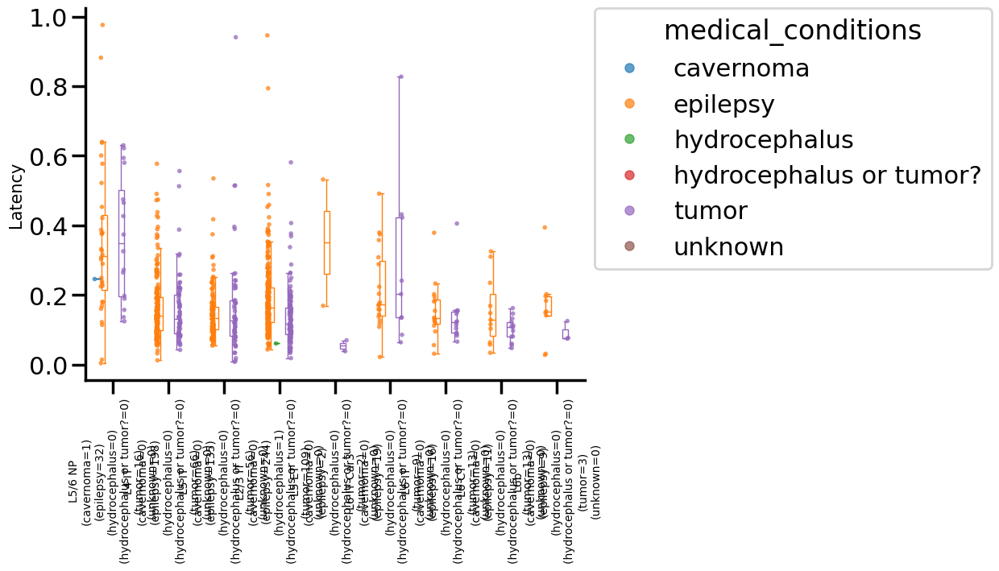

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


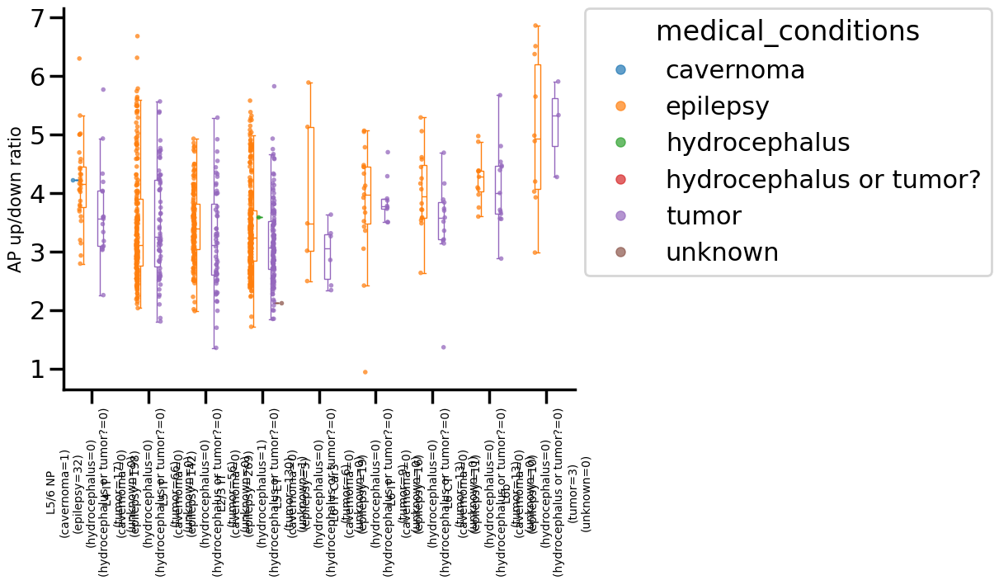

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


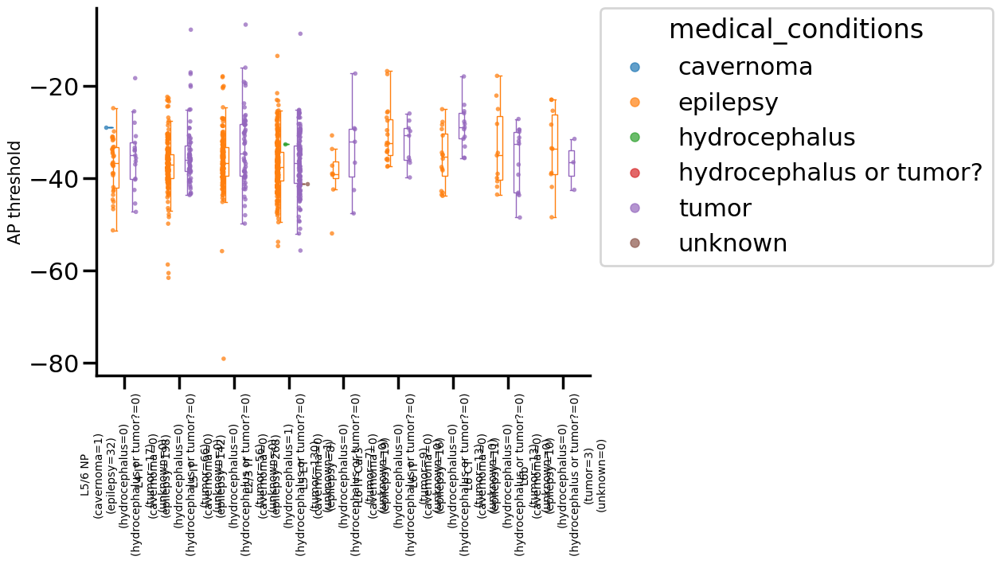

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


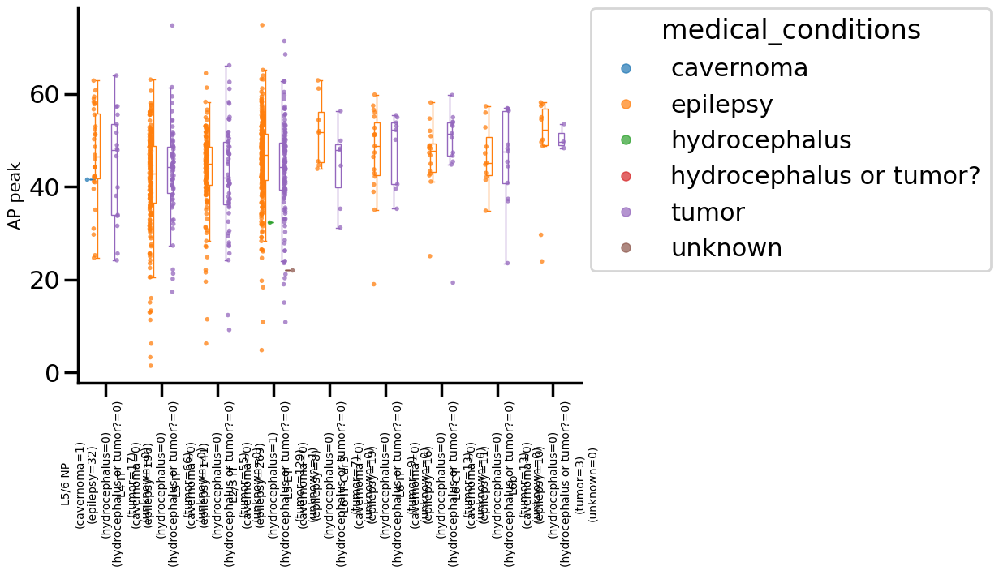

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:1.535e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


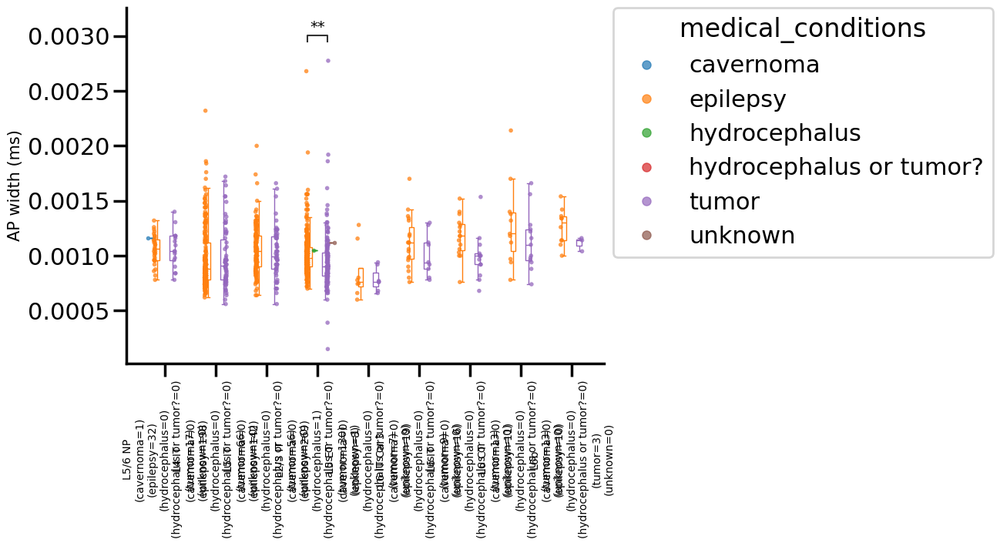

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


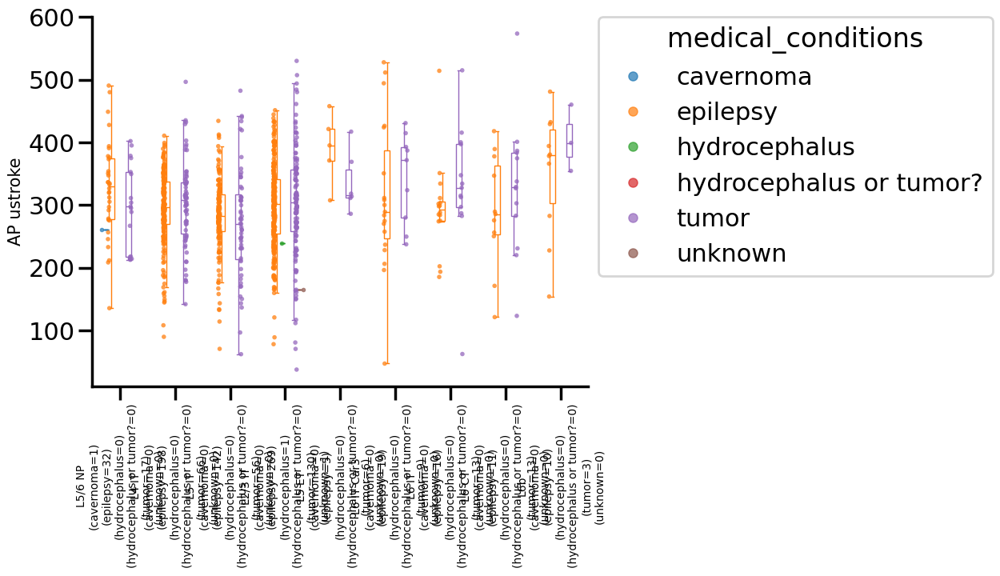

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT_epilepsy vs. L6 IT_tumor: Custom statistical test, P_val:3.427e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


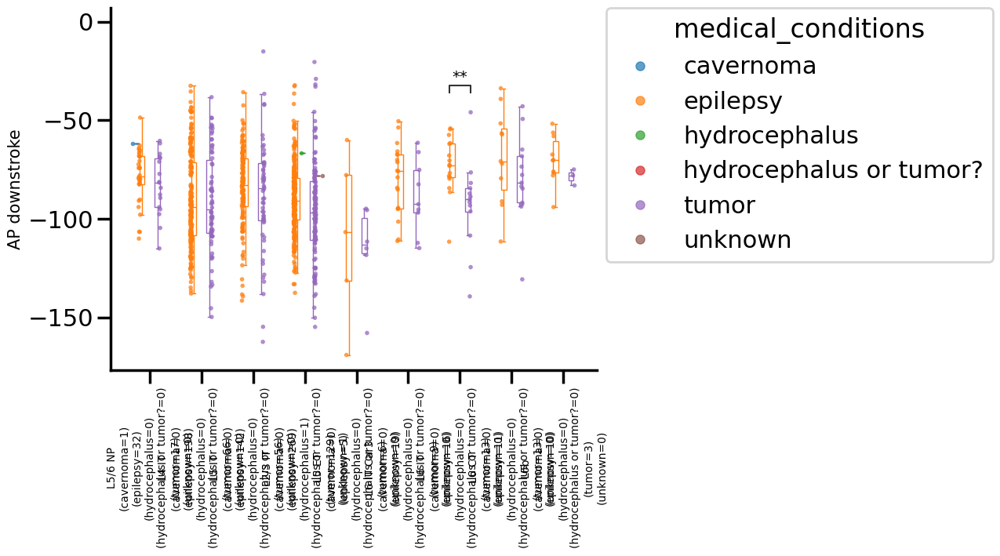

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


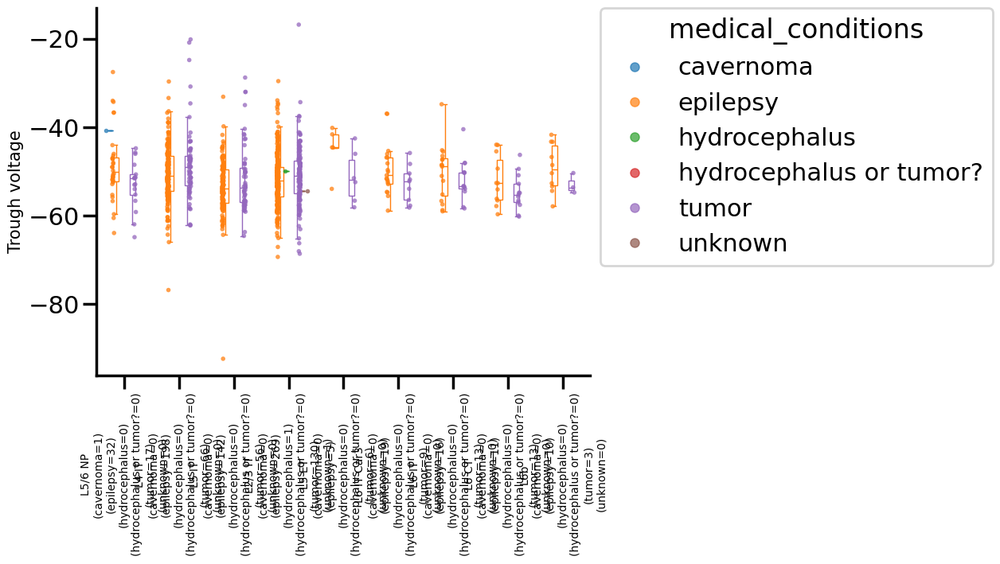

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


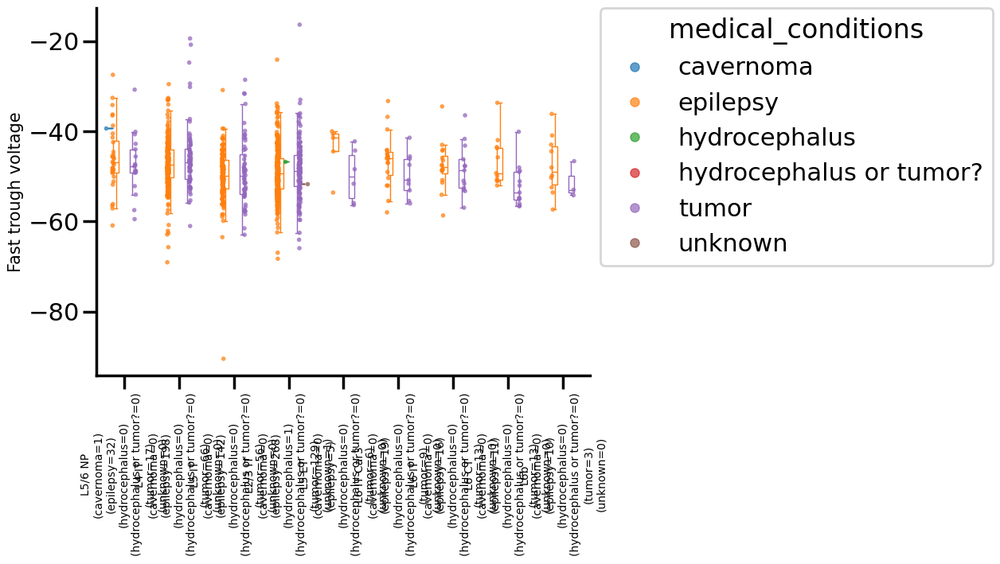

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


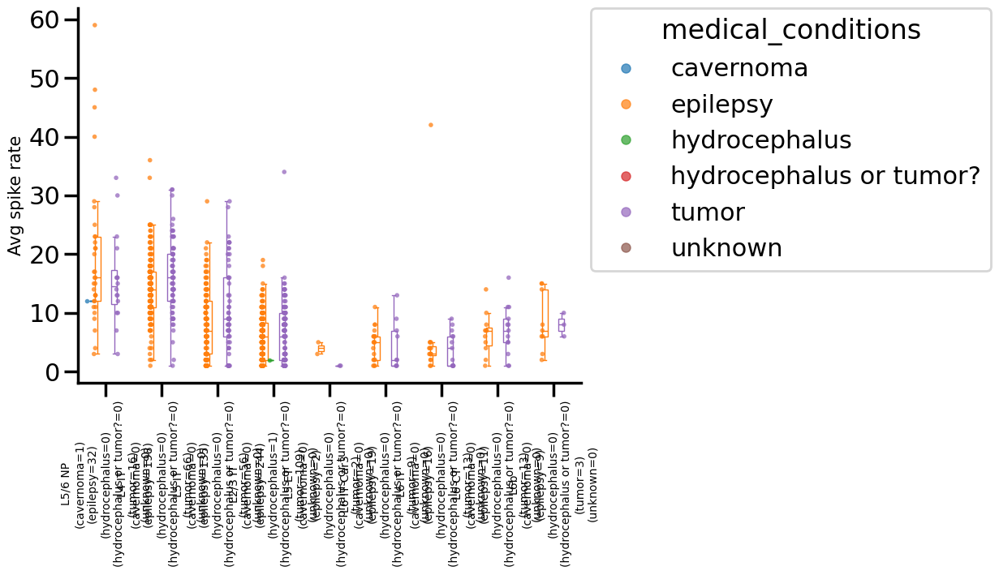

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


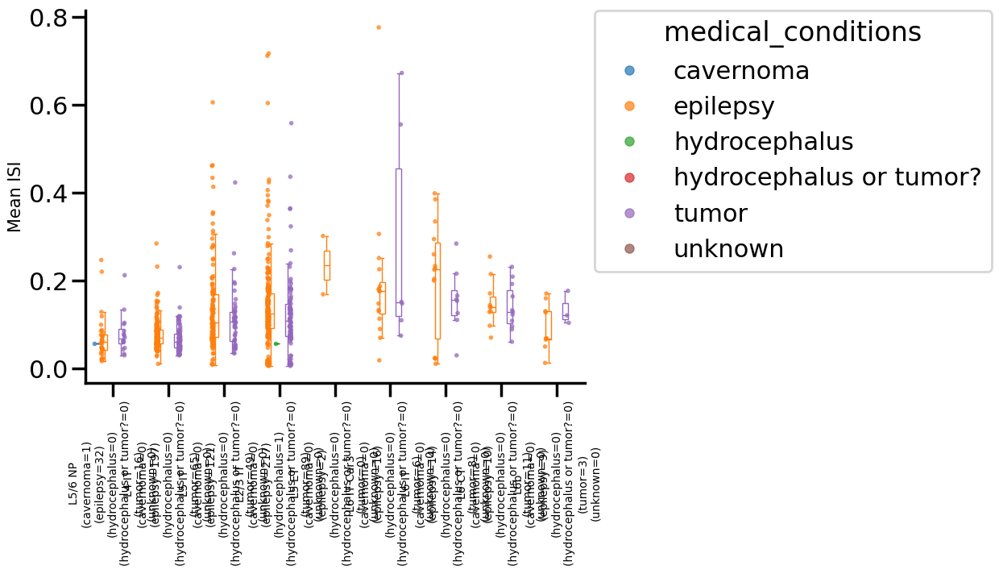

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


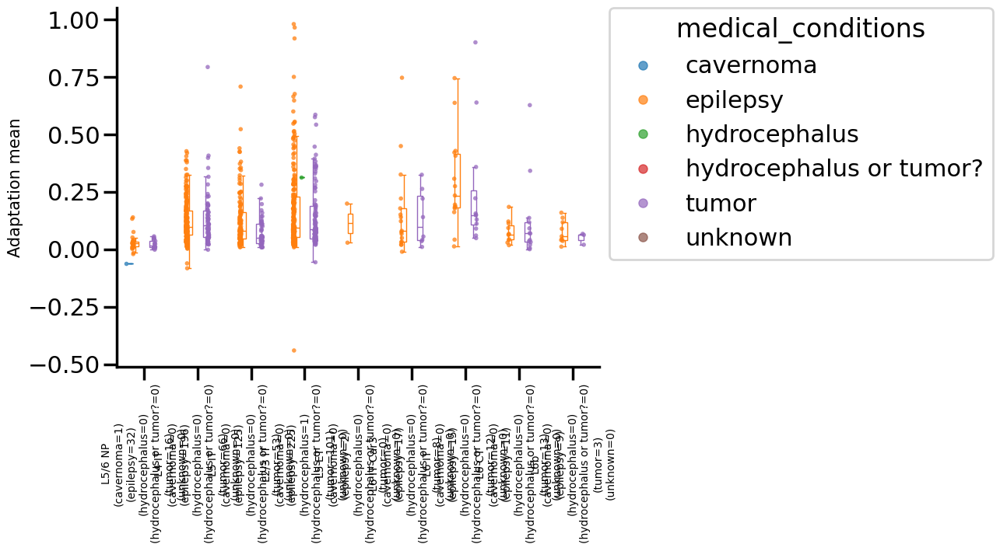

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


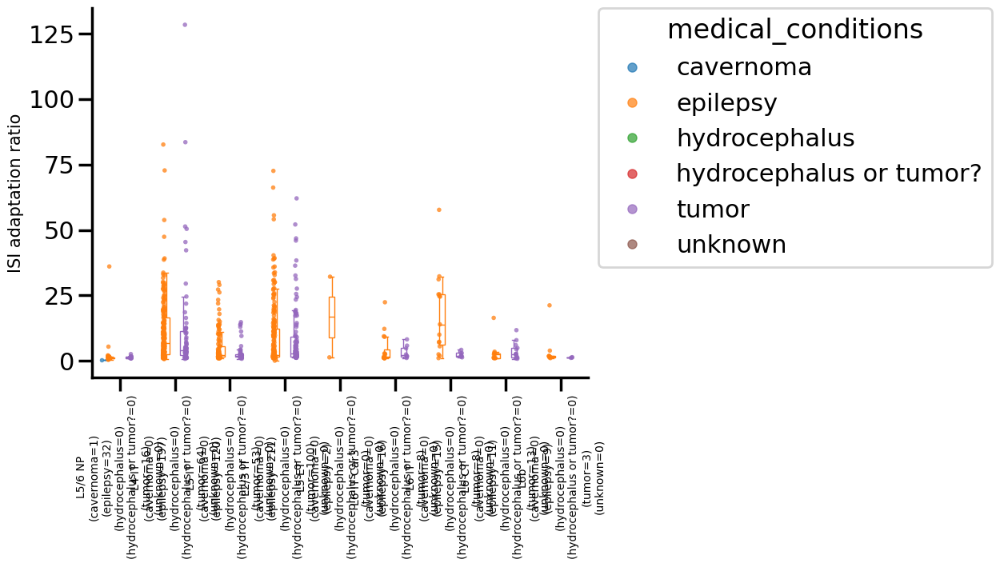

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP_epilepsy vs. L5/6 NP_tumor: Custom statistical test, P_val:1.220e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


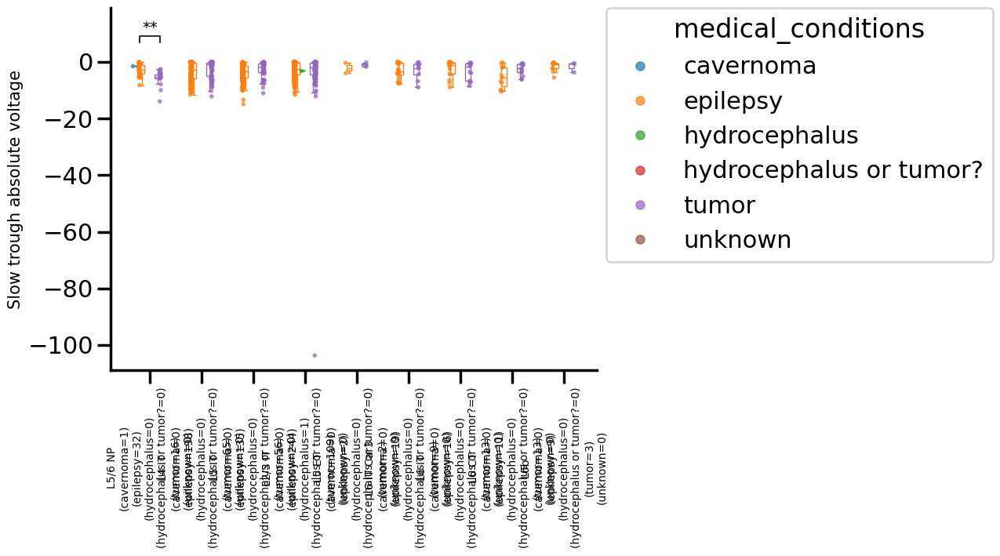

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:6.472e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


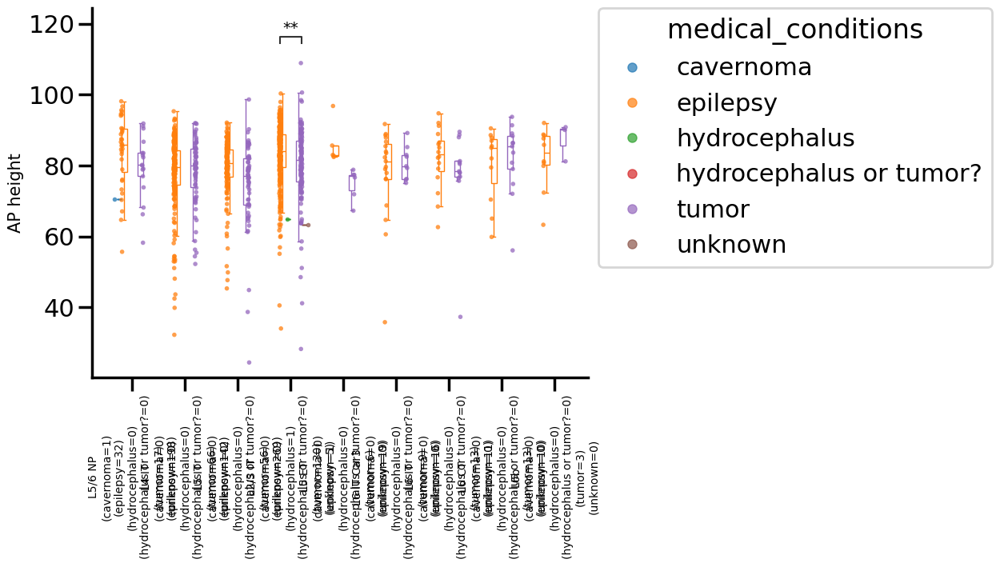

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


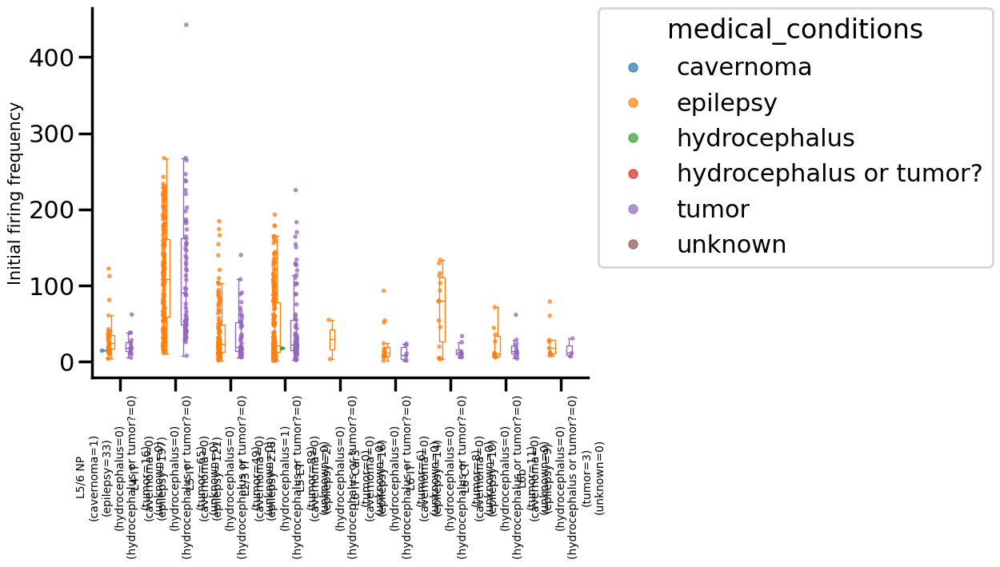

In [14]:
#compute KW - FDR - Dunn stats for all medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'medical_conditions'
group_order = sorted_clean_data[group_var].unique().tolist()

features = feature_cols.copy()
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing single cells with `hydrocephalus`, `unknown`, and `hydrocephalus or tumor?` conditions 

1044


/tmp/ipykernel_1139051/2125135880.py:25: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/2125135880.py:26: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/2125135880.py:25: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

/tmp/ipykernel_1139051/2125135880.py:25: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/2125135880.py:26: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/2125135880.py:25: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

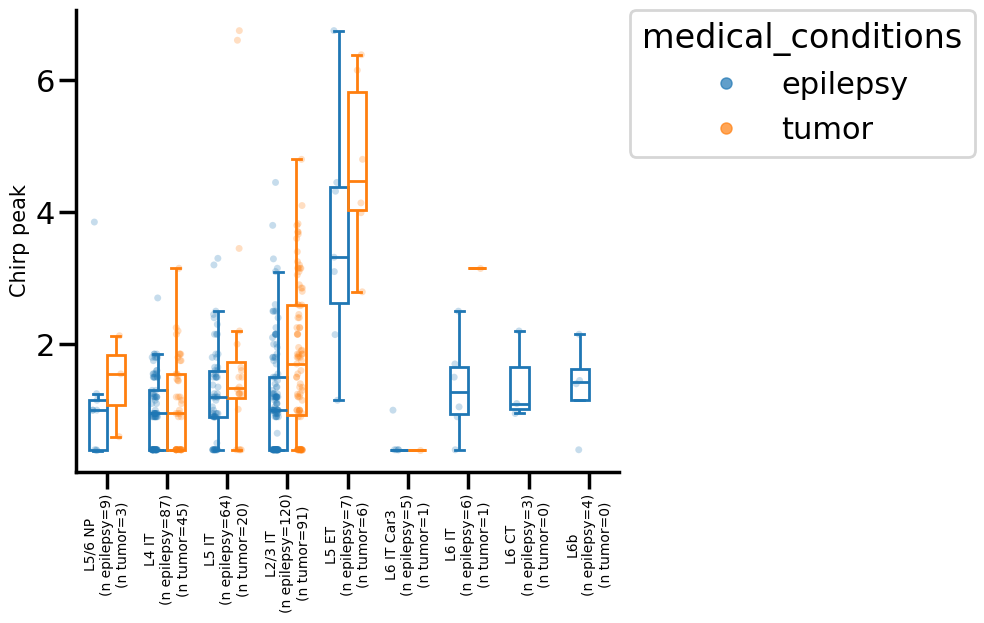

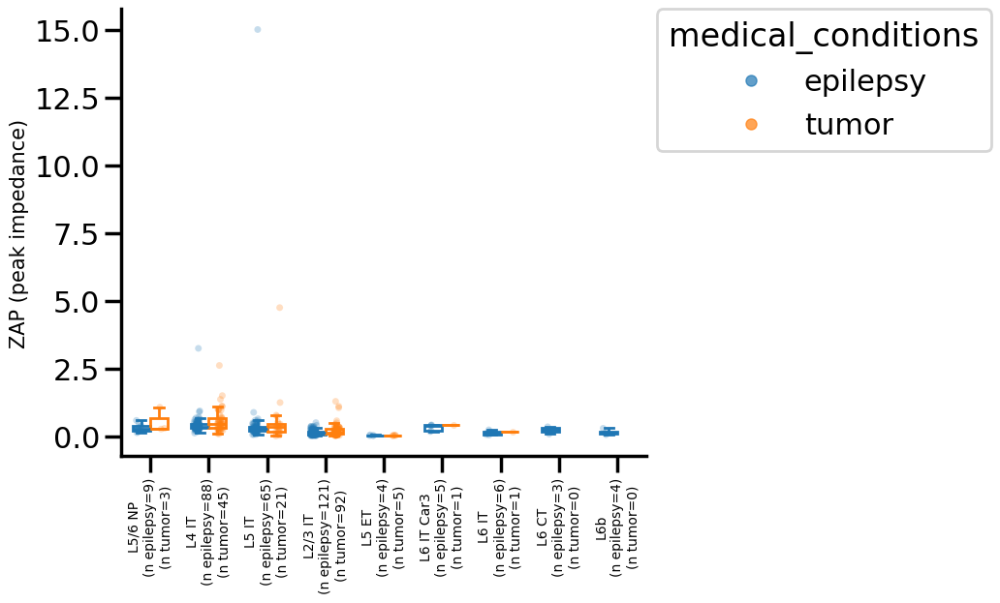

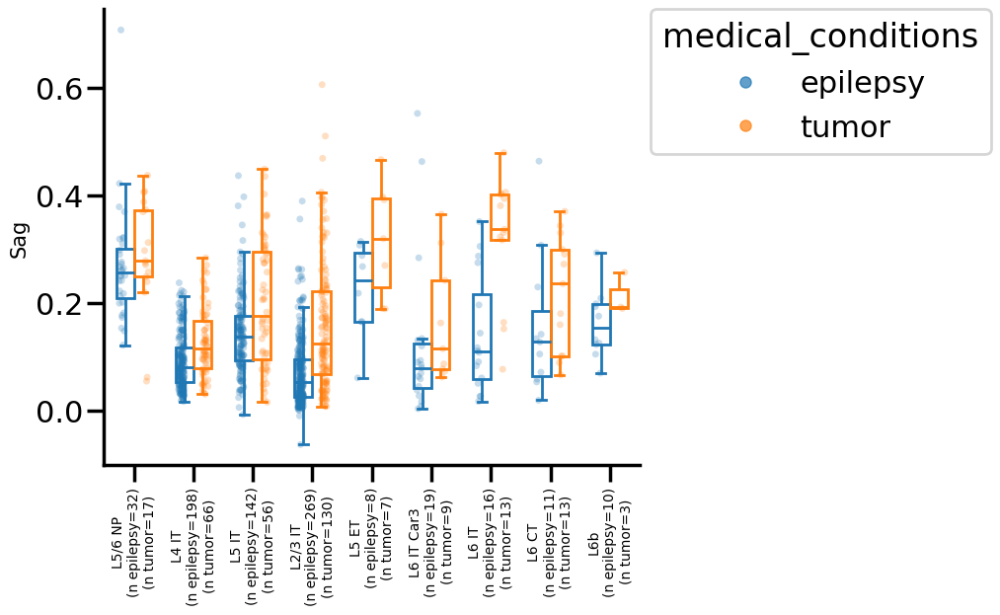

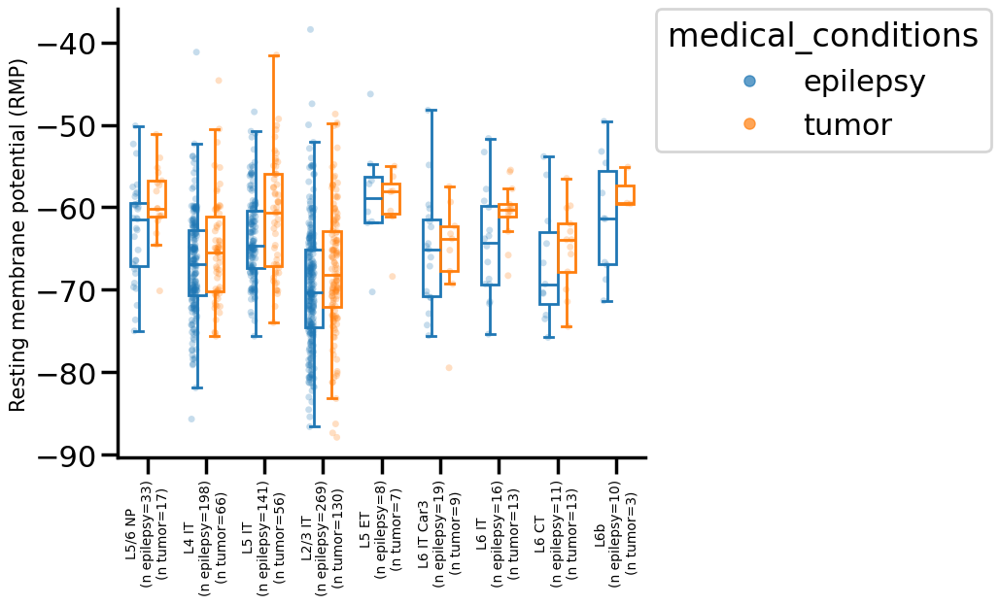

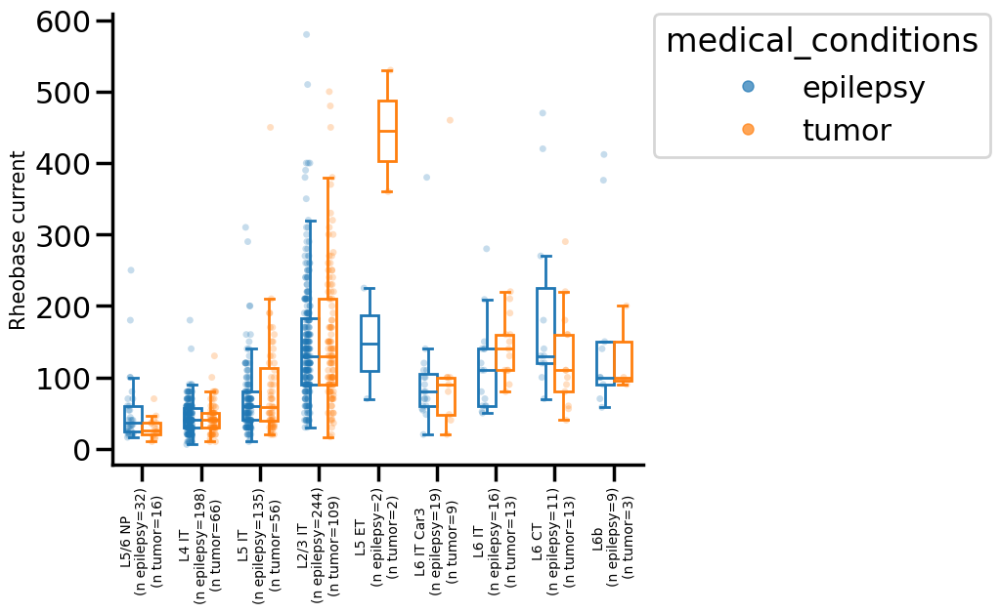

...

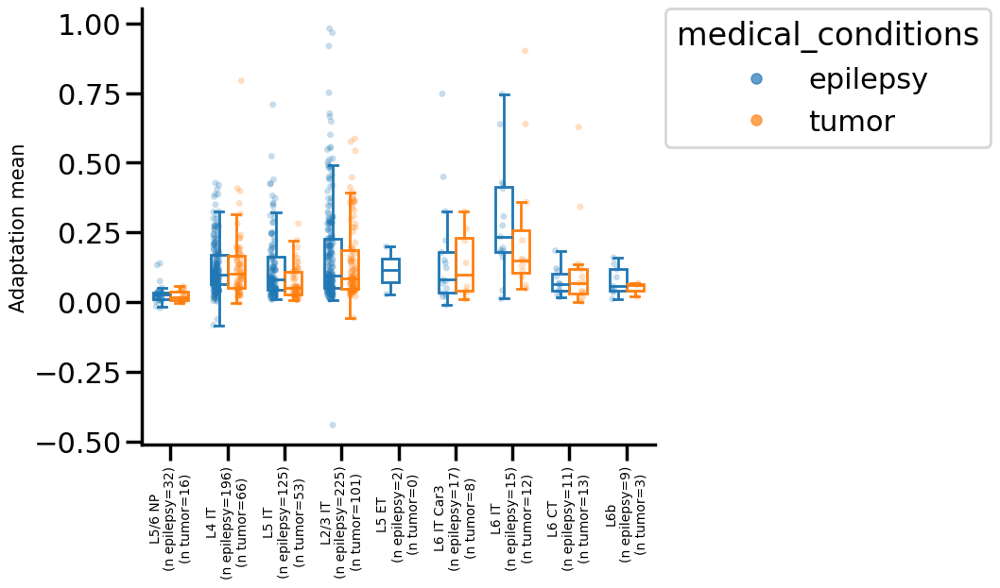

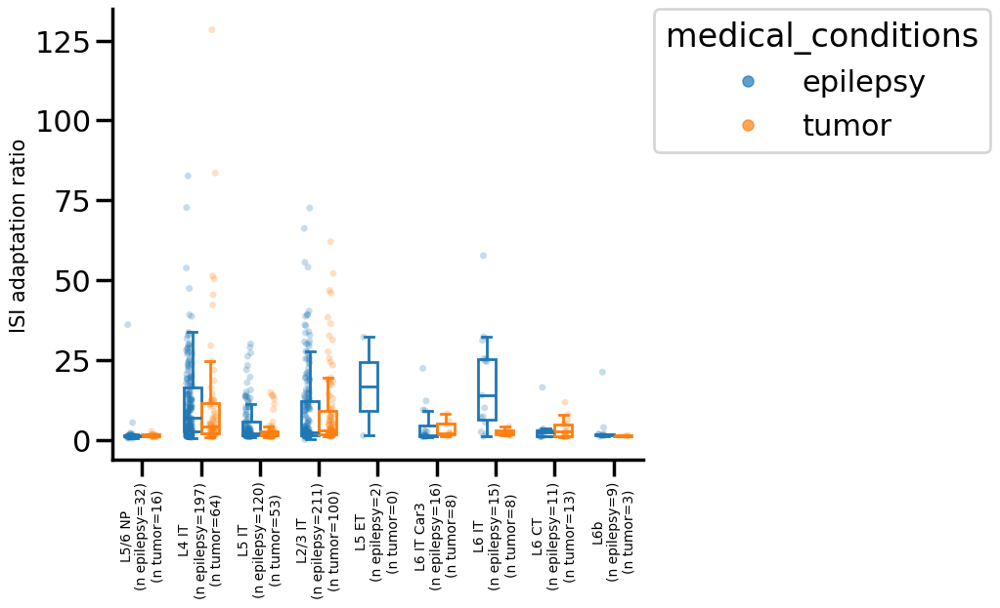

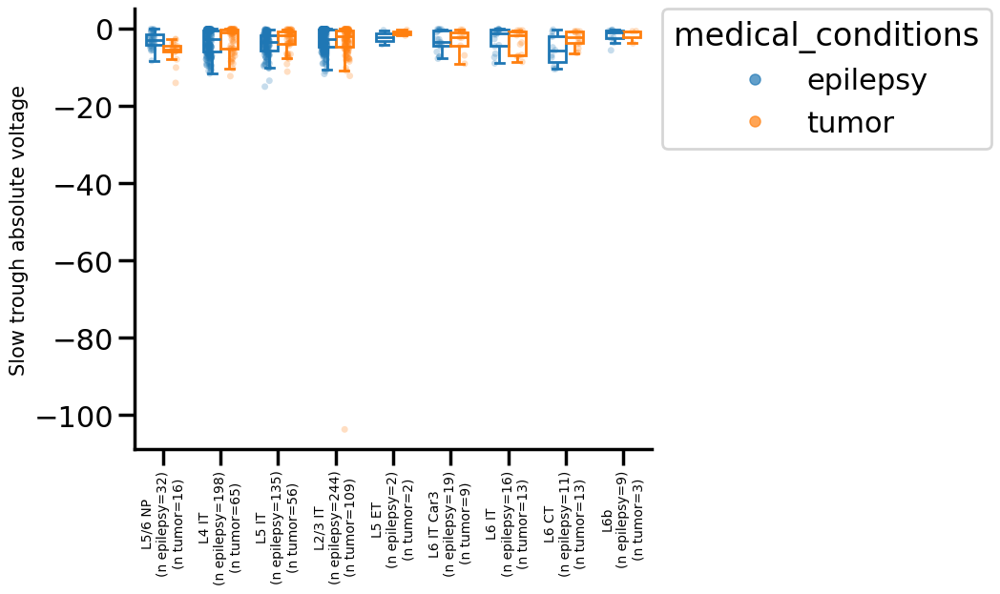

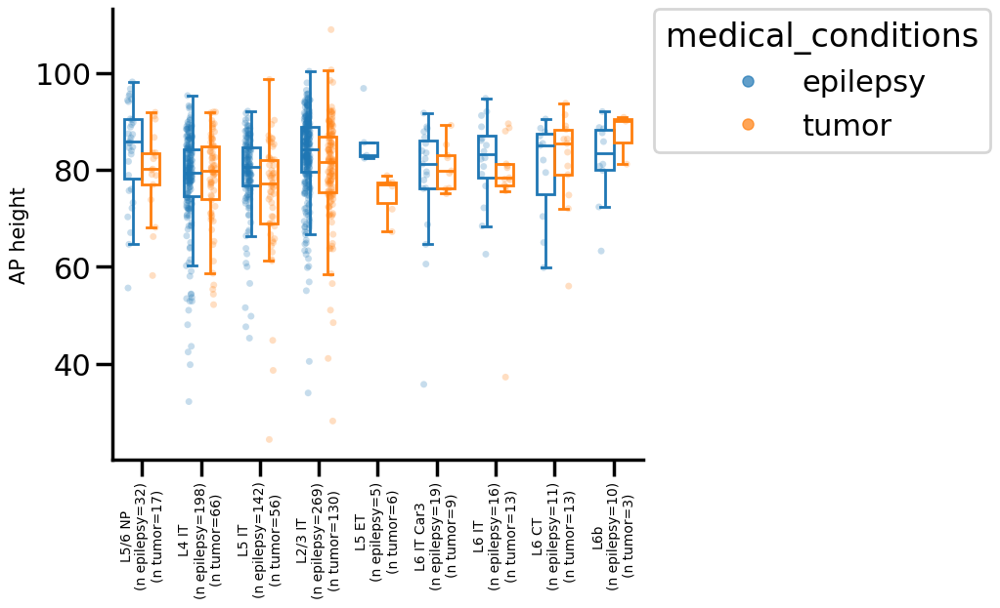

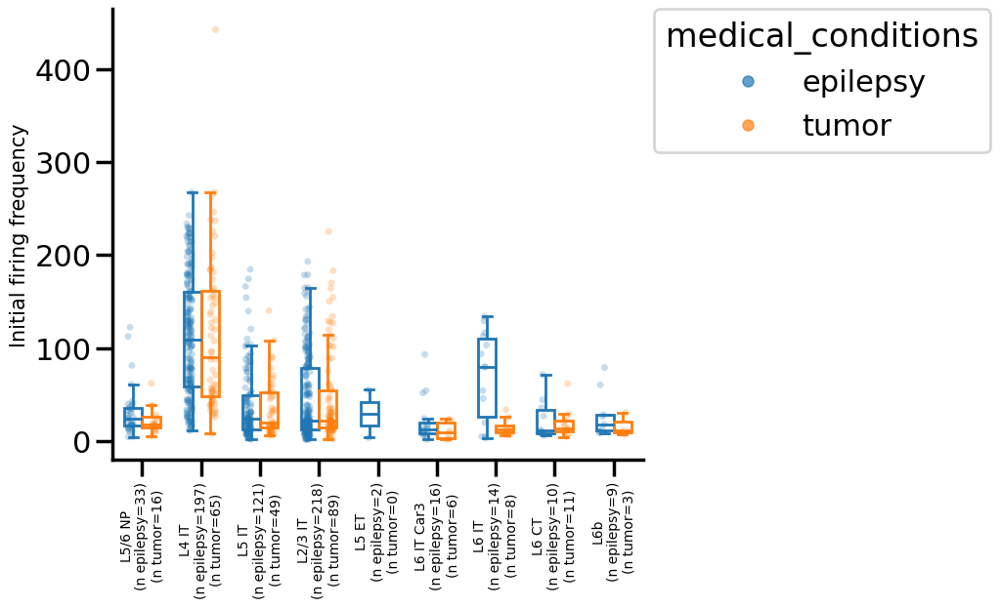

In [15]:
#compute MW - FDR stats for epilepsy and tumor medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'medical_conditions'
group1_label = 'epilepsy'
group2_label = 'tumor'
suffix = '_removeHydrocephalus'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order))
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross age box plots - subclass

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


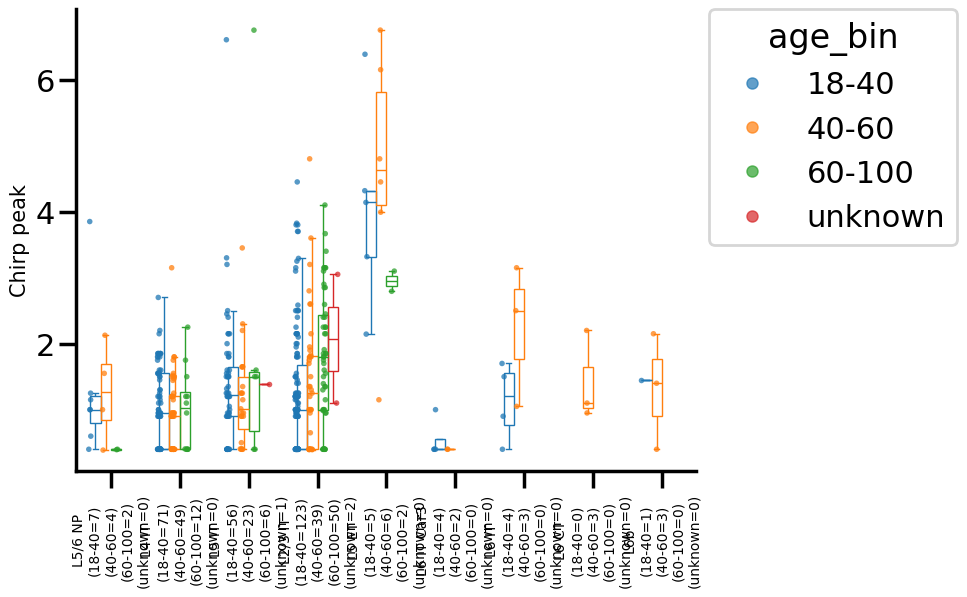

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


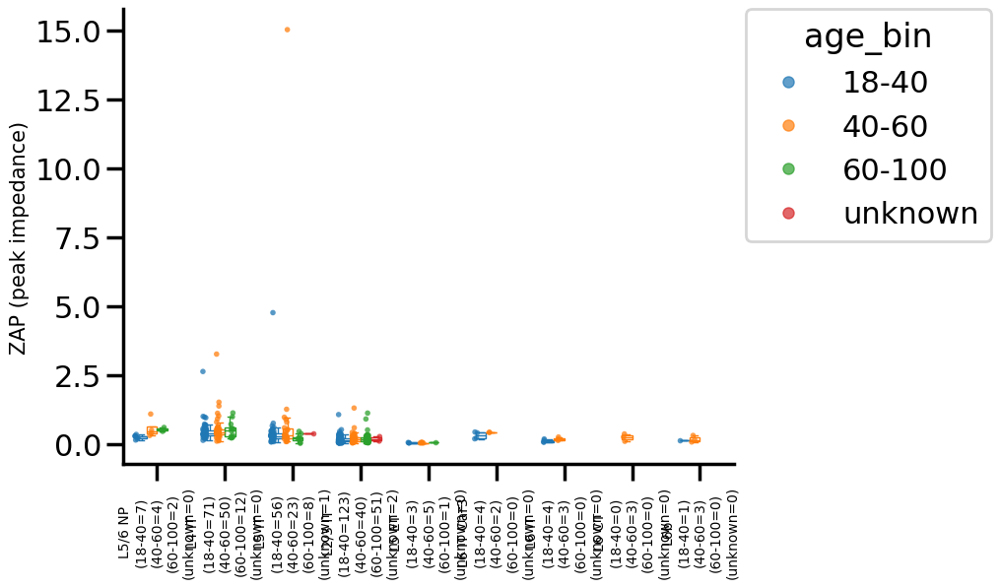

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_60-100 vs. L2/3 IT_unknown: Custom statistical test, P_val:4.646e-02
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.288e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:8.384e-07


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


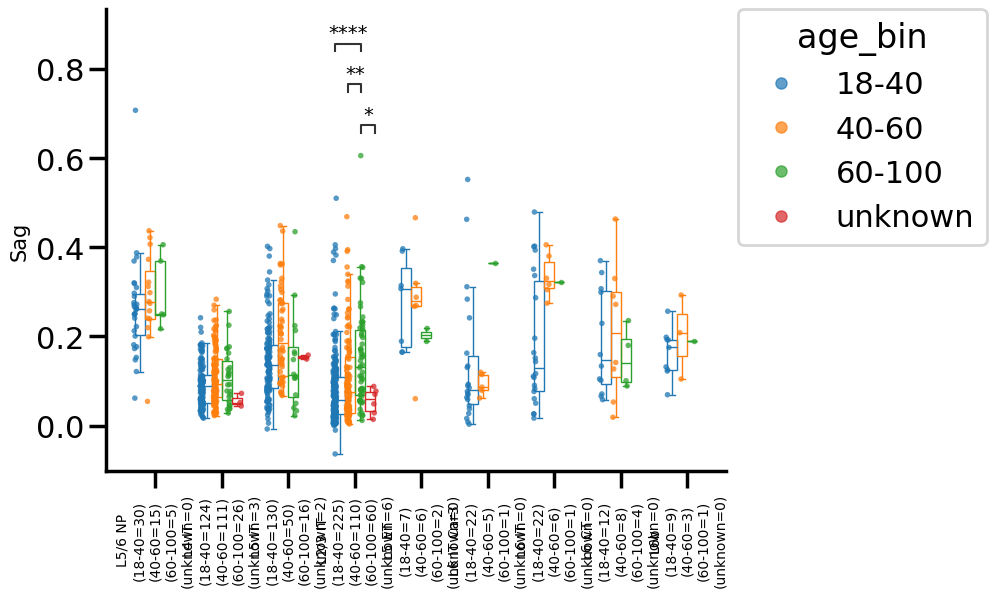

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


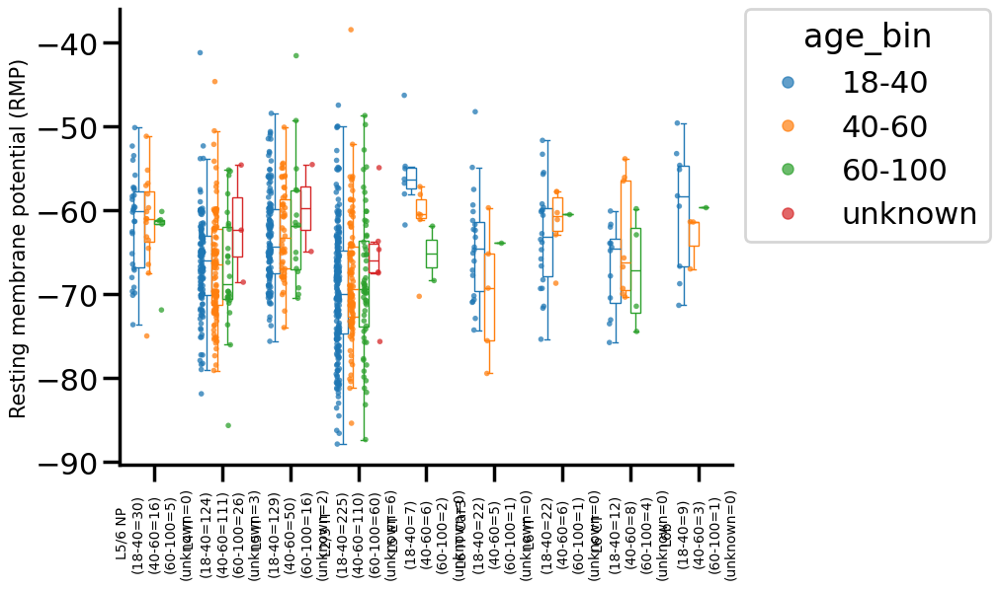

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


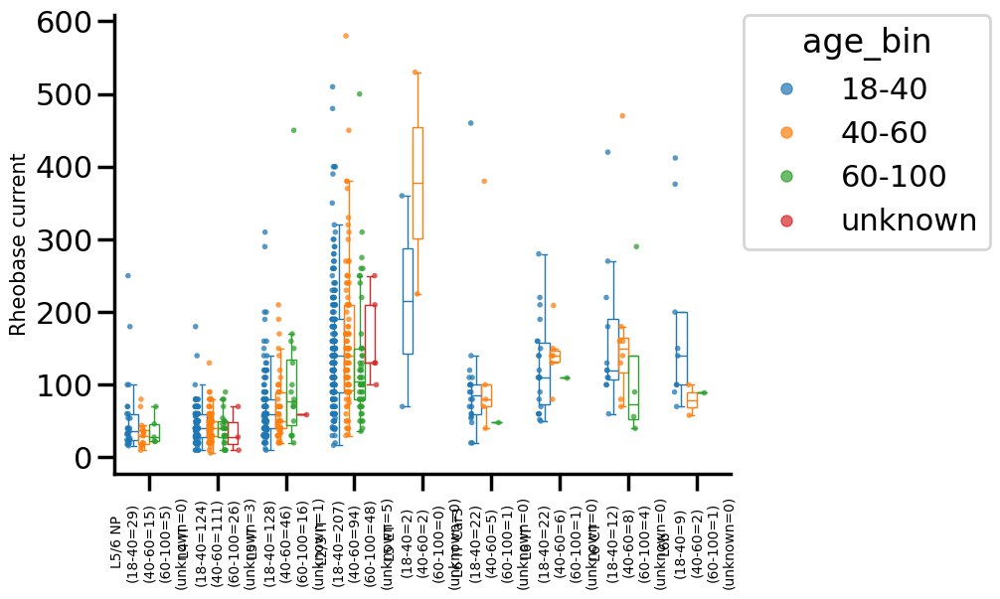

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


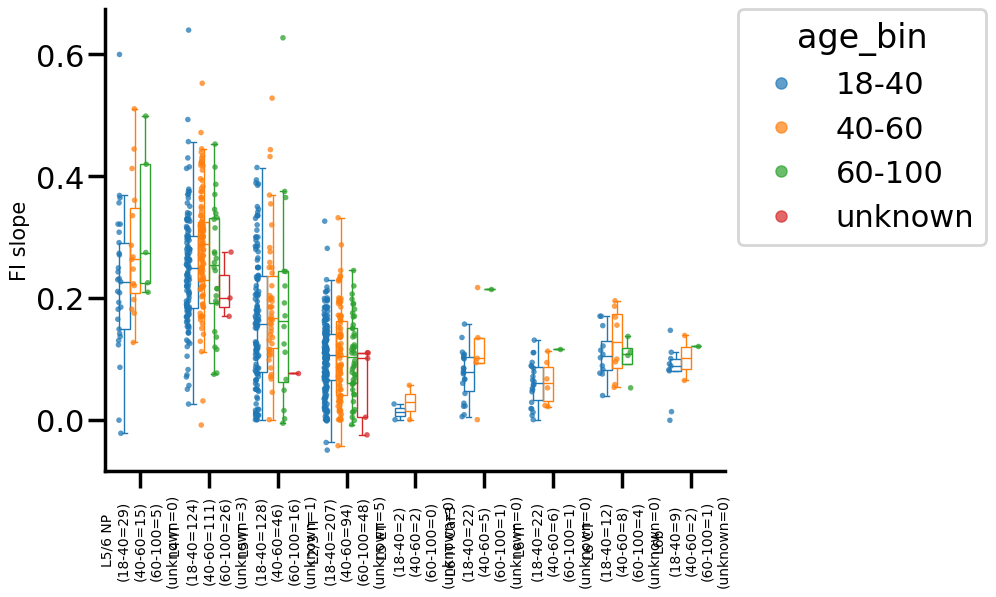

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


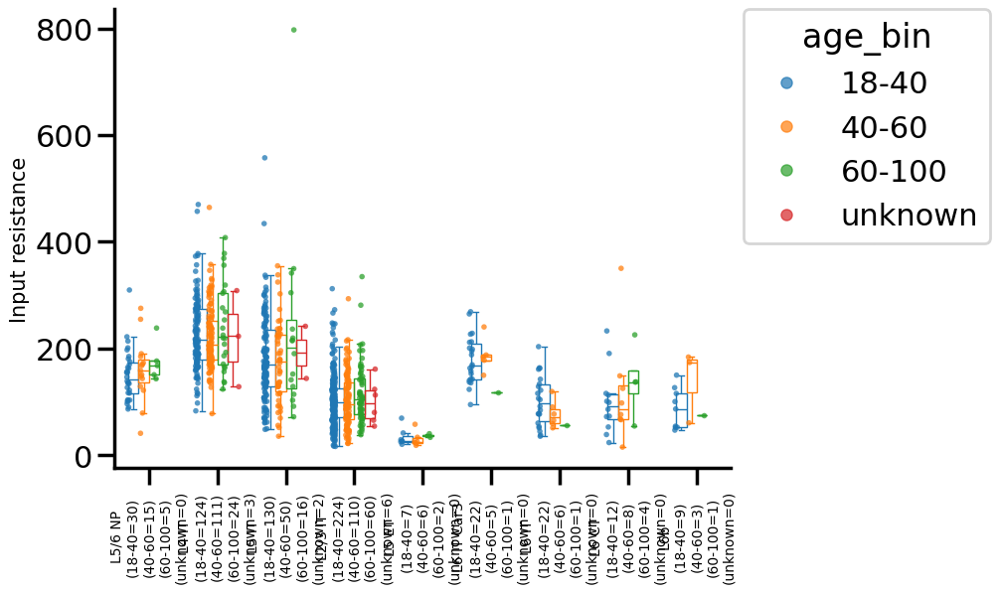

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:1.299e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


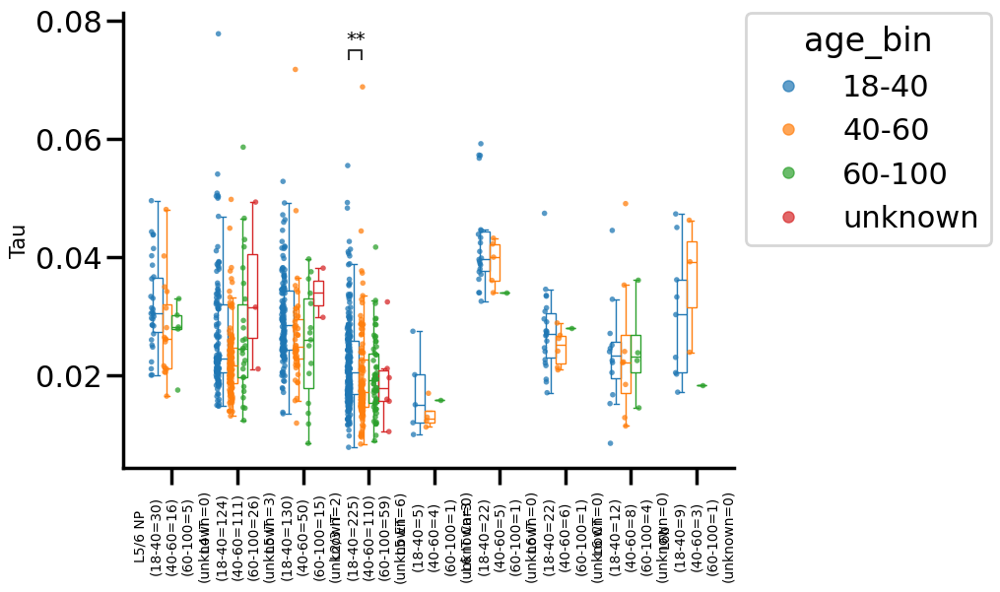

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:2.809e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


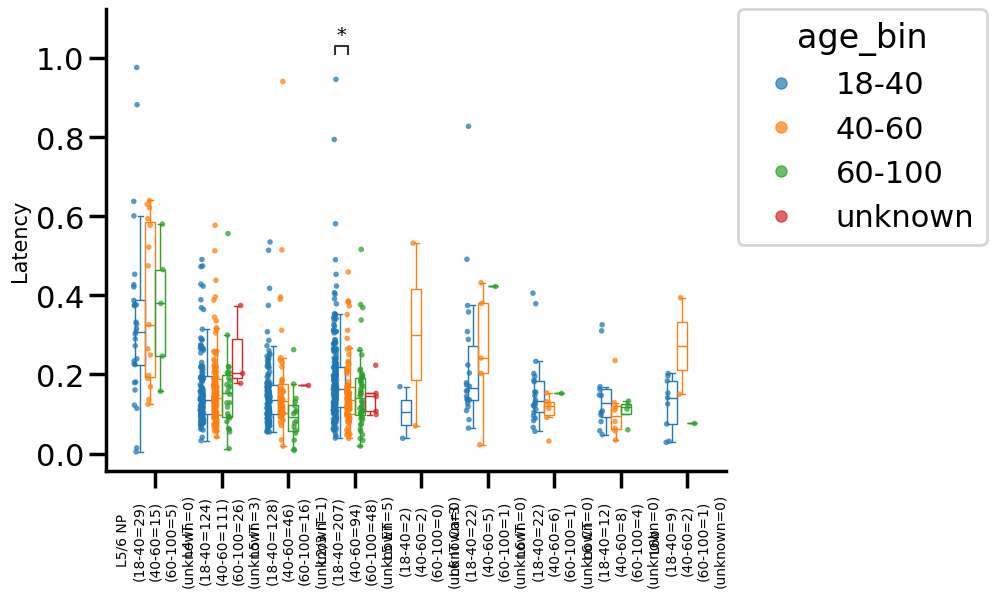

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_60-100 vs. L2/3 IT_unknown: Custom statistical test, P_val:3.924e-02
L5/6 NP_18-40 vs. L5/6 NP_40-60: Custom statistical test, P_val:1.440e-03
L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:1.933e-05
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:4.508e-04
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.854e-05
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:3.212e-02
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:5.509e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


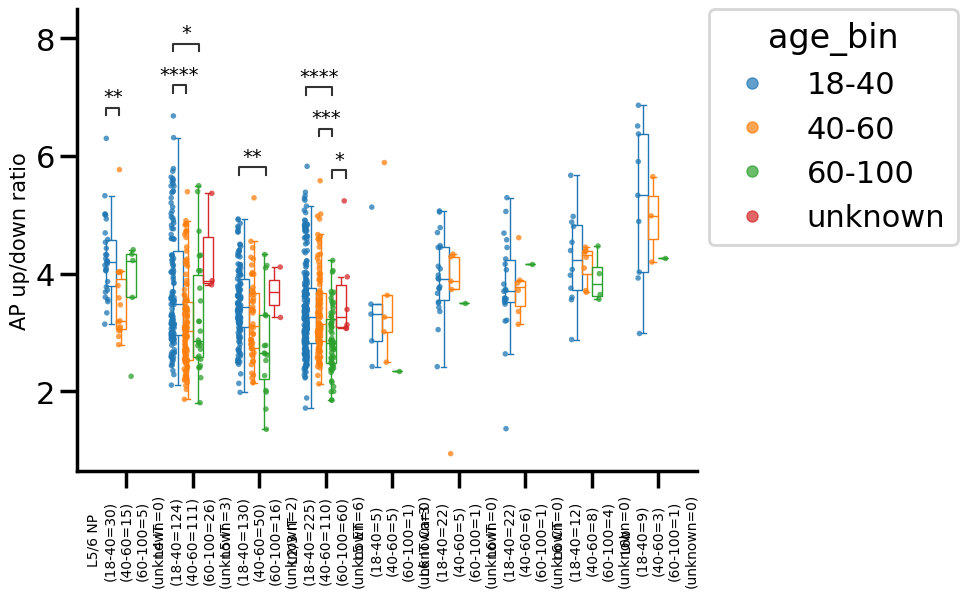

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


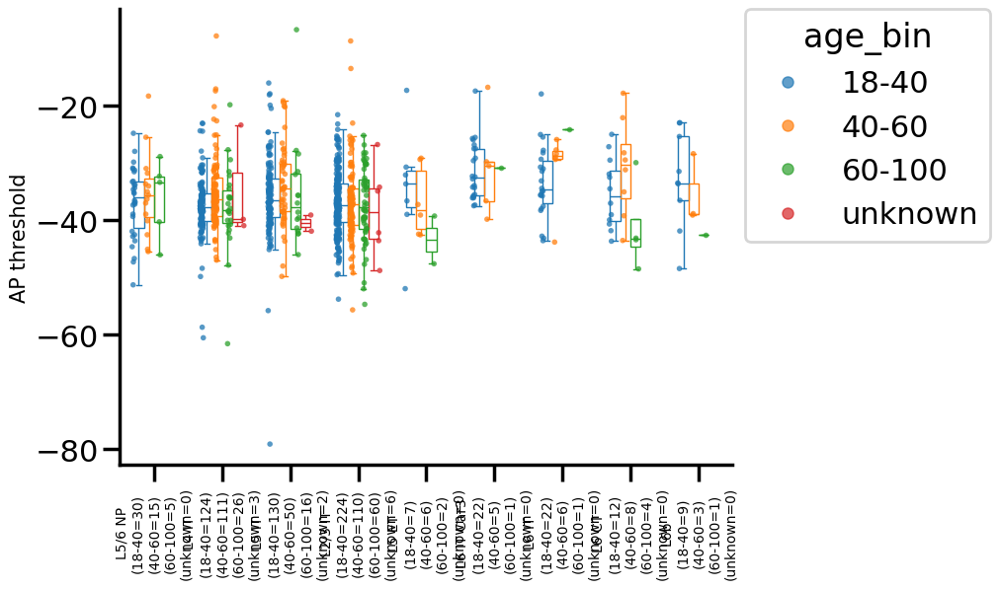

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.009e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.980e-05
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:4.864e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


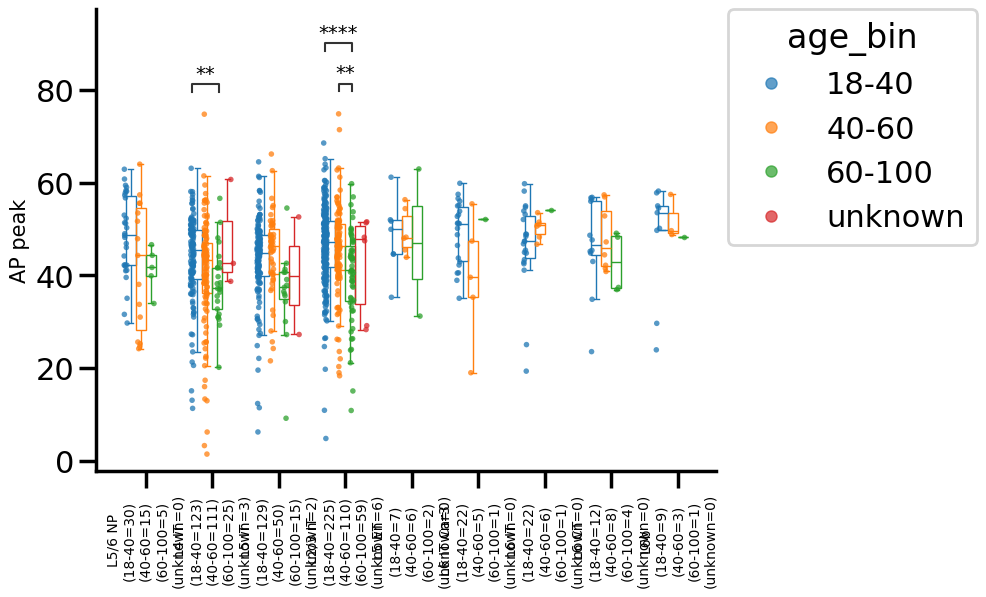

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:6.622e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


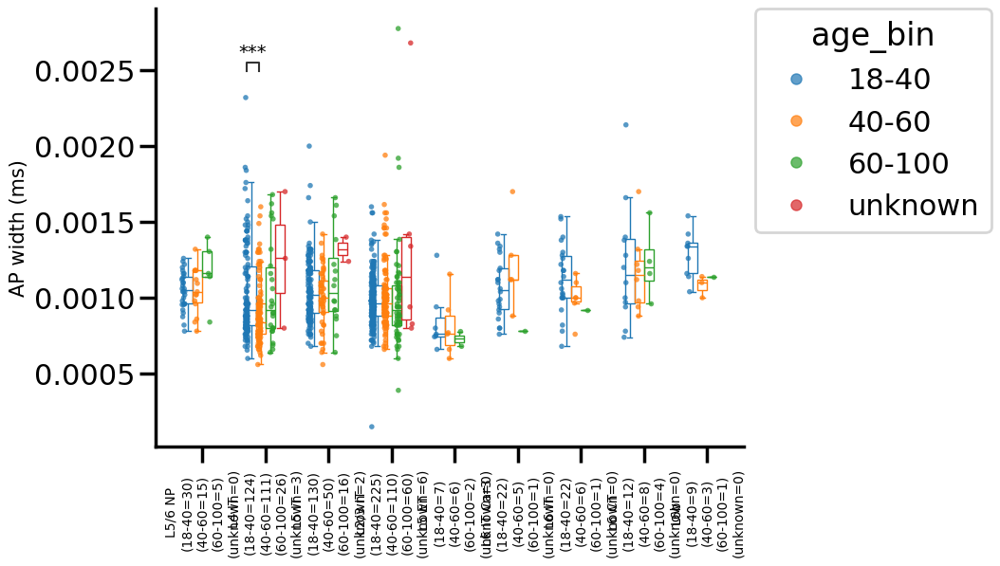

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:1.240e-04
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:2.345e-05


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


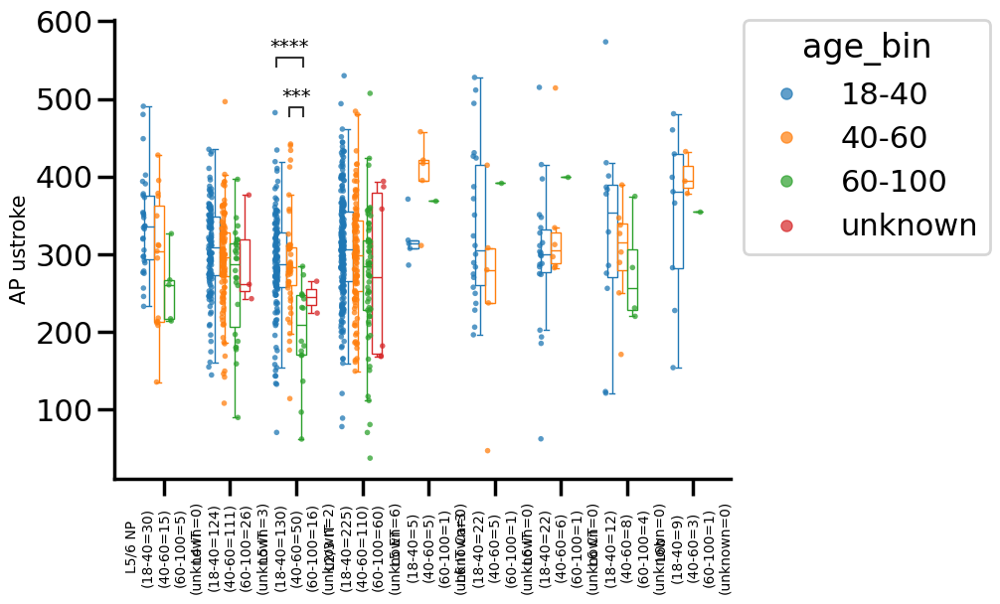

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


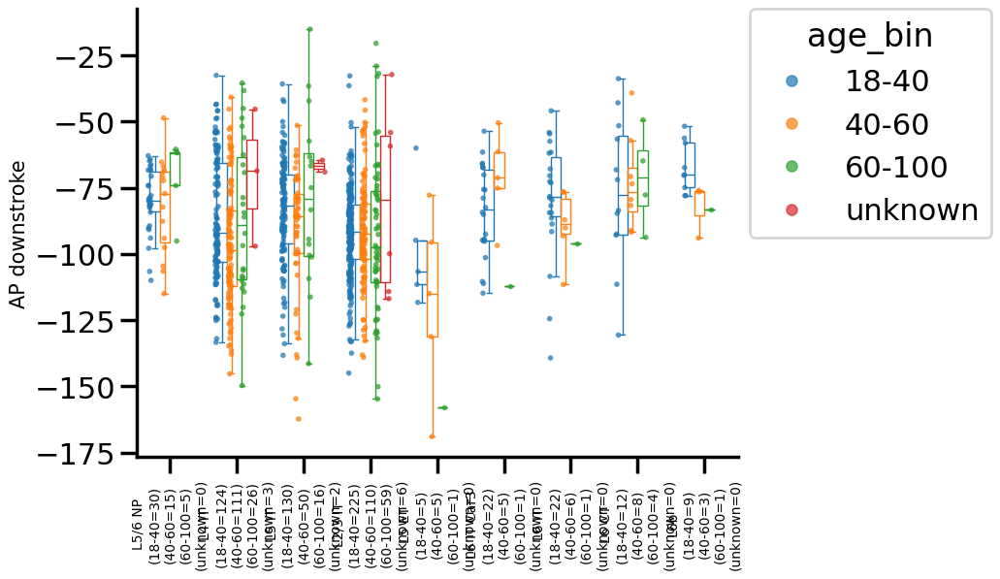

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


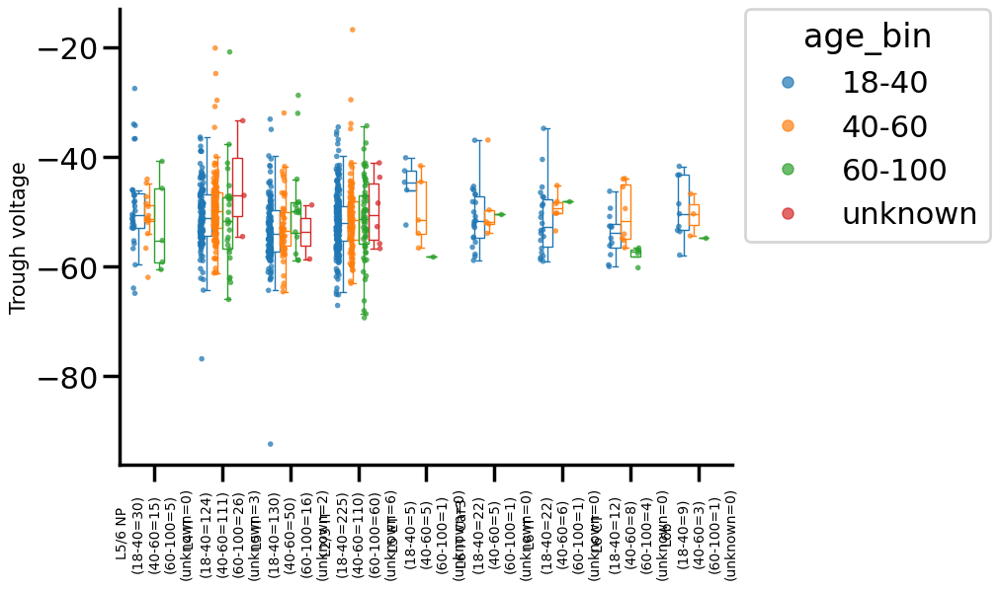

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


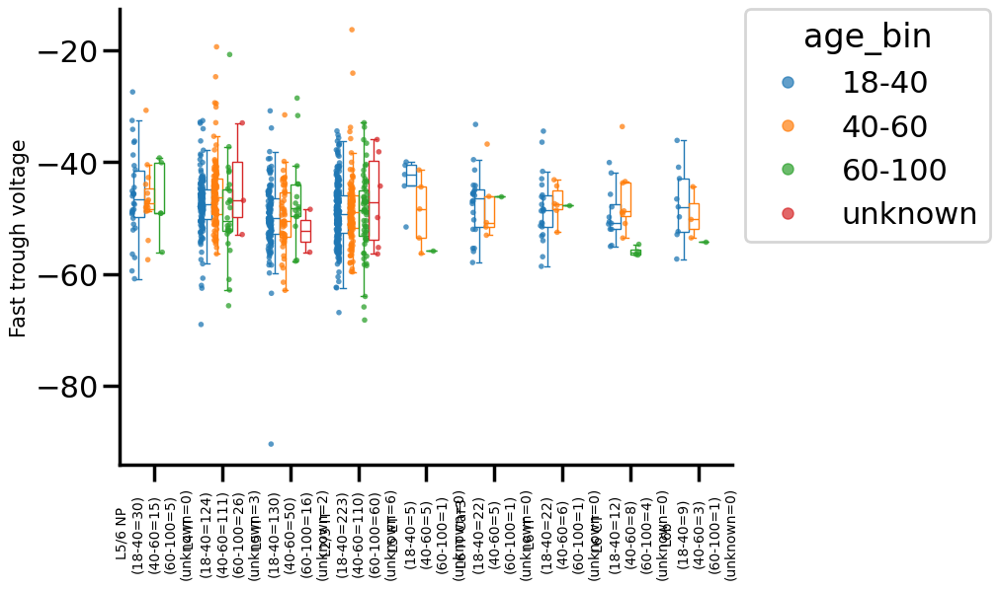

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


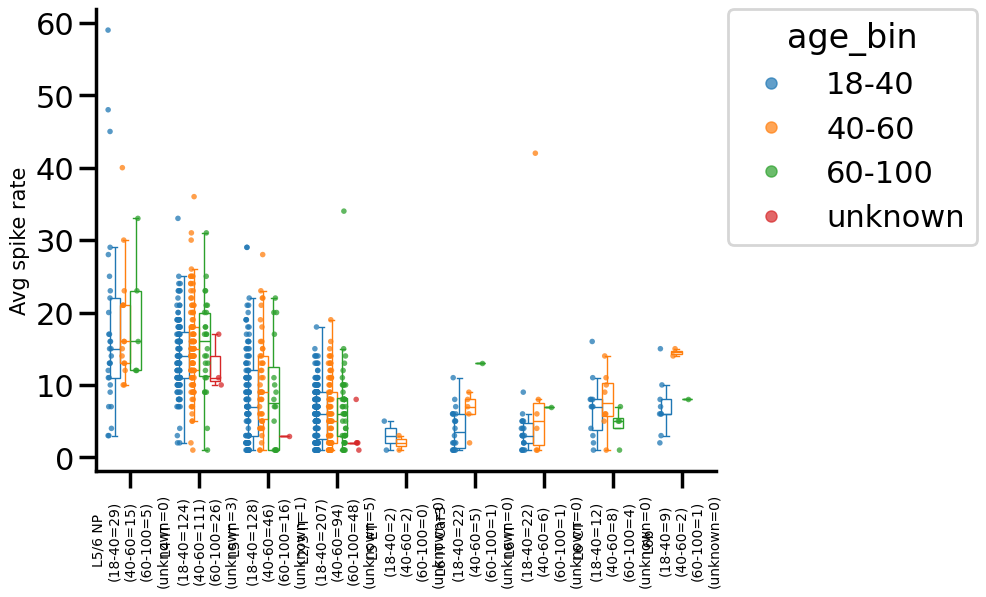

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


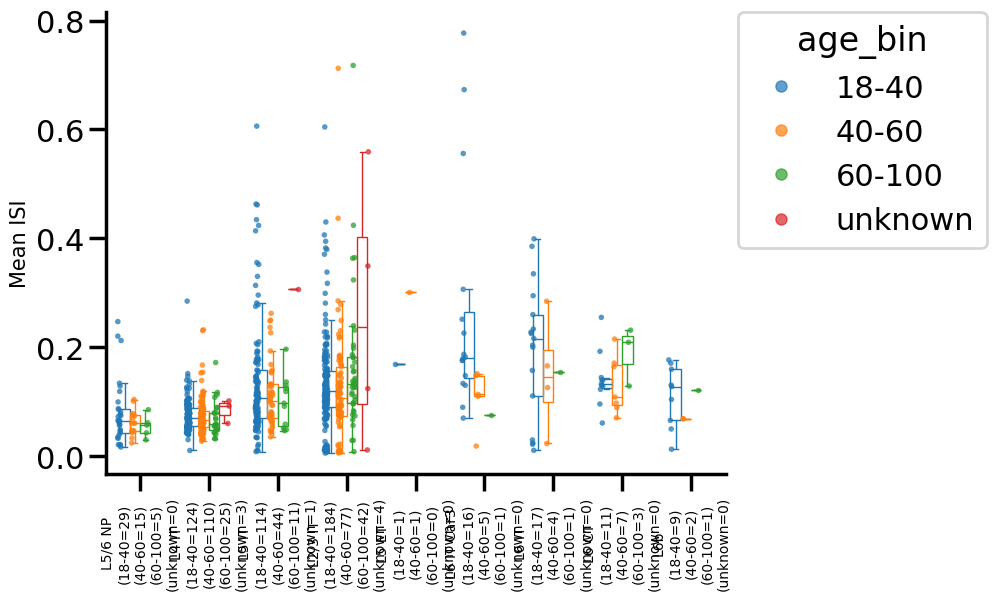

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


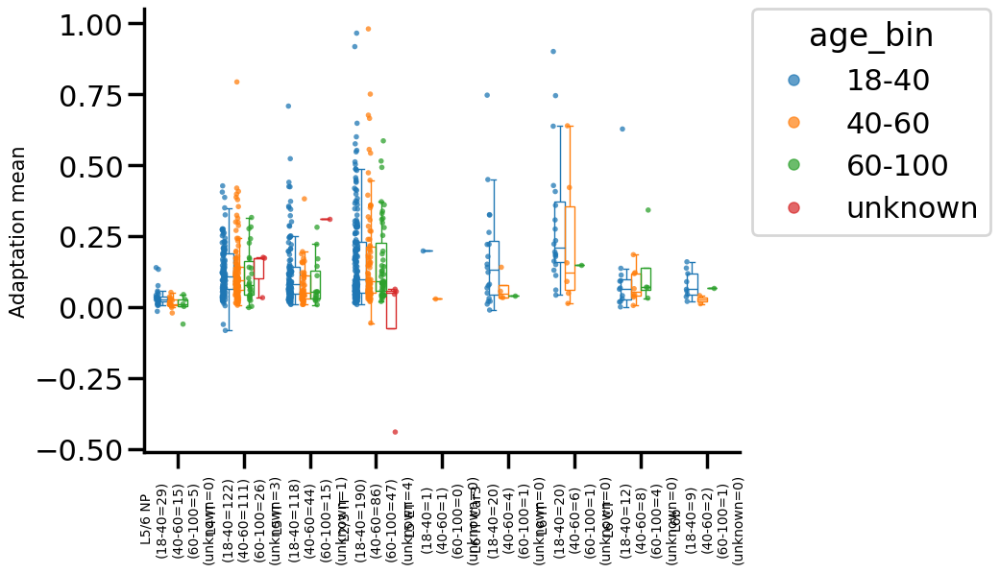

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


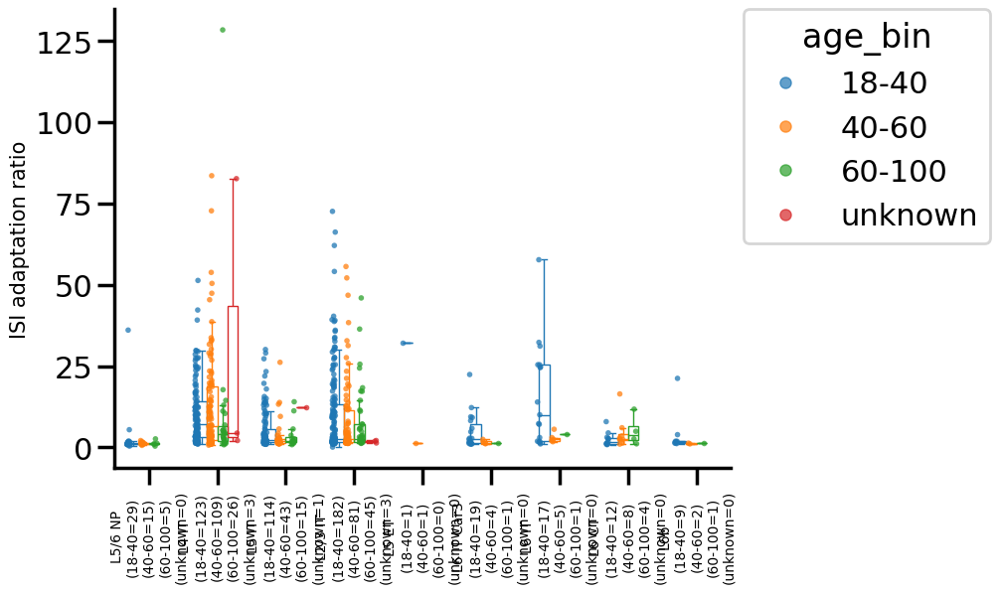

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


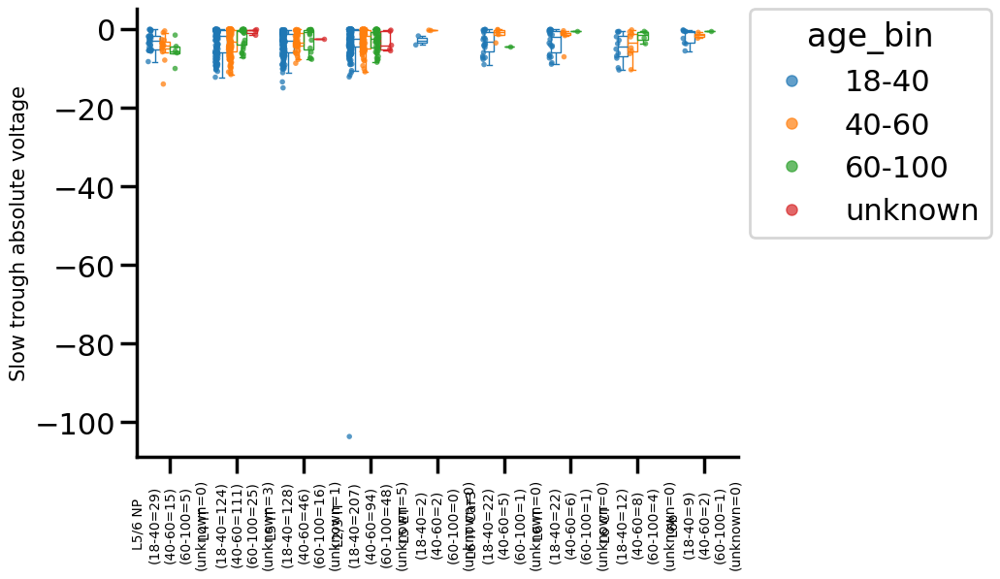

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:1.852e-04
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:8.205e-03
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:5.900e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.705e-05
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:8.198e-04
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:1.782e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


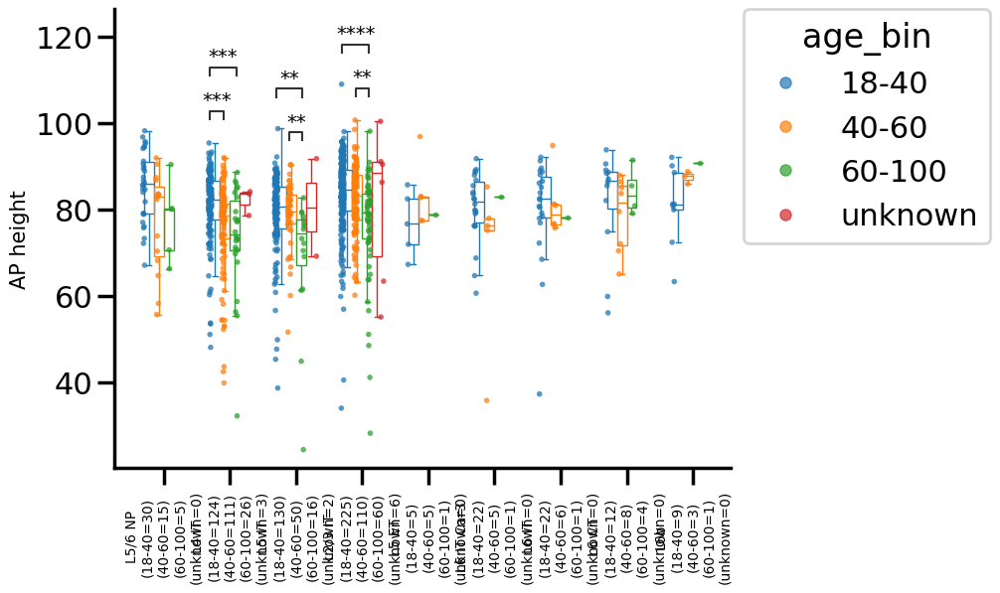

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


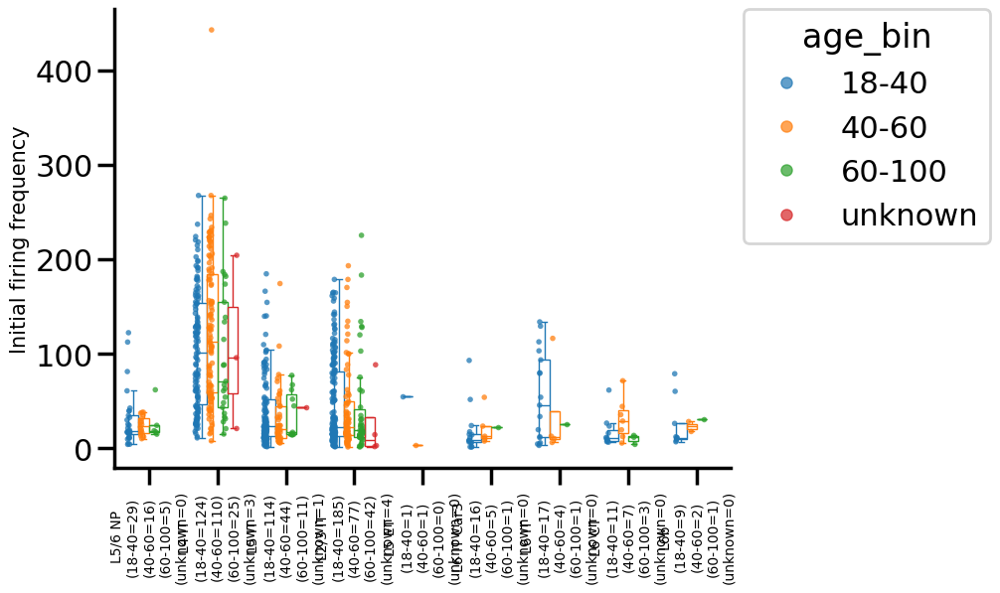

In [16]:
#compute KW - FDR - Dunn stats for all ages (including unknown)
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'age_bin'
group_order = sorted(sorted_clean_data[group_var].unique().tolist())

features = feature_cols.copy()
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing `unknown` age cells

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


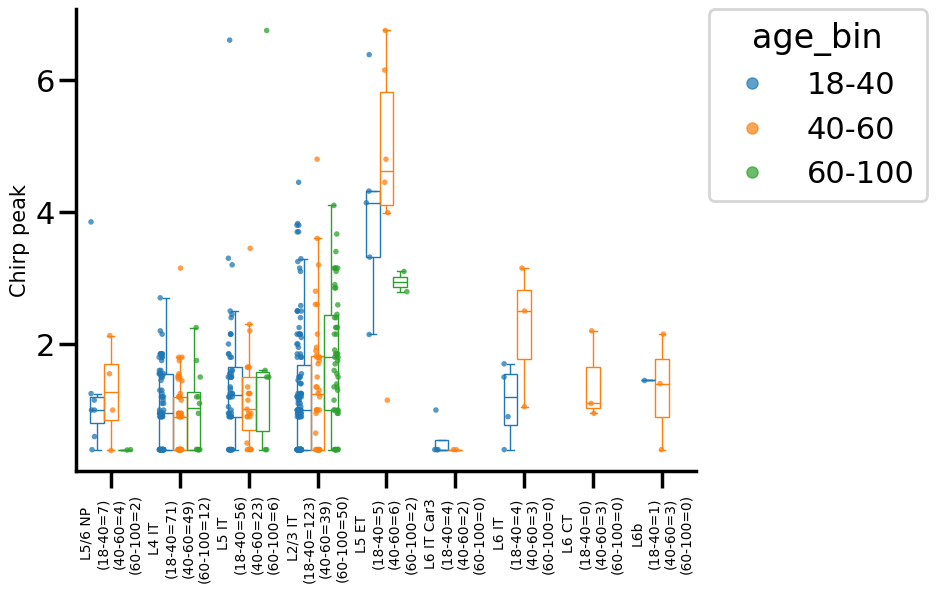

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


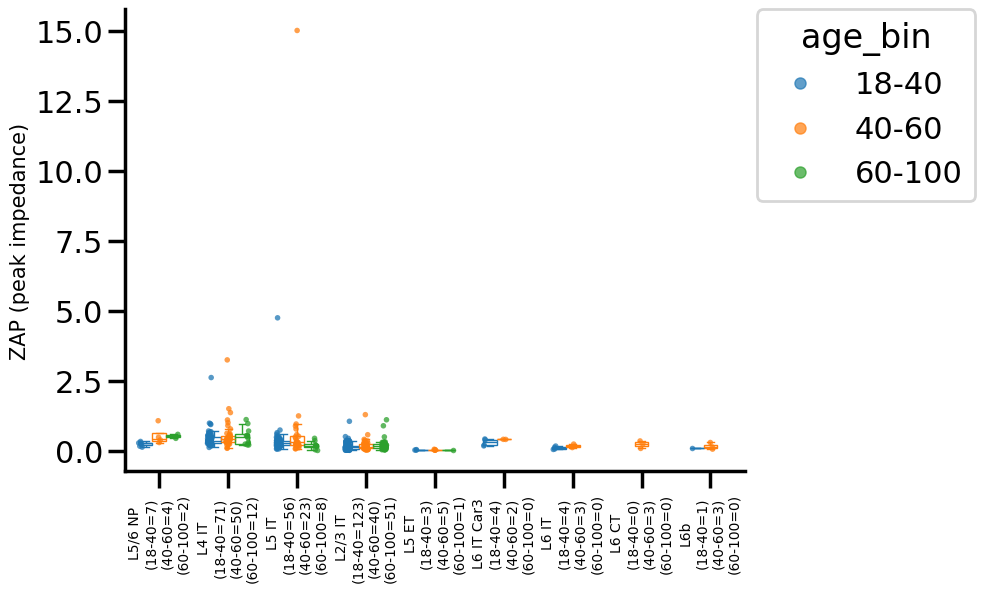

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_18-40 vs. L5 IT_40-60: Custom statistical test, P_val:1.910e-03
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:3.349e-02
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.199e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:4.502e-07


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


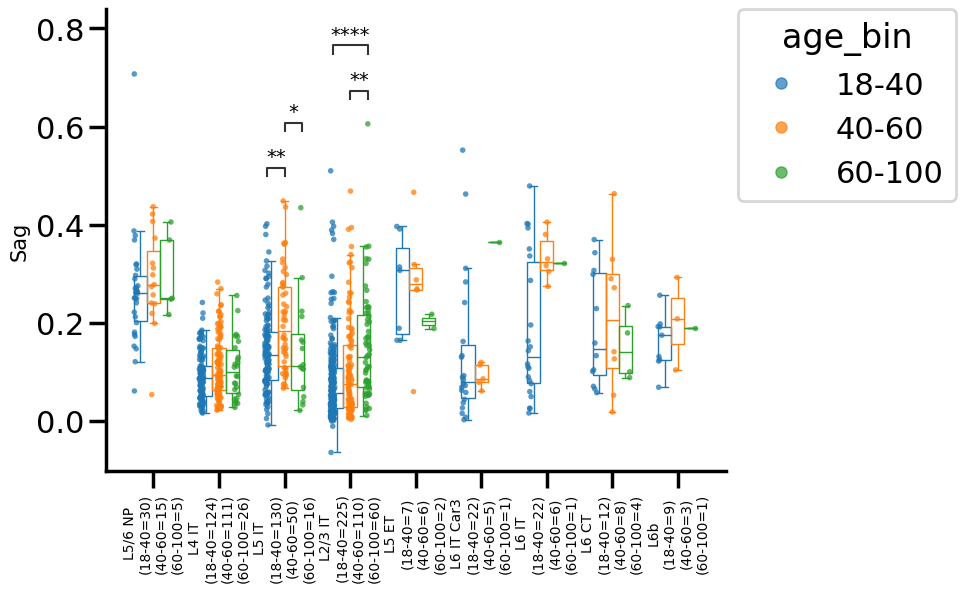

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


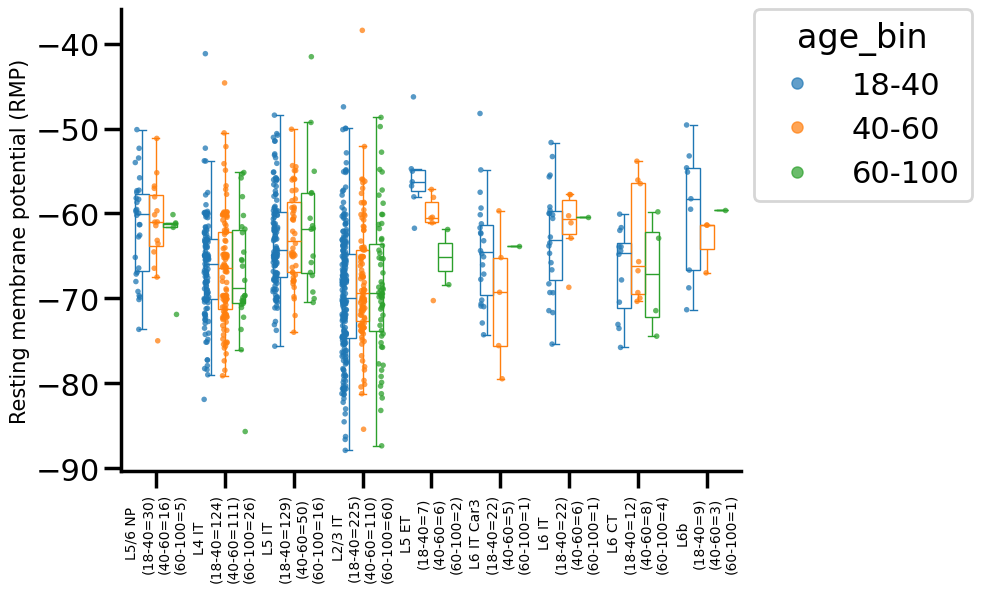

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


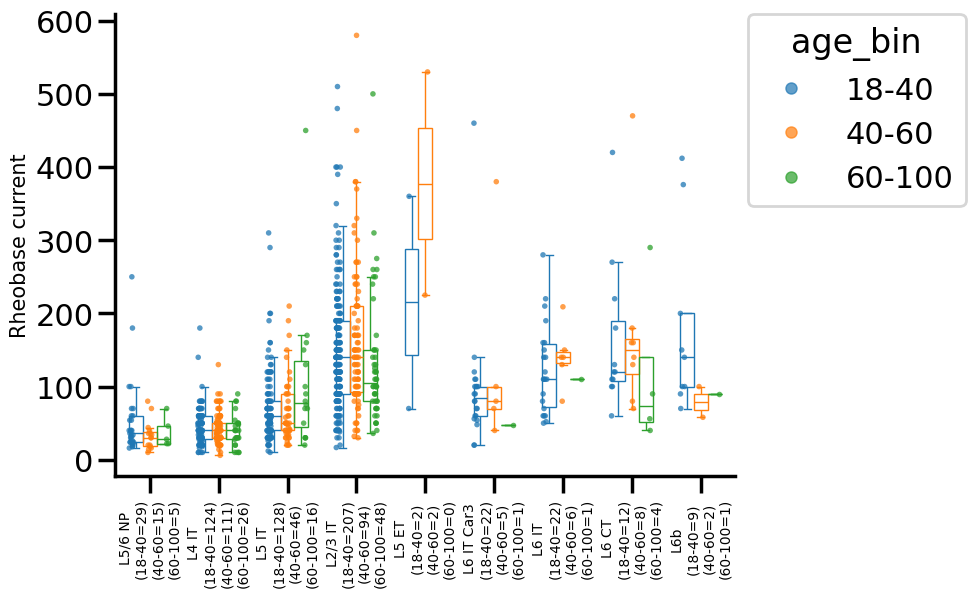

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


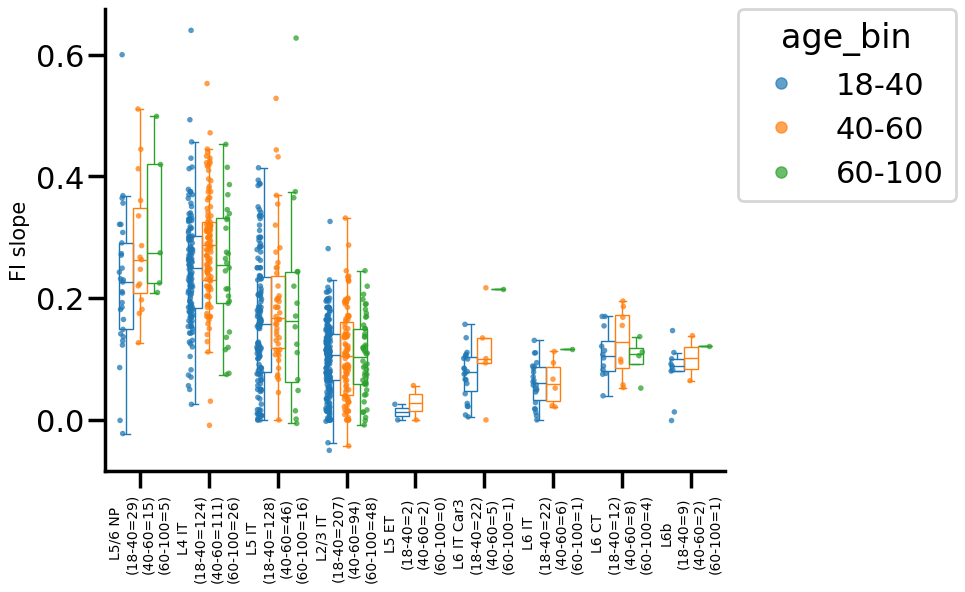

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


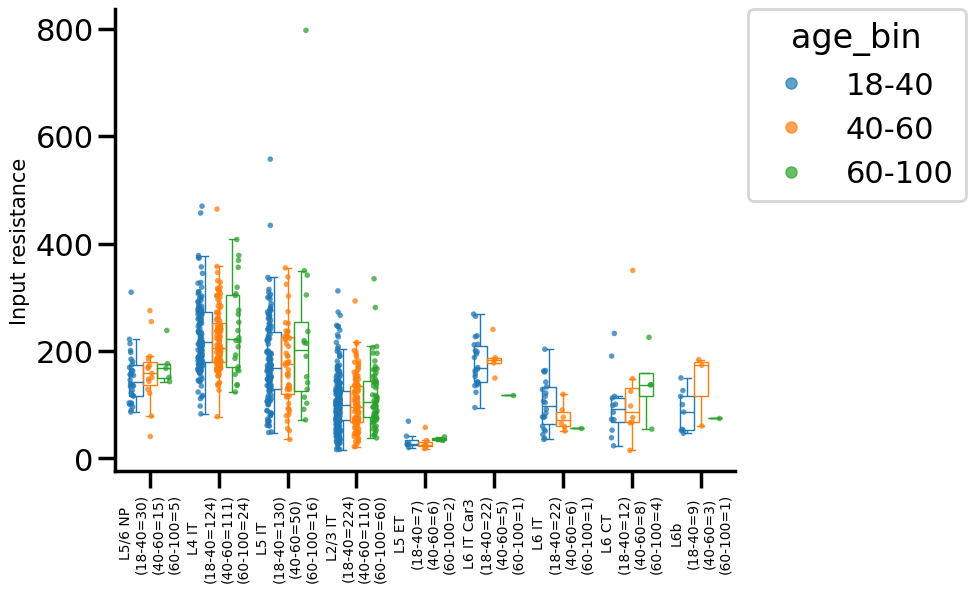

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:3.033e-03
L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:6.687e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


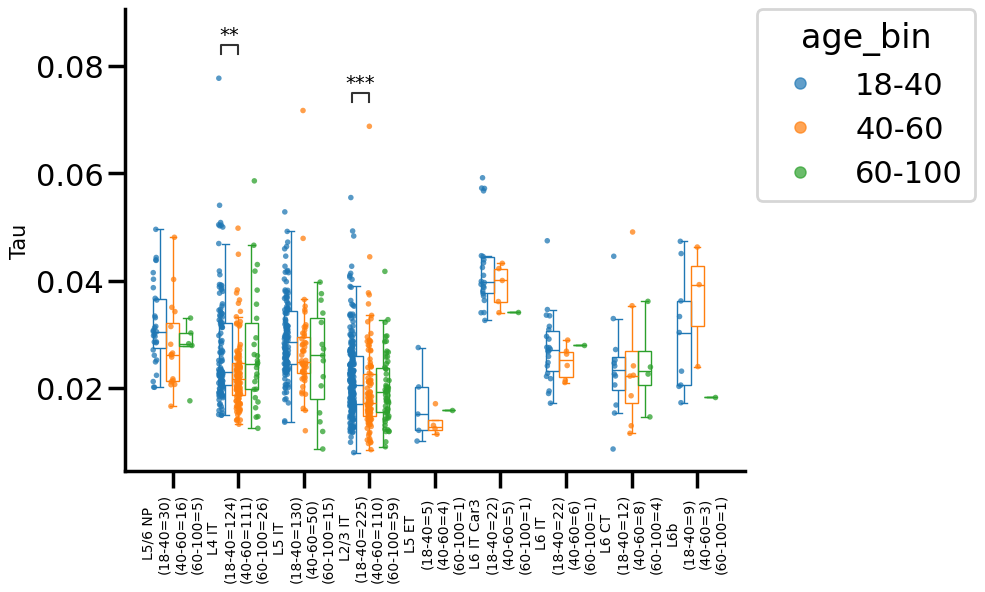

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:1.434e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


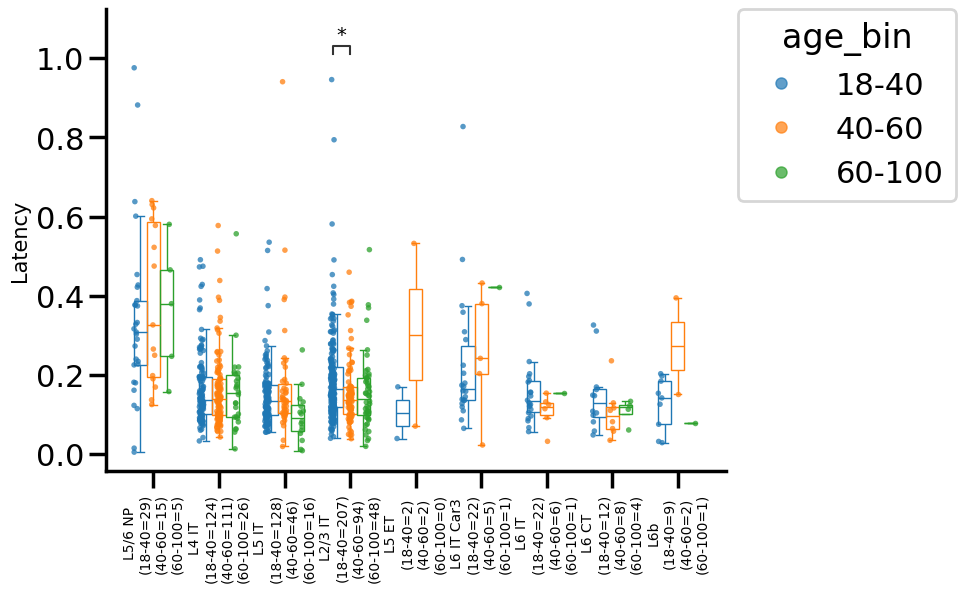

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:9.622e-06
L5 IT_18-40 vs. L5 IT_40-60: Custom statistical test, P_val:4.909e-02
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.185e-04
L5/6 NP_18-40 vs. L5/6 NP_40-60: Custom statistical test, P_val:1.440e-03
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:1.550e-02
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:2.663e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:9.281e-06


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


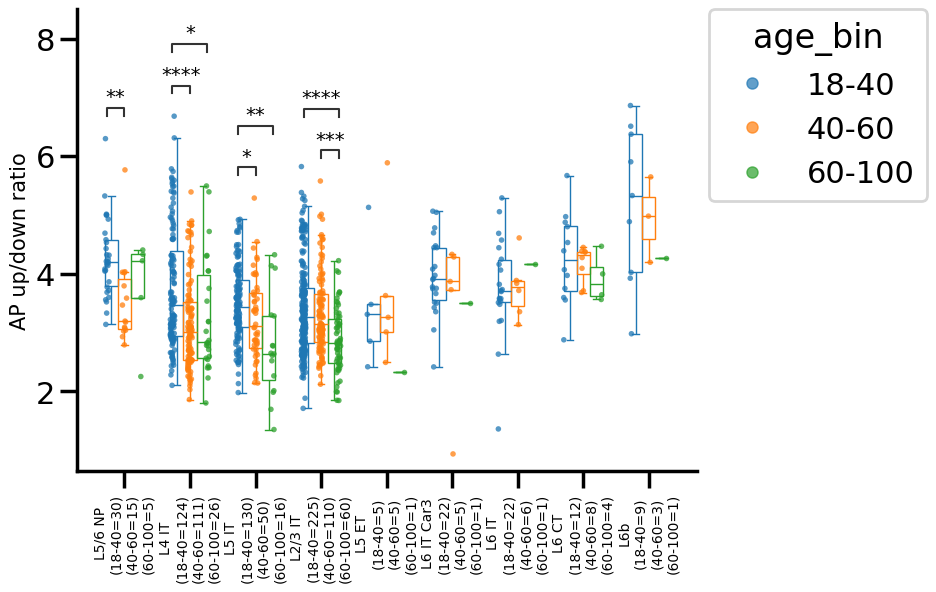

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


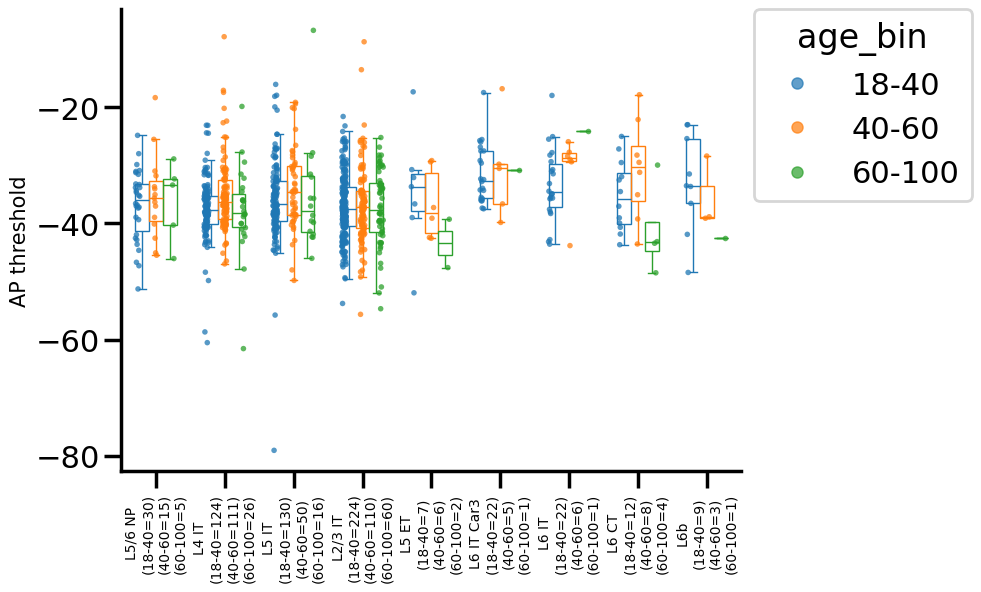

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:3.759e-02
L4 IT_40-60 vs. L4 IT_60-100: Custom statistical test, P_val:4.678e-02
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:1.709e-03
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:9.772e-04
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:2.483e-03
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:1.884e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.467e-05


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


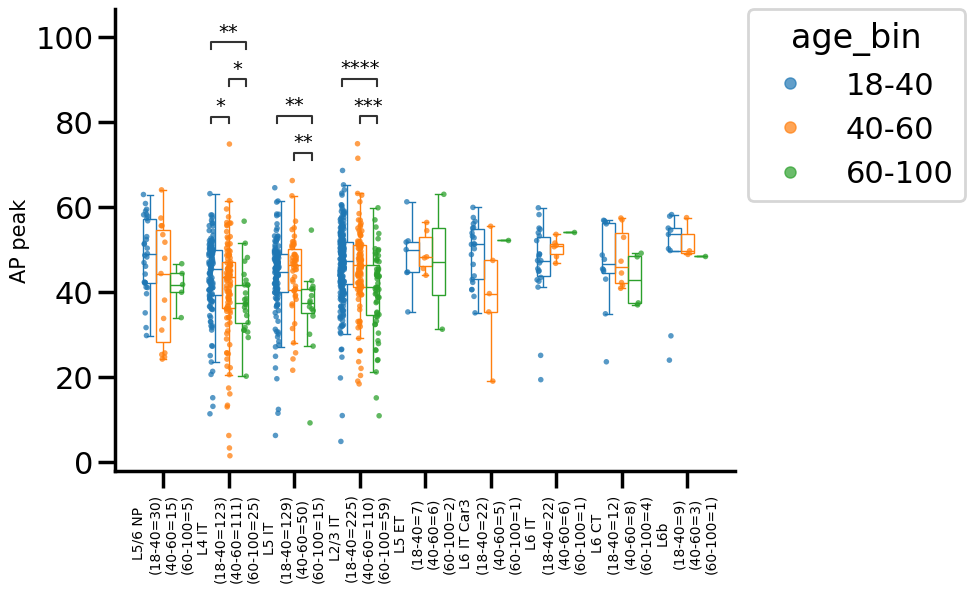

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:3.307e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


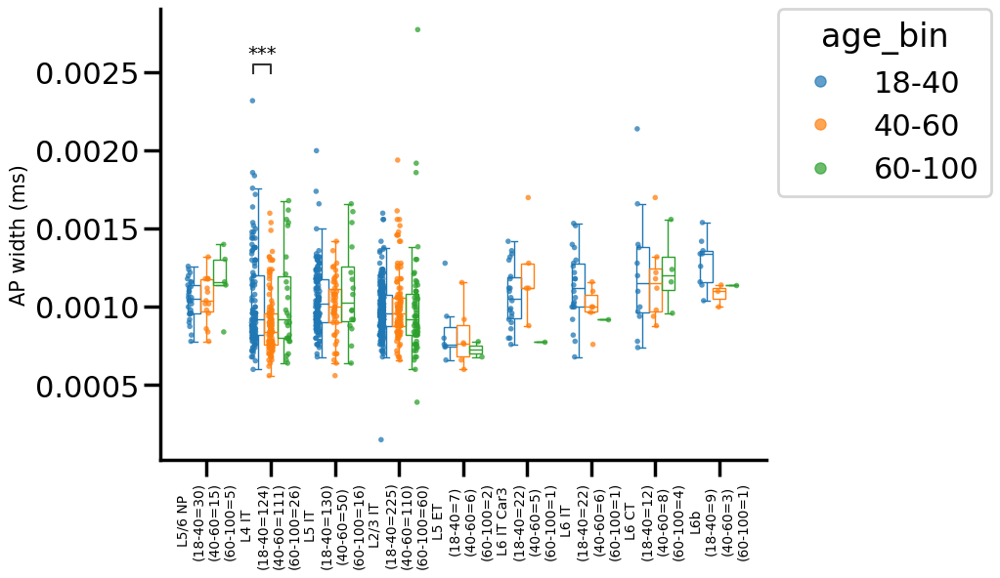

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:6.588e-05
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:1.261e-05


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


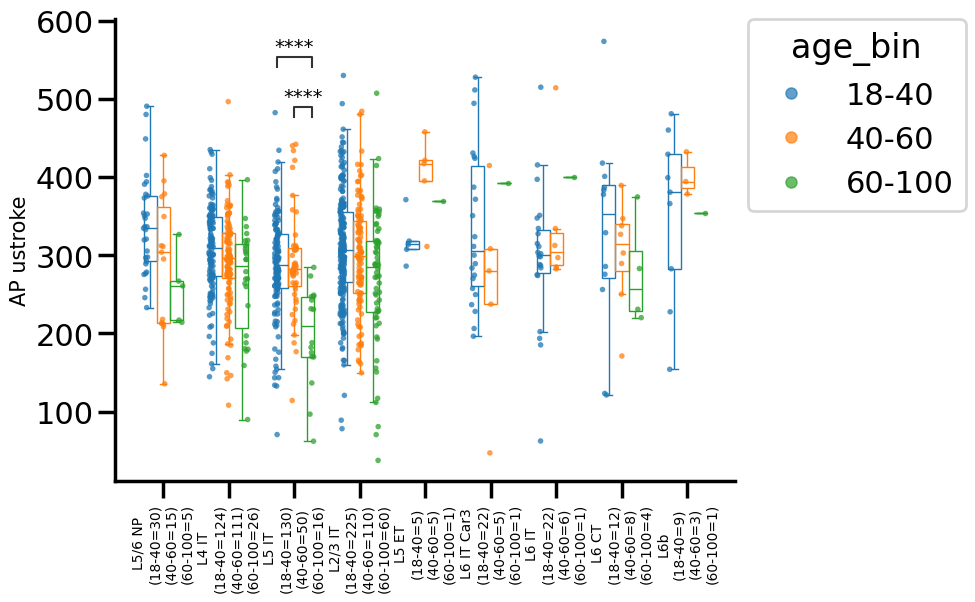

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


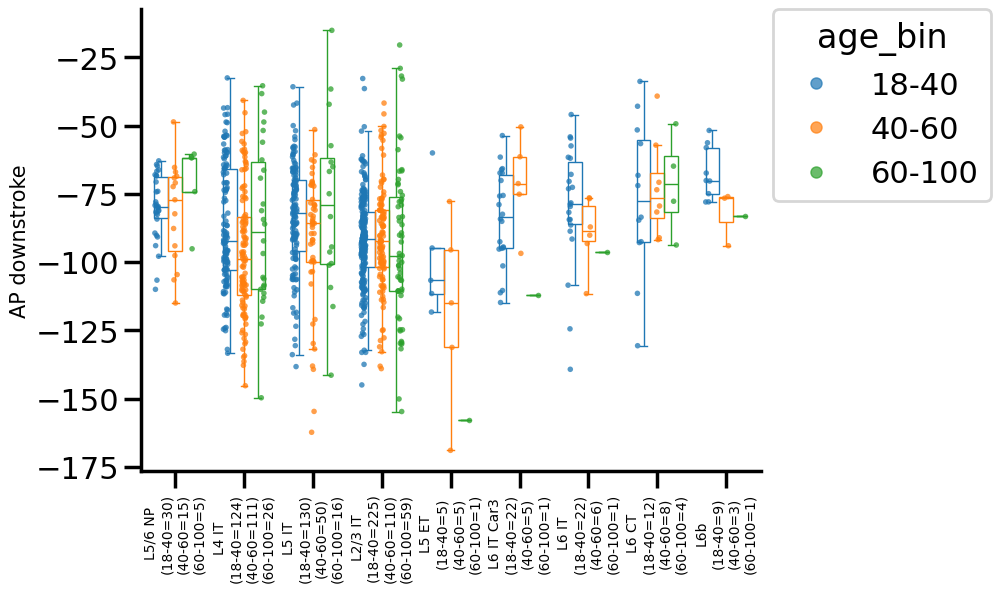

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


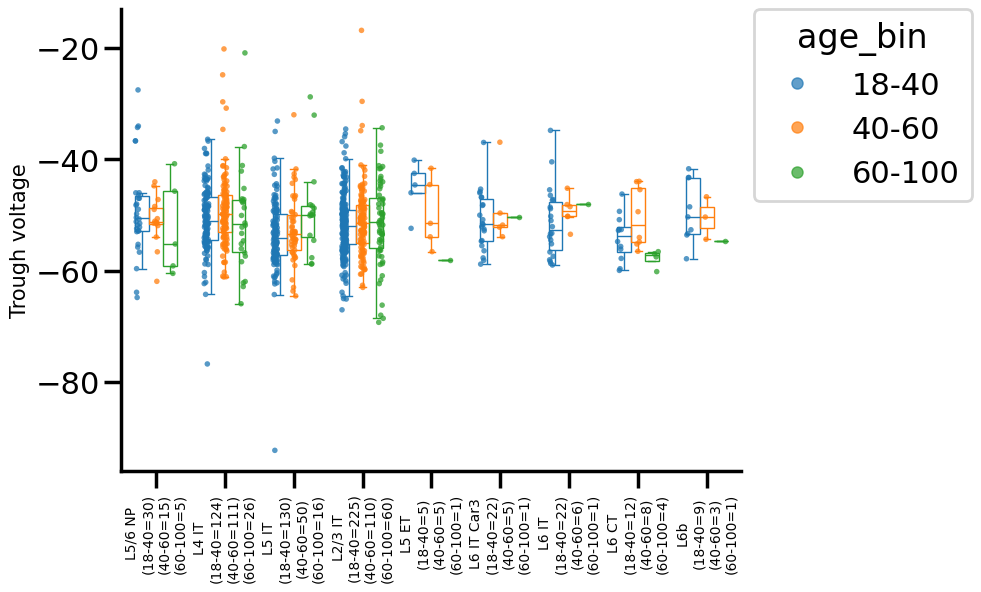

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


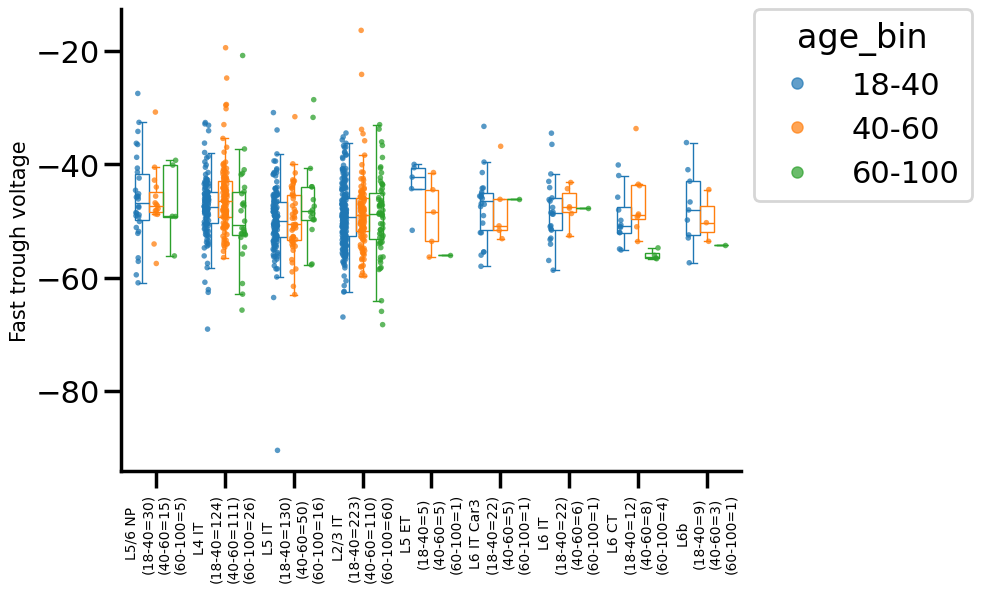

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


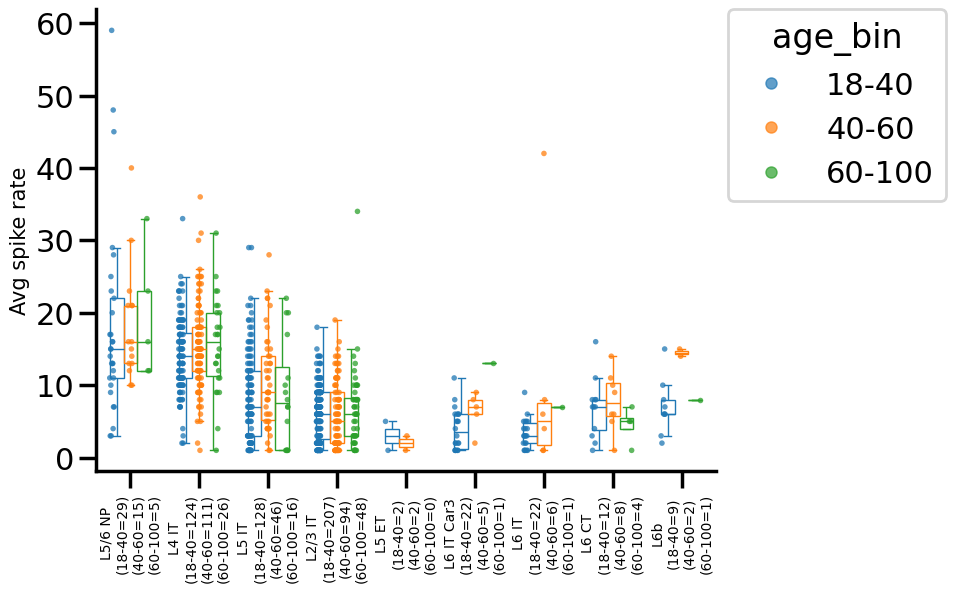

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


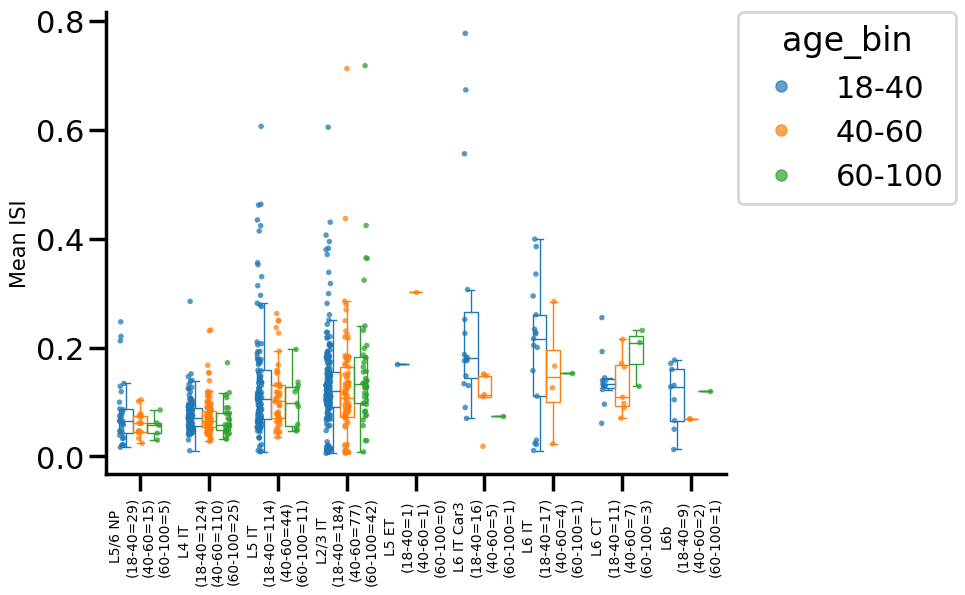

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


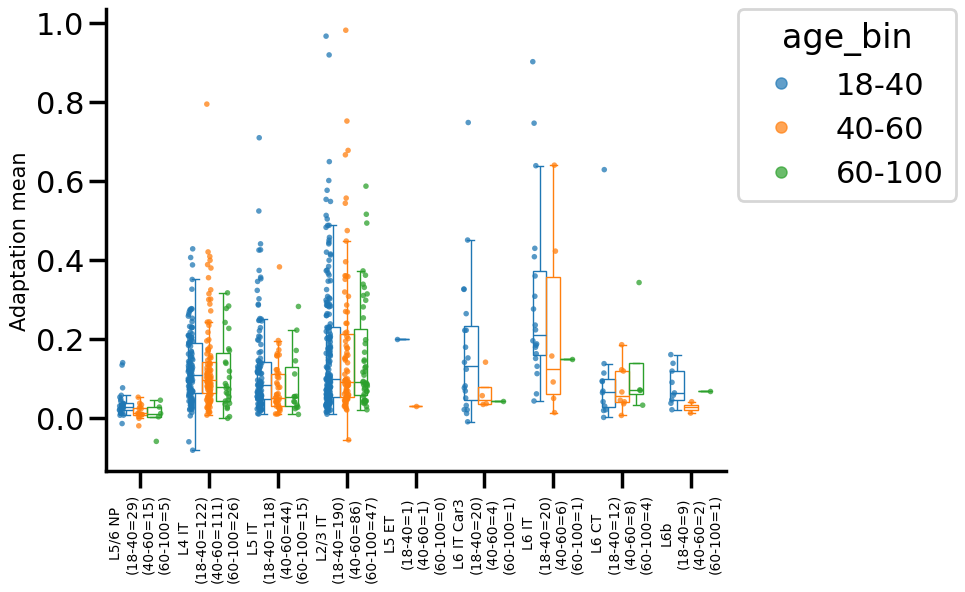

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


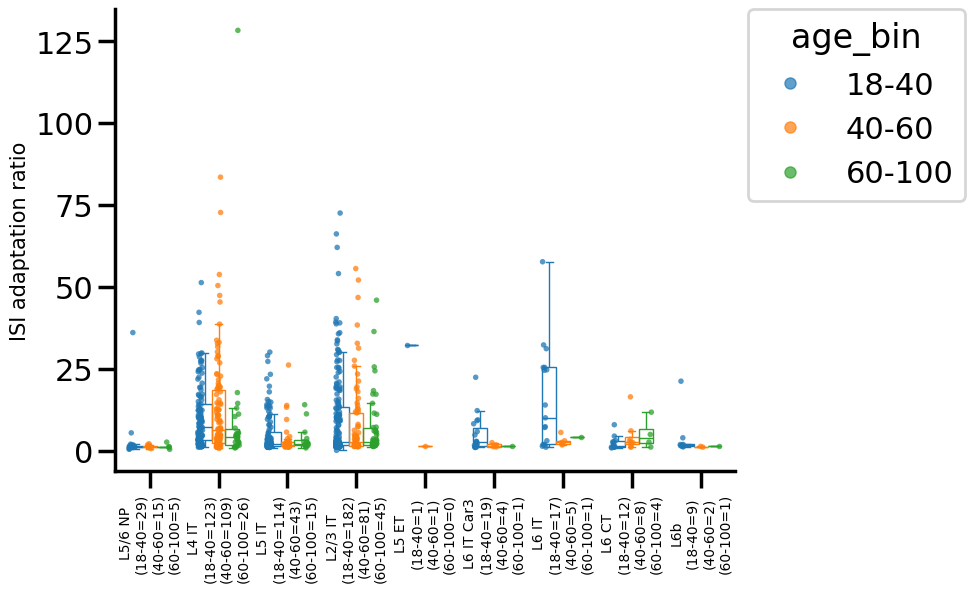

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


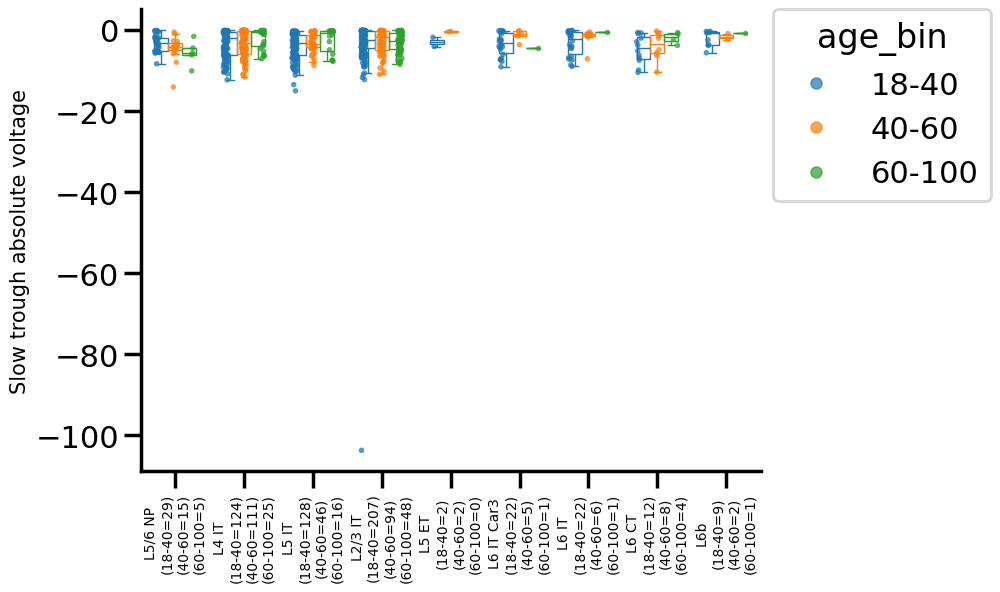

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:1.033e-04
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:3.847e-03
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.807e-03
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:4.234e-04
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:8.173e-04
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.193e-05


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


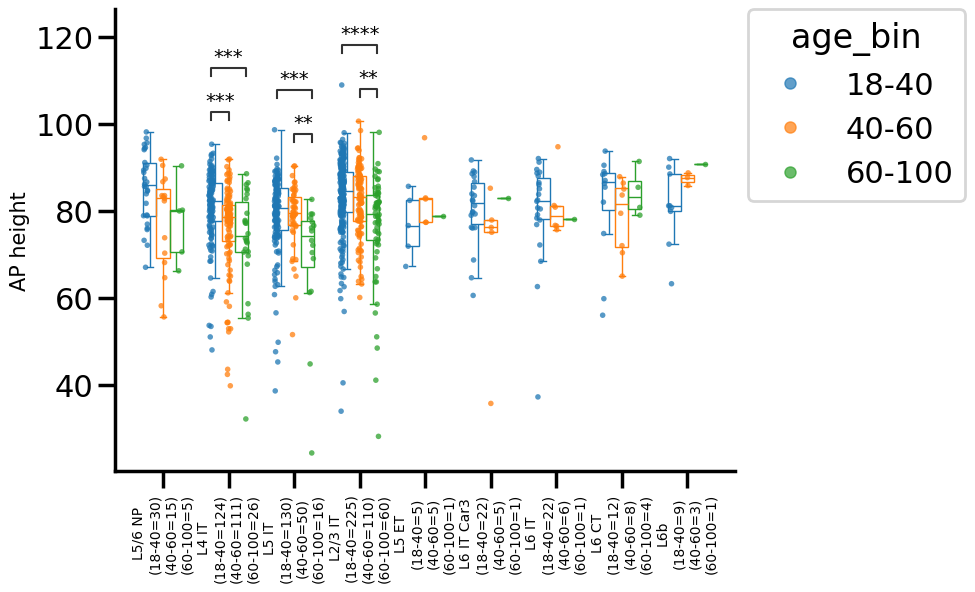

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


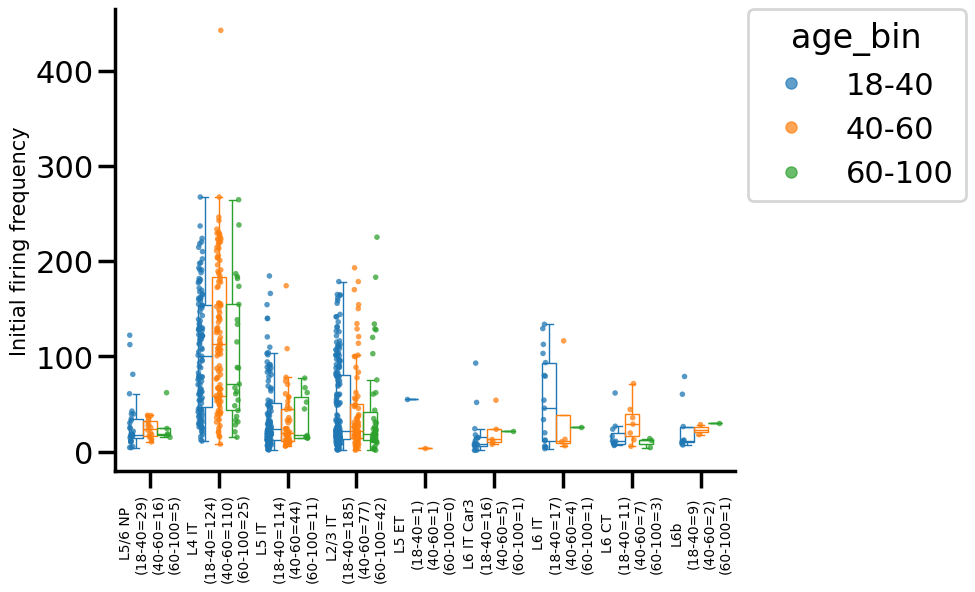

In [17]:
#compute KW - FDR - Dunn stats for all medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'age_bin'
group_order = sorted(sorted_clean_data[group_var].unique().tolist())
group_order.remove('unknown')
suffix = '_removeUnknown'
features = feature_cols.copy()
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR{suffix}.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


Cross sex box plots - subclass

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


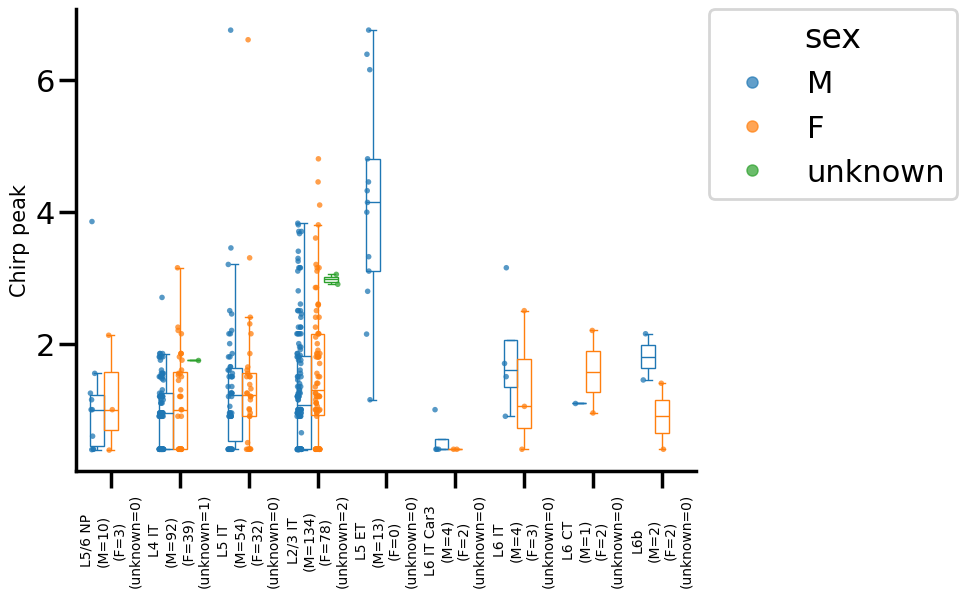

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


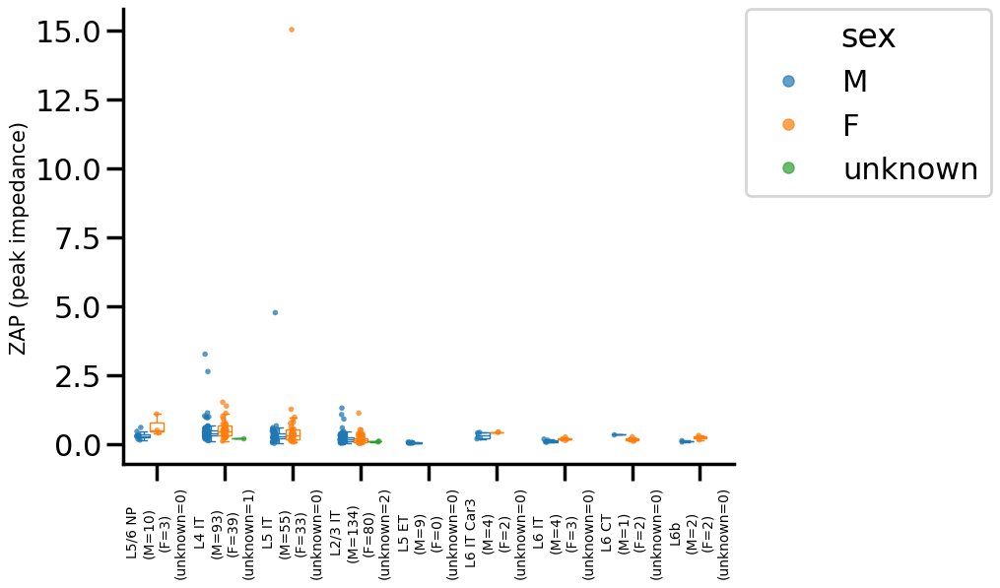

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_M vs. L2/3 IT_F: Custom statistical test, P_val:4.831e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


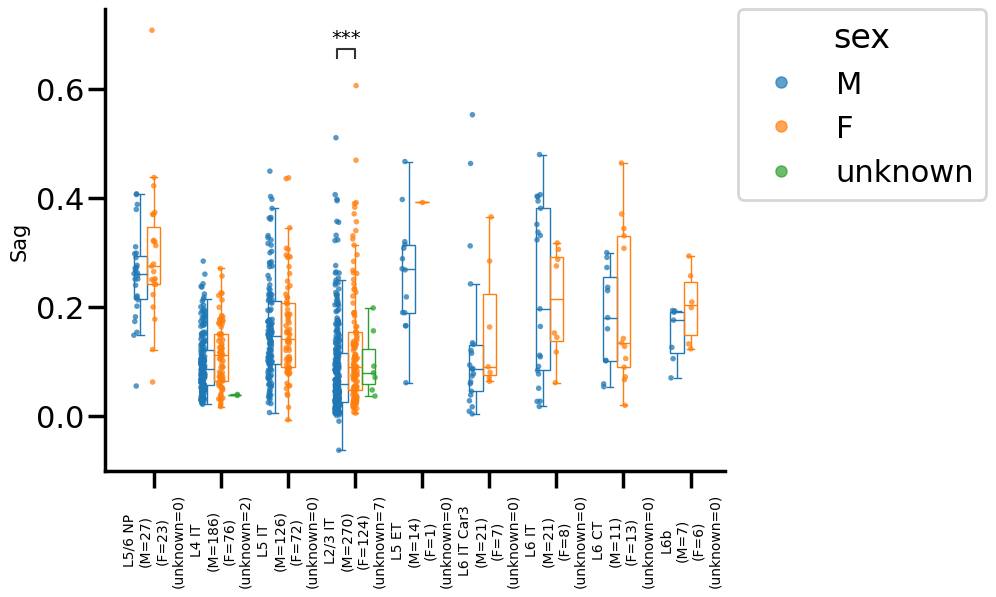

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


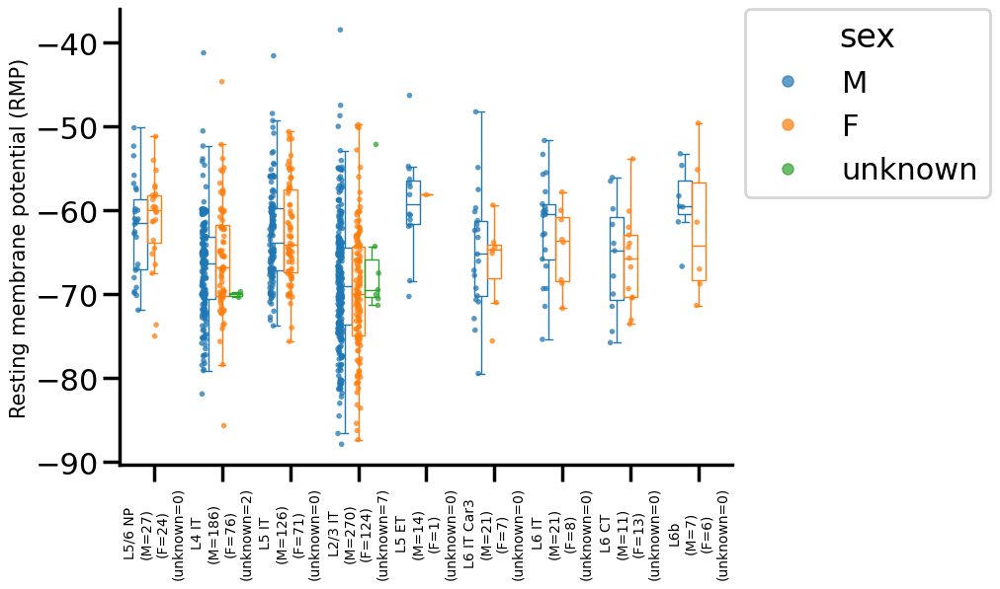

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


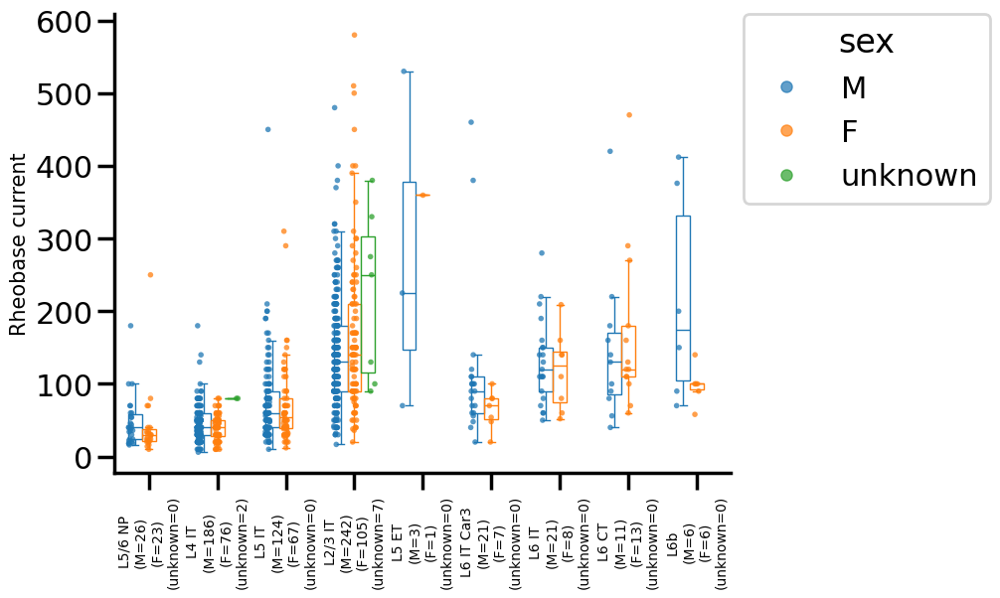

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


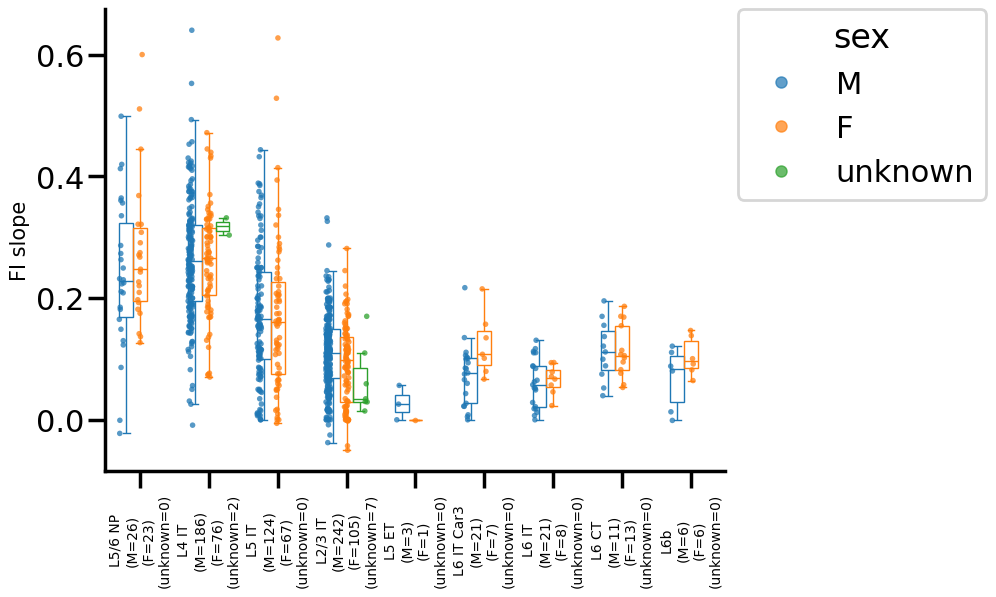

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


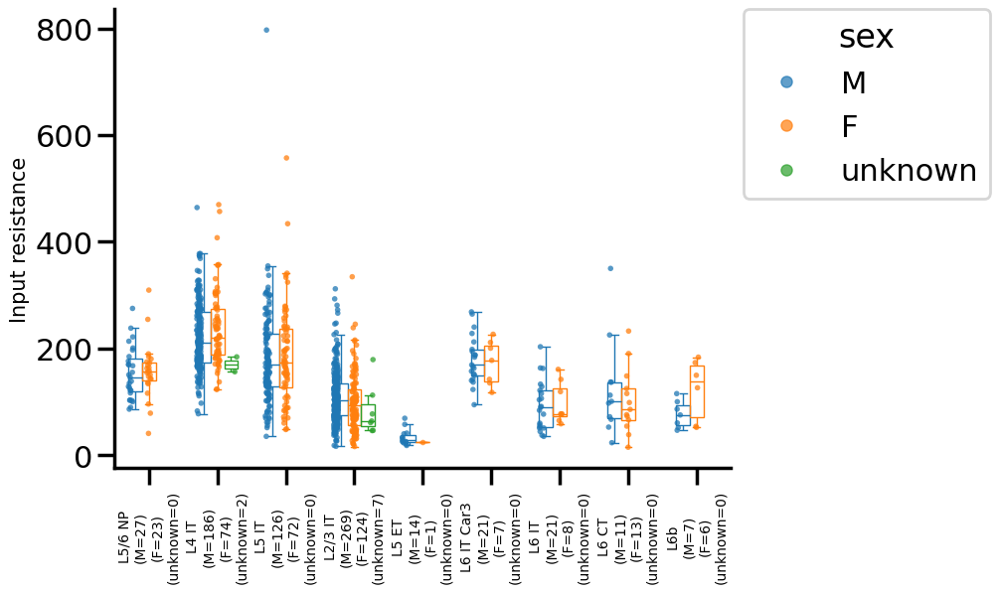

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


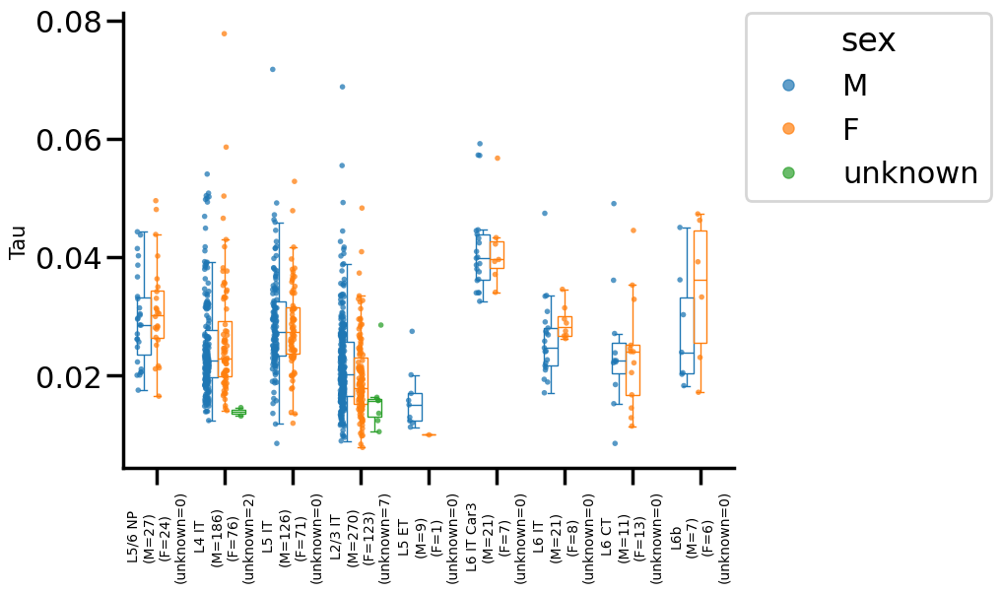

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_M vs. L2/3 IT_F: Custom statistical test, P_val:8.549e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


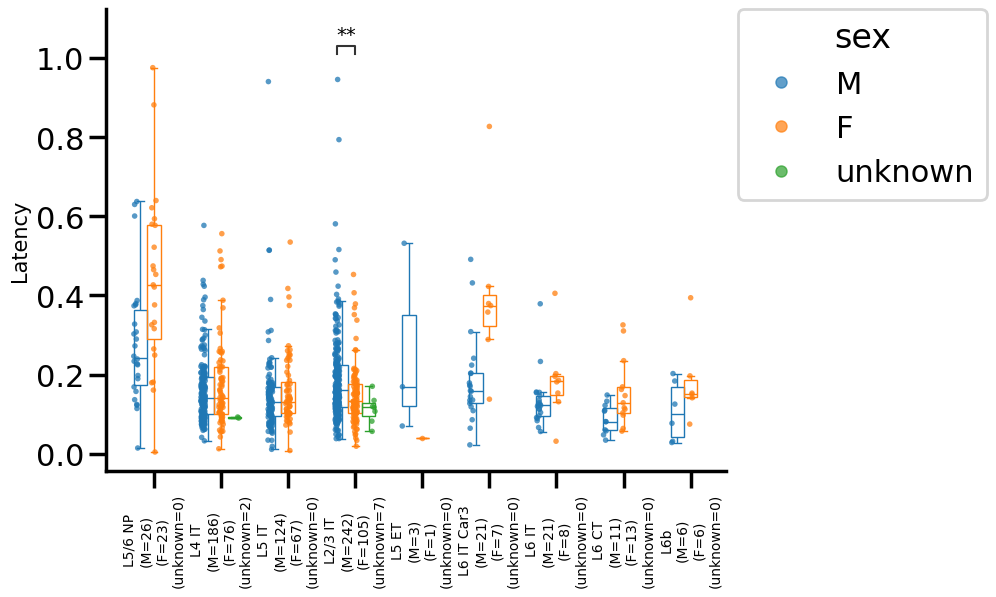

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


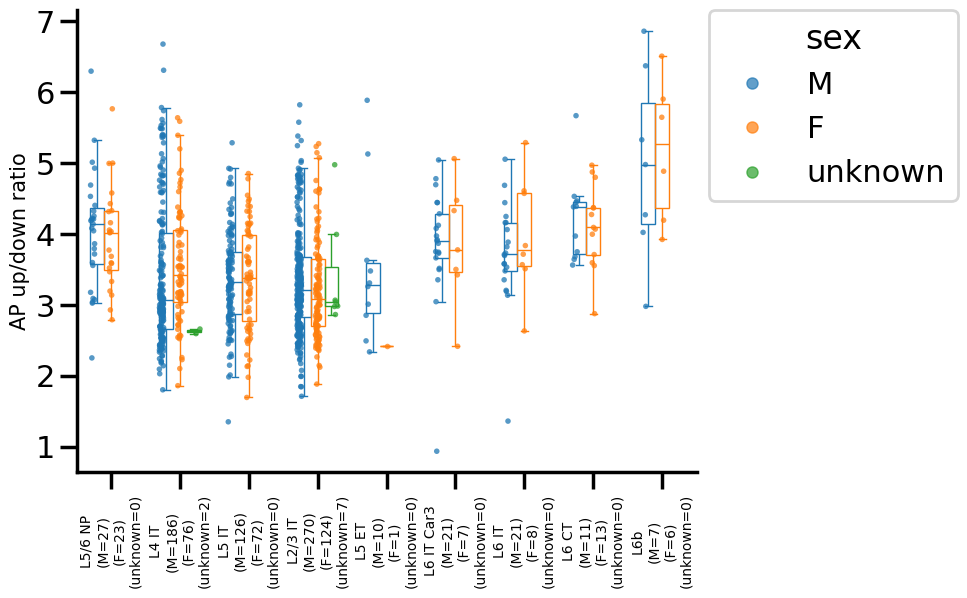

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


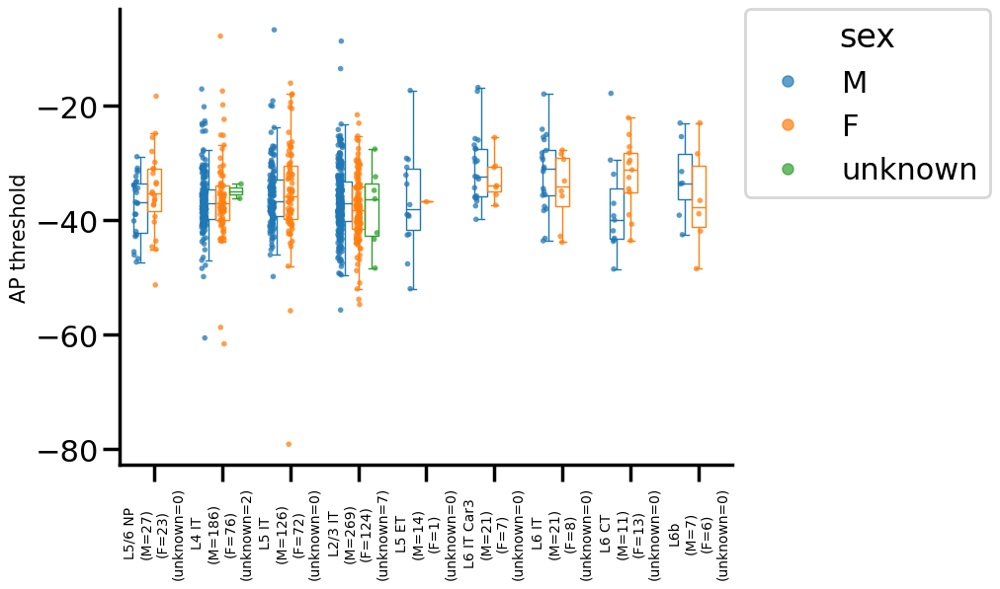

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


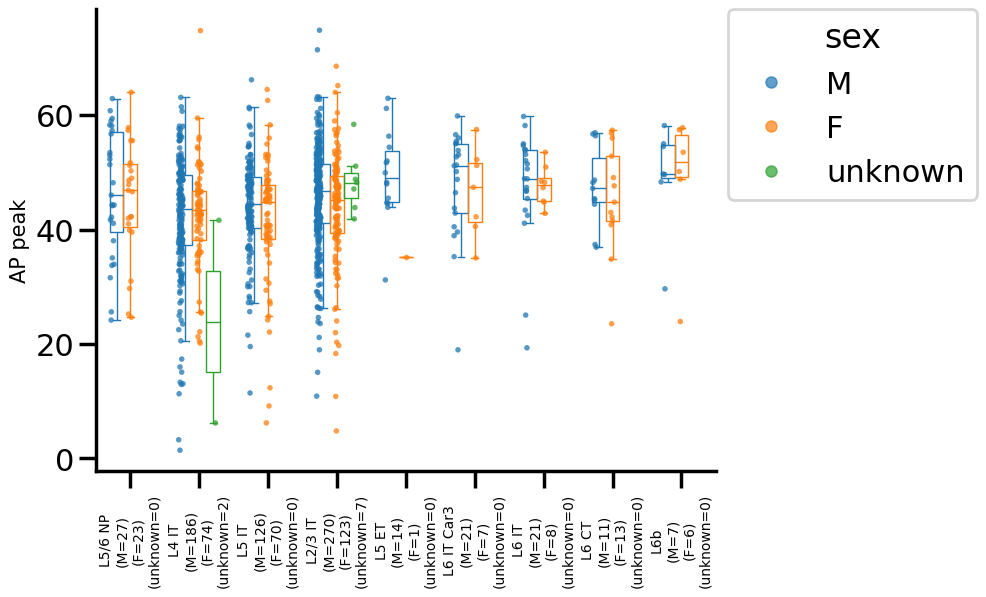

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


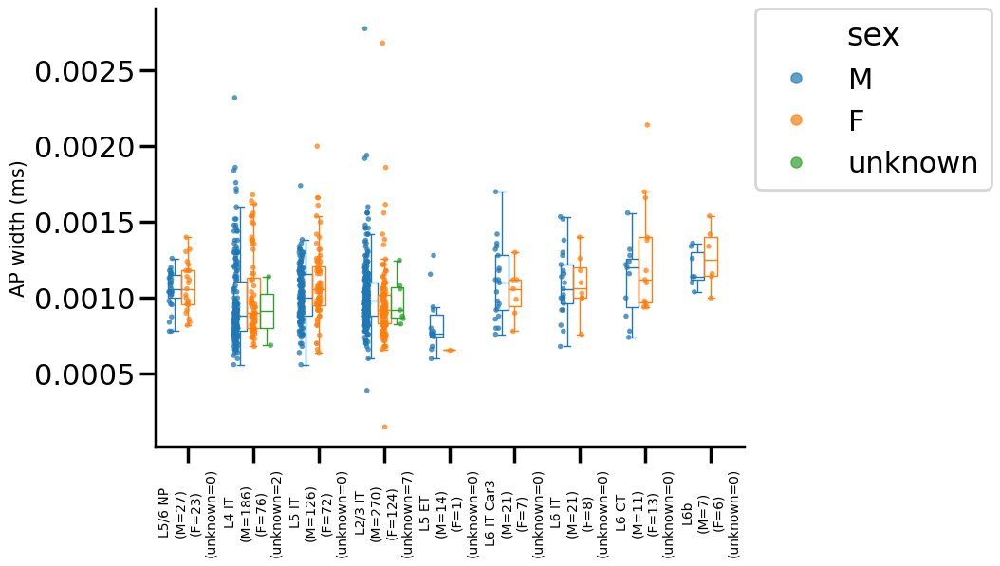

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


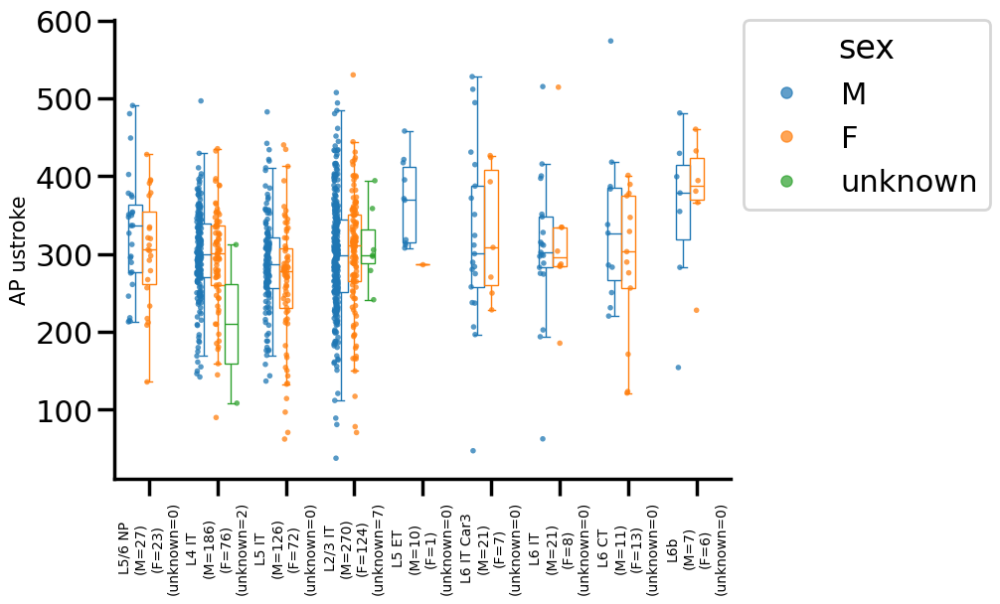

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


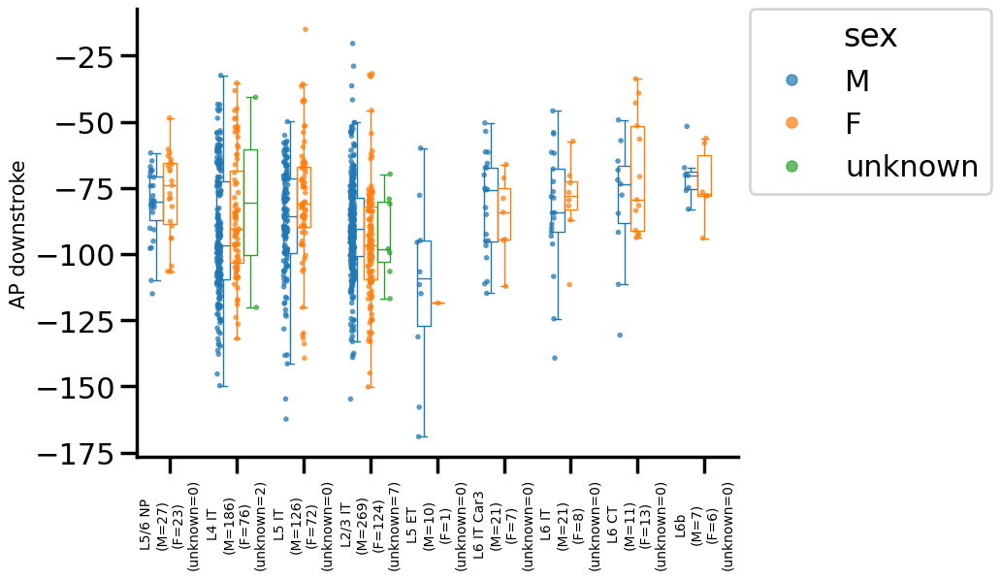

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


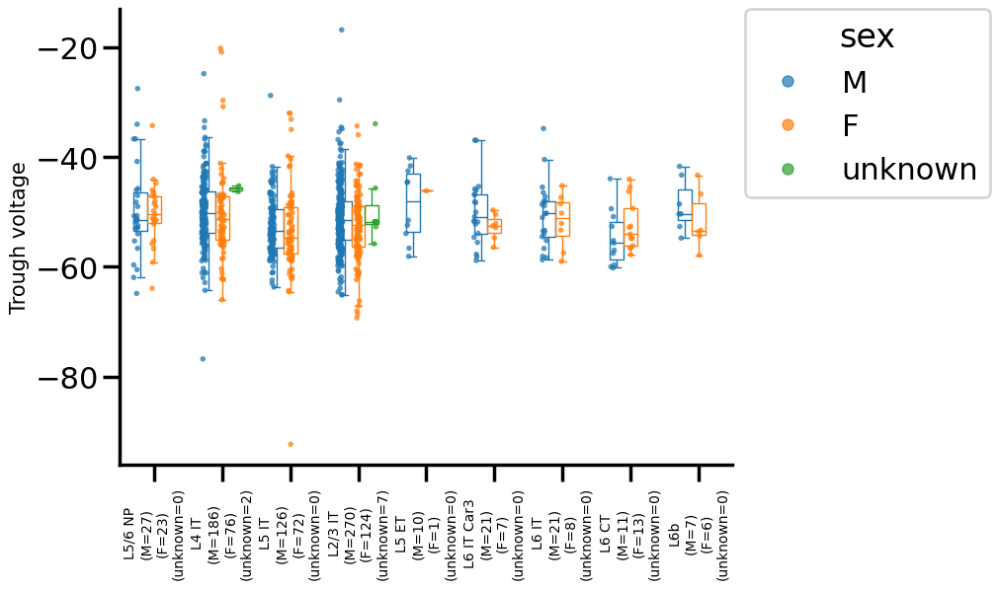

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


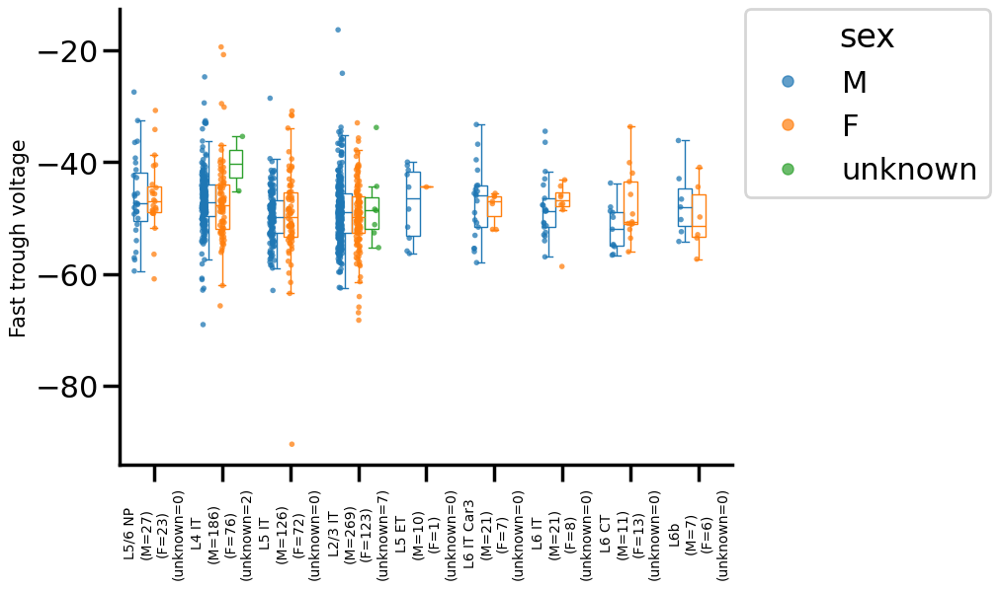

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


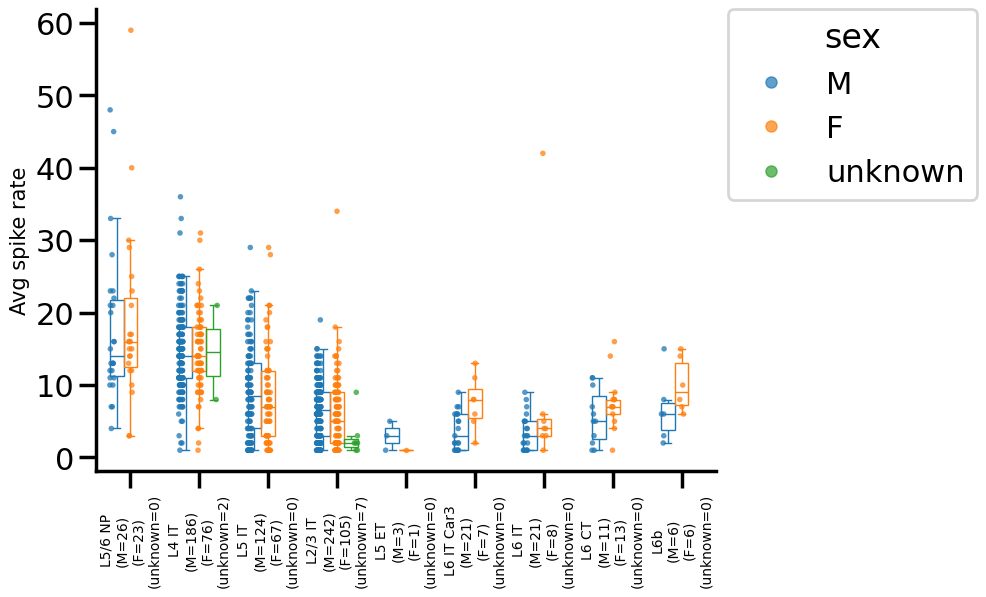

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


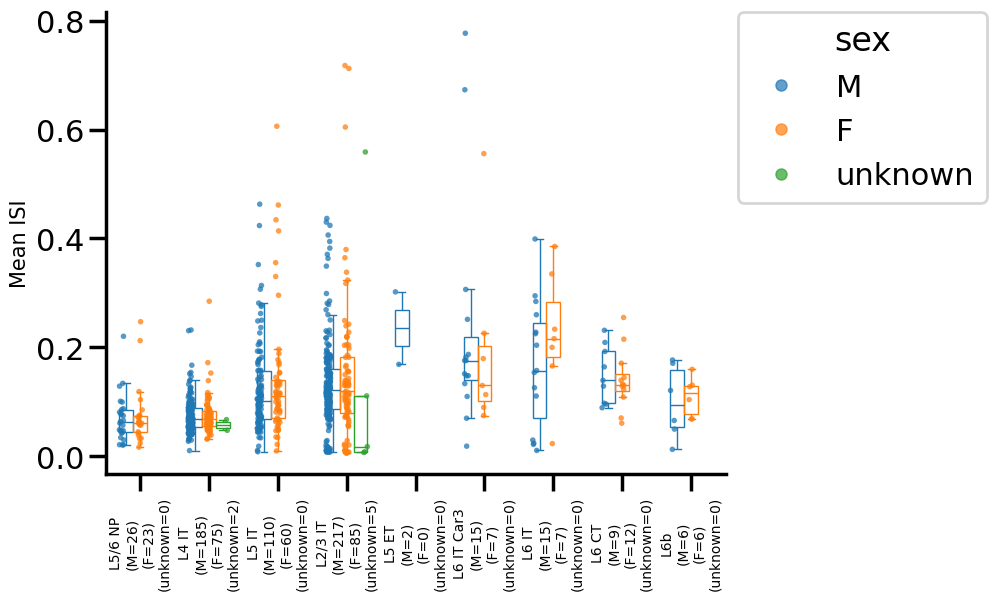

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


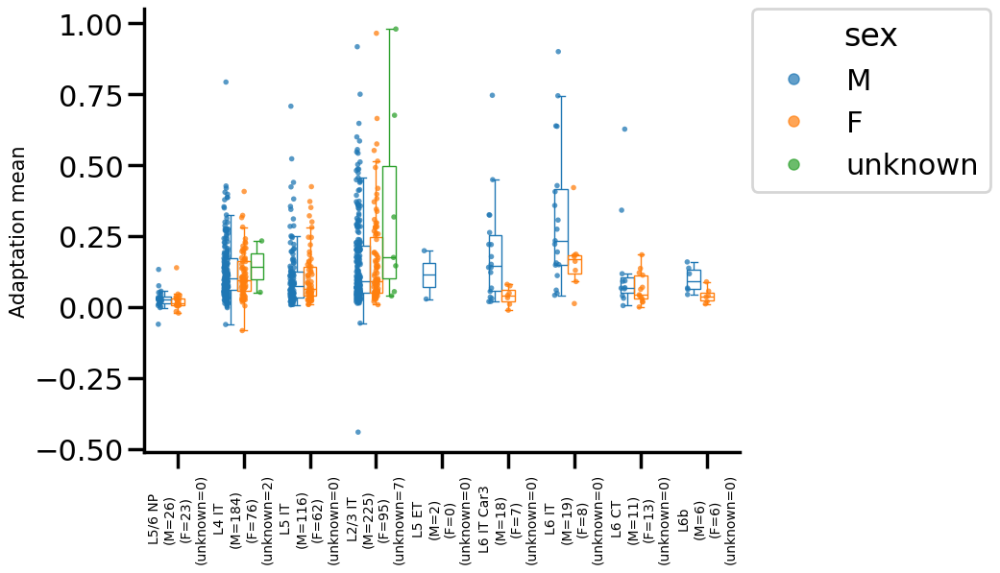

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


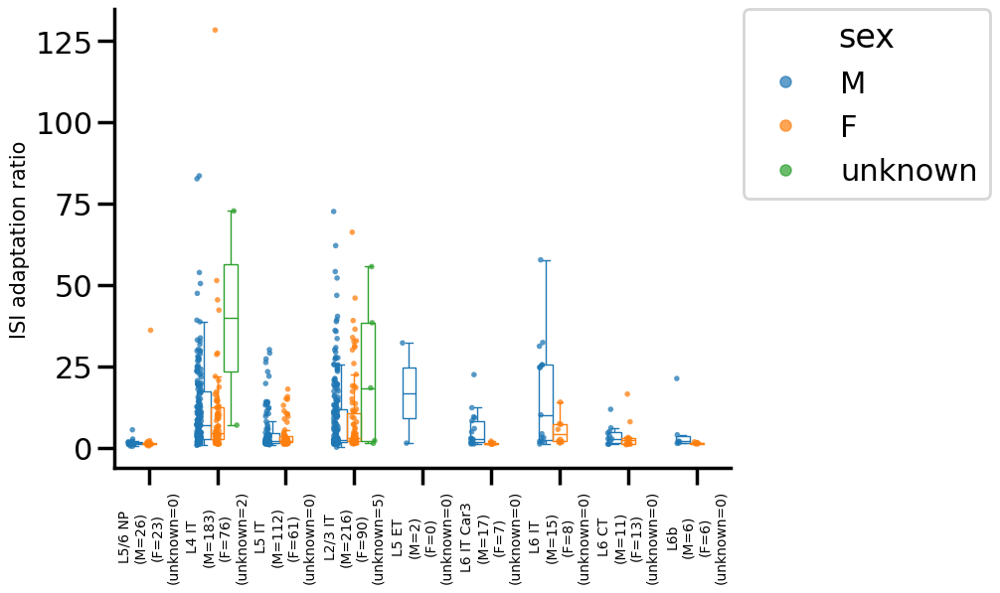

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


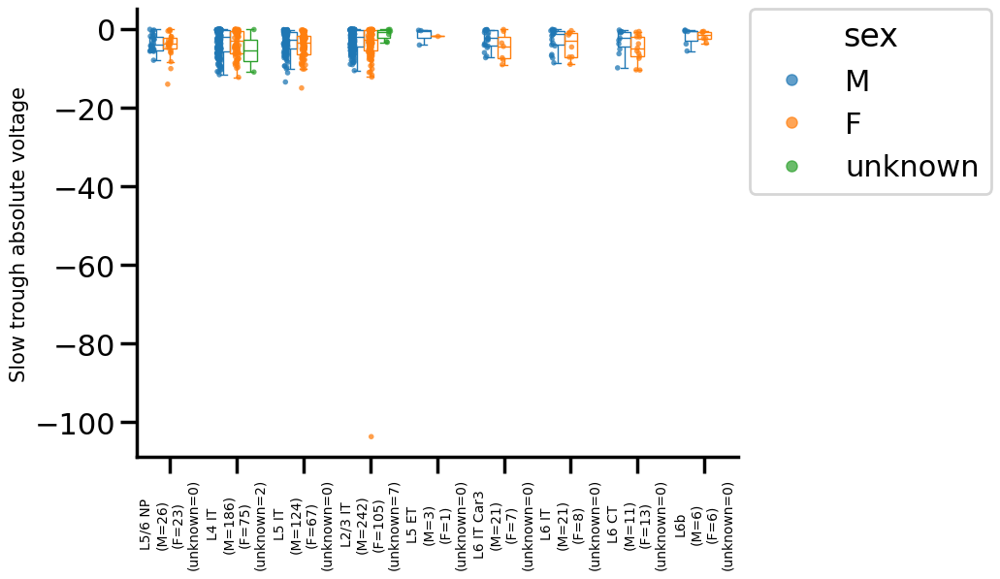

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


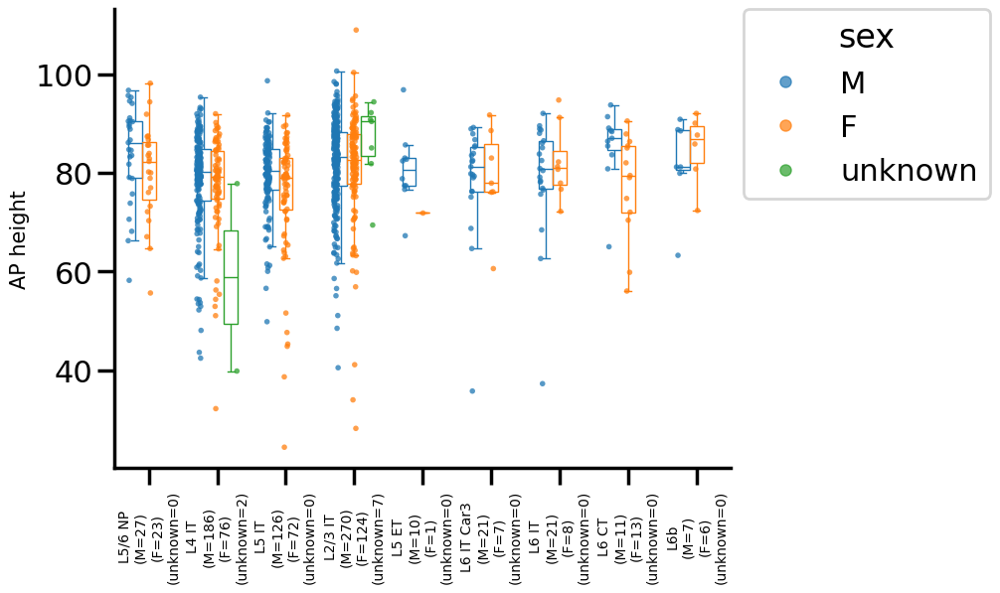

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


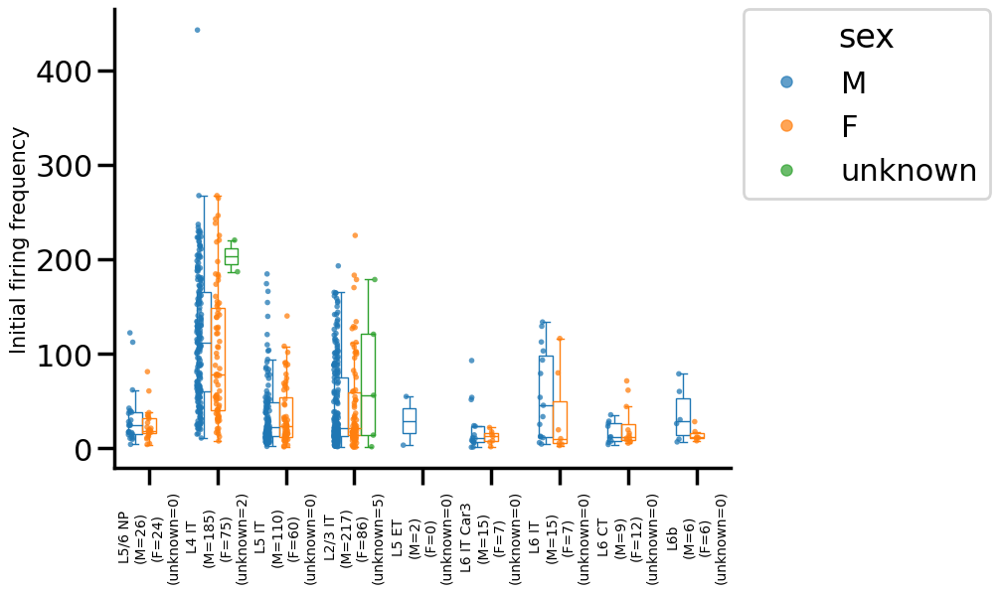

In [18]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'sex'
group_order = sorted_clean_data[group_var].unique().tolist()
features = feature_cols.copy()

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing cells with `unknown` sex

1044


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_F vs. L2/3 IT_M: Custom statistical test, P_val:2.563e-03


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_F vs. L2/3 IT_M: Custom statistical test, P_val:4.466e-02


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


... (4 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_F vs. L2/3 IT_M: Custom statistical test, P_val:4.624e-03


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_F vs. L2/3 IT_M: Custom statistical test, P_val:1.952e-02


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

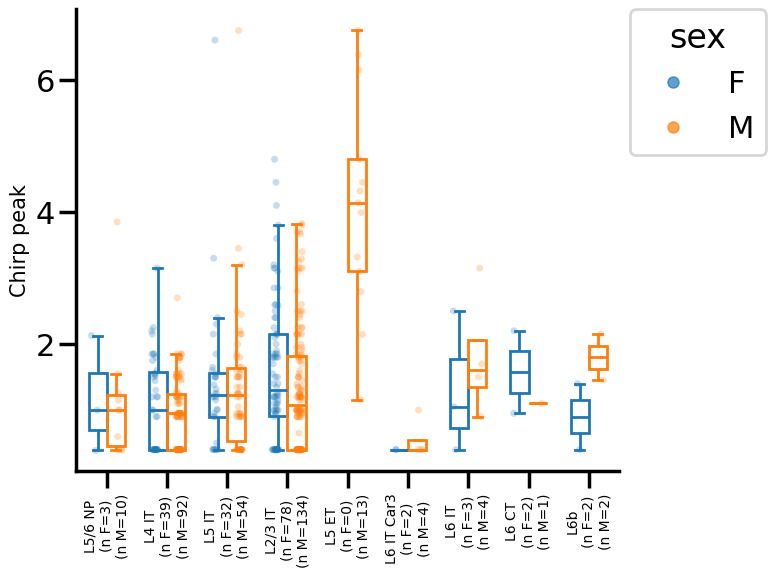

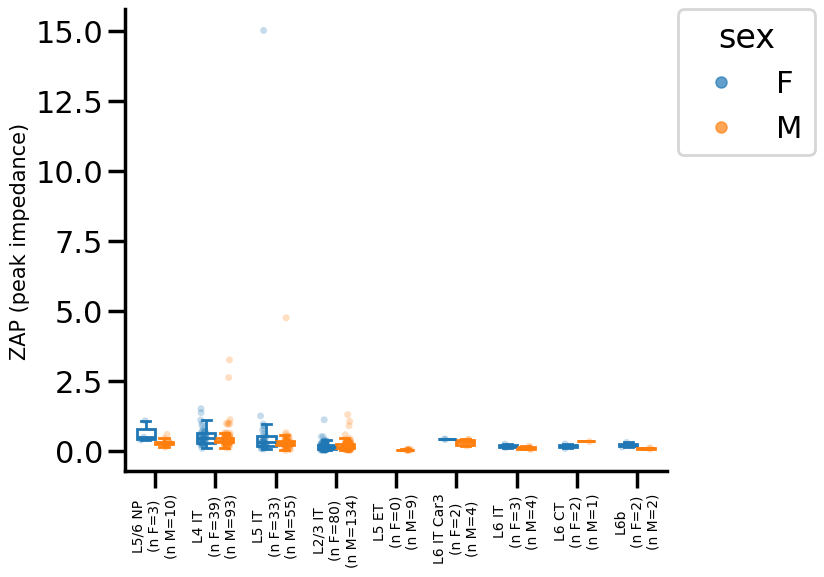

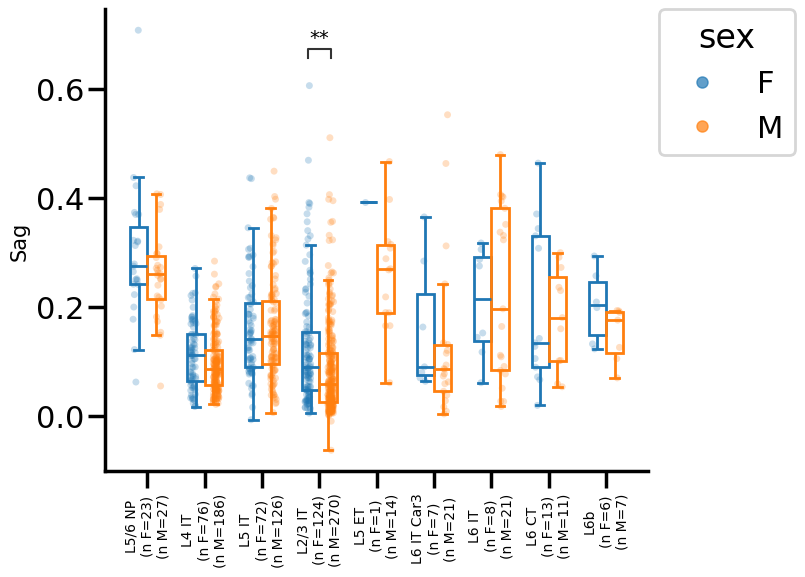

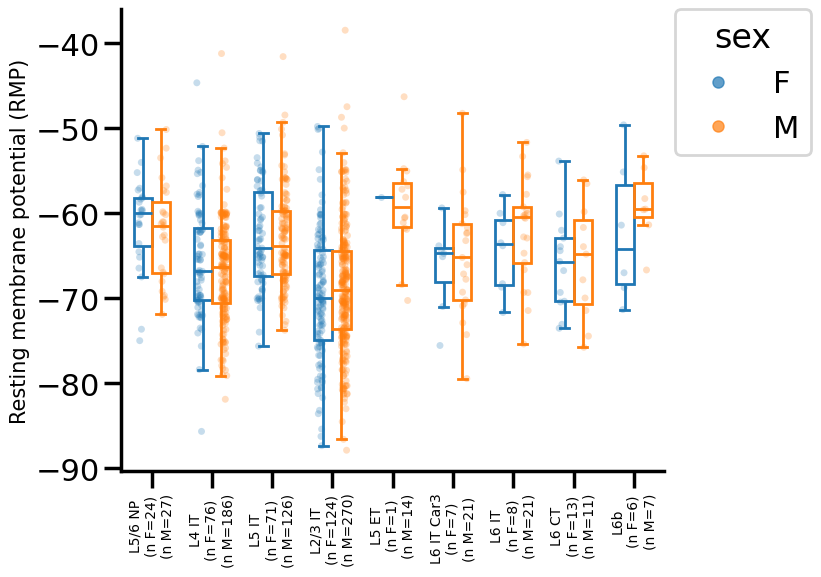

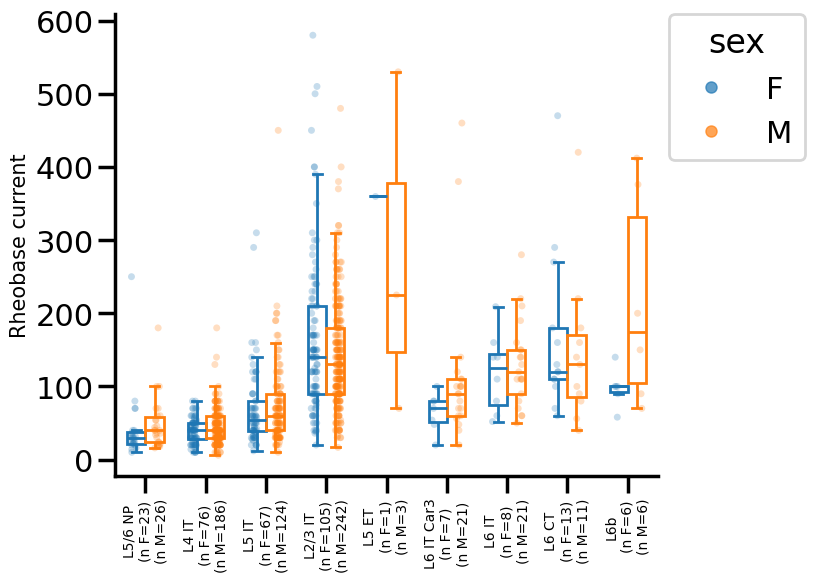

...

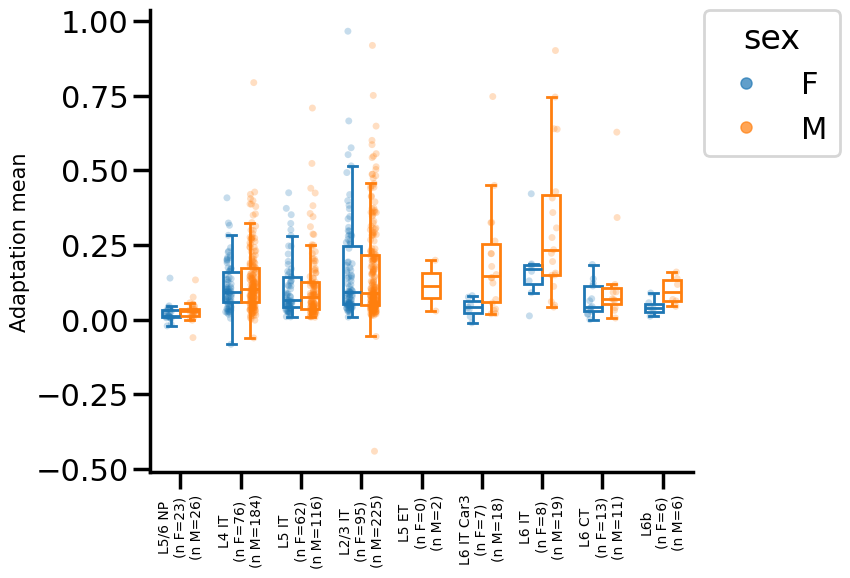

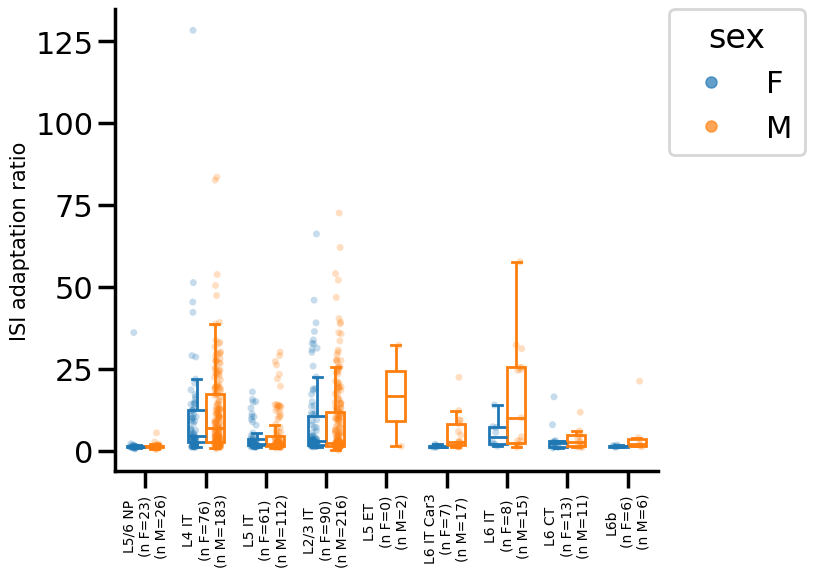

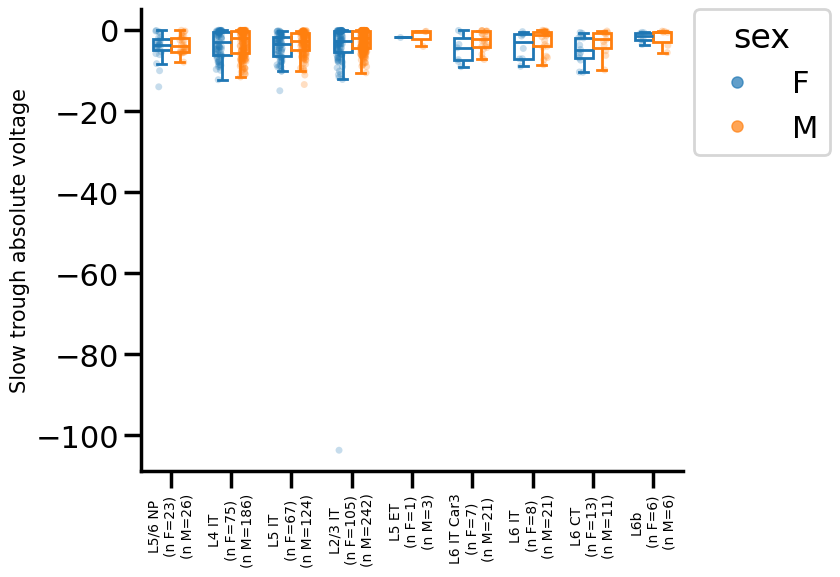

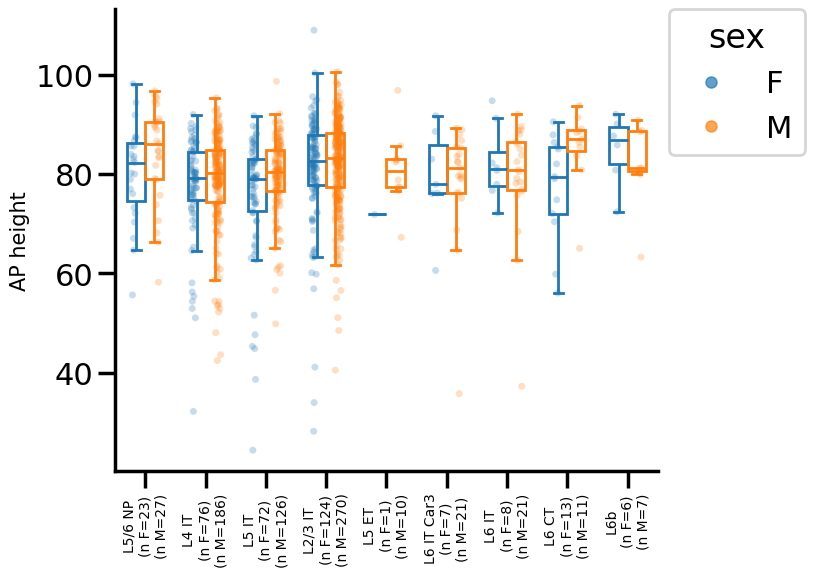

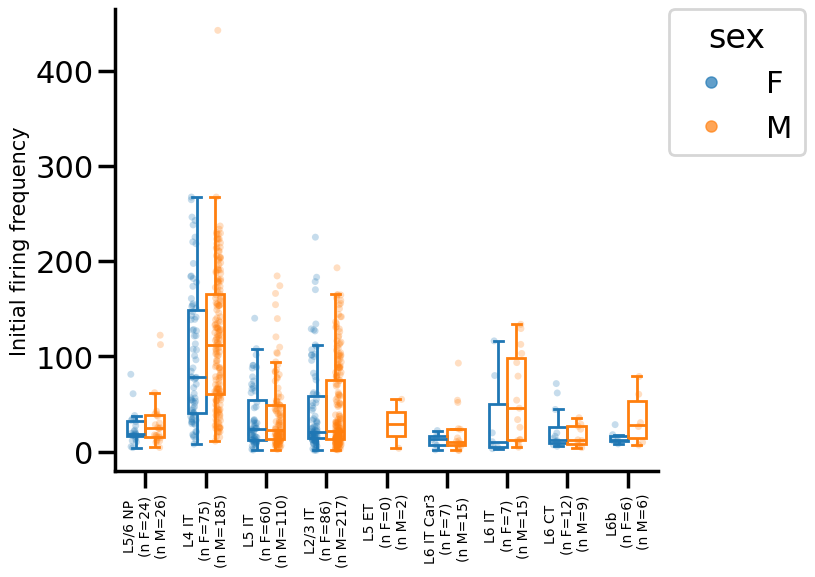

In [21]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'sex'
group1_label = 'F'
group2_label = 'M'
suffix = '_removeUnknown'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order))
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross lab box plots - subclass

/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]


/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


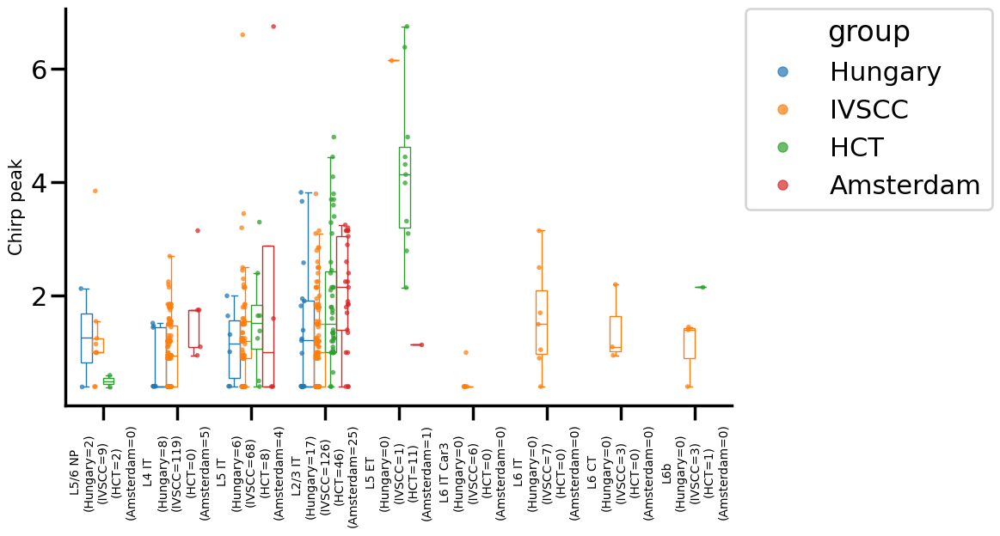

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:2.868e-02
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:2.868e-02
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.868e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


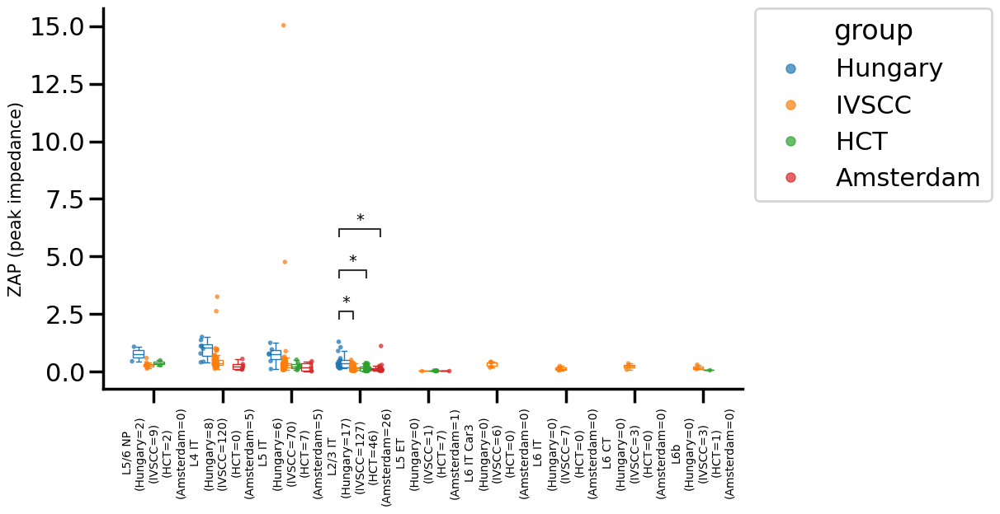

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:2.250e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.113e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


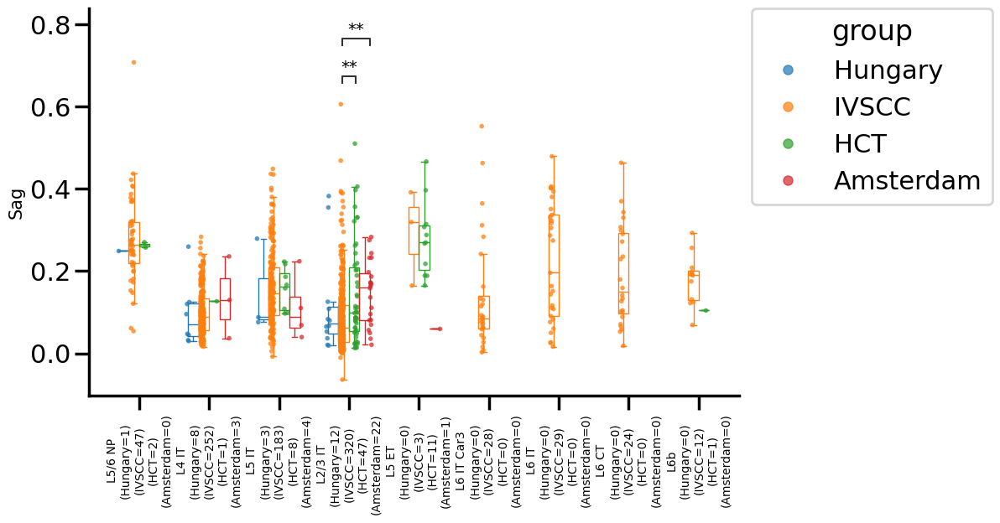

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_HCT vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.247e-02
L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:2.242e-02
L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:2.586e-09


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


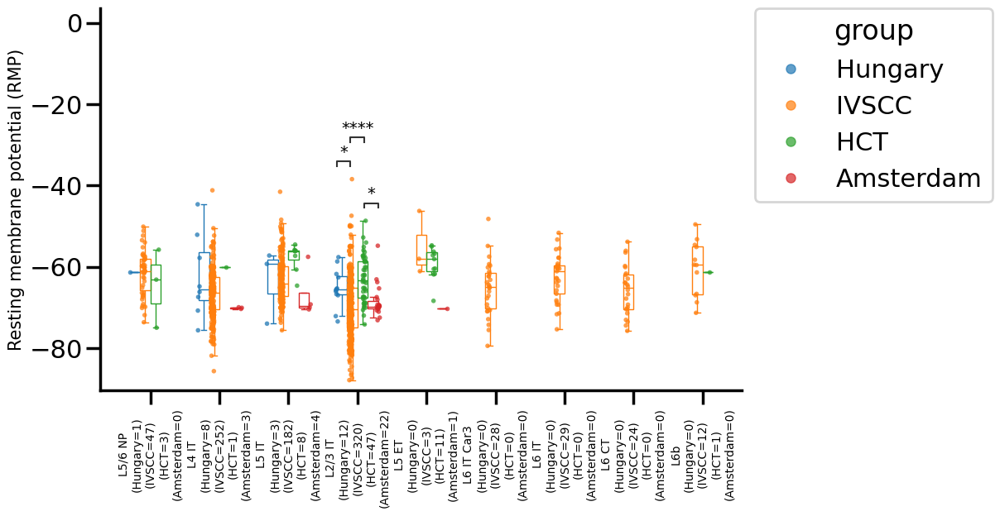

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


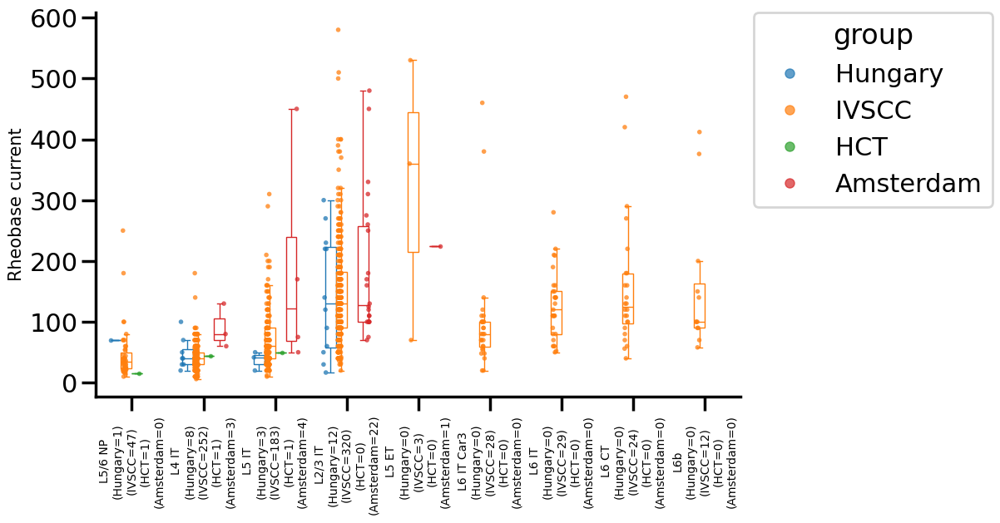

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


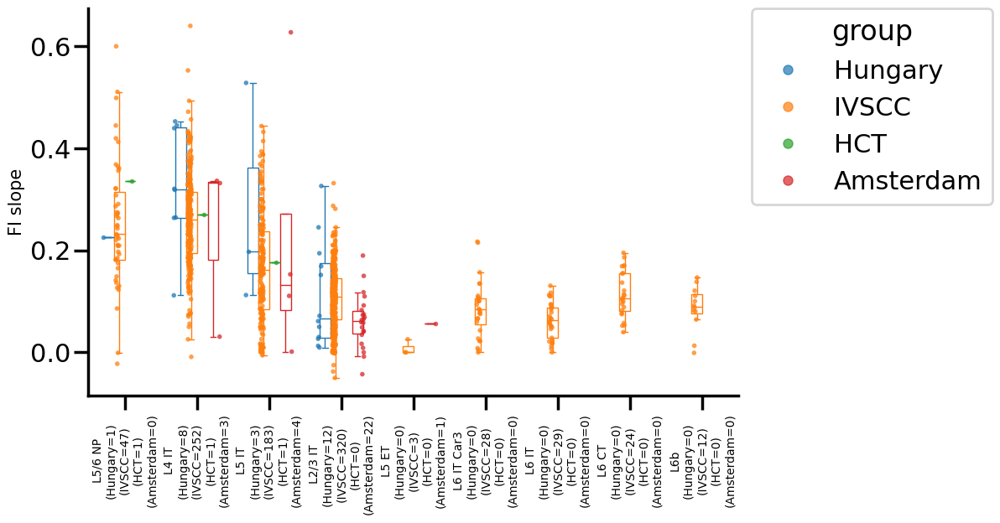

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


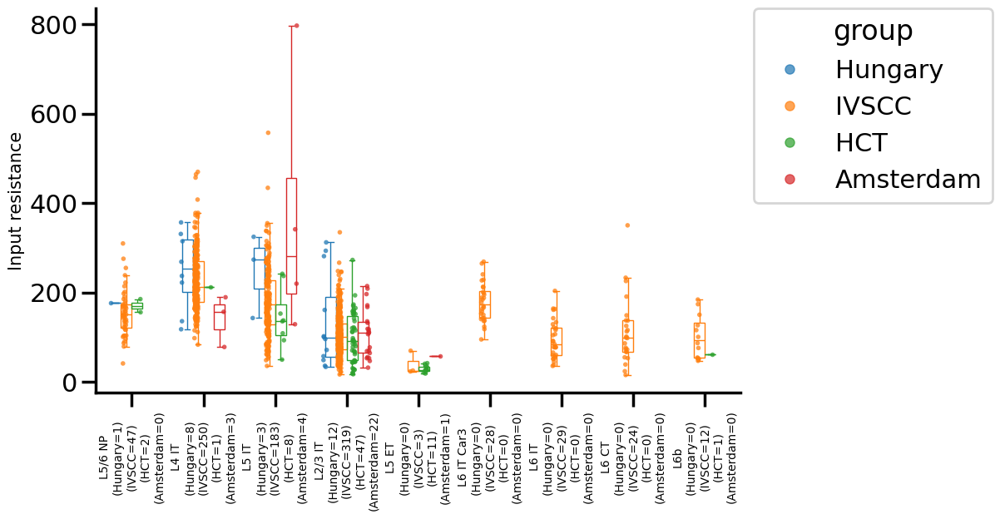

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


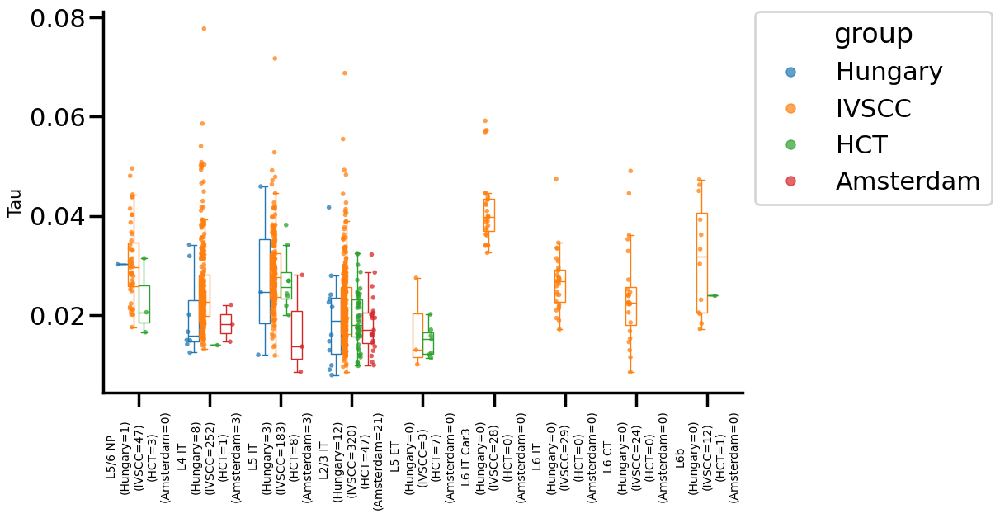

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


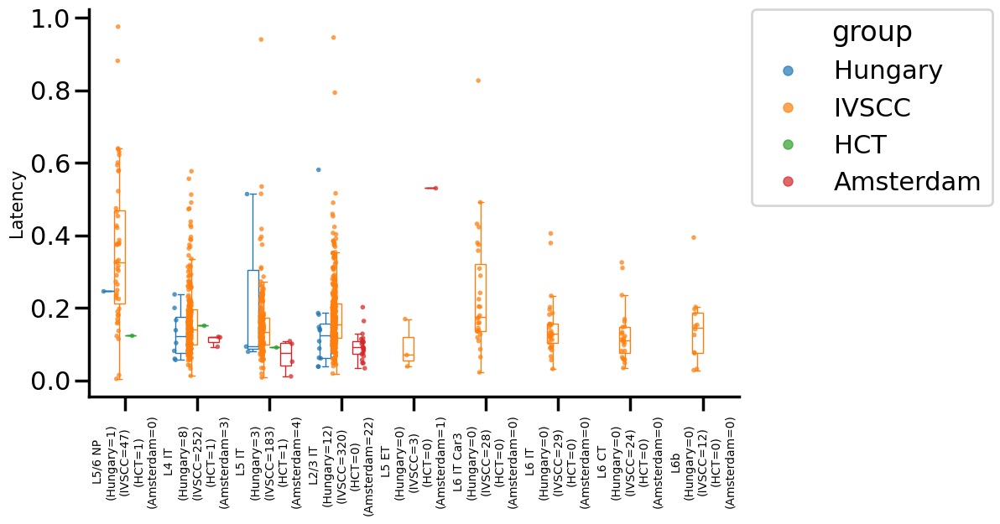

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_HCT vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.155e-02
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:7.982e-03
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.589e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


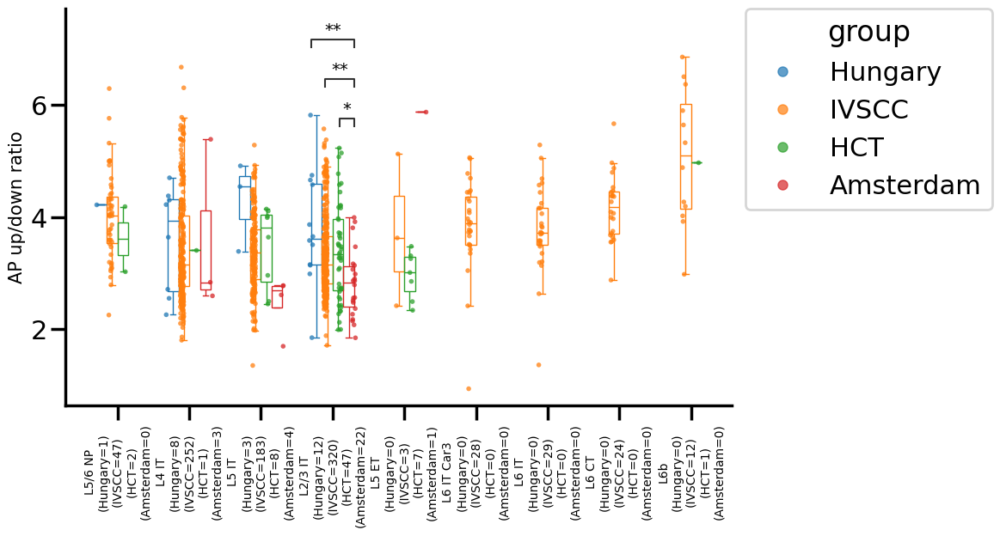

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


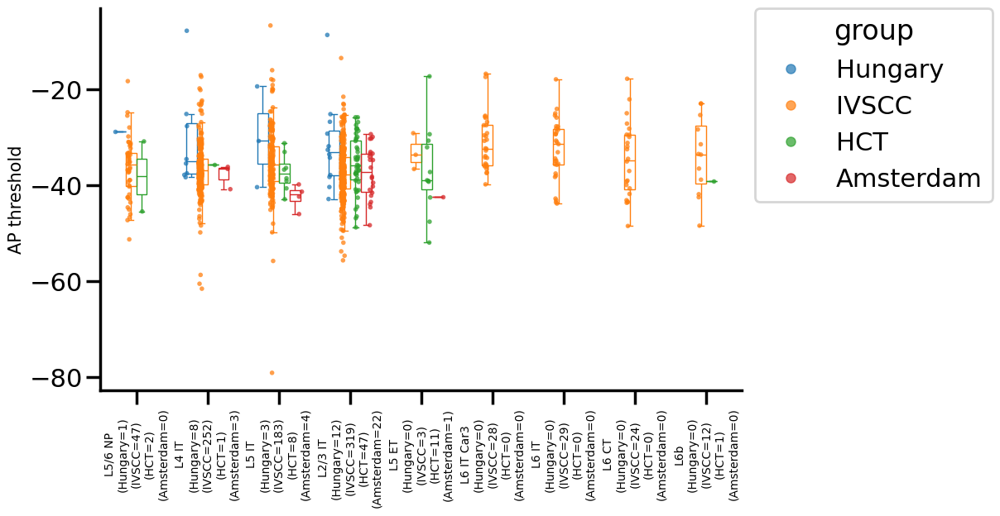

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_HCT vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.005e-02
L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:1.505e-03
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:3.086e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.086e-03
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.255e-05


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


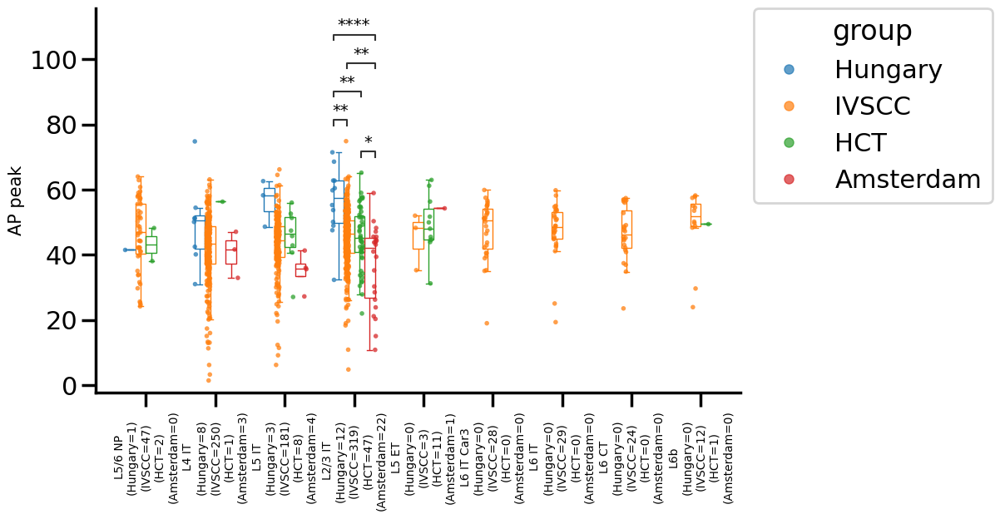

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:1.760e-04
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:1.159e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:5.452e-04
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:8.945e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


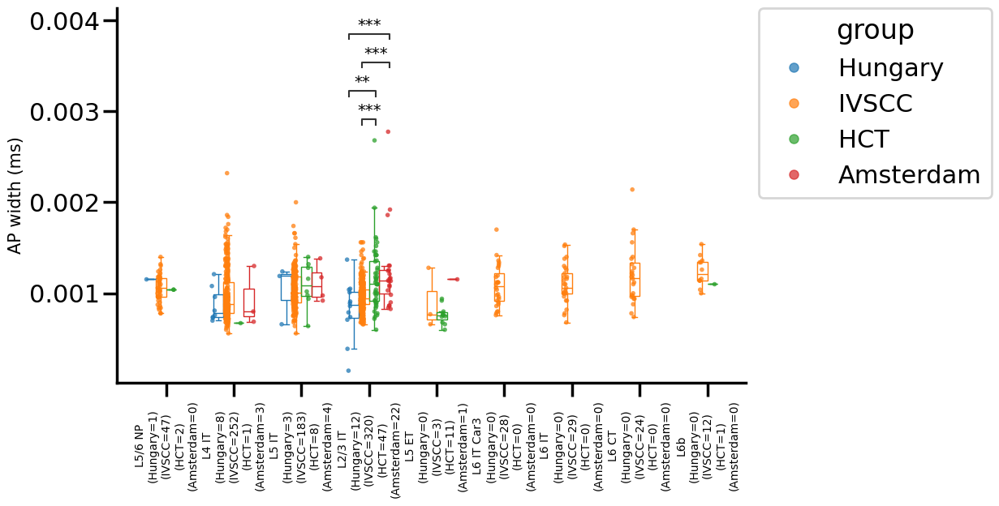

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:1.106e-02
L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:5.886e-04
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:9.031e-05
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.296e-05
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:8.036e-06


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


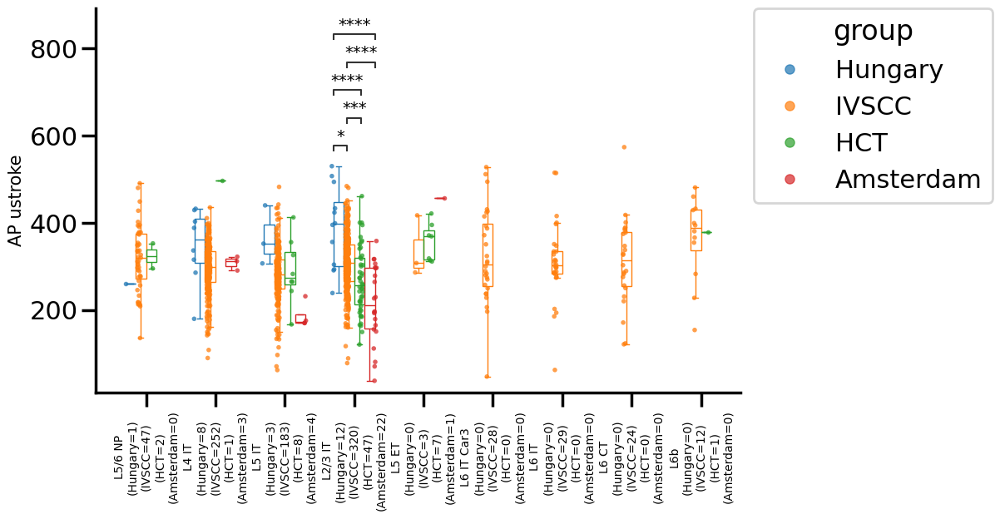

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:7.432e-04
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:4.591e-02
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:7.432e-04
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.153e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


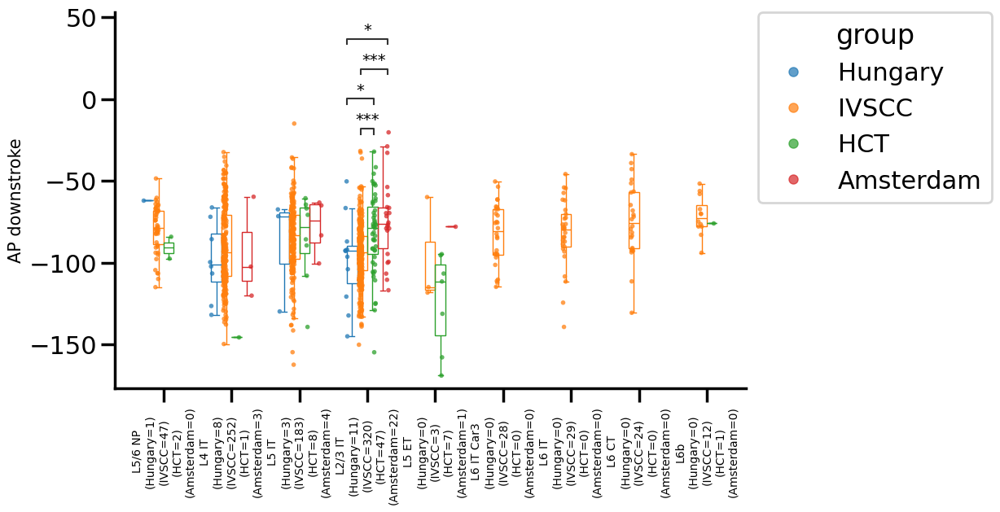

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:3.873e-02
L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:7.975e-05


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


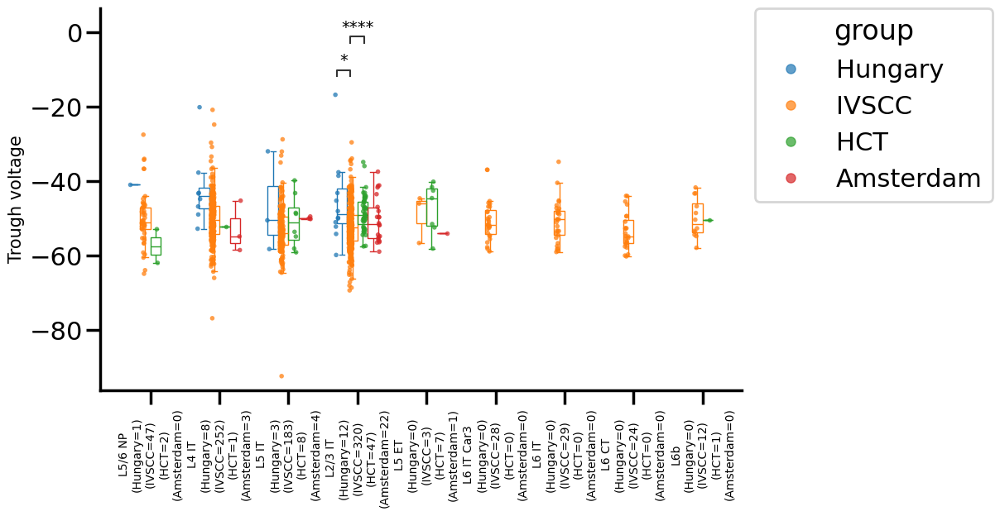

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:3.874e-02
L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:2.748e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


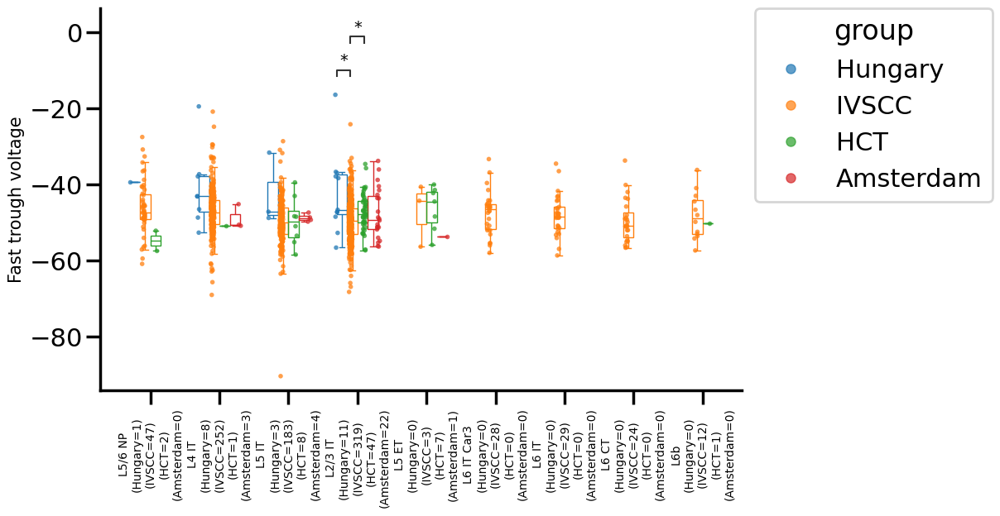

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


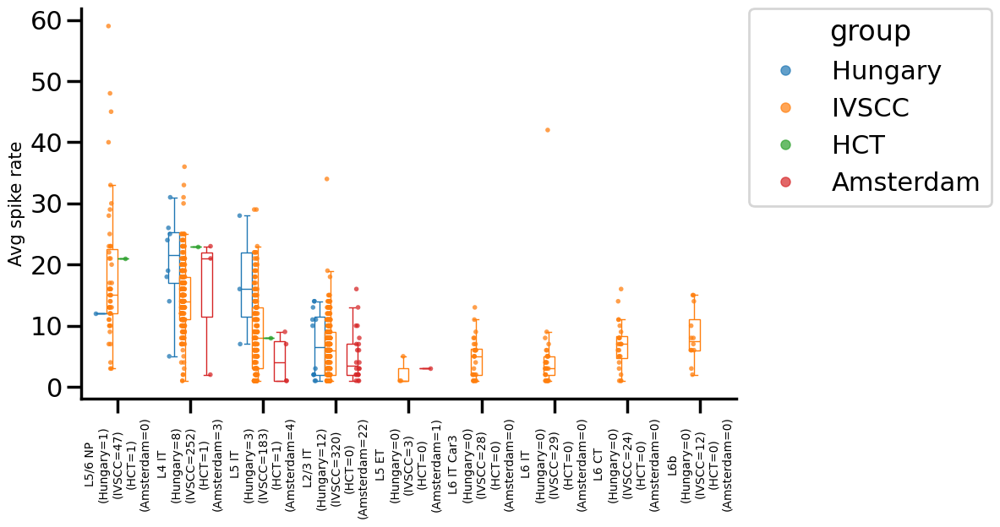

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


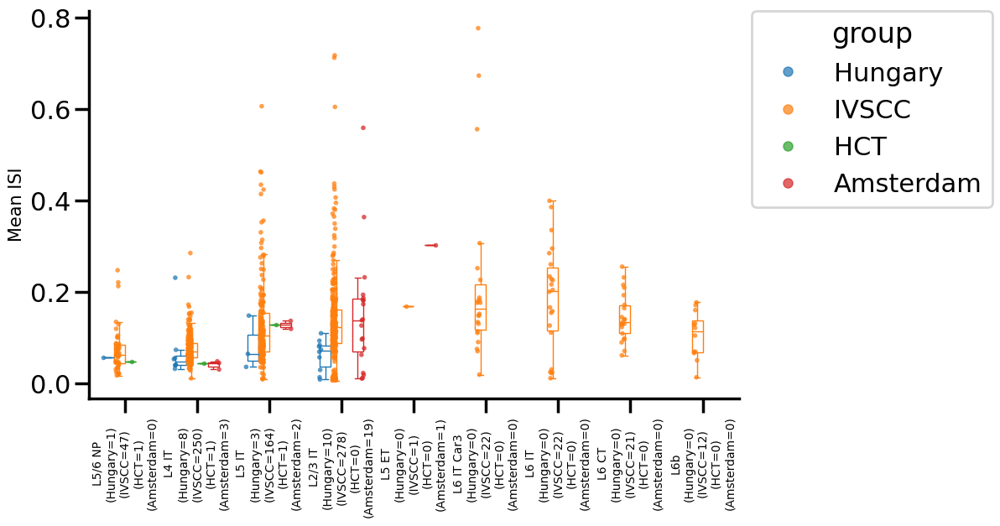

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


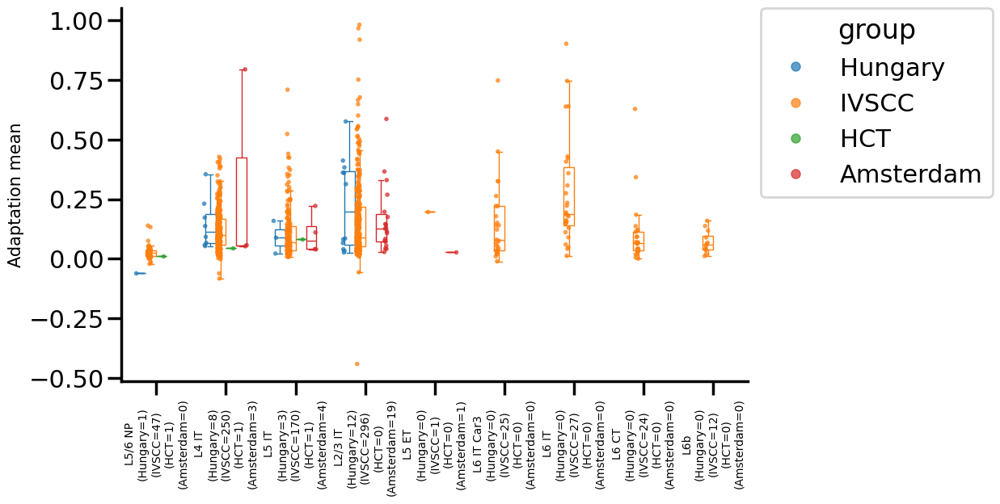

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


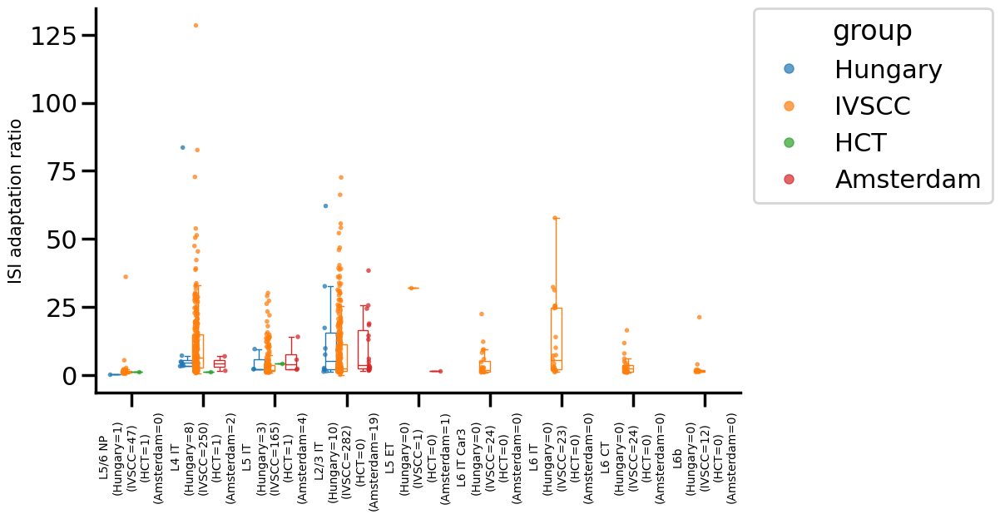

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


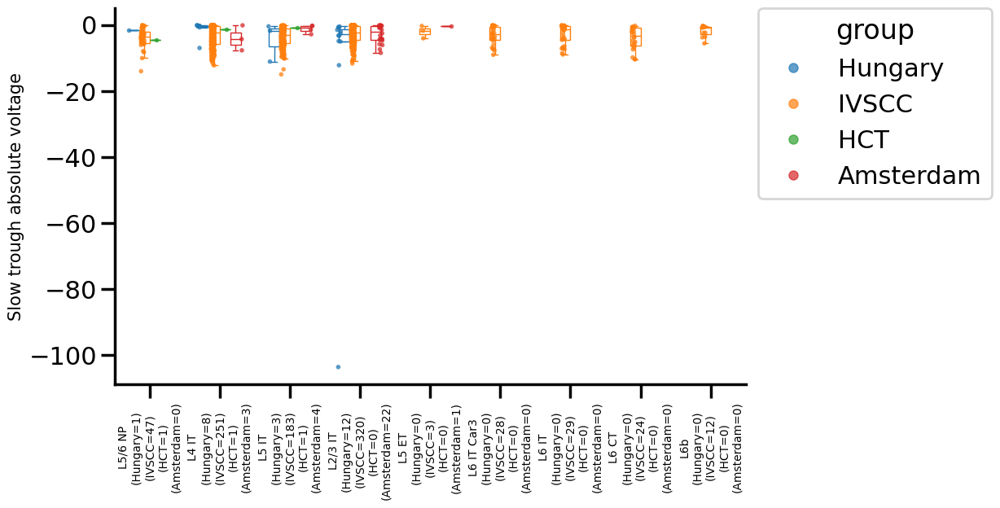

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


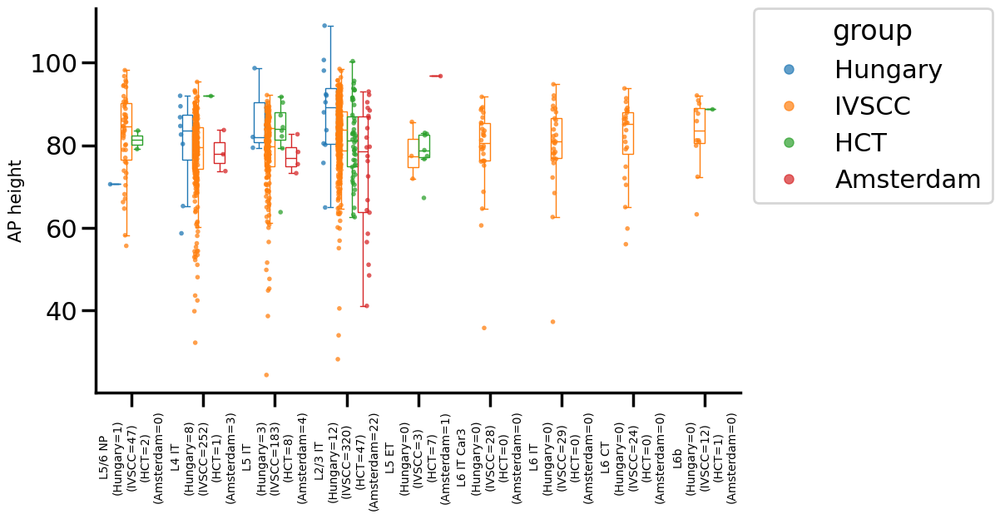

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


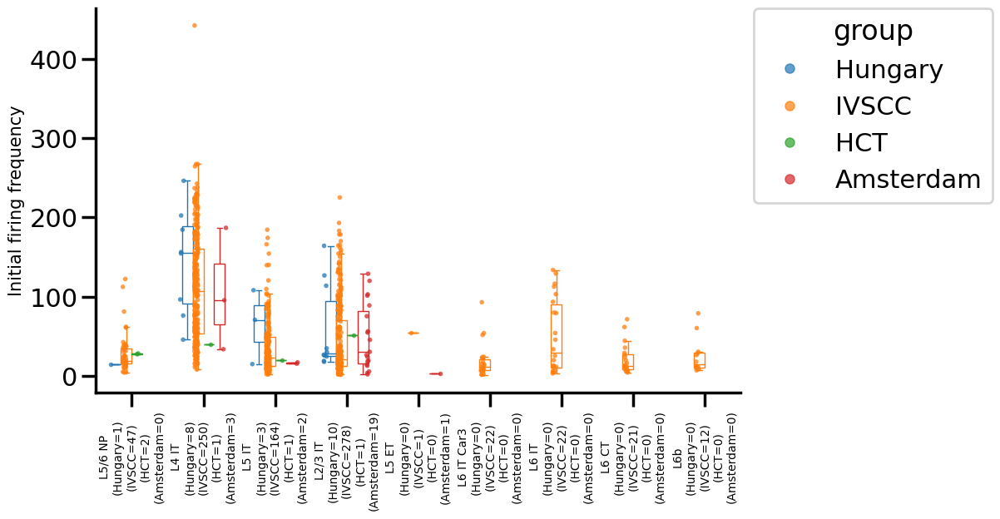

In [22]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'group'
group_order = sorted_clean_data[group_var].unique().tolist()
features = feature_cols.copy()

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables, figsize=(10,6))


Cross paradigm box plots - stats [duplicate analysis from above, to match this formatting]

1044


/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_acute vs. L4 IT_culture: Custom statistical test, P_val:3.306e-04
L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:4.088e-03
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.458e-10
L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:8.412e-07
L6 IT Car3_acute vs. L6 IT Car3_culture: Custom statistical test, P_val:1.582e-02
L6 IT_acute vs. L6 IT_culture: Custom statistical test, P_val:1.619e-04


/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:5.922e-05
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.800e-08
L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:4.807e-11


/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


... (19 outputs left out)

/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:1.441e-04


/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:3.257e-02
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.441e-04


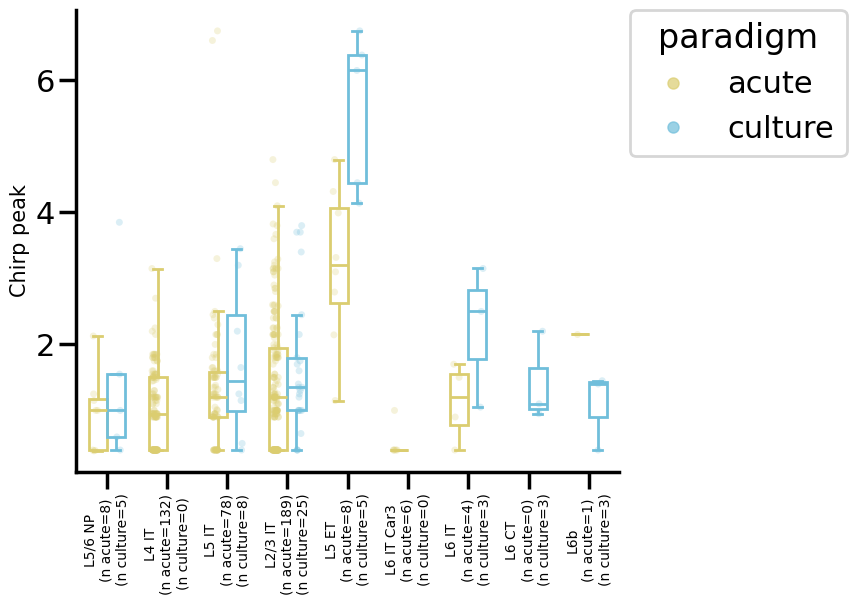

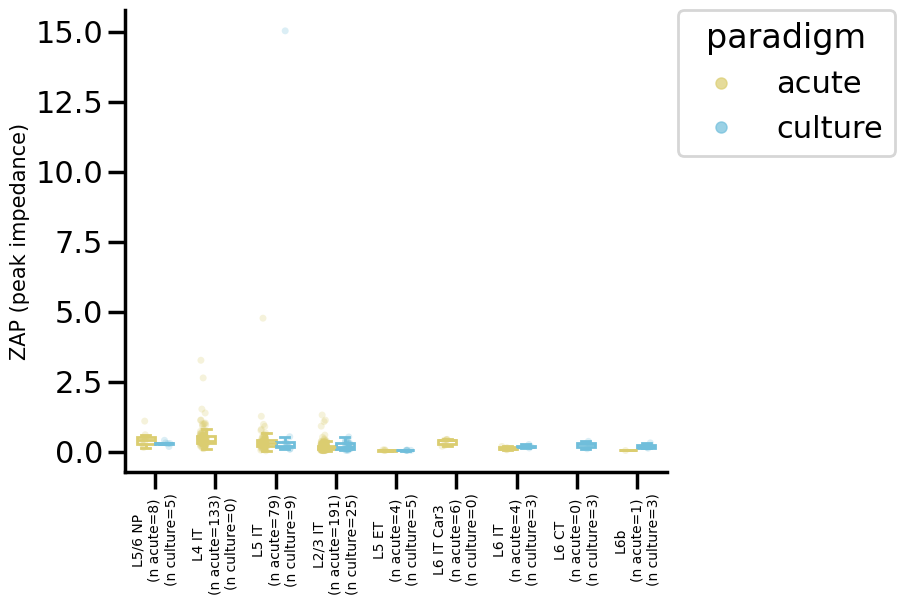

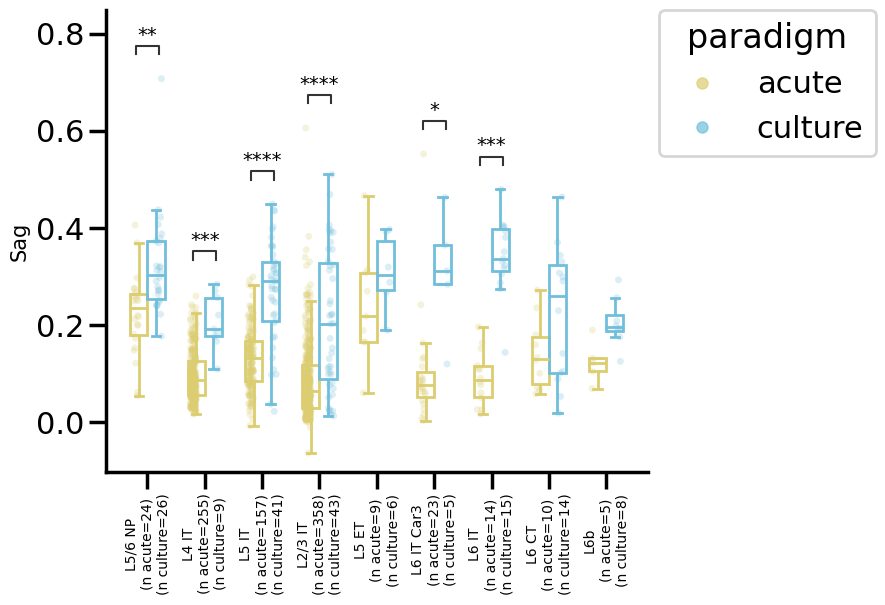

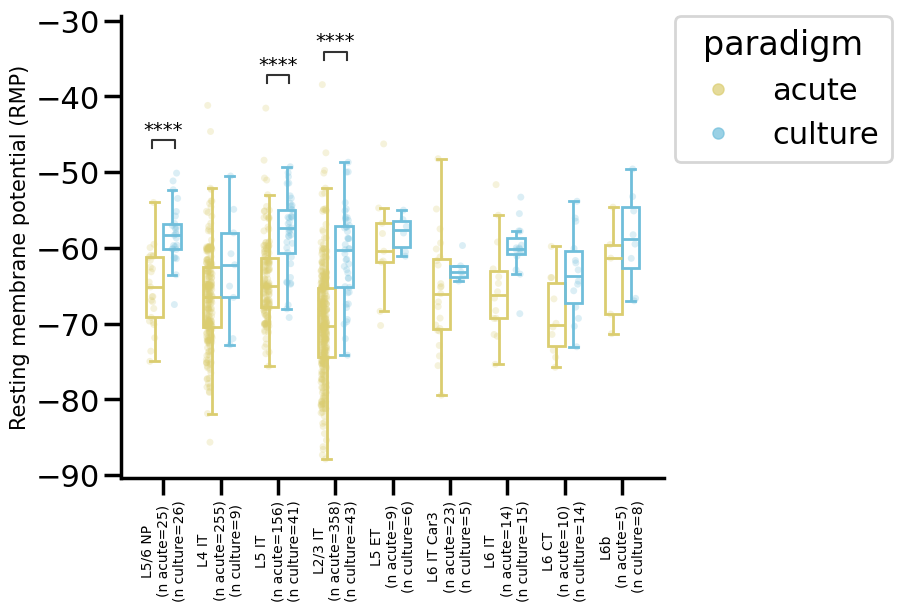

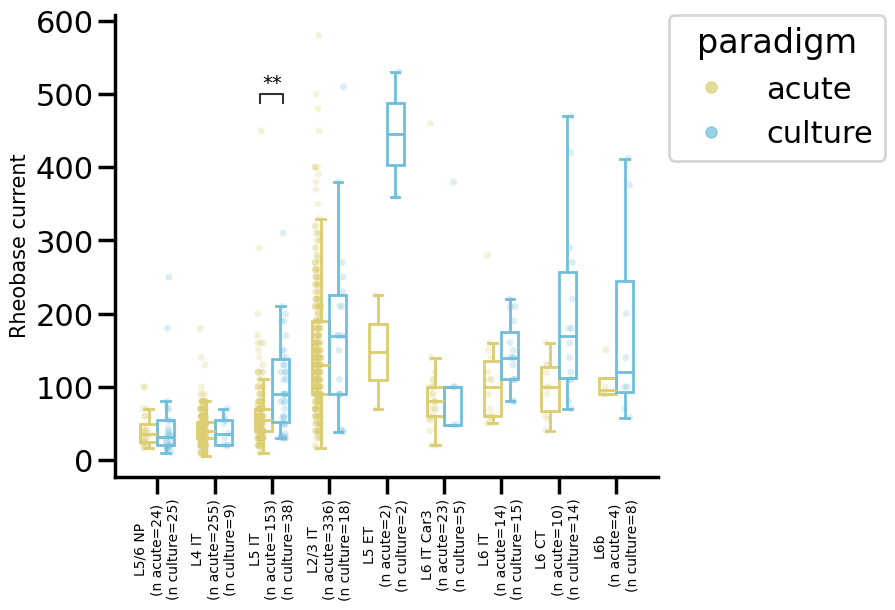

...

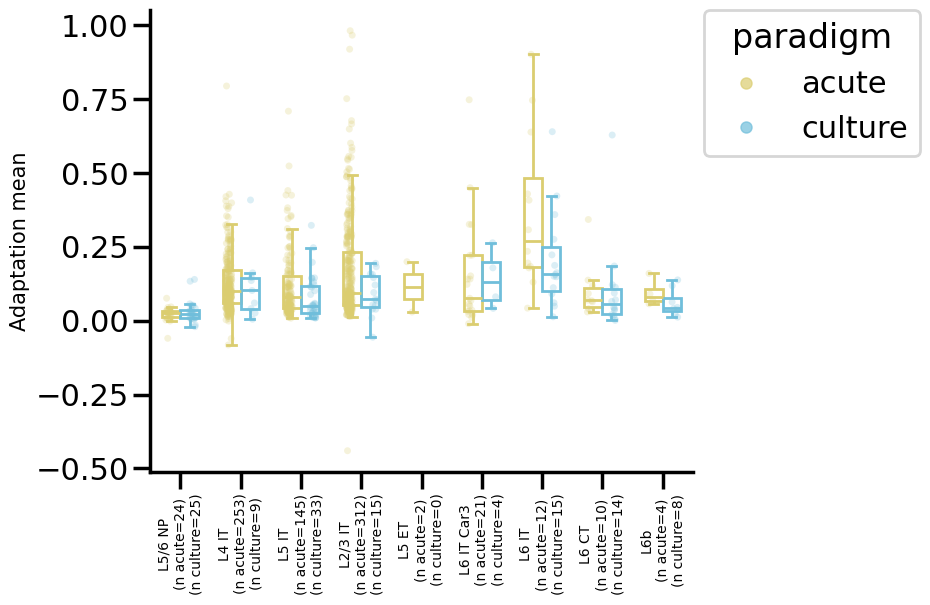

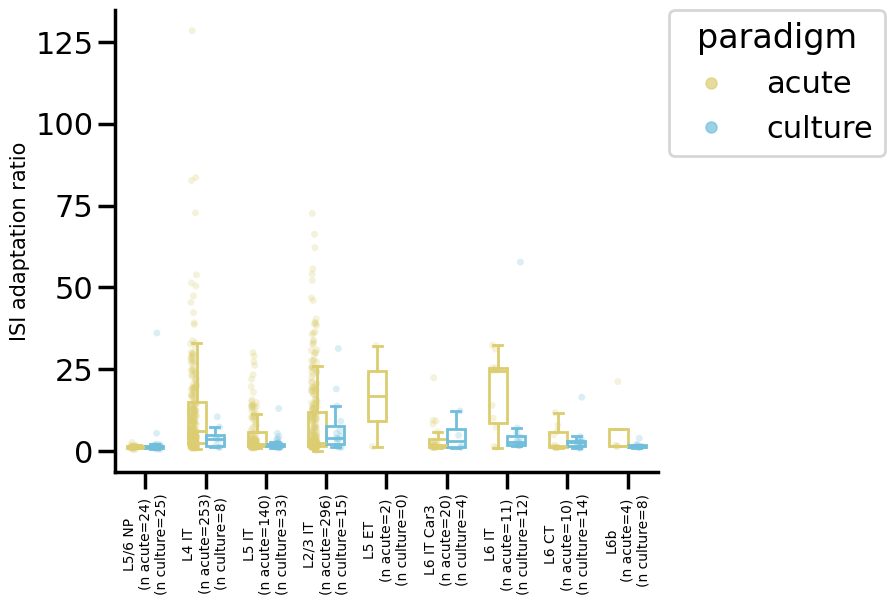

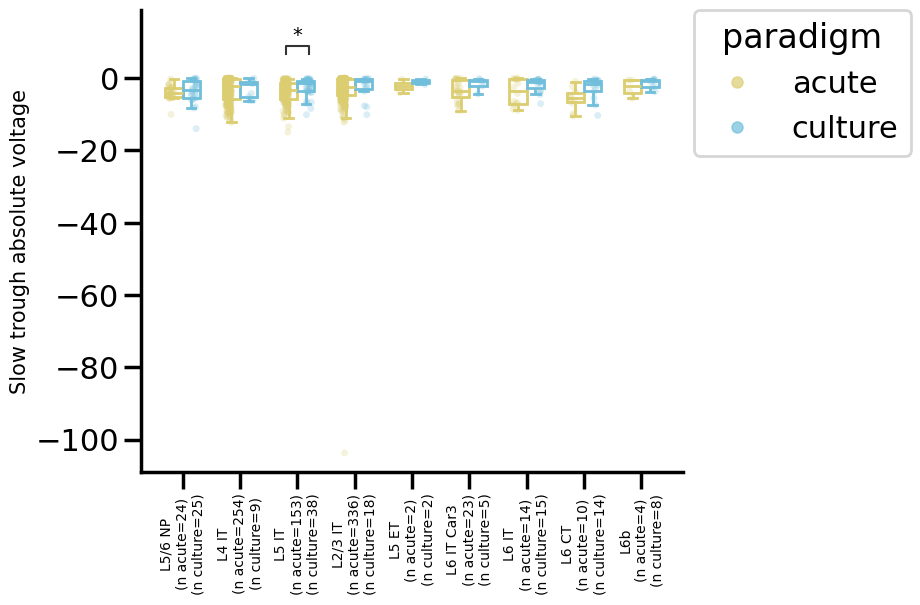

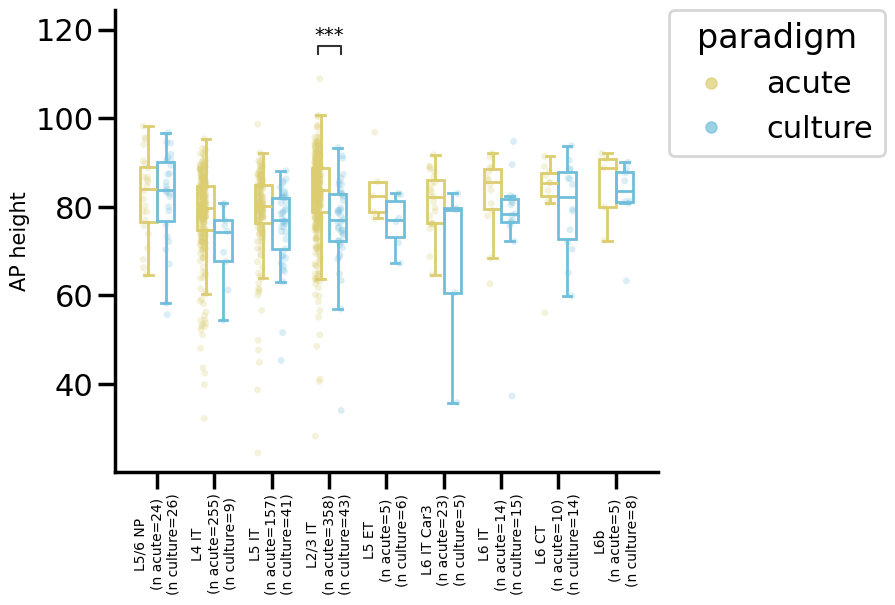

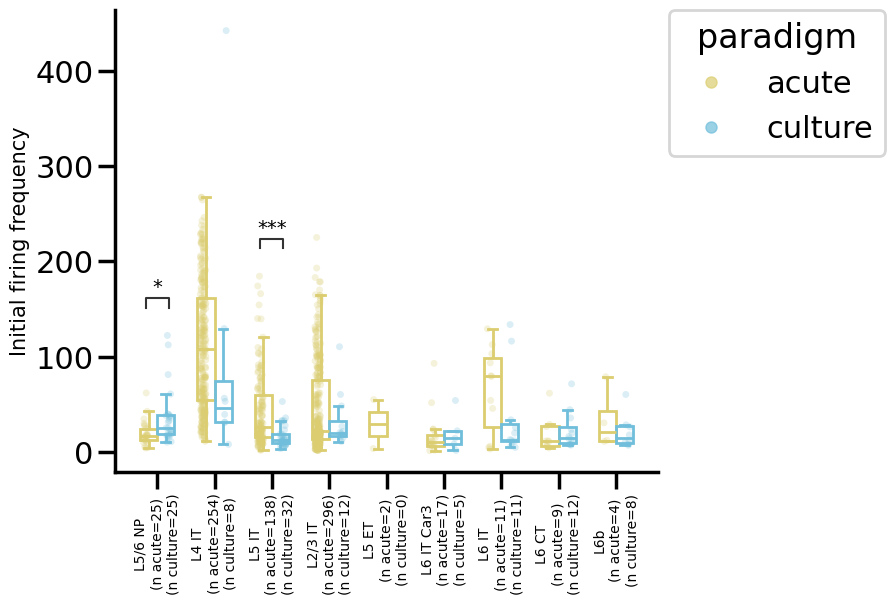

In [23]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette = list(color_dicts[group_var].values())
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross lobe box plots - subclass [duplicate analysis from above, to match this formatting]

/opt/conda/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:367: RuntimeWarning: divide by zero encountered in divide
  B = 1.0 / x_lens.loc[i] + 1.0 / x_lens.loc[j]
/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


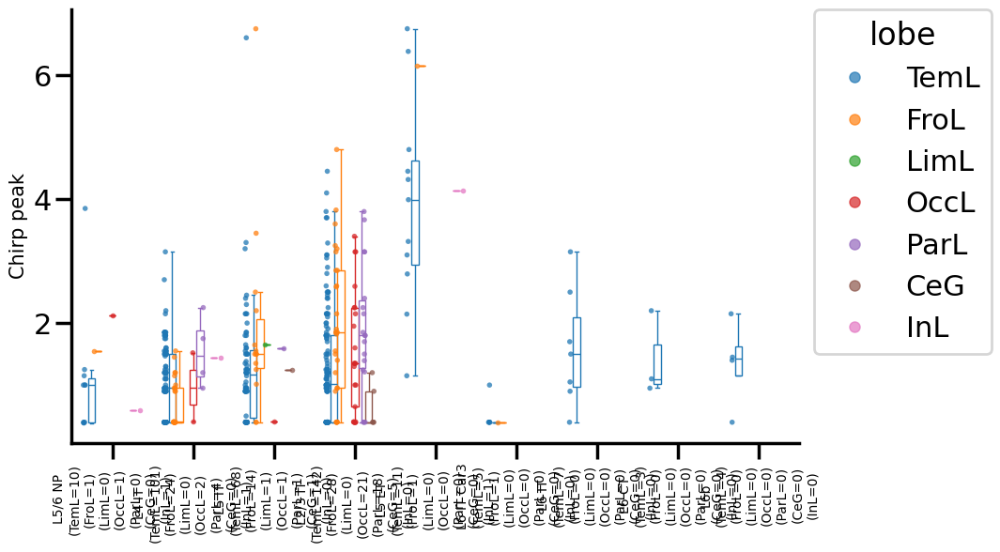

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


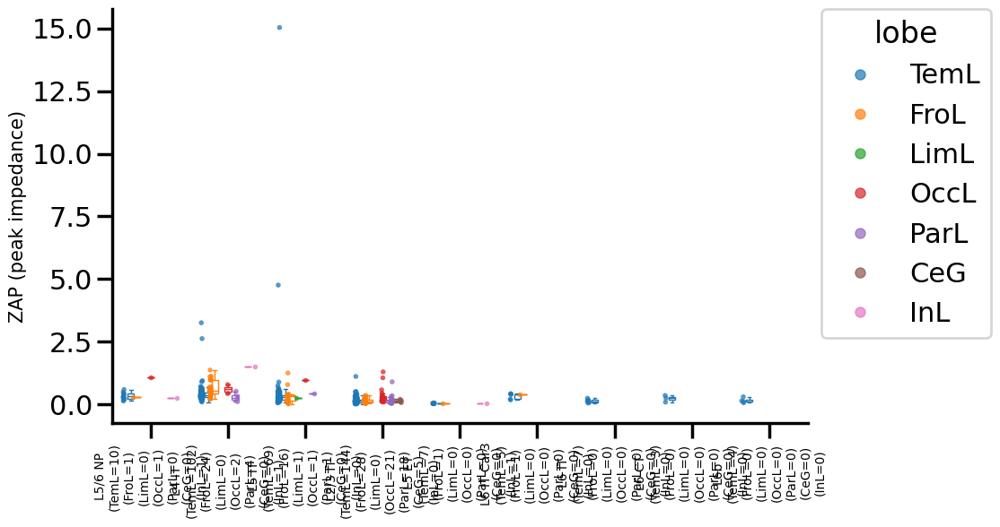

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:4.179e-06
L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:4.115e-02
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:5.570e-06
L4 IT_TemL vs. L4 IT_ParL: Custom statistical test, P_val:1.226e-03
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:7.469e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


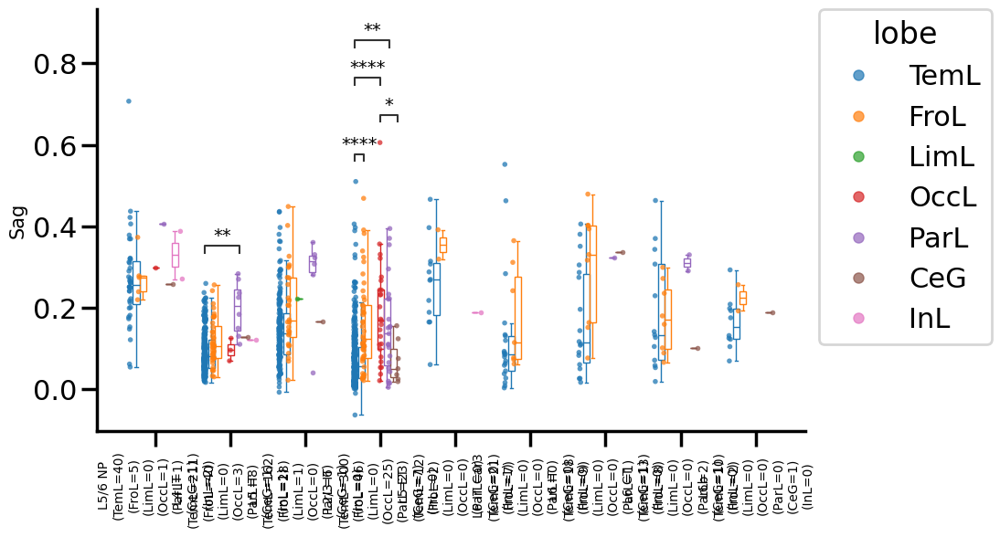

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:2.870e-02
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:1.576e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


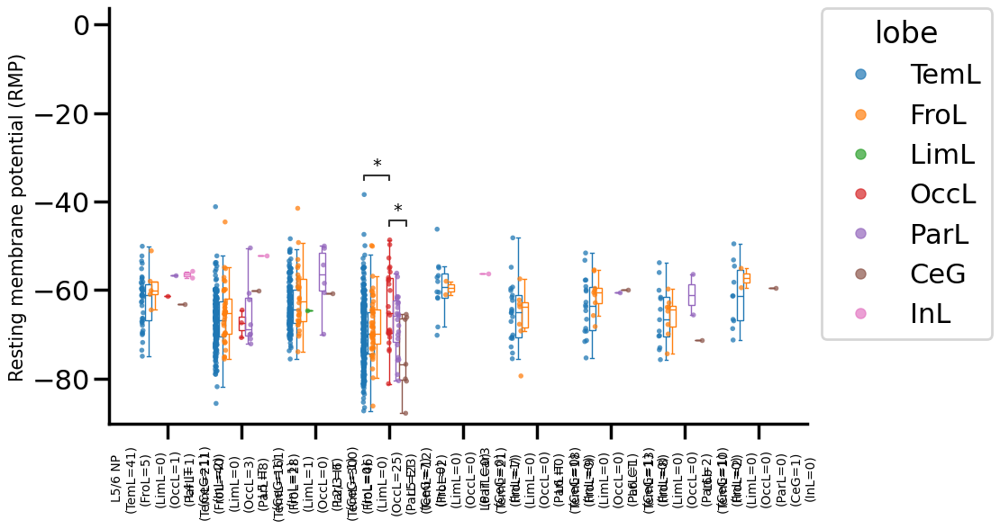

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


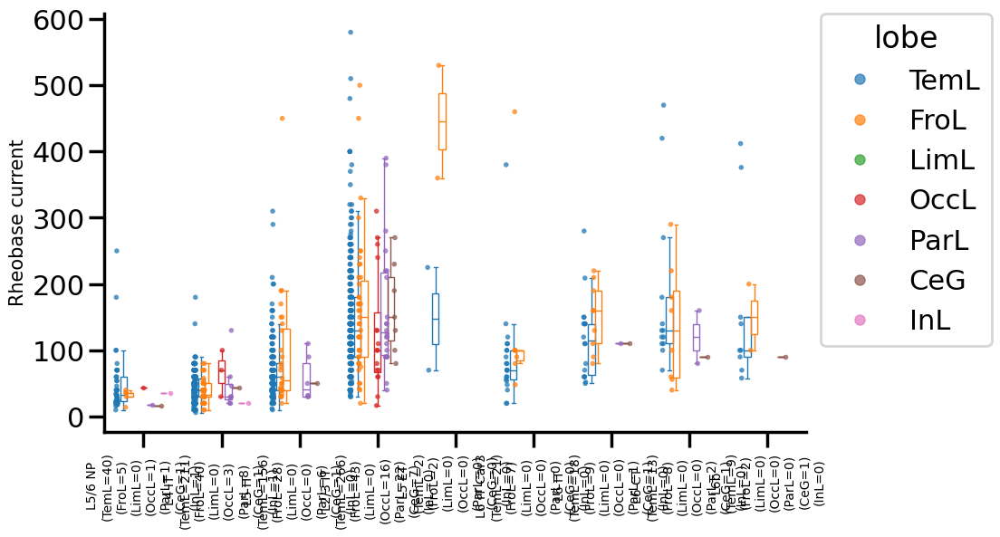

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


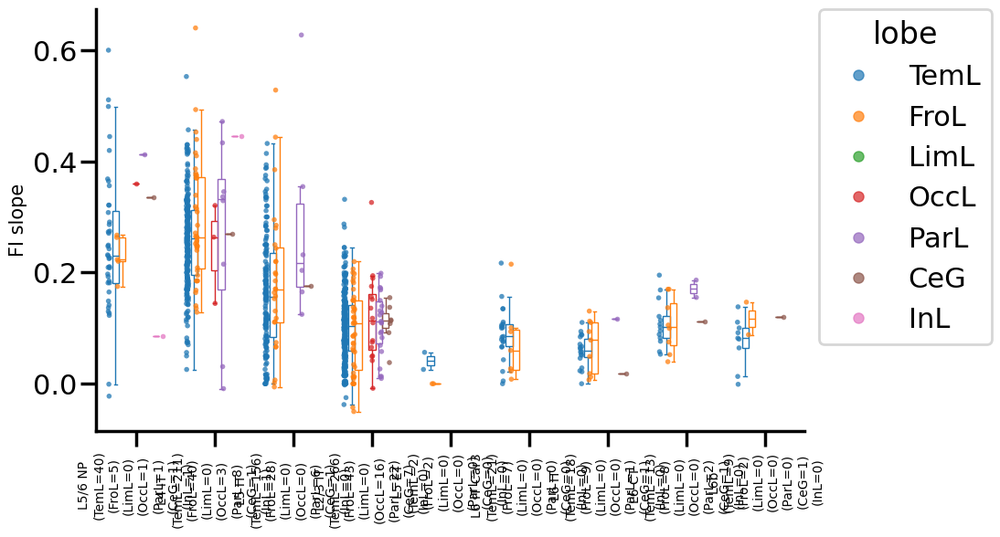

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


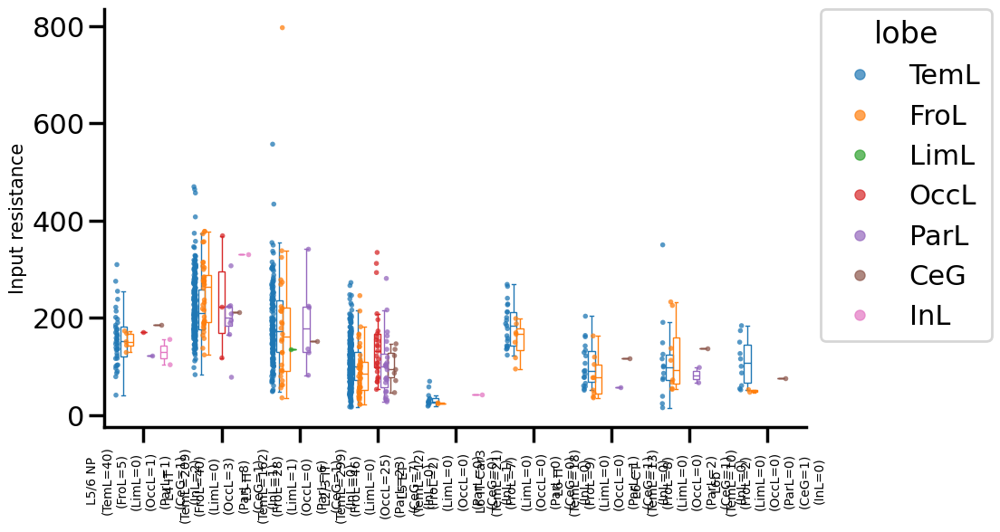

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


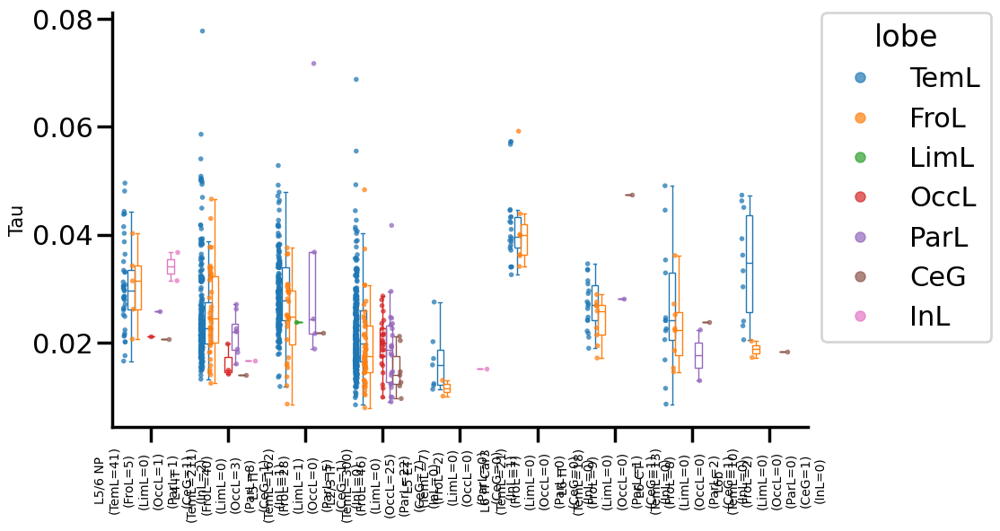

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:7.122e-03
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:5.578e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


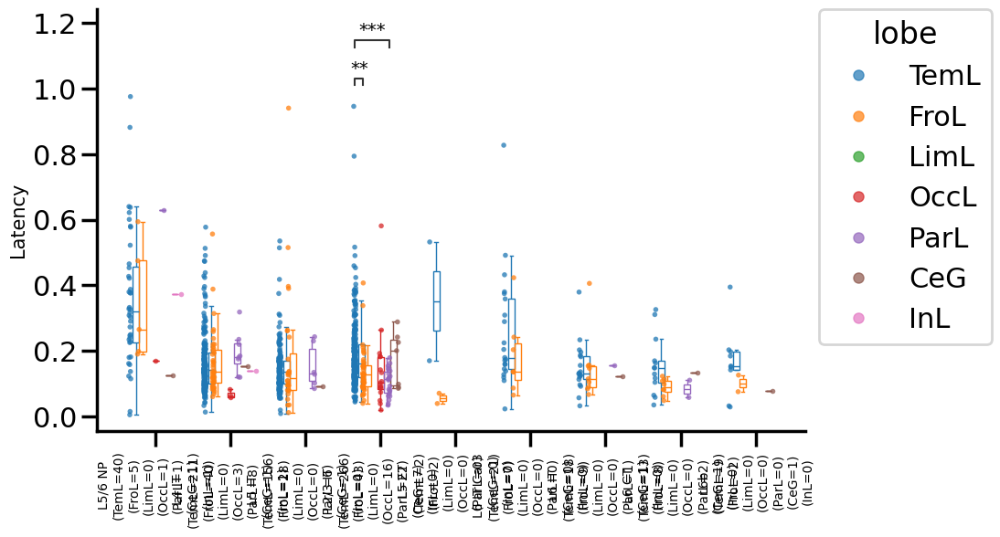

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


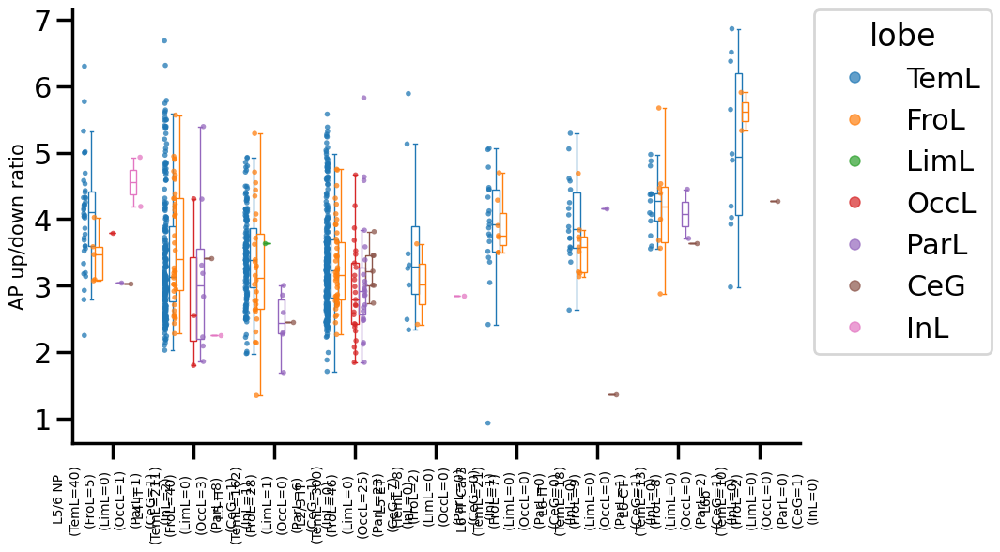

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:1.792e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.082e-03
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.082e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


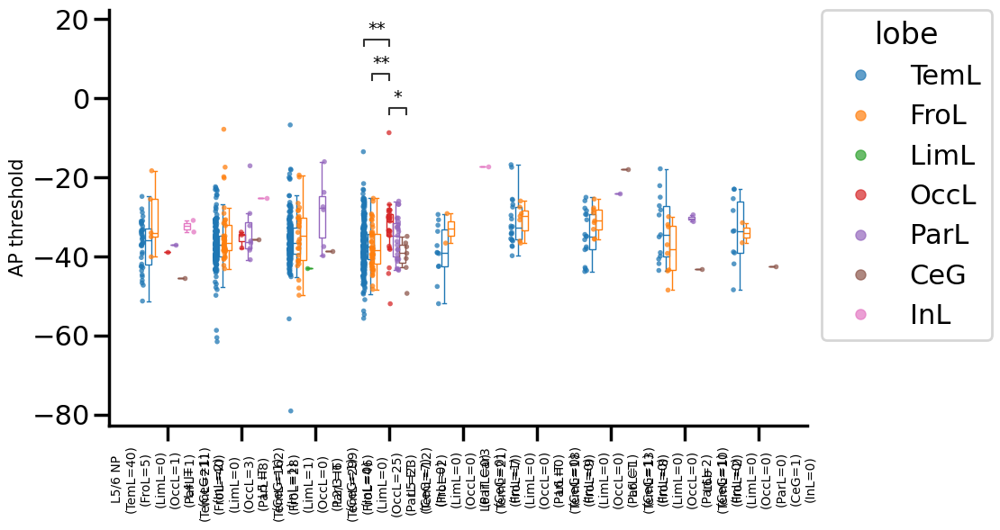

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


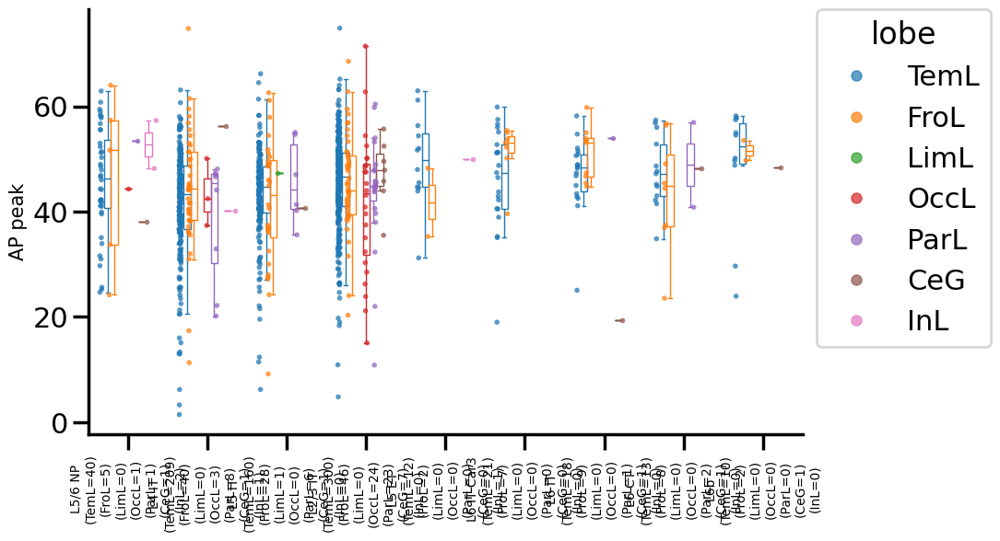

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_ParL: Custom statistical test, P_val:9.920e-03
L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:9.920e-03
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:1.601e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


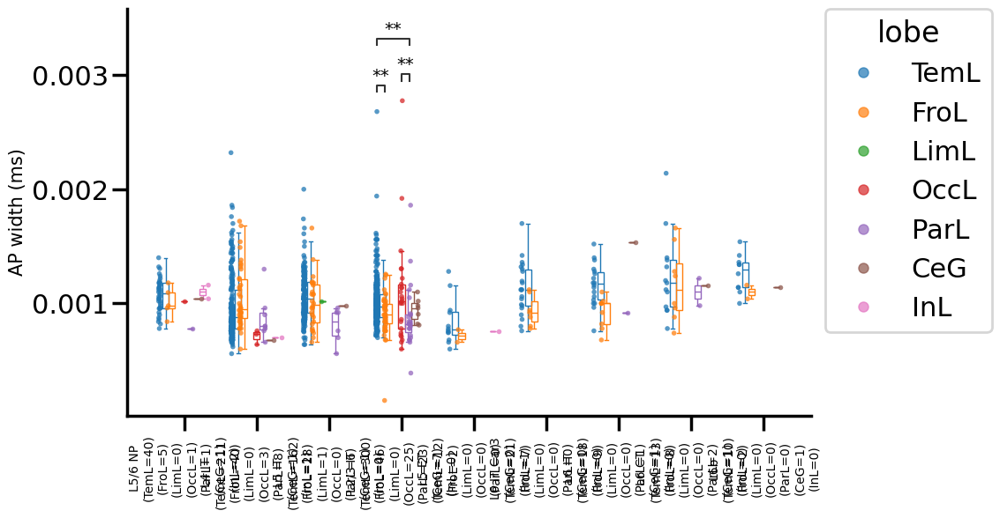

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


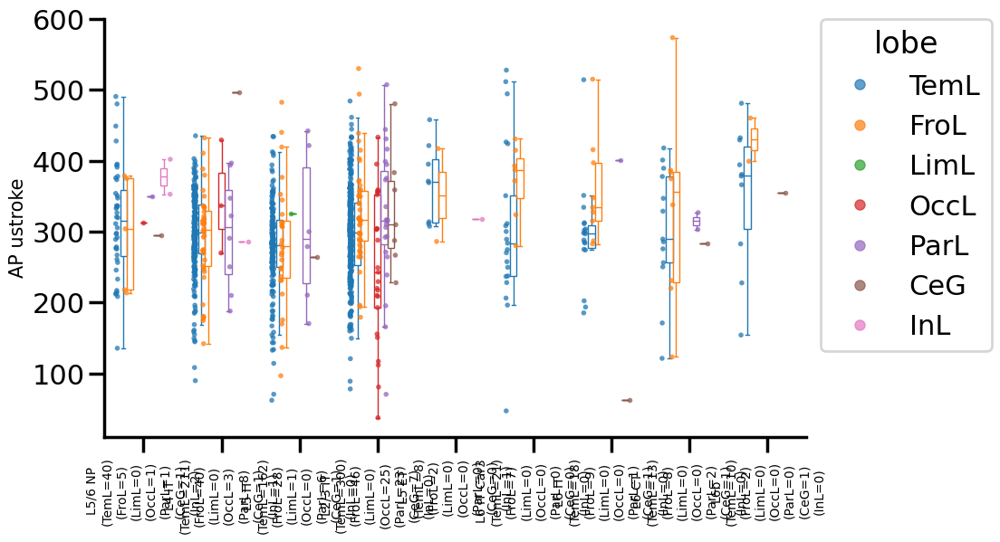

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT_TemL vs. L6 IT_FroL: Custom statistical test, P_val:1.195e-02
L2/3 IT_OccL vs. L2/3 IT_ParL: Custom statistical test, P_val:3.816e-02
L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:3.816e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:3.976e-02
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:3.816e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


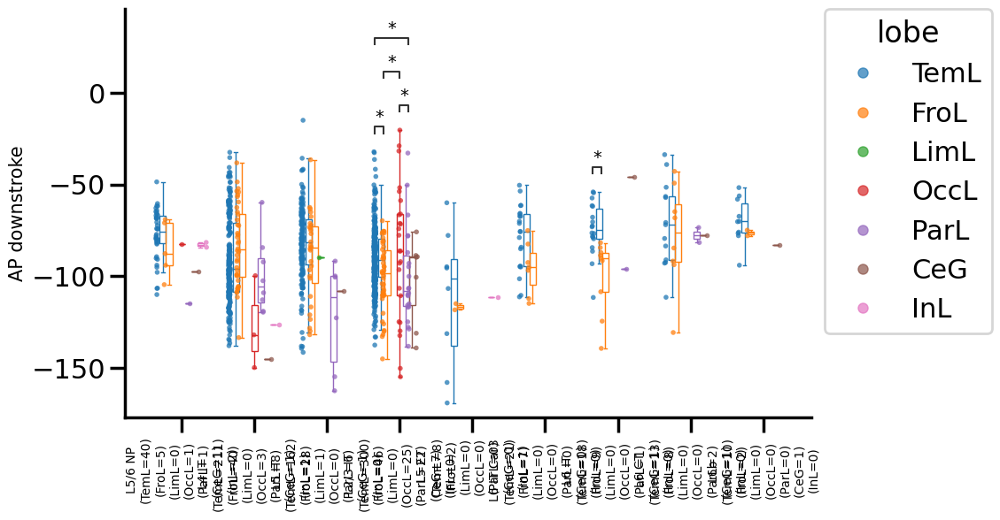

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:3.455e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.222e-02
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:6.933e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


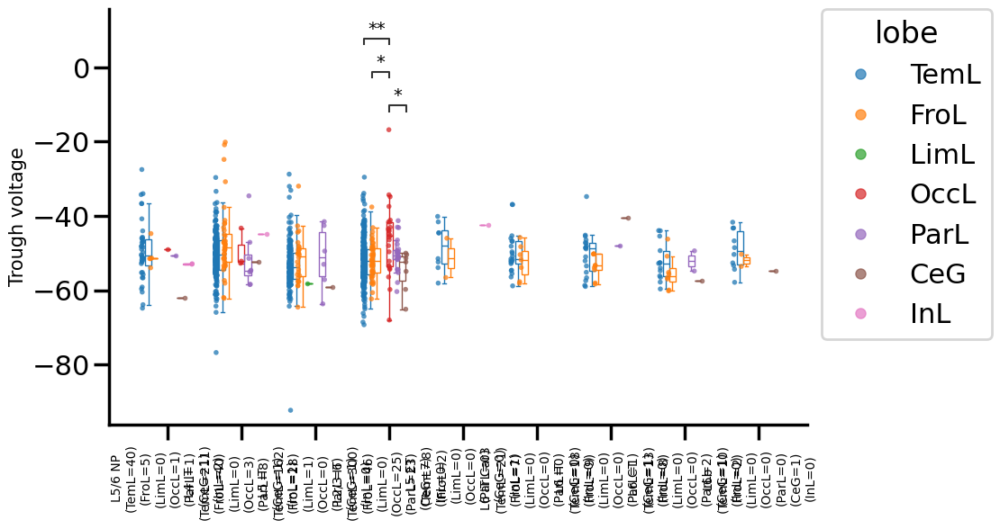

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:1.851e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:3.126e-02
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:1.851e-02


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


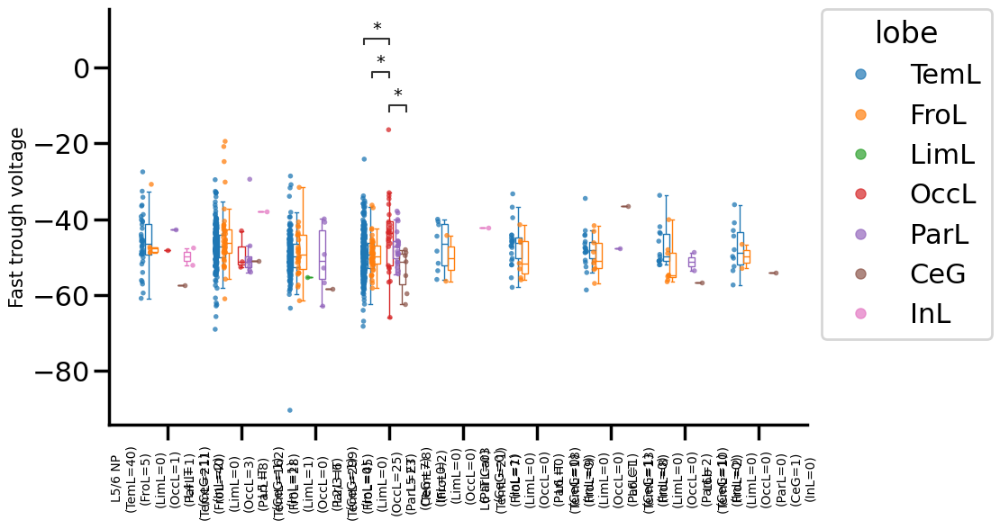

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:6.264e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


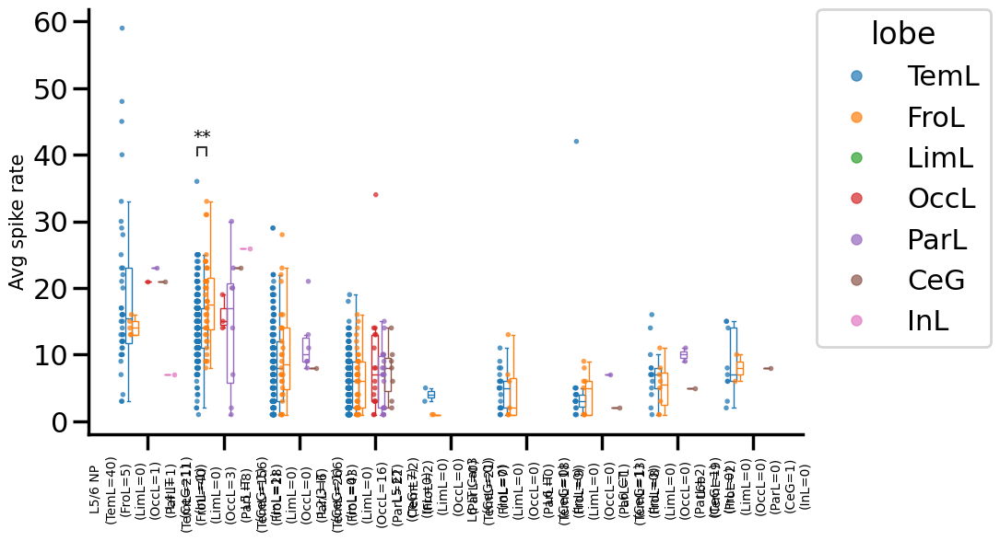

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:8.508e-03


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


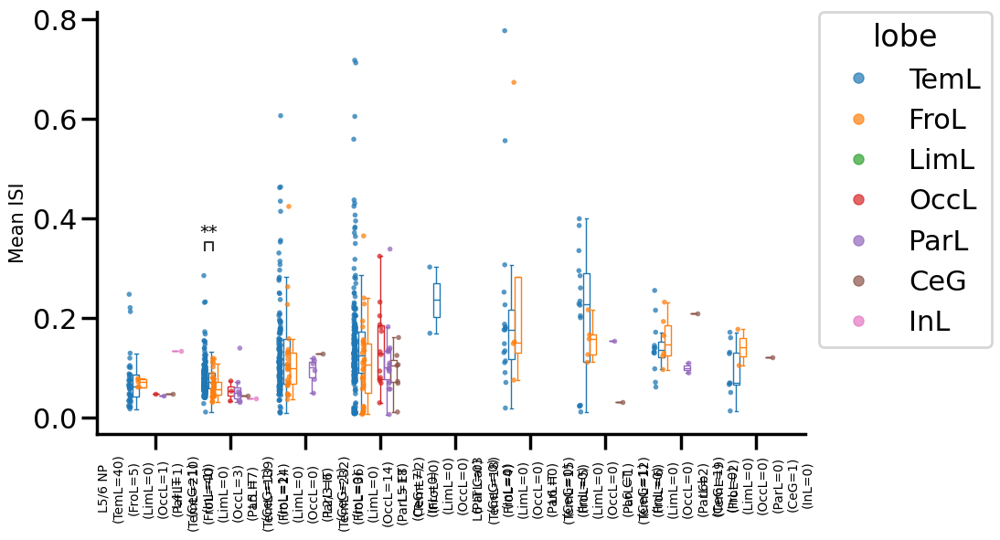

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


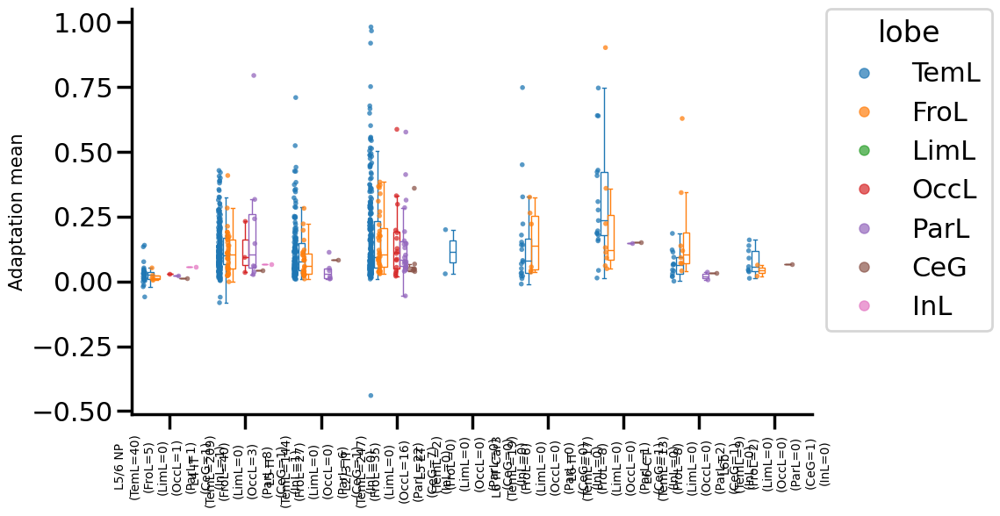

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


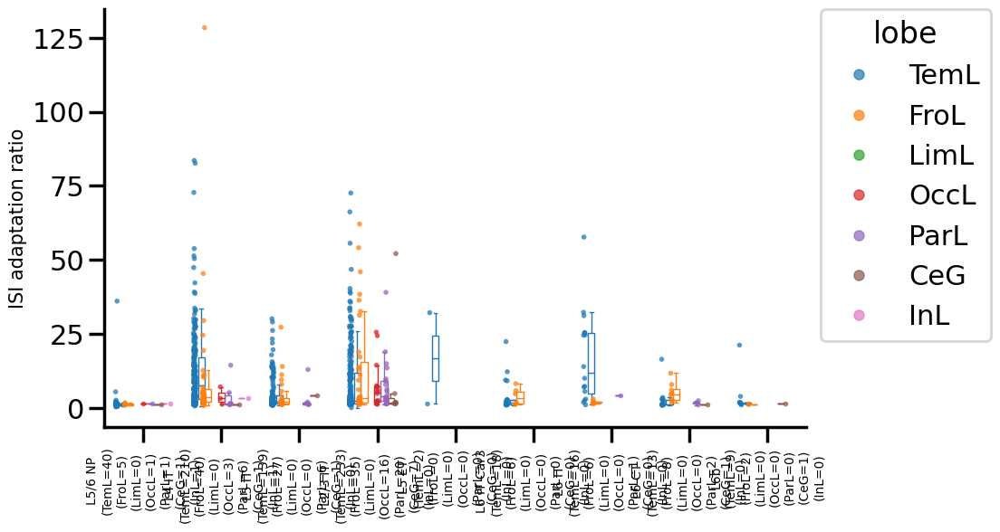

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


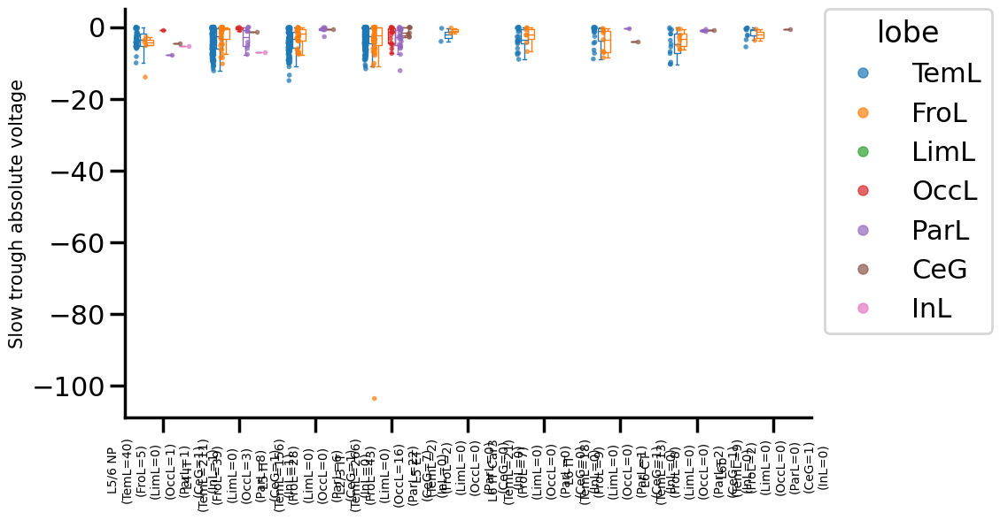

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:7.544e-03
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:3.455e-03
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:4.707e-04


/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


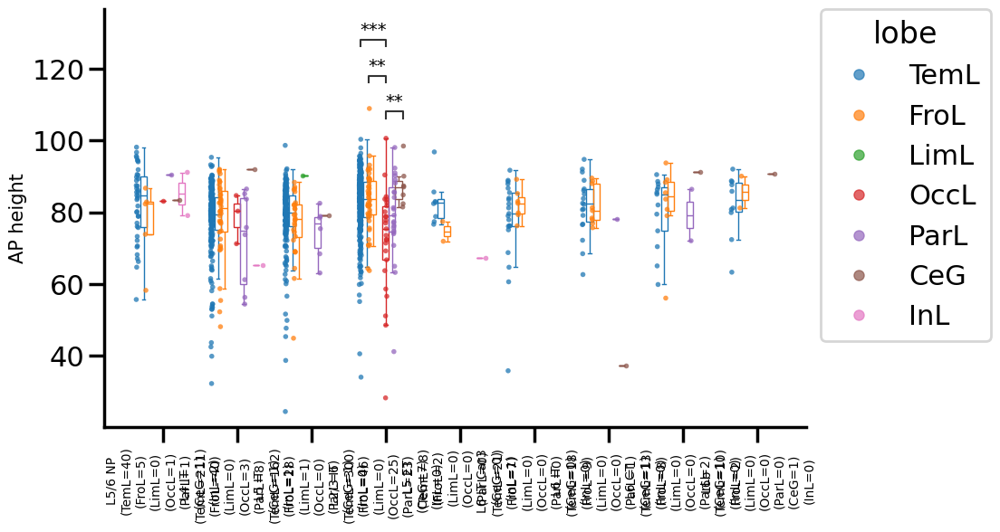

/tmp/ipykernel_1139051/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


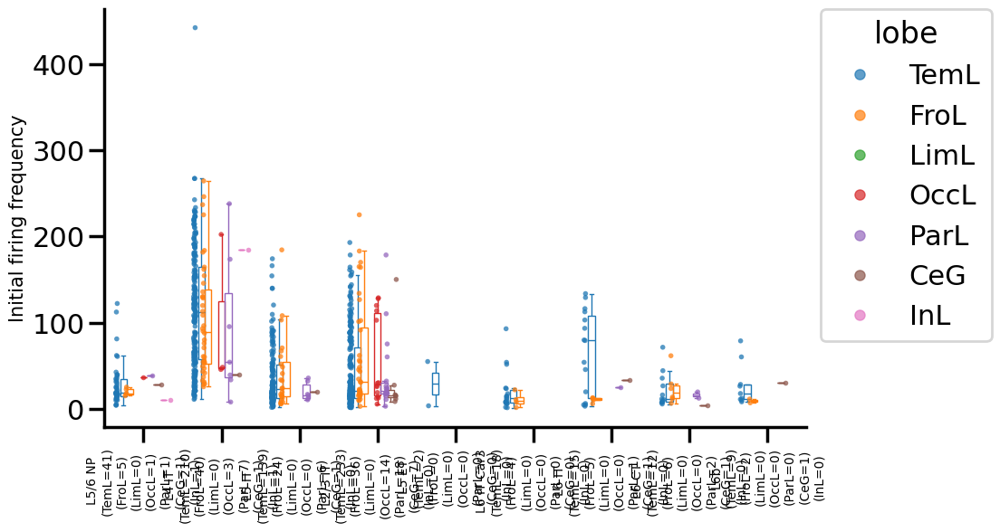

In [24]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'lobe'
group_order = sorted_clean_data[group_var].unique().tolist()
features = feature_cols.copy()

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables, figsize=(10,6))


#### *group non-TemL as `Other`

1044


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_Other: Custom statistical test, P_val:3.085e-02


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:1.885e-02


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


... (11 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:4.155e-04


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:22: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explic

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:1.468e-02


/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1139051/1462520940.py:26: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1139051/1462520940.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1139051/1462520940.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

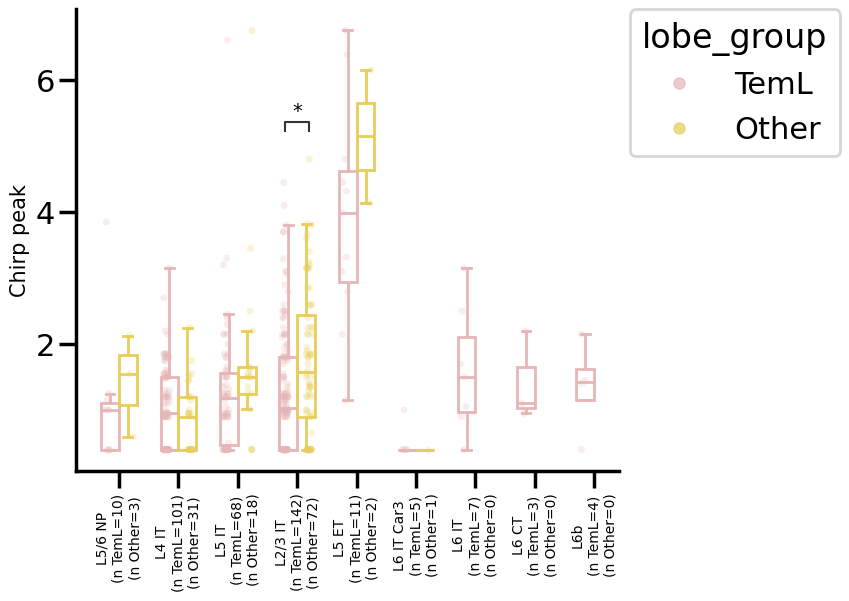

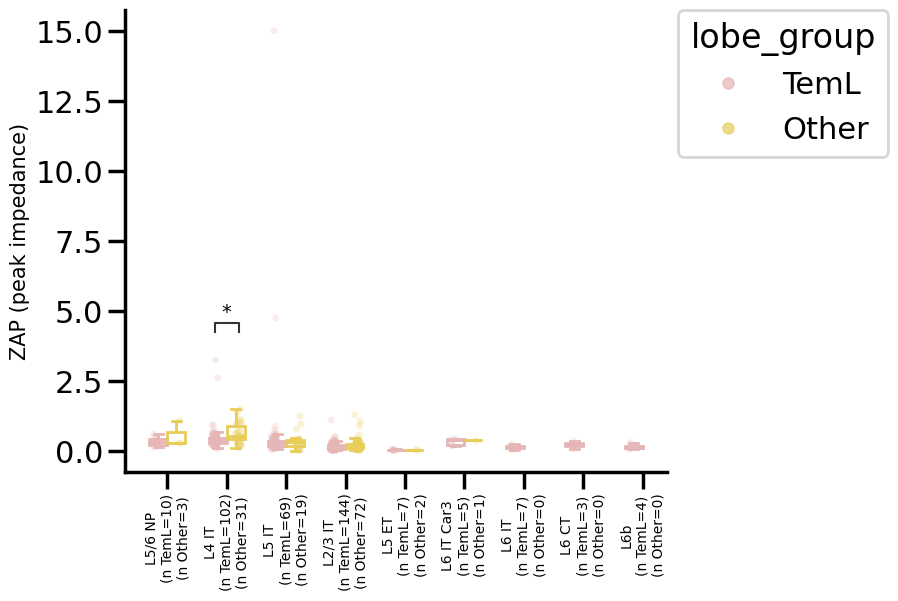

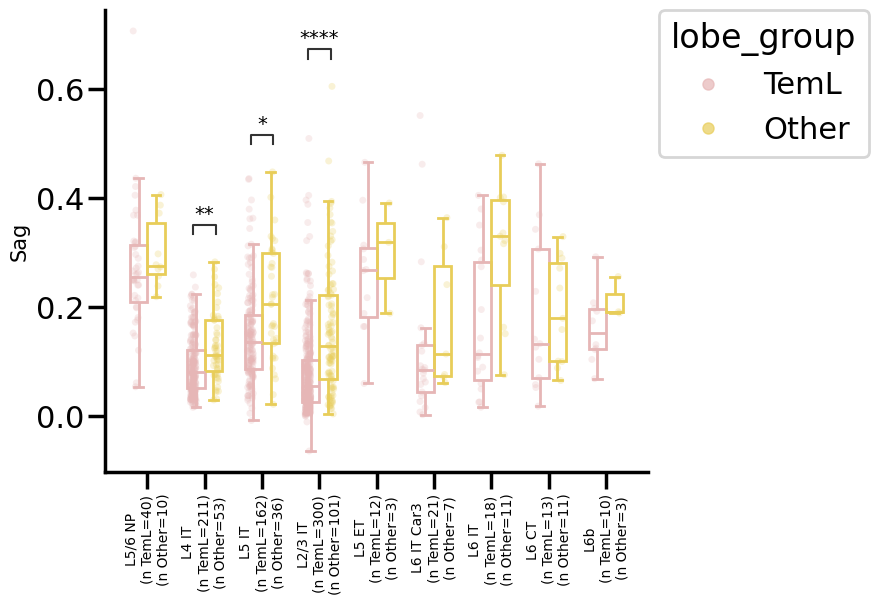

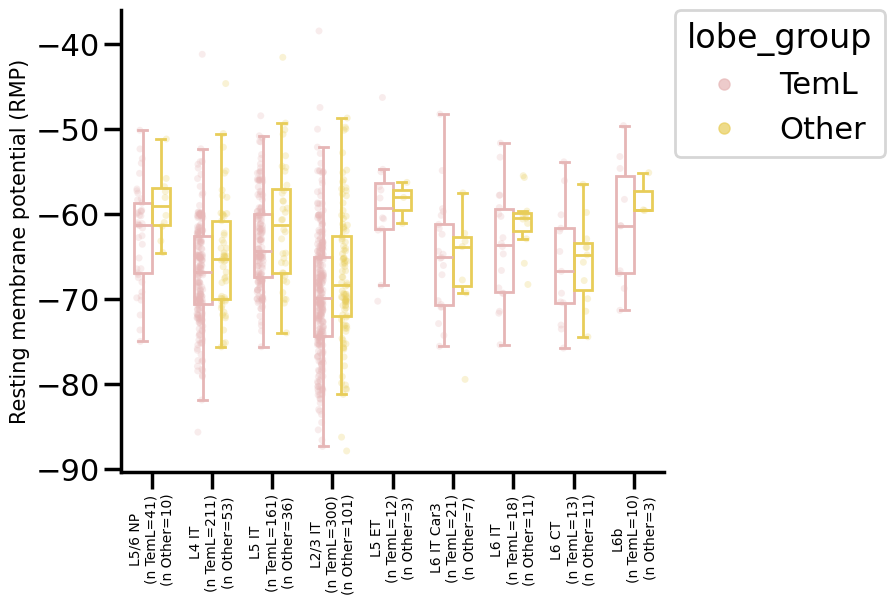

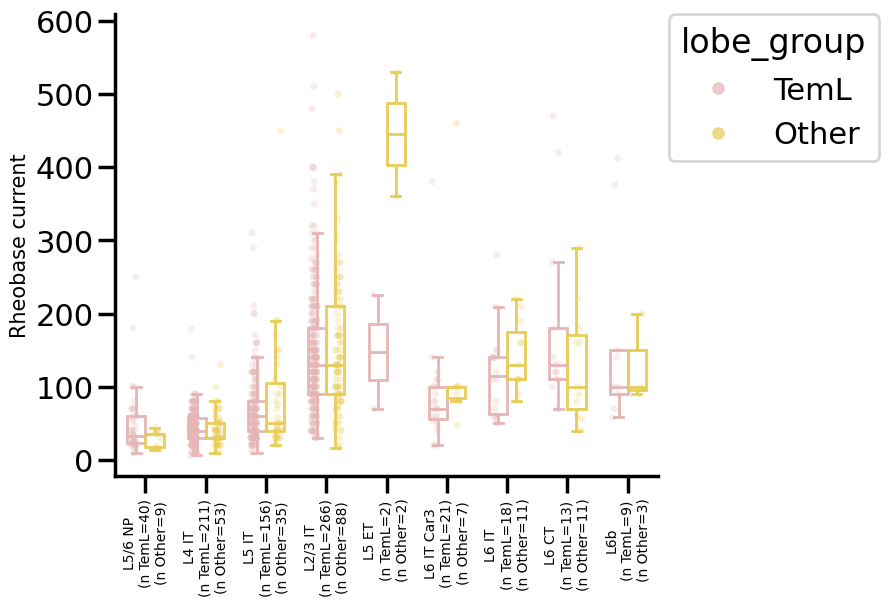

...

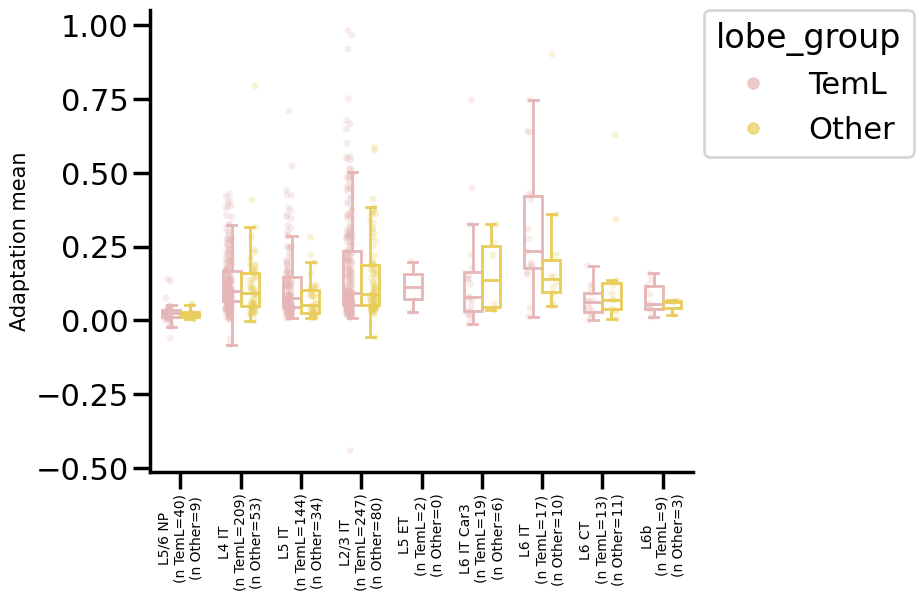

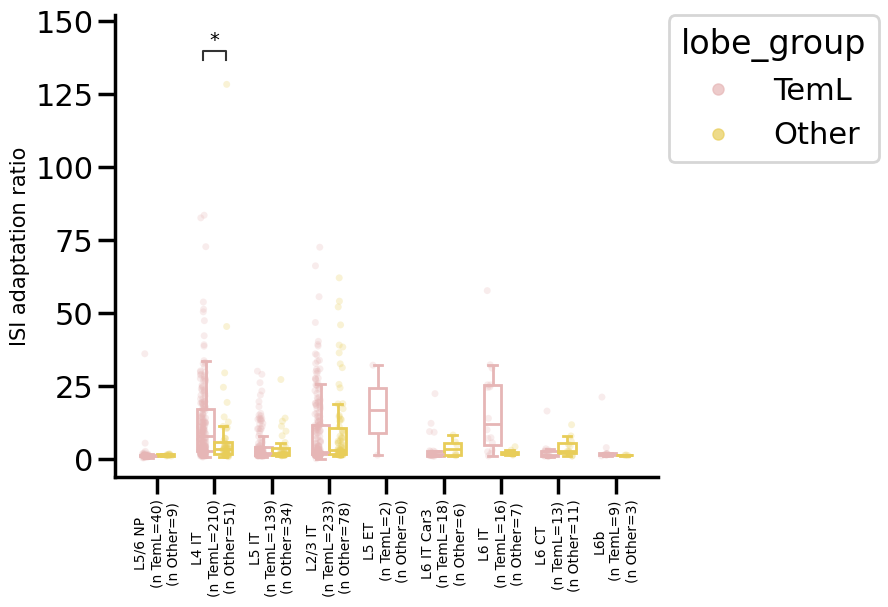

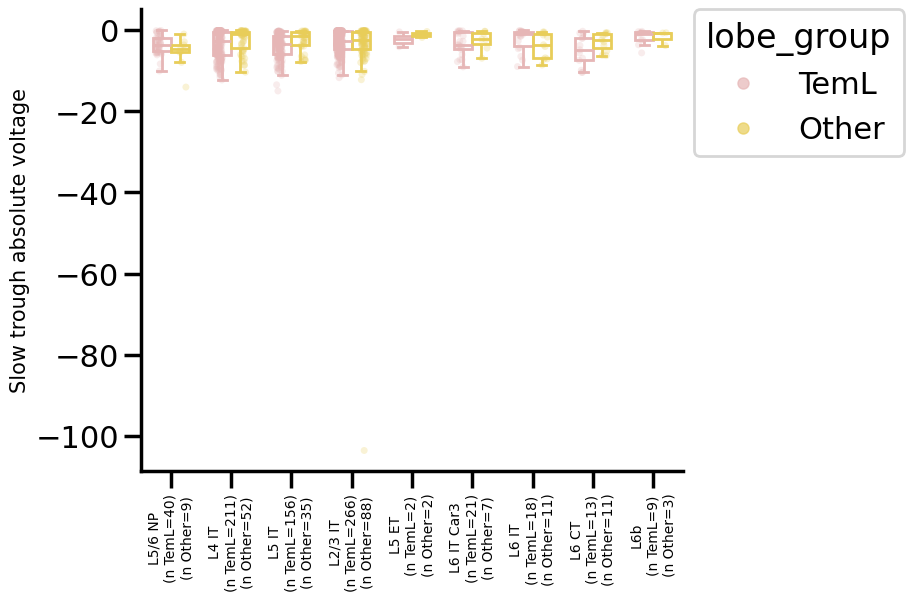

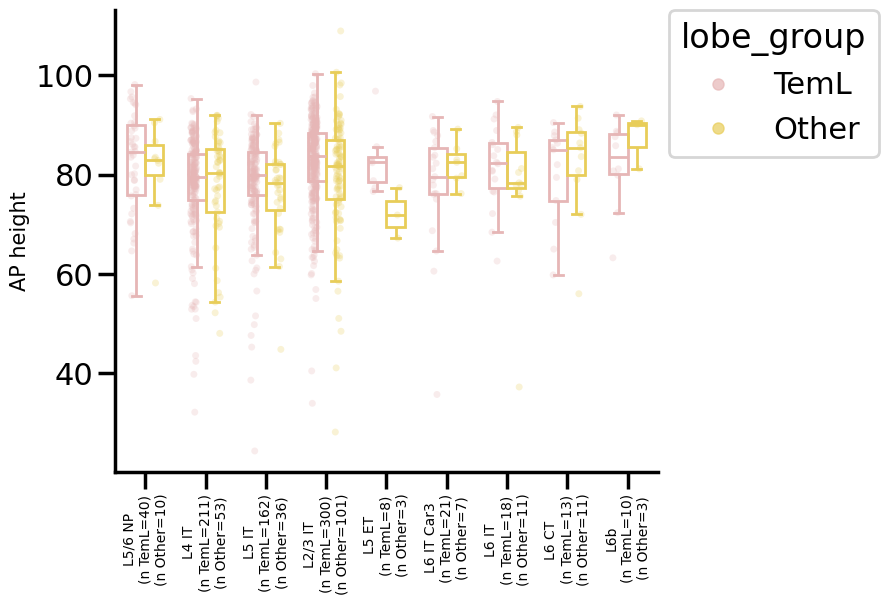

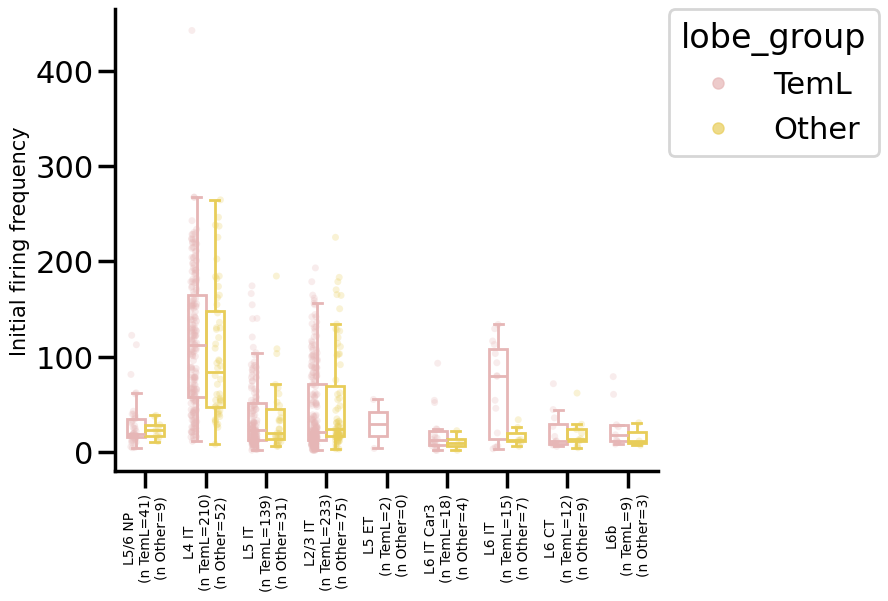

In [25]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
suffix = '_groupNonTemL'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette = list(color_dicts[group_var].values())
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


L4 IT_1 vs L5 IT_2 comparison

In [6]:
# Compare L4 IT_1 vs L5 IT_2
supertype1 = 'L4 IT_1'
supertype2 = 'L5 IT_2'

# Filter data to only these two supertypes
comparison_data = sorted_clean_data[sorted_clean_data['t_type'].isin([supertype1, supertype2])].copy()

print(f"L4 IT_1 cells: {len(comparison_data[comparison_data['t_type'] == supertype1])}")
print(f"L5 IT_2 cells: {len(comparison_data[comparison_data['t_type'] == supertype2])}")

features_to_test = feature_cols

# Perform Mann-Whitney U test for each feature
mw_stats = {}
mw_pvals = {}

for f in features_to_test:
    group1_data = comparison_data[comparison_data['t_type'] == supertype1][f].dropna()
    group2_data = comparison_data[comparison_data['t_type'] == supertype2][f].dropna()
    
    if len(group1_data) >= 3 and len(group2_data) >= 3:
        try:
            stat, pval = mannwhitneyu(group1_data, group2_data, alternative='two-sided')
            mw_stats[f] = stat
            mw_pvals[f] = pval
        except ValueError as e:
            print(f'Mann-Whitney failed for {f}: {e}')

# FDR correction
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))

# Create stats dataframe
stats_rows = []
for feature in mw_pvals.keys():
    stats_rows.append({
        'feature': feature,
        'Mann_Whitney_U': mw_stats[feature],
        'p_value': mw_pvals[feature],
        'p_value_fdr': mw_pvals_fdr[feature],
        'rejected': mw_rejected[feature]
    })

mw_stats_df = pd.DataFrame(stats_rows)

# Save stats
output_file = os.path.join(output_dir, 'ephys_feature_box_plot_stats_L4_IT_1_vs_L5_IT_2_MW.csv')
mw_stats_df.to_csv(output_file, index=False)
print(f"\nStats saved to: {output_file}")
print(f"\nSignificant features (FDR < 0.05): {sum(mw_rejected.values())}")

mw_stats_df

L4 IT_1 cells: 40
L5 IT_2 cells: 68

Stats saved to: /root/capsule/scratch/20260807/ephys/ephys_feature_box_plot_stats_L4_IT_1_vs_L5_IT_2_MW.csv

Significant features (FDR < 0.05): 2


,feature,Mann_Whitney_U,p_value,p_value_fdr,rejected
0,Chirp peak,320.5,0.471044,0.628058,False
1,ZAP (peak impedance),342.0,0.465035,0.628058,False
2,Sag,1377.0,0.712685,0.809504,False
3,Resting membrane potential (RMP),1297.0,0.883409,0.921818,False
4,Rheobase current,984.5,0.046605,0.124279,False
5,FI slope,1617.0,0.024554,0.098218,False
6,Input resistance,1371.0,0.742046,0.809504,False
7,Tau,823.0,0.001665,0.019983,True
8,Latency,1054.0,0.131891,0.243492,False
9,AP up/down ratio,1589.0,0.080116,0.174799,False


/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


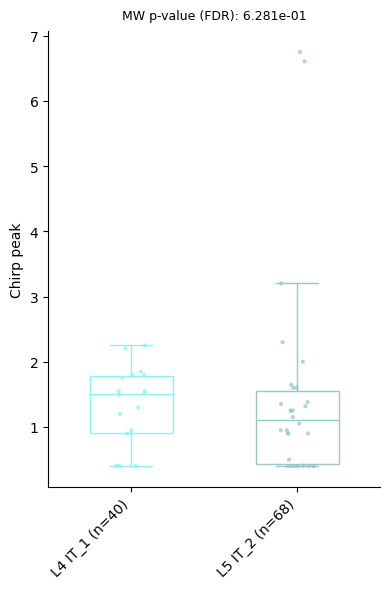

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


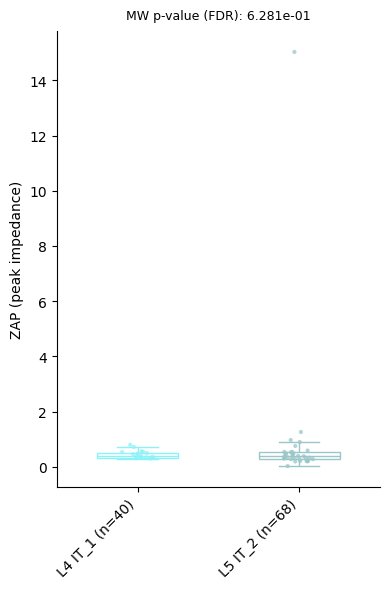

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


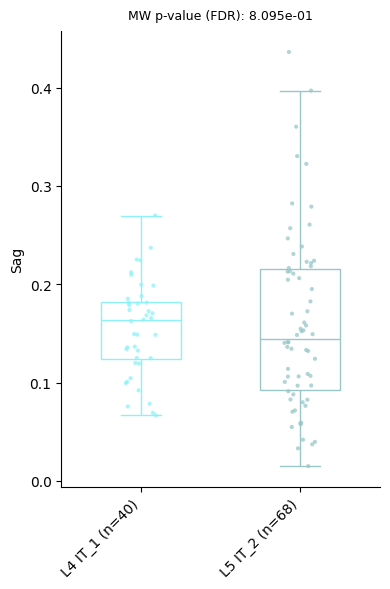

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


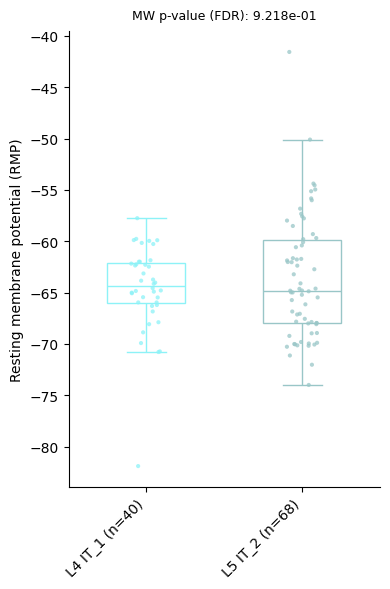

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


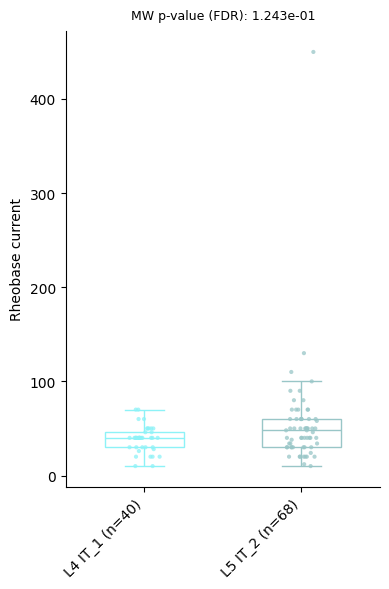

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


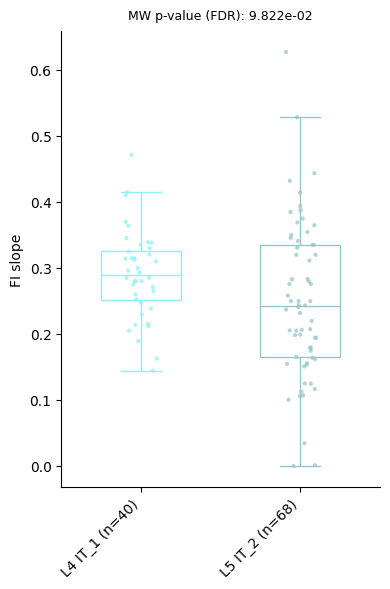

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


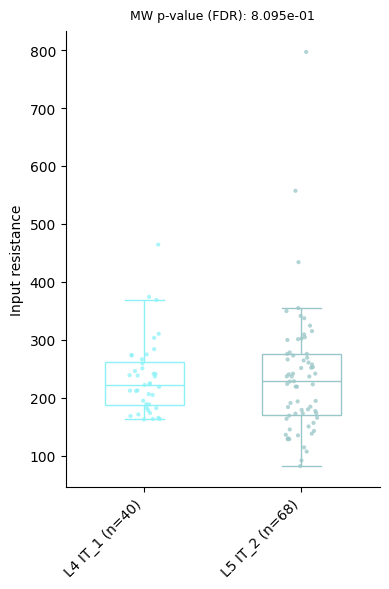

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


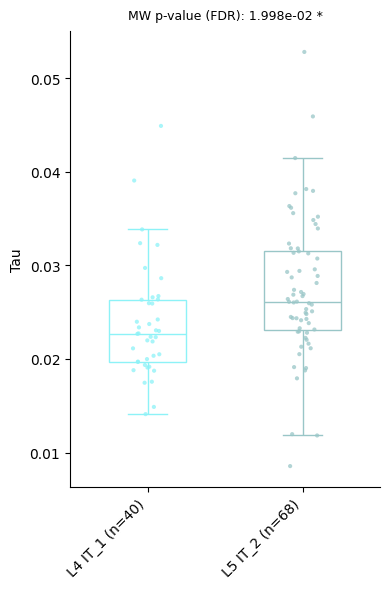

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


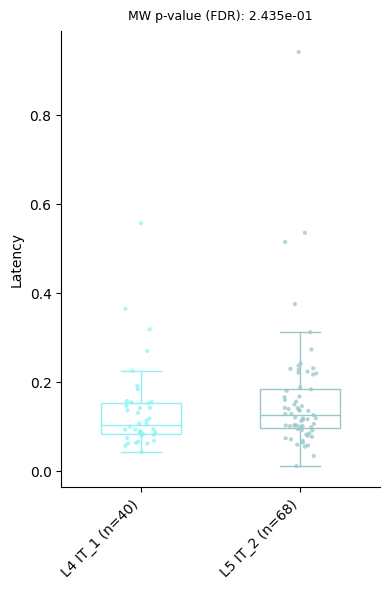

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


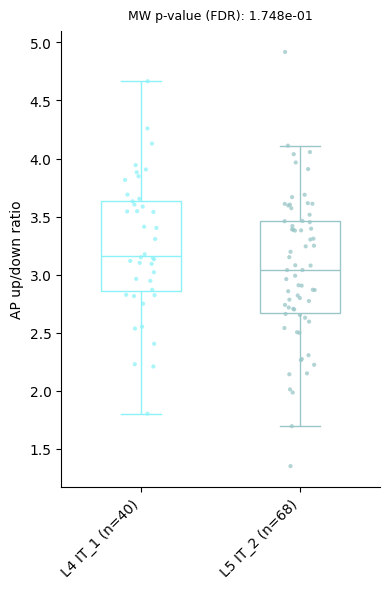

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


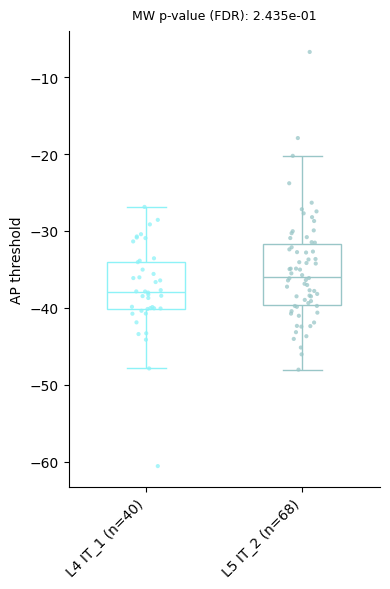

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


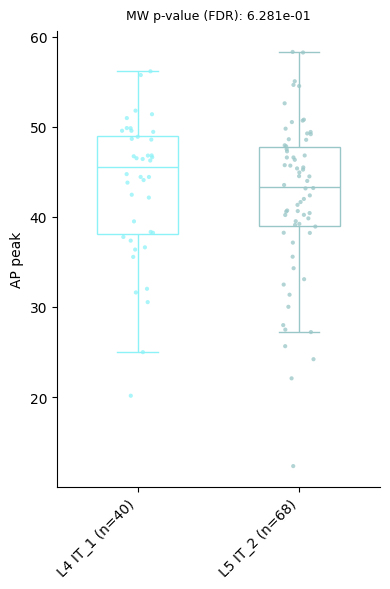

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


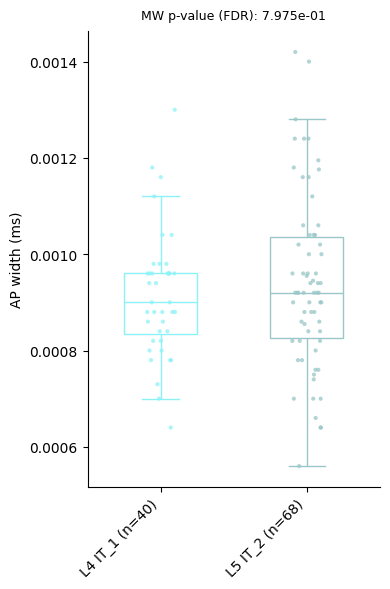

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


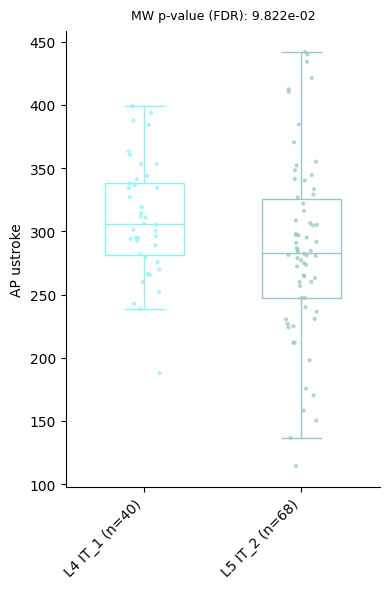

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


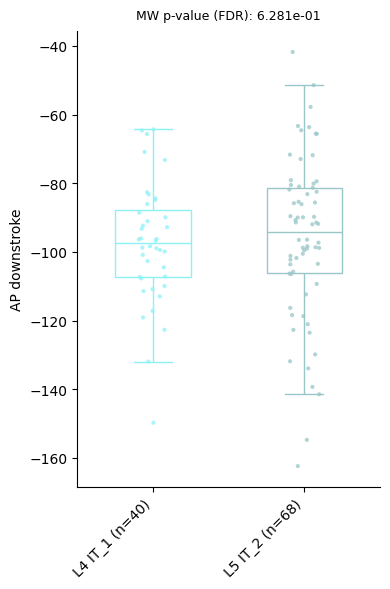

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


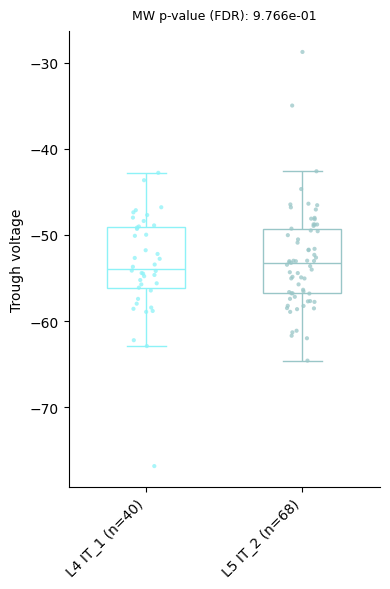

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


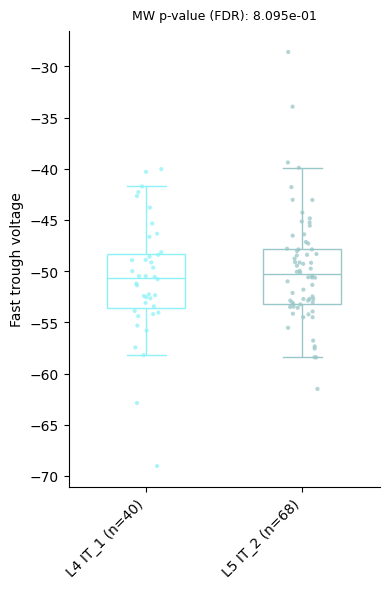

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


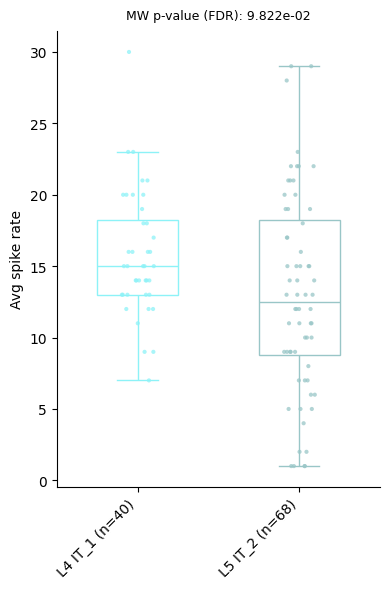

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


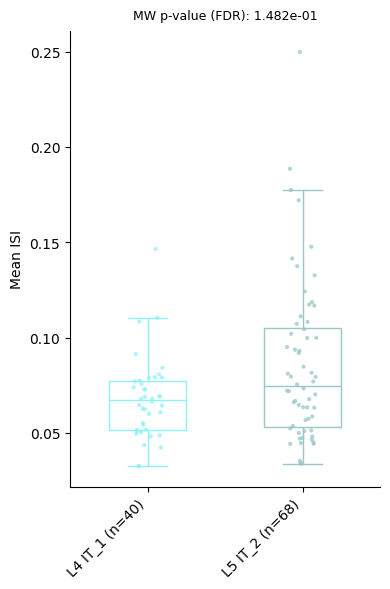

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


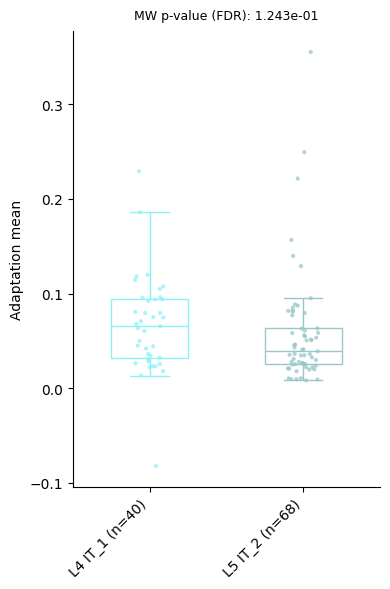

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


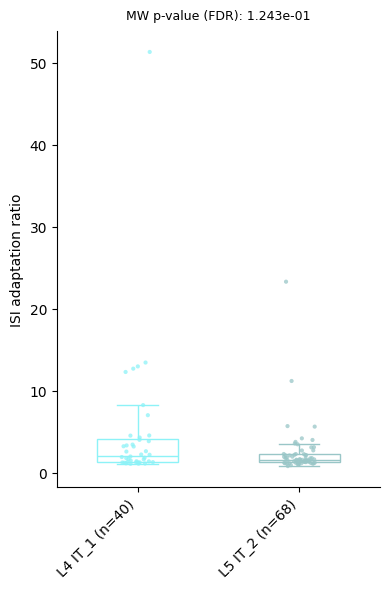

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


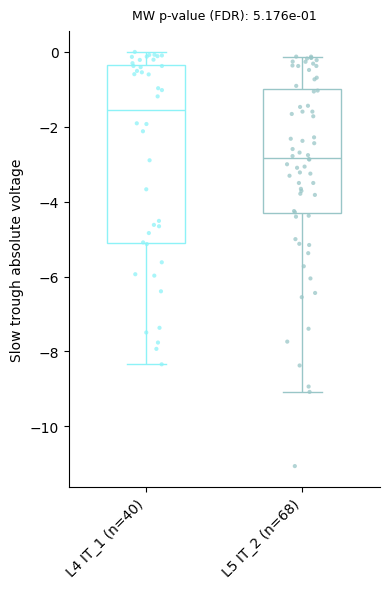

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


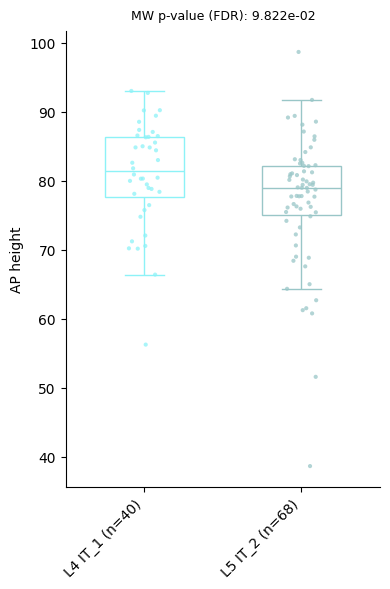

/tmp/ipykernel_796254/1123310202.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')


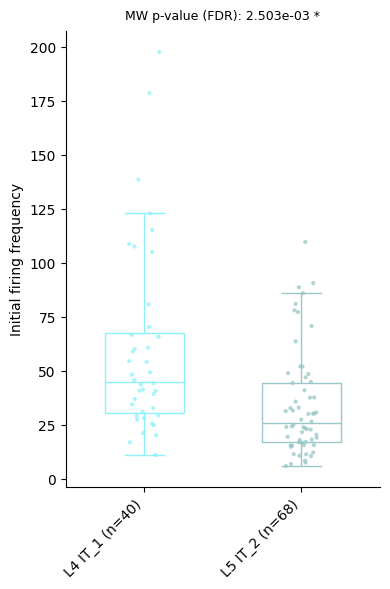

Box plots saved to: /root/capsule/scratch/20260807/ephys/human_excitatory_boxplots_ephys_features_L4_IT_1_vs_L5_IT_2_MW.pdf
Total features plotted: 24


In [7]:
# Plot box plots for L4 IT_1 vs L5 IT_2
import warnings

fig_name = 'human_excitatory_boxplots_ephys_features_L4_IT_1_vs_L5_IT_2_MW.pdf'
fig_path = os.path.join(output_dir, fig_name)

x_var = 't_type'
x_var_order = [supertype1, supertype2]
features_to_plot = list(mw_pvals.keys())

# Get colors for the two supertypes
palette = [color_dict.get(supertype1, '#1f77b4'), color_dict.get(supertype2, '#ff7f0e')]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for i, y_var in enumerate(features_to_plot):
            
            fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 6))
            
            # Create box plot
            sns.stripplot(data=comparison_data, x=x_var, y=y_var, ax=ax, 
                         order=x_var_order, palette=palette, alpha=0.75, size=3)
            sns.boxplot(data=comparison_data, x=x_var, y=y_var, ax=ax, 
                       order=x_var_order, palette=palette, saturation=1, 
                       showfliers=False, width=0.5)
            format_box_plot(ax)
            
            # Add sample sizes
            nobs = []
            for t in x_var_order:
                n = len(comparison_data[comparison_data[x_var] == t])
                nobs.append(f" (n={n})")
            new_x_tick_labels = [x_var_order[j] + nobs[j] for j in range(len(x_var_order))]
            ax.set_xticklabels(new_x_tick_labels, rotation=45, ha='right')
            
            # Add statistics annotation
            p_val = mw_pvals_fdr[y_var]
            is_sig = mw_rejected[y_var]
            
            if is_sig:
                sig_text = f"MW p-value (FDR): {p_val:.3e} *"
            else:
                sig_text = f"MW p-value (FDR): {p_val:.3e}"
            
            ax.text(0.5, 1.02, sig_text, transform=ax.transAxes, 
                   ha='center', va='bottom', fontsize=9)
            
            ax.set_xlabel('')
            ax.set_ylabel(y_var)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            
            plt.tight_layout()
            pdf.savefig(fig)
            plt.show()
            plt.close()

print(f"Box plots saved to: {fig_path}")
print(f"Total features plotted: {len(features_to_plot)}")